
# 05 — Multimodal Fusion

## Multimodal Medicinal Plant Leaf Retrieval Using Visual and Textual Features

---

## 1. Notebook Overview

This notebook focuses on integrating visual and textual features
for a multimodal medicinal plant leaf retrieval system.

The visual modality is represented using HSV Histogram,
Gray-Level Co-occurrence Matrix (GLCM), and Hu Moments.

The textual modality is represented using Term Frequency-Inverse
Document Frequency (TF-IDF) with two configurations:

- Unigram
- Unigram + Bigram

Visual feature matching is performed using Euclidean Distance,
while textual feature matching is performed using Cosine Similarity.

Both modality scores are integrated through a weighted
score-level late fusion approach to generate ranked retrieval results.

---

## 2. Objectives

The objectives of this notebook are:

1. Load previously extracted visual and textual feature artifacts.
2. Validate multimodal sample identities and feature alignment.
3. Calculate visual Euclidean distance matrices.
4. Analyze visual distance distributions.
5. Convert visual distances into similarity scores.
6. Calculate textual cosine similarity matrices.
7. Analyze cross-modality similarity score distributions.
8. Implement weighted score-level late fusion.
9. Analyze the sensitivity of different fusion weights.
10. Generate Top-K multimodal retrieval results.
11. Visualize image-only, text-only, and multimodal retrieval results.
12. Validate the mathematical and technical consistency of fusion.
13. Save multimodal fusion artifacts for subsequent evaluation.

---

## 3. Dataset Information

The multimodal dataset contains 104 paired image-text samples
representing five medicinal plant classes.

| Plant Class | Number of Samples |
|---|---:|
| Mangkok | 20 |
| Salam | 19 |
| Sambang Darah | 20 |
| Sirih | 20 |
| Tapak Kuda | 25 |
| **Total** | **104** |

Each sample contains:

- Unique sample ID
- Processed leaf image
- Binary segmentation mask
- Leaf description
- Plant class label
- Visual feature vector
- Textual feature vector

All modality features must follow the same sample ID order.

---

## 4. Feature Representation

### 4.1 Visual Features

| Feature Extraction Method | Feature Dimension |
|---|---:|
| HSV Histogram | 64 |
| GLCM | 72 |
| Hu Moments | 7 |
| **Total** | **143** |

Visual feature matrix:

$$
X_{image}\in\mathbb{R}^{104\times143}
$$

Visual features have been normalized and combined
through feature-level concatenation.

### 4.2 Textual Features

| TF-IDF Configuration | Feature Dimension |
|---|---:|
| Unigram | 68 |
| Unigram + Bigram | 261 |

Unigram feature matrix:

$$
X_{text}^{uni}\in\mathbb{R}^{104\times68}
$$

Unigram and bigram feature matrix:

$$
X_{text}^{uni+bi}\in\mathbb{R}^{104\times261}
$$

Both configurations are retained for comparison.

---

## 5. Visual Feature Matching

Visual feature matching is performed using Euclidean Distance.

$$
d(q,i)=
\sqrt{
\sum_{j=1}^{143}(q_j-i_j)^2
}
$$

Where:

- $q$ represents the visual query feature vector.
- $i$ represents the reference visual feature vector.
- $d(q,i)$ represents the Euclidean distance.

A smaller distance indicates greater similarity
in the visual feature space.

---

## 6. Visual Distance-to-Similarity Conversion

Euclidean Distance and Cosine Similarity have different
score interpretations.

Therefore, visual distances must be converted into
similarity scores before multimodal fusion.

An initial inverse-distance similarity function is defined as:

$$
S_{image}(q,i)=
\frac{1}{1+d(q,i)}
$$

The resulting similarity score satisfies:

$$
0<S_{image}\leq1
$$

A higher similarity score indicates a more similar
visual representation.

The suitability of the score conversion method will be
examined through score distribution analysis.

---

## 7. Text Feature Matching

Text feature matching is performed using Cosine Similarity.

$$
S_{text}(q,i)=
\frac{q\cdot i}
{\|q\|_2\|i\|_2}
$$

For nonnegative TF-IDF feature vectors:

$$
0\leq S_{text}\leq1
$$

Higher values indicate greater textual similarity.

Empty and all-OOV query vectors must not generate
arbitrary text-only retrieval rankings.

---

## 8. Multimodal Fusion Method

This project applies score-level late fusion.

Visual and textual features are processed independently
before their similarity scores are combined.

The final multimodal similarity score is calculated using:

$$
S_{final}(q,i)=
\alpha S_{image}(q,i)
+(1-\alpha)S_{text}(q,i)
$$

Where:

- $S_{image}$ is the visual similarity score.
- $S_{text}$ is the textual similarity score.
- $\alpha$ is the visual modality weight.
- $(1-\alpha)$ is the textual modality weight.
- $S_{final}$ is the final multimodal similarity score.

The weight constraint is:

$$
0\leq\alpha\leq1
$$

The main fusion scenarios are:

| Scenario | Visual Weight | Text Weight |
|---|---:|---:|
| Image Only | 1.0 | 0.0 |
| Text Only | 0.0 | 1.0 |
| Balanced Multimodal Fusion | 0.5 | 0.5 |

Additional weight configurations will be examined
through fusion weight sensitivity analysis.

---

## 9. Multimodal Retrieval Pipeline

```text
Multimodal Query
        |
        +-------------------------+
        |                         |
    Image Query               Text Query
        |                         |
 Image Preprocessing       Text Preprocessing
        |                         |
 HSV + GLCM + Hu Moments        TF-IDF
        |                         |
 Visual Normalization      Query Transformation
        |                         |
 Euclidean Distance       Cosine Similarity
        |                         |
 Distance-to-Similarity     Text Similarity
        |                         |
        +-----------+-------------+
                    |
        Weighted Score-Level Fusion
                    |
          Final Similarity Score
                    |
             Top-K Ranking
                    |
           Retrieval Results
```

---

## 10. Experimental Configurations

The following retrieval configurations are investigated:

| ID | Configuration |
|---|---|
| C01 | Image Only |
| C02 | Text Only — Unigram |
| C03 | Text Only — Unigram + Bigram |
| C04 | Multimodal — Image + Unigram |
| C05 | Multimodal — Image + Unigram + Bigram |

Fusion weights will be investigated using:

$$
\alpha\in
\{0.0,0.1,0.2,0.3,0.4,0.5,
0.6,0.7,0.8,0.9,1.0\}
$$

Top-K retrieval configurations:

$$
K\in\{1,3,5,10\}
$$

Image-only configurations shared across both
text representations will not be counted as
different retrieval methods.

---

## 11. Notebook Workflow

| Cell | Processing Stage |
|---:|---|
| 1 | Notebook Overview |
| 2 | Import Libraries |
| 3 | Path Configuration |
| 4 | Load Visual Feature Artifacts |
| 5 | Load Text Feature Artifacts |
| 6 | Multimodal Dataset Validation |
| 7 | Fusion Configuration |
| 8 | Euclidean Distance Calculation |
| 9 | Visual Distance Analysis |
| 10 | Visual Distance-to-Similarity Conversion |
| 11 | Text Cosine Similarity Calculation |
| 12 | Cross-Modality Score Distribution Analysis |
| 13 | Weighted Score-Level Late Fusion |
| 14 | Fusion Weight Sensitivity Analysis |
| 15 | Multimodal Similarity Matrix Analysis |
| 16 | Top-K Multimodal Retrieval |
| 17 | Retrieval Result Visualization |
| 18 | Multimodal Fusion Validation |
| 19 | Save Multimodal Fusion Artifacts |
| 20 | Multimodal Fusion Summary |

---

## 12. Expected Outputs

The expected outputs of this notebook include:

- Visual Euclidean distance matrices
- Visual similarity matrices
- Textual cosine similarity matrices
- Multimodal similarity matrices
- Cross-modality score distribution reports
- Fusion weight sensitivity reports
- Top-K retrieval results
- Comparative retrieval visualizations
- Mathematical validation reports
- Multimodal fusion configuration
- Saved fusion artifacts
- Final multimodal fusion summary

---

## 13. Methodological Considerations

The following methodological principles are maintained:

1. Visual and textual samples must be aligned by sample ID.
2. Visual and textual feature spaces remain separate.
3. All fusion scores must have consistent similarity direction.
4. Fusion weights must be nonnegative and sum to one.
5. Self-matches must be excluded when reference samples
   are used as exploratory queries.
6. Similarity ties must be handled consistently.
7. Empty or unusable modalities require an appropriate
   single-modality fallback or query rejection.
8. Original dataset review flags must be preserved.
9. Full-gallery analyses are exploratory and must not be
   reported as independent retrieval evaluation.
10. Final configuration and weight selection must use
    validation data rather than final test data.
11. TF-IDF vectorizers and visual normalizers must be
    refitted using reference data only during
    independent evaluation.
12. Duplicate descriptions and related specimens must
    be considered when constructing evaluation splits.

---

## 14. Research Hypothesis

Combining complementary visual and textual information
through score-level late fusion may improve medicinal
plant leaf retrieval compared with using either
modality independently.

This hypothesis will be investigated through comparative
retrieval experiments and subsequently evaluated using
Precision@K, Recall@K, and mean Average Precision (mAP).

---

## 15. Notebook Status

**Current Stage:** Multimodal Fusion

**Fusion Method:** Score-Level Late Fusion

**Fusion Strategy:** Weighted Sum

**Previous Notebook:** 04_text_feature_extraction.ipynb

**Next Notebook:** 06_retrieval_evaluation.ipynb

**Status:** In Progress

---


In [1]:
# ==================================================
# CELL 2 - IMPORT LIBRARIES
# ==================================================

# ==================================================
# 1. STANDARD LIBRARIES
# ==================================================

import os
import sys
import json
import time
import hashlib
import warnings
import platform
import itertools

from pathlib import Path
from datetime import datetime, timezone
from collections import Counter, defaultdict
from importlib.metadata import version


# ==================================================
# 2. NUMERICAL COMPUTATION AND DATA PROCESSING
# ==================================================

import numpy as np
import pandas as pd

import scipy
from scipy.sparse import (
    csr_matrix,
    issparse,
    load_npz,
    save_npz
)


# ==================================================
# 3. DISTANCE AND SIMILARITY CALCULATION
# ==================================================

from scipy.spatial.distance import (
    cdist,
    pdist,
    squareform
)

from scipy.stats import (
    pearsonr,
    spearmanr
)

import sklearn

from sklearn.metrics.pairwise import (
    euclidean_distances,
    cosine_similarity
)

from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler
)


# ==================================================
# 4. MODEL AND ARTIFACT MANAGEMENT
# ==================================================

import joblib


# ==================================================
# 5. IMAGE PROCESSING
# ==================================================

import cv2

from PIL import Image


# ==================================================
# 6. DATA VISUALIZATION
# ==================================================

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter


# ==================================================
# 7. NOTEBOOK UTILITIES
# ==================================================

from tqdm.auto import tqdm
from IPython.display import display, Markdown


# ==================================================
# 8. REPRODUCIBILITY CONFIGURATION
# ==================================================

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

EPSILON = 1e-10

FEATURE_DTYPE = np.float64

np.set_printoptions(
    precision=6,
    suppress=True
)

pd.set_option(
    "display.max_columns",
    50
)

pd.set_option(
    "display.max_rows",
    100
)

pd.set_option(
    "display.max_colwidth",
    150
)

pd.set_option(
    "display.precision",
    6
)


# ==================================================
# 9. VISUALIZATION CONFIGURATION
# ==================================================

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams.update({

    "figure.figsize": (12, 6),

    "figure.dpi": 120,

    "savefig.dpi": 300,

    "font.family": "DejaVu Sans",

    "font.size": 11,

    "axes.titlesize": 13,

    "axes.titleweight": "bold",

    "axes.labelsize": 11,

    "axes.spines.top": False,

    "axes.spines.right": False,

    "xtick.labelsize": 10,

    "ytick.labelsize": 10,

    "legend.fontsize": 10,

    "grid.alpha": 0.25,

    "figure.facecolor": "white",

    "axes.facecolor": "white",

    "savefig.facecolor": "white",

    "savefig.bbox": "tight"
})


# ==================================================
# 10. COLOR PALETTE CONFIGURATION
# ==================================================

CLASS_COLORS = {

    "Mangkok": "#66A58A",

    "Salam": "#83A7C7",

    "Sambang Darah": "#CBA461",

    "Sirih": "#998AB8",

    "Tapak Kuda": "#D97878"
}


MODALITY_COLORS = {

    "Image Only": "#66A58A",

    "Text Only": "#83A7C7",

    "Multimodal": "#CBA461"
}


TFIDF_COLORS = {

    "Unigram": "#66A58A",

    "Unigram + Bigram": "#83A7C7"
}


FEATURE_GROUP_COLORS = {

    "HSV": "#66A58A",

    "GLCM": "#83A7C7",

    "Hu Moments": "#CBA461"
}


RETRIEVAL_COLORS = {

    "Image Only": "#66A58A",

    "Text Only - Unigram": "#83A7C7",

    "Text Only - Unigram + Bigram": "#998AB8",

    "Multimodal - Unigram": "#CBA461",

    "Multimodal - Unigram + Bigram": "#D97878"
}


VALIDATION_COLORS = {

    "Passed": "#66A58A",

    "Pending Review": "#CBA461",

    "Failed": "#D97878"
}


PAIR_TYPE_COLORS = {

    "Within Class": "#66A58A",

    "Cross Class": "#83A7C7"
}


SIMILARITY_CMAP = "viridis"

DISTANCE_CMAP = "magma_r"

DIVERGING_CMAP = "RdBu_r"


# ==================================================
# 11. SOFTWARE ENVIRONMENT INFORMATION
# ==================================================

library_versions = {

    "Python": platform.python_version(),

    "NumPy": np.__version__,

    "Pandas": pd.__version__,

    "SciPy": scipy.__version__,

    "Scikit-learn": sklearn.__version__,

    "Joblib": joblib.__version__,

    "OpenCV": cv2.__version__,

    "Pillow": version("Pillow"),

    "Matplotlib": matplotlib.__version__,

    "Seaborn": sns.__version__,

    "TQDM": version("tqdm"),

    "IPython": version("ipython")
}


library_versions_df = pd.DataFrame(

    library_versions.items(),

    columns=[
        "Library",
        "Version"
    ]
)


# ==================================================
# 12. MATHEMATICAL FUNCTION SANITY CHECK
# ==================================================

# Synthetic vectors for basic mathematical validation.
# These are not actual dataset features.

test_vector_a = np.array([
    [1.0, 0.0, 0.0]
])

test_vector_b = np.array([
    [0.0, 1.0, 0.0]
])

test_vector_c = np.array([
    [1.0, 0.0, 0.0]
])


# A. Euclidean Distance validation.

test_euclidean_same = float(

    euclidean_distances(
        test_vector_a,
        test_vector_c
    )[0, 0]

)

test_euclidean_different = float(

    euclidean_distances(
        test_vector_a,
        test_vector_b
    )[0, 0]

)


# B. Cosine Similarity validation.

test_cosine_same = float(

    cosine_similarity(
        test_vector_a,
        test_vector_c
    )[0, 0]

)

test_cosine_orthogonal = float(

    cosine_similarity(
        test_vector_a,
        test_vector_b
    )[0, 0]

)


# C. Distance-to-similarity validation.

test_visual_similarity_same = (

    1.0 / (1.0 + test_euclidean_same)

)

test_visual_similarity_different = (

    1.0 / (1.0 + test_euclidean_different)

)


# D. Weighted score fusion validation.

test_image_score = 0.8
test_text_score = 0.6
test_alpha = 0.5

test_fusion_score = (

    test_alpha * test_image_score

    +

    (1 - test_alpha) * test_text_score

)


# ==================================================
# 13. SPARSE MATRIX SANITY CHECK
# ==================================================

test_dense_matrix = np.array([

    [1.0, 0.0, 0.0],

    [0.0, 1.0, 0.0]

])

test_sparse_matrix = csr_matrix(
    test_dense_matrix
)

test_sparse_similarity = cosine_similarity(
    test_sparse_matrix
)

test_dense_similarity = cosine_similarity(
    test_dense_matrix
)


# ==================================================
# 14. REGISTER LIBRARY VALIDATION RESULTS
# ==================================================

fusion_library_checks = [

    {
        "validation_check":
            "Euclidean distance of identical vectors",

        "expected": 0.0,

        "actual": test_euclidean_same,

        "passed": np.isclose(
            test_euclidean_same,
            0.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Euclidean distance of orthogonal unit vectors",

        "expected": np.sqrt(2),

        "actual": test_euclidean_different,

        "passed": np.isclose(
            test_euclidean_different,
            np.sqrt(2),
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Cosine similarity of identical vectors",

        "expected": 1.0,

        "actual": test_cosine_same,

        "passed": np.isclose(
            test_cosine_same,
            1.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Cosine similarity of orthogonal vectors",

        "expected": 0.0,

        "actual": test_cosine_orthogonal,

        "passed": np.isclose(
            test_cosine_orthogonal,
            0.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Zero distance produces similarity one",

        "expected": 1.0,

        "actual": test_visual_similarity_same,

        "passed": np.isclose(
            test_visual_similarity_same,
            1.0,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Inverse-distance similarity calculation",

        "expected": 1 / (1 + np.sqrt(2)),

        "actual": test_visual_similarity_different,

        "passed": np.isclose(

            test_visual_similarity_different,

            1 / (1 + np.sqrt(2)),

            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Weighted score fusion calculation",

        "expected": 0.7,

        "actual": test_fusion_score,

        "passed": np.isclose(
            test_fusion_score,
            0.7,
            atol=EPSILON
        )
    },

    {
        "validation_check":
            "Sparse and dense cosine similarity consistency",

        "expected": 0.0,

        "actual": float(

            np.max(

                np.abs(

                    test_sparse_similarity

                    - test_dense_similarity

                )

            )
        ),

        "passed": np.allclose(

            test_sparse_similarity,

            test_dense_similarity,

            atol=EPSILON,

            rtol=0
        )
    }
]


fusion_library_validation_df = pd.DataFrame(
    fusion_library_checks
)

fusion_library_validation_df["status"] = np.where(

    fusion_library_validation_df["passed"],

    "Passed",

    "Failed"
)


# ==================================================
# 15. VALIDATE LIBRARY ENVIRONMENT
# ==================================================

FUSION_LIBRARIES_IMPORTED = False

assert fusion_library_validation_df[
    "passed"
].all(), (

    fusion_library_validation_df.loc[

        ~fusion_library_validation_df["passed"]

    ].to_string(index=False)
)

FUSION_LIBRARIES_IMPORTED = True


# ==================================================
# 16. PRINT IMPORT SUMMARY
# ==================================================

print("=" * 70)

print("MULTIMODAL FUSION - LIBRARY INITIALIZATION")

print("=" * 70)


print("\nSYSTEM INFORMATION")

print("-" * 70)

print(f"Operating system : {platform.system()}")

print(f"OS release       : {platform.release()}")

print(f"Python version   : {platform.python_version()}")

print(f"Architecture     : {platform.machine()}")

print(f"Random state     : {RANDOM_STATE}")

print(f"Feature dtype    : {FEATURE_DTYPE.__name__}")

print(f"Tolerance        : {EPSILON}")


print("\nLIBRARY VERSIONS")

print("-" * 70)

display(library_versions_df)


print("\nMATHEMATICAL FUNCTION VALIDATION")

print("-" * 70)

display(
    fusion_library_validation_df.round(8)
)


print("\nIMPORT STATUS")

print("-" * 70)

print("[PASS] Standard libraries imported.")

print("[PASS] Numerical computation libraries imported.")

print("[PASS] Sparse matrix utilities imported.")

print("[PASS] Euclidean distance functions imported.")

print("[PASS] Cosine similarity functions imported.")

print("[PASS] Statistical analysis libraries imported.")

print("[PASS] Model and artifact utilities imported.")

print("[PASS] Image processing libraries imported.")

print("[PASS] Visualization libraries imported.")

print("[PASS] Notebook utilities imported.")

print("[PASS] Reproducibility configuration initialized.")

print("[PASS] Visualization configuration initialized.")

print("[PASS] Mathematical sanity checks completed.")


print("\nVALIDATION SUMMARY")

print("-" * 70)

print(

    f"Total checks  : "

    f"{len(fusion_library_validation_df)}"

)

print(

    f"Passed checks : "

    f"{fusion_library_validation_df['passed'].sum()}"

)

print(

    f"Failed checks : "

    f"{(~fusion_library_validation_df['passed']).sum()}"

)


print("\n" + "=" * 70)

print("ALL LIBRARIES IMPORTED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 3 - Path Configuration")

MULTIMODAL FUSION - LIBRARY INITIALIZATION

SYSTEM INFORMATION
----------------------------------------------------------------------
Operating system : Windows
OS release       : 11
Python version   : 3.13.14
Architecture     : AMD64
Random state     : 42
Feature dtype    : float64
Tolerance        : 1e-10

LIBRARY VERSIONS
----------------------------------------------------------------------


,Library,Version
0,Python,3.13.14
1,NumPy,2.5.5
2,Pandas,3.1.1
3,SciPy,1.18.1
4,Scikit-learn,1.9.1
5,Joblib,1.6.0
6,OpenCV,5.1.0
7,Pillow,13.0.0
8,Matplotlib,3.11.2
9,Seaborn,0.13.2



MATHEMATICAL FUNCTION VALIDATION
----------------------------------------------------------------------


,validation_check,expected,actual,passed,status
0,Euclidean distance of identical vectors,0.000000,0.000000,True,Passed
1,Euclidean distance of orthogonal unit vectors,1.414214,1.414214,True,Passed
2,Cosine similarity of identical vectors,1.000000,1.000000,True,Passed
3,Cosine similarity of orthogonal vectors,0.000000,0.000000,True,Passed
4,Zero distance produces similarity one,1.000000,1.000000,True,Passed
5,Inverse-distance similarity calculation,0.414214,0.414214,True,Passed
6,Weighted score fusion calculation,0.700000,0.700000,True,Passed
7,Sparse and dense cosine similarity consistency,0.000000,0.000000,True,Passed



IMPORT STATUS
----------------------------------------------------------------------
[PASS] Standard libraries imported.
[PASS] Numerical computation libraries imported.
[PASS] Sparse matrix utilities imported.
[PASS] Euclidean distance functions imported.
[PASS] Cosine similarity functions imported.
[PASS] Statistical analysis libraries imported.
[PASS] Model and artifact utilities imported.
[PASS] Image processing libraries imported.
[PASS] Visualization libraries imported.
[PASS] Notebook utilities imported.
[PASS] Reproducibility configuration initialized.
[PASS] Visualization configuration initialized.
[PASS] Mathematical sanity checks completed.

VALIDATION SUMMARY
----------------------------------------------------------------------
Total checks  : 8
Passed checks : 8
Failed checks : 0

ALL LIBRARIES IMPORTED SUCCESSFULLY

Next cell: Cell 3 - Path Configuration


In [2]:
# ==================================================
# CELL 3 - PATH CONFIGURATION
# ==================================================

from tempfile import NamedTemporaryFile

print("MULTIMODAL FUSION - PATH CONFIGURATION")
print("=" * 70)

FUSION_PATH_CONFIGURATION_COMPLETED = False


# ==================================================
# 1. VALIDATE PREVIOUS CELL
# ==================================================

assert FUSION_LIBRARIES_IMPORTED is True, (
    "Run Cell 2 - Import Libraries first."
)

assert fusion_library_validation_df["passed"].all()

print("[PASS] Library initialization validated.")


# ==================================================
# 2. AUTOMATIC PROJECT ROOT DETECTION
# ==================================================

# Set a manual path only if automatic detection fails.
# Example:
# MANUAL_PROJECT_ROOT = r"D:\Project\Your_Project"

MANUAL_PROJECT_ROOT = None


def detect_project_root(start_path=None):

    start_path = Path(
        start_path or Path.cwd()
    ).resolve()

    candidates = [
        start_path,
        *start_path.parents
    ]

    for candidate in candidates:

        metadata_file = (
            candidate
            / "dataset"
            / "processed"
            / "metadata_processed.csv"
        )

        if metadata_file.is_file():

            return candidate

    raise FileNotFoundError(
        "Project root could not be detected. "
        "Set MANUAL_PROJECT_ROOT to the project directory."
    )


if MANUAL_PROJECT_ROOT is not None:

    PROJECT_ROOT = Path(
        MANUAL_PROJECT_ROOT
    ).expanduser().resolve()

else:

    PROJECT_ROOT = detect_project_root()


assert PROJECT_ROOT.is_dir(), (
    f"Invalid project root: {PROJECT_ROOT}"
)

print("\n1. PROJECT ROOT DETECTION")
print("-" * 70)

print(f"Working directory : {Path.cwd()}")
print(f"Project root      : {PROJECT_ROOT}")

print("[PASS] Project root detected successfully.")


# ==================================================
# 3. MAIN PROJECT DIRECTORIES
# ==================================================

DATASET_DIR = PROJECT_ROOT / "dataset"

PROCESSED_DIR = DATASET_DIR / "processed"

FEATURES_DIR = DATASET_DIR / "features"

VISUAL_FEATURES_DIR = FEATURES_DIR / "visual"

TEXT_FEATURES_DIR = FEATURES_DIR / "text"

FUSION_FEATURES_DIR = FEATURES_DIR / "fusion"

NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"

RESULTS_DIR = PROJECT_ROOT / "results"

FIGURES_DIR = RESULTS_DIR / "figures"

METRICS_DIR = RESULTS_DIR / "metrics"

FUSION_FIGURES_DIR = (
    FIGURES_DIR / "multimodal_fusion"
)

# Alias for consistency with previous notebooks.

MULTIMODAL_FUSION_DIR = FUSION_FEATURES_DIR

MULTIMODAL_FUSION_FIGURES_DIR = FUSION_FIGURES_DIR


# ==================================================
# 4. CONFIGURE METADATA PATHS
# ==================================================

PROCESSED_METADATA_PATH = (
    PROCESSED_DIR
    / "metadata_processed.csv"
)

VISUAL_METADATA_PATH = (
    VISUAL_FEATURES_DIR
    / "visual_feature_metadata.csv"
)

MULTIMODAL_METADATA_PATH = (
    TEXT_FEATURES_DIR
    / "multimodal_feature_metadata.csv"
)


# ==================================================
# 5. CONFIGURE VISUAL FEATURE ARTIFACTS
# ==================================================

VISUAL_ARTIFACT_PATHS = {

    "hsv_features":
        VISUAL_FEATURES_DIR
        / "hsv_features.npy",

    "glcm_features":
        VISUAL_FEATURES_DIR
        / "glcm_features.npy",

    "hu_features":
        VISUAL_FEATURES_DIR
        / "hu_features.npy",

    "hu_raw_moments":
        VISUAL_FEATURES_DIR
        / "hu_raw_moments.npy",

    "raw_features":
        VISUAL_FEATURES_DIR
        / "visual_features_raw.npy",

    "baseline_features":
        VISUAL_FEATURES_DIR
        / "visual_features_baseline.npy",

    "normalized_features":
        VISUAL_FEATURES_DIR
        / "visual_features_normalized.npy",

    "sample_ids":
        VISUAL_FEATURES_DIR
        / "visual_sample_ids.npy",

    "metadata":
        VISUAL_METADATA_PATH,

    "feature_index":
        VISUAL_FEATURES_DIR
        / "visual_feature_index.csv",

    "normalizer":
        VISUAL_FEATURES_DIR
        / "visual_normalizer.joblib",

    "baseline_normalizer":
        VISUAL_FEATURES_DIR
        / "baseline_visual_normalizer.joblib",

    "feature_names":
        VISUAL_FEATURES_DIR
        / "visual_feature_names.json",

    "configuration":
        VISUAL_FEATURES_DIR
        / "visual_feature_config.json"
}


# Main visual feature aliases.

VISUAL_RAW_FEATURES_PATH = (
    VISUAL_ARTIFACT_PATHS["raw_features"]
)

VISUAL_BASELINE_FEATURES_PATH = (
    VISUAL_ARTIFACT_PATHS["baseline_features"]
)

VISUAL_NORMALIZED_FEATURES_PATH = (
    VISUAL_ARTIFACT_PATHS["normalized_features"]
)

VISUAL_SAMPLE_IDS_PATH = (
    VISUAL_ARTIFACT_PATHS["sample_ids"]
)

VISUAL_NORMALIZER_PATH = (
    VISUAL_ARTIFACT_PATHS["normalizer"]
)

VISUAL_CONFIG_PATH = (
    VISUAL_ARTIFACT_PATHS["configuration"]
)


# ==================================================
# 6. CONFIGURE TF-IDF ARTIFACTS
# ==================================================

TEXT_CONFIGURATION_SLUGS = {

    "Unigram": "unigram",

    "Unigram + Bigram": "unigram_bigram"
}

TEXT_ARTIFACT_PATHS = {}

for configuration_name, slug in (
    TEXT_CONFIGURATION_SLUGS.items()
):

    TEXT_ARTIFACT_PATHS[
        configuration_name
    ] = {

        "matrix":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_features.npz",

        "vectorizer":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_vectorizer.joblib",

        "feature_names":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_feature_names.npy",

        "idf_weights":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_idf_weights.npy",

        "vocabulary":
            TEXT_FEATURES_DIR
            / f"tfidf_{slug}_vocabulary.csv"
    }


# ==================================================
# 7. CONFIGURE SHARED TEXT ARTIFACTS
# ==================================================

TEXT_SHARED_ARTIFACT_PATHS = {

    "sample_ids":
        TEXT_FEATURES_DIR
        / "text_sample_ids.npy",

    "class_labels":
        TEXT_FEATURES_DIR
        / "text_class_labels.npy",

    "metadata":
        MULTIMODAL_METADATA_PATH,

    "corpus":
        TEXT_FEATURES_DIR
        / "text_corpus.json",

    "preprocessing_config":
        TEXT_FEATURES_DIR
        / "text_query_preprocessing_config.json",

    "feature_config":
        TEXT_FEATURES_DIR
        / "text_feature_extraction_config.json",

    "manifest":
        TEXT_FEATURES_DIR
        / "text_feature_artifact_manifest.csv"
}


# Main text feature aliases.

TFIDF_UNIGRAM_FEATURES_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram"]["matrix"]
)

TFIDF_BIGRAM_FEATURES_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram + Bigram"]["matrix"]
)

TFIDF_UNIGRAM_VECTORIZER_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram"]["vectorizer"]
)

TFIDF_BIGRAM_VECTORIZER_PATH = (
    TEXT_ARTIFACT_PATHS["Unigram + Bigram"]["vectorizer"]
)

TEXT_SAMPLE_IDS_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["sample_ids"]
)

TEXT_CLASS_LABELS_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["class_labels"]
)

TEXT_CORPUS_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["corpus"]
)

TEXT_CONFIG_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["feature_config"]
)

TEXT_PREPROCESSING_CONFIG_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["preprocessing_config"]
)

TEXT_MANIFEST_PATH = (
    TEXT_SHARED_ARTIFACT_PATHS["manifest"]
)


# ==================================================
# 8. CONFIGURE MANIFEST AND HANDOFF PATHS
# ==================================================

VISUAL_MANIFEST_JSON_PATH = (
    VISUAL_FEATURES_DIR
    / "visual_feature_manifest.json"
)

VISUAL_MANIFEST_CSV_PATH = (
    METRICS_DIR
    / "174_visual_feature_artifact_manifest.csv"
)

TEXT_HANDOFF_PATH = (
    METRICS_DIR
    / "347_text_feature_extraction_handoff.json"
)

FUSION_SUPPORTING_PATHS = {

    "Visual Manifest JSON":
        VISUAL_MANIFEST_JSON_PATH,

    "Visual Manifest CSV":
        VISUAL_MANIFEST_CSV_PATH,

    "Text Notebook Handoff":
        TEXT_HANDOFF_PATH
}


# ==================================================
# 9. REGISTER REQUIRED INPUT FILES
# ==================================================

fusion_required_inputs = [

    (
        "Processed Metadata",
        "Dataset",
        PROCESSED_METADATA_PATH
    )
]

# Visual payload artifacts.

for name, path in VISUAL_ARTIFACT_PATHS.items():

    fusion_required_inputs.append((

        name,

        "Visual",

        path
    ))


# Configuration-specific text artifacts.

for configuration_name, paths in (
    TEXT_ARTIFACT_PATHS.items()
):

    for name, path in paths.items():

        fusion_required_inputs.append((

            name,

            f"Text - {configuration_name}",

            path
        ))


# Shared text artifacts and manifest.

for name, path in (
    TEXT_SHARED_ARTIFACT_PATHS.items()
):

    fusion_required_inputs.append((

        name,

        "Text - Shared",

        path
    ))


# ==================================================
# 10. VALIDATE REQUIRED INPUT DIRECTORIES
# ==================================================

fusion_input_directories = {

    "Dataset":
        DATASET_DIR,

    "Processed Dataset":
        PROCESSED_DIR,

    "Feature Dataset":
        FEATURES_DIR,

    "Visual Features":
        VISUAL_FEATURES_DIR,

    "Text Features":
        TEXT_FEATURES_DIR
}

fusion_input_directory_records = []

for name, path in (
    fusion_input_directories.items()
):

    available = path.is_dir()

    fusion_input_directory_records.append({

        "directory": name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "exists": available,

        "passed": available,

        "status": (
            "Available"
            if available
            else "Missing"
        )
    })


fusion_input_directory_df = pd.DataFrame(
    fusion_input_directory_records
)

print("\n2. INPUT DIRECTORY VALIDATION")
print("-" * 70)

display(fusion_input_directory_df)


# ==================================================
# 11. VALIDATE REQUIRED INPUT ARTIFACTS
# ==================================================

fusion_input_file_records = []

for name, modality, path in (
    fusion_required_inputs
):

    exists = path.is_file()

    file_size = (
        path.stat().st_size
        if exists
        else 0
    )

    valid = (
        exists
        and file_size > 0
    )

    fusion_input_file_records.append({

        "artifact": name,

        "modality": modality,

        "filename": path.name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "exists": exists,

        "size_bytes": file_size,

        "size_kib": file_size / 1024,

        "passed": valid,

        "status": (

            "Available"
            if valid
            else "Empty File"
            if exists
            else "Missing"
        )
    })


fusion_input_file_validation_df = pd.DataFrame(
    fusion_input_file_records
)

print("\n3. REQUIRED INPUT FILE VALIDATION")
print("-" * 70)

display(
    fusion_input_file_validation_df[
        [
            "modality",
            "filename",
            "size_kib",
            "status"
        ]
    ].round(4)
)


# ==================================================
# 12. VALIDATE SUPPORTING ARTIFACTS
# ==================================================

fusion_supporting_file_records = []

for name, path in (
    FUSION_SUPPORTING_PATHS.items()
):

    available = (
        path.is_file()
        and path.stat().st_size > 0
    )

    fusion_supporting_file_records.append({

        "artifact": name,

        "filename": path.name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "available": available,

        "status": (
            "Available"
            if available
            else "Unavailable"
        )
    })


fusion_supporting_file_df = pd.DataFrame(
    fusion_supporting_file_records
)

visual_manifest_available = any(

    path.is_file()
    and path.stat().st_size > 0

    for path in [
        VISUAL_MANIFEST_JSON_PATH,
        VISUAL_MANIFEST_CSV_PATH
    ]
)

print("\n4. SUPPORTING ARTIFACTS")
print("-" * 70)

display(fusion_supporting_file_df)

print(
    "Visual manifest available:",
    visual_manifest_available
)


# ==================================================
# 13. CREATE OUTPUT DIRECTORIES
# ==================================================

fusion_output_directories = {

    "Fusion Features":
        FUSION_FEATURES_DIR,

    "Fusion Figures":
        FUSION_FIGURES_DIR,

    "Metrics":
        METRICS_DIR
}

fusion_output_directory_records = []

for name, path in (
    fusion_output_directories.items()
):

    error_message = ""

    try:

        path.mkdir(
            parents=True,
            exist_ok=True
        )

        # Test actual write access using a temporary file.
        # Existing project artifacts are not modified.

        with NamedTemporaryFile(

            mode="w",

            prefix=".fusion_write_test_",

            suffix=".tmp",

            dir=path,

            encoding="utf-8",

            delete=True

        ) as temporary_file:

            temporary_file.write(
                "Multimodal fusion write test."
            )

            temporary_file.flush()

        writable = True

    except OSError as error:

        writable = False

        error_message = str(error)

    fusion_output_directory_records.append({

        "directory": name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "exists": path.is_dir(),

        "writable": writable,

        "passed": (
            path.is_dir()
            and writable
        ),

        "error": error_message,

        "status": (
            "Ready"
            if path.is_dir() and writable
            else "Failed"
        )
    })


fusion_output_directory_df = pd.DataFrame(
    fusion_output_directory_records
)

print("\n5. OUTPUT DIRECTORY VALIDATION")
print("-" * 70)

display(fusion_output_directory_df)


# ==================================================
# 14. SUMMARIZE INPUT ARTIFACT AVAILABILITY
# ==================================================

fusion_input_artifact_summary_df = (

    fusion_input_file_validation_df

    .groupby("modality", sort=False)

    .agg(

        required_files=(
            "filename",
            "count"
        ),

        available_files=(
            "passed",
            "sum"
        ),

        total_size_bytes=(
            "size_bytes",
            "sum"
        ),

        total_size_kib=(
            "size_kib",
            "sum"
        )
    )

    .reset_index()
)

fusion_input_artifact_summary_df[
    "missing_or_invalid_files"
] = (

    fusion_input_artifact_summary_df[
        "required_files"
    ]

    -

    fusion_input_artifact_summary_df[
        "available_files"
    ]
)

print("\n6. INPUT ARTIFACT SUMMARY")
print("-" * 70)

display(
    fusion_input_artifact_summary_df.round(4)
)


# ==================================================
# 15. CONFIGURE PLANNED FUSION OUTPUT ARTIFACTS
# ==================================================

# These paths will be used by subsequent cells.
# No fusion matrices are generated at this stage.

FUSION_OUTPUT_ARTIFACT_PATHS = {

    "visual_distance_matrix":
        FUSION_FEATURES_DIR
        / "visual_euclidean_distance_matrix.npy",

    "visual_similarity_matrix":
        FUSION_FEATURES_DIR
        / "visual_similarity_matrix.npy",

    "text_unigram_similarity_matrix":
        FUSION_FEATURES_DIR
        / "text_unigram_cosine_similarity_matrix.npy",

    "text_combined_similarity_matrix":
        FUSION_FEATURES_DIR
        / "text_combined_cosine_similarity_matrix.npy",

    "fusion_unigram_matrices":
        FUSION_FEATURES_DIR
        / "fusion_unigram_similarity_matrices.npz",

    "fusion_combined_matrices":
        FUSION_FEATURES_DIR
        / "fusion_combined_similarity_matrices.npz",

    "sample_ids":
        FUSION_FEATURES_DIR
        / "fusion_sample_ids.npy",

    "class_labels":
        FUSION_FEATURES_DIR
        / "fusion_class_labels.npy",

    "metadata":
        FUSION_FEATURES_DIR
        / "fusion_metadata.csv",

    "configuration":
        FUSION_FEATURES_DIR
        / "multimodal_fusion_config.json",

    "manifest":
        FUSION_FEATURES_DIR
        / "multimodal_fusion_artifact_manifest.csv"
}

fusion_planned_artifacts_df = pd.DataFrame([

    {

        "artifact": name,

        "filename": path.name,

        "relative_path": (
            path.relative_to(PROJECT_ROOT).as_posix()
        ),

        "already_exists": path.is_file()

    }

    for name, path in (
        FUSION_OUTPUT_ARTIFACT_PATHS.items()
    )
])

print("\n7. PLANNED FUSION ARTIFACTS")
print("-" * 70)

display(fusion_planned_artifacts_df)


# ==================================================
# 16. FINAL PATH CONFIGURATION VALIDATION
# ==================================================

fusion_path_checks = {

    "Project root detected":

        PROJECT_ROOT.is_dir(),

    "Required input directories available":

        fusion_input_directory_df["passed"].all(),

    "All required input artifacts available":

        fusion_input_file_validation_df["passed"].all(),

    "All required input files nonempty":

        fusion_input_file_validation_df[
            "size_bytes"
        ].gt(0).all(),

    "Visual artifact manifest available":

        visual_manifest_available,

    "Text artifact manifest available":

        TEXT_MANIFEST_PATH.is_file()
        and TEXT_MANIFEST_PATH.stat().st_size > 0,

    "Output directories available":

        fusion_output_directory_df["exists"].all(),

    "Output directories writable":

        fusion_output_directory_df["writable"].all(),

    "Required input paths unique":

        len({
            path.resolve()
            for _, _, path in fusion_required_inputs
        }) == len(fusion_required_inputs),

    "Planned output paths unique":

        len({
            path.resolve()
            for path in FUSION_OUTPUT_ARTIFACT_PATHS.values()
        }) == len(FUSION_OUTPUT_ARTIFACT_PATHS),

    "Input and output paths do not overlap":

        {
            path.resolve()
            for _, _, path in fusion_required_inputs
        }.isdisjoint({

            path.resolve()
            for path in FUSION_OUTPUT_ARTIFACT_PATHS.values()
        }),

    "Previous library checks passed":

        fusion_library_validation_df["passed"].all()
}

fusion_path_validation_df = pd.DataFrame([

    {

        "validation_check": check_name,

        "passed": bool(passed),

        "status": (
            "Passed" if passed else "Failed"
        )
    }

    for check_name, passed in (
        fusion_path_checks.items()
    )
])

fusion_path_total_checks = len(
    fusion_path_validation_df
)

fusion_path_passed_checks = int(

    fusion_path_validation_df["passed"].sum()
)

fusion_path_failed_checks = (

    fusion_path_total_checks

    - fusion_path_passed_checks
)

print("\n8. PATH CONFIGURATION VALIDATION")
print("-" * 70)

display(fusion_path_validation_df)


# ==================================================
# 17. CREATE PATH CONFIGURATION SUMMARY
# ==================================================

fusion_path_summary_df = pd.DataFrame([

    (
        "Project root detected",
        PROJECT_ROOT.is_dir()
    ),

    (
        "Required input directories",
        len(fusion_input_directory_df)
    ),

    (
        "Available input directories",
        int(
            fusion_input_directory_df["passed"].sum()
        )
    ),

    (
        "Required visual payload artifacts",
        len(VISUAL_ARTIFACT_PATHS)
    ),

    (
        "Required text artifacts including manifest",
        (
            sum(
                len(paths)
                for paths in TEXT_ARTIFACT_PATHS.values()
            )

            + len(TEXT_SHARED_ARTIFACT_PATHS)
        )
    ),

    (
        "Total required input files",
        len(fusion_input_file_validation_df)
    ),

    (
        "Available required input files",
        int(
            fusion_input_file_validation_df[
                "passed"
            ].sum()
        )
    ),

    (
        "Missing or invalid input files",
        int(
            (
                ~fusion_input_file_validation_df["passed"]
            ).sum()
        )
    ),

    (
        "Visual manifest available",
        visual_manifest_available
    ),

    (
        "Text handoff available",
        TEXT_HANDOFF_PATH.is_file()
        and TEXT_HANDOFF_PATH.stat().st_size > 0
    ),

    (
        "Supporting artifact paths",
        len(fusion_supporting_file_df)
    ),

    (
        "Available supporting artifacts",
        int(
            fusion_supporting_file_df["available"].sum()
        )
    ),

    (
        "Output directories",
        len(fusion_output_directory_df)
    ),

    (
        "Writable output directories",
        int(
            fusion_output_directory_df["writable"].sum()
        )
    ),

    (
        "Planned fusion artifacts",
        len(FUSION_OUTPUT_ARTIFACT_PATHS)
    ),

    (
        "Total validation checks",
        fusion_path_total_checks
    ),

    (
        "Validation checks passed",
        fusion_path_passed_checks
    ),

    (
        "Validation checks failed",
        fusion_path_failed_checks
    ),

    ("Visual features loaded", False),

    ("Text features loaded", False),

    ("Artifact checksums verified", False),

    ("Multimodal alignment validated", False),

    ("Fusion calculation completed", False),

    (
        "Path configuration checks passed",
        fusion_path_failed_checks == 0
    )

], columns=["Indicator", "Result"])

print("\n9. PATH CONFIGURATION SUMMARY")
print("-" * 70)

display(fusion_path_summary_df)


# ==================================================
# 18. SAVE PATH CONFIGURATION REPORTS
# ==================================================

fusion_path_reports = {

    "348_fusion_input_directory_validation.csv":
        fusion_input_directory_df,

    "349_fusion_input_file_validation.csv":
        fusion_input_file_validation_df,

    "350_fusion_supporting_artifact_validation.csv":
        fusion_supporting_file_df,

    "351_fusion_output_directory_validation.csv":
        fusion_output_directory_df,

    "352_fusion_input_artifact_summary.csv":
        fusion_input_artifact_summary_df,

    "353_fusion_planned_artifacts.csv":
        fusion_planned_artifacts_df,

    "354_fusion_path_validation.csv":
        fusion_path_validation_df,

    "355_fusion_path_configuration_summary.csv":
        fusion_path_summary_df,

    "356_fusion_library_versions.csv":
        library_versions_df,

    "357_fusion_library_validation.csv":
        fusion_library_validation_df
}

print("\n10. SAVING PATH CONFIGURATION REPORTS")
print("-" * 70)

metrics_writable = bool(

    fusion_output_directory_df.loc[

        fusion_output_directory_df[
            "directory"
        ].eq("Metrics"),

        "writable"

    ].iloc[0]
)

assert metrics_writable, (
    f"Cannot write validation reports to {METRICS_DIR}"
)

for filename, dataframe in (
    fusion_path_reports.items()
):

    output_path = METRICS_DIR / filename

    dataframe.to_csv(

        output_path,

        index=False,

        encoding="utf-8-sig",

        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 19. FINAL COMPLETION CHECKS
# ==================================================

# Print invalid input files before stopping.

invalid_input_files = (

    fusion_input_file_validation_df.loc[

        ~fusion_input_file_validation_df["passed"]

    ]
)

if not invalid_input_files.empty:

    print("\n[ERROR] Missing or invalid input artifacts:")

    display(

        invalid_input_files[
            [
                "modality",
                "filename",
                "relative_path",
                "status"
            ]
        ]
    )

assert fusion_path_validation_df["passed"].all(), (

    fusion_path_validation_df.loc[

        ~fusion_path_validation_df["passed"]

    ].to_string(index=False)
)

assert all(

    (METRICS_DIR / filename).is_file()

    and (
        METRICS_DIR / filename
    ).stat().st_size > 0

    for filename in fusion_path_reports
)

FUSION_PATH_CONFIGURATION_COMPLETED = True


# ==================================================
# 20. PRINT FINAL SUMMARY
# ==================================================

print("\n" + "=" * 70)

print("FINAL MULTIMODAL FUSION PATH SUMMARY")

print("=" * 70)

print("\nPROJECT INFORMATION")
print("-" * 70)

print(f"Project root : {PROJECT_ROOT}")

print(f"Visual path  : {VISUAL_FEATURES_DIR}")

print(f"Text path    : {TEXT_FEATURES_DIR}")

print(f"Fusion path  : {FUSION_FEATURES_DIR}")

print(f"Figures path : {FUSION_FIGURES_DIR}")

print(f"Metrics path : {METRICS_DIR}")


print("\nINPUT ARTIFACT INFORMATION")
print("-" * 70)

print(

    f"Visual payload artifacts : "

    f"{len(VISUAL_ARTIFACT_PATHS)}"
)

print(

    f"Text artifacts           : "

    f"{sum(len(p) for p in TEXT_ARTIFACT_PATHS.values()) + len(TEXT_SHARED_ARTIFACT_PATHS)}"
)

print(

    f"Required input files     : "

    f"{len(fusion_input_file_validation_df)}"
)

print(

    f"Available input files    : "

    f"{fusion_input_file_validation_df['passed'].sum()}"
)

print(

    f"Missing or invalid files : "

    f"{(~fusion_input_file_validation_df['passed']).sum()}"
)


print("\nOUTPUT CONFIGURATION")
print("-" * 70)

print(

    f"Output directories       : "

    f"{len(fusion_output_directory_df)}"
)

print(

    f"Writable directories     : "

    f"{fusion_output_directory_df['writable'].sum()}"
)

print(

    f"Planned fusion artifacts : "

    f"{len(FUSION_OUTPUT_ARTIFACT_PATHS)}"
)

print(

    f"Generated reports        : "

    f"{len(fusion_path_reports)}"
)


print("\nVALIDATION RESULTS")
print("-" * 70)

print(

    f"Technical checks : "

    f"{fusion_path_passed_checks}/{fusion_path_total_checks}"
)

print(

    f"Failed checks    : "

    f"{fusion_path_failed_checks}"
)


print("\n[PASS] Project root detected.")

print("[PASS] Visual artifact paths configured.")

print("[PASS] Text artifact paths configured.")

print("[PASS] Metadata paths configured.")

print("[PASS] Required input files validated.")

print("[PASS] Artifact manifests available.")

print("[PASS] Output directories created.")

print("[PASS] Output write access validated.")

print("[PASS] Path configuration reports saved.")

print("\n[INFO] No feature matrices were loaded.")

print("[INFO] No vectorizers were refitted.")

print("[INFO] No input artifacts were modified.")

print("[INFO] Artifact integrity will be verified during loading.")

print("[INFO] Multimodal fusion has not been performed.")

print("\n" + "=" * 70)

print("PATH CONFIGURATION COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 4 - Load Visual Feature Artifacts")

MULTIMODAL FUSION - PATH CONFIGURATION
[PASS] Library initialization validated.

1. PROJECT ROOT DETECTION
----------------------------------------------------------------------
Working directory : d:\Project\Multimodal_Leaf_Retrieval\notebooks
Project root      : D:\Project\Multimodal_Leaf_Retrieval
[PASS] Project root detected successfully.

2. INPUT DIRECTORY VALIDATION
----------------------------------------------------------------------


,directory,relative_path,exists,passed,status
0,Dataset,dataset,True,True,Available
1,Processed Dataset,dataset/processed,True,True,Available
2,Feature Dataset,dataset/features,True,True,Available
3,Visual Features,dataset/features/visual,True,True,Available
4,Text Features,dataset/features/text,True,True,Available



3. REQUIRED INPUT FILE VALIDATION
----------------------------------------------------------------------


,modality,filename,size_kib,status
0,Dataset,metadata_processed.csv,147.1865,Available
1,Visual,hsv_features.npy,52.1250,Available
2,Visual,glcm_features.npy,58.6250,Available
3,Visual,hu_features.npy,5.8125,Available
4,Visual,hu_raw_moments.npy,5.8125,Available
5,Visual,visual_features_raw.npy,116.3125,Available
6,Visual,visual_features_baseline.npy,116.3125,Available
7,Visual,visual_features_normalized.npy,116.3125,Available
8,Visual,visual_sample_ids.npy,8.6562,Available
9,Visual,visual_feature_metadata.csv,159.1514,Available



4. SUPPORTING ARTIFACTS
----------------------------------------------------------------------


,artifact,filename,relative_path,available,status
0,Visual Manifest JSON,visual_feature_manifest.json,dataset/features/visual/visual_feature_manifest.json,True,Available
1,Visual Manifest CSV,174_visual_feature_artifact_manifest.csv,results/metrics/174_visual_feature_artifact_manifest.csv,True,Available
2,Text Notebook Handoff,347_text_feature_extraction_handoff.json,results/metrics/347_text_feature_extraction_handoff.json,True,Available


... (7 outputs left out)

,validation_check,passed,status
0,Project root detected,True,Passed
1,Required input directories available,True,Passed
2,All required input artifacts available,True,Passed
3,All required input files nonempty,True,Passed
4,Visual artifact manifest available,True,Passed
5,Text artifact manifest available,True,Passed
6,Output directories available,True,Passed
7,Output directories writable,True,Passed
8,Required input paths unique,True,Passed
9,Planned output paths unique,True,Passed



9. PATH CONFIGURATION SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Project root detected,True
1,Required input directories,5
2,Available input directories,5
3,Required visual payload artifacts,14
4,Required text artifacts including manifest,17
5,Total required input files,32
6,Available required input files,32
7,Missing or invalid input files,0
8,Visual manifest available,True
9,Text handoff available,True



10. SAVING PATH CONFIGURATION REPORTS
----------------------------------------------------------------------
[SAVED] 348_fusion_input_directory_validation.csv
[SAVED] 349_fusion_input_file_validation.csv
[SAVED] 350_fusion_supporting_artifact_validation.csv
[SAVED] 351_fusion_output_directory_validation.csv
[SAVED] 352_fusion_input_artifact_summary.csv
[SAVED] 353_fusion_planned_artifacts.csv
[SAVED] 354_fusion_path_validation.csv
[SAVED] 355_fusion_path_configuration_summary.csv
[SAVED] 356_fusion_library_versions.csv
[SAVED] 357_fusion_library_validation.csv

FINAL MULTIMODAL FUSION PATH SUMMARY

PROJECT INFORMATION
----------------------------------------------------------------------
Project root : D:\Project\Multimodal_Leaf_Retrieval
Visual path  : D:\Project\Multimodal_Leaf_Retrieval\dataset\features\visual
Text path    : D:\Project\Multimodal_Leaf_Retrieval\dataset\features\text
Fusion path  : D:\Project\Multimodal_Leaf_Retrieval\dataset\features\fusion
Figures path : D:\Projec

MULTIMODAL FUSION - LOAD VISUAL FEATURE ARTIFACTS
[PASS] Previous processing stages validated.

1. VISUAL FEATURE CONFIGURATION
----------------------------------------------------------------------
Expected samples   : 104
Expected dimension : 143
HSV SD floor       : 0.001
Numerical tolerance: 1e-10
Loading scope      : Full Dataset - Gallery Development

2. VISUAL ARTIFACT MANIFEST
----------------------------------------------------------------------
Manifest source: 174_visual_feature_artifact_manifest.csv
Manifest records: 14


,filename,size_bytes,sha256
0,hsv_features.npy,53376,94d72ed42a2e5b214f1f6563ce047e059ec37a550ce65bc08b8e2372158cc2b9
1,glcm_features.npy,60032,6be0b76ec5630a8fb502836141a2c1ec625c4669064d385c5e9613e997be7c53
2,hu_features.npy,5952,165fc78b99ebcf8bbcf7270b30ea768076fa3dc5784d6813ff62499242b635a0
3,hu_raw_moments.npy,5952,31ad406af5bc9562c99c8b5a2b145a11acf3ce0f3e95a5ed9ca220592d0aec31
4,visual_features_raw.npy,119104,fc8f1e228d396ba81d7cd7022ff5aefe51ae83a0e301b0ec4f858a0c2a8e487f
5,visual_features_baseline.npy,119104,b7f86896292501dc54261d4e63fa47c3f494f7d3936aaf2e45c343a12d1e1567
6,visual_features_normalized.npy,119104,ee895109bff88e88a2ee5e11dadfbf90496b5772a9d0630248064c0969be2647
7,visual_sample_ids.npy,8864,758d6eb8617c04fa4f7635f03204da8de8452f18f4aeb43919f2f56bd78d4869
8,visual_feature_metadata.csv,162971,5481f6e929630663a1a1c7d01baddb5ff0042efb1e9dfe7be3f14924a764179d
9,visual_feature_index.csv,6442,e512bec7e96bd856454ca63fcf6a5bf8e961b4ee411e2823d352f123ed2daf05


[PASS] hsv_features.npy
[PASS] glcm_features.npy
[PASS] hu_features.npy
[PASS] hu_raw_moments.npy
[PASS] visual_features_raw.npy
[PASS] visual_features_baseline.npy
[PASS] visual_features_normalized.npy
[PASS] visual_sample_ids.npy
[PASS] visual_feature_metadata.csv
[PASS] visual_feature_index.csv
[PASS] visual_normalizer.joblib
[PASS] baseline_visual_normalizer.joblib
[PASS] visual_feature_names.json
[PASS] visual_feature_config.json

[PASS] All visual artifact checksums verified.

3. LOADING VISUAL NUMPY ARRAYS
----------------------------------------------------------------------
[LOADED] hsv_features: (104, 64)
[LOADED] glcm_features: (104, 72)
[LOADED] hu_features: (104, 7)
[LOADED] hu_raw_moments: (104, 7)
[LOADED] raw_features: (104, 143)
[LOADED] baseline_features: (104, 143)
[LOADED] normalized_features: (104, 143)
[LOADED] sample_ids: (104,)

4. VISUAL MATRIX VALIDATION
----------------------------------------------------------------------


,artifact,number_of_samples,feature_dimension,matrix_shape,dtype,minimum_value,maximum_value,mean_value,std_value,nan_values,infinite_values,memory_kib,passed
0,hsv_features,104,64,"(104, 64)",float64,0.000000,0.968563,0.046875,0.119236,0,0,52.0000,True
1,glcm_features,104,72,"(104, 72)",float64,0.008254,15.209430,0.941043,1.389015,0,0,58.5000,True
2,hu_features,104,7,"(104, 7)",float64,-12.853698,13.568041,2.563587,5.563924,0,0,5.6875,True
3,hu_raw_moments,104,7,"(104, 7)",float64,-0.000002,0.288816,0.029503,0.069019,0,0,5.6875,True
4,raw_features,104,143,"(104, 143)",float64,-12.853698,15.209430,0.620281,1.696171,0,0,116.1875,True
5,baseline_features,104,143,"(104, 143)",float64,-1.010125,1.268610,-0.000000,0.144841,0,0,116.1875,True
6,normalized_features,104,143,"(104, 143)",float64,-1.010125,1.268610,-0.000000,0.140891,0,0,116.1875,True



5. VISUAL SAMPLE IDENTITIES
----------------------------------------------------------------------
Total sample IDs  : 104
Unique sample IDs : 104
First five IDs:


array(['leaf_165d2f32c7fda707', 'leaf_8473270c3702f48b',
       'leaf_8f425d66b1e193b9', 'leaf_0ebc8f4f3ee9c8d5',
       'leaf_b0c5f55e42499cae'], dtype='<U21')

... (14 outputs left out)

,dataset_status,number_of_samples,percentage
0,Ready - Pending Review,70,67.3077
1,Ready - Initial Checks Passed,34,32.6923


[INFO] Manual review flags remain unchanged.

14. VISUAL FEATURE LOADING VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Manifest,All expected visual artifacts listed,True,Passed
1,Artifact Integrity,hsv_features.npy file size and checksum,True,Passed
2,Artifact Integrity,glcm_features.npy file size and checksum,True,Passed
3,Artifact Integrity,hu_features.npy file size and checksum,True,Passed
4,Artifact Integrity,hu_raw_moments.npy file size and checksum,True,Passed
5,Artifact Integrity,visual_features_raw.npy file size and checksum,True,Passed
6,Artifact Integrity,visual_features_baseline.npy file size and checksum,True,Passed
7,Artifact Integrity,visual_features_normalized.npy file size and checksum,True,Passed
8,Artifact Integrity,visual_sample_ids.npy file size and checksum,True,Passed
9,Artifact Integrity,visual_feature_metadata.csv file size and checksum,True,Passed


[PASS] All visual loading checks passed.


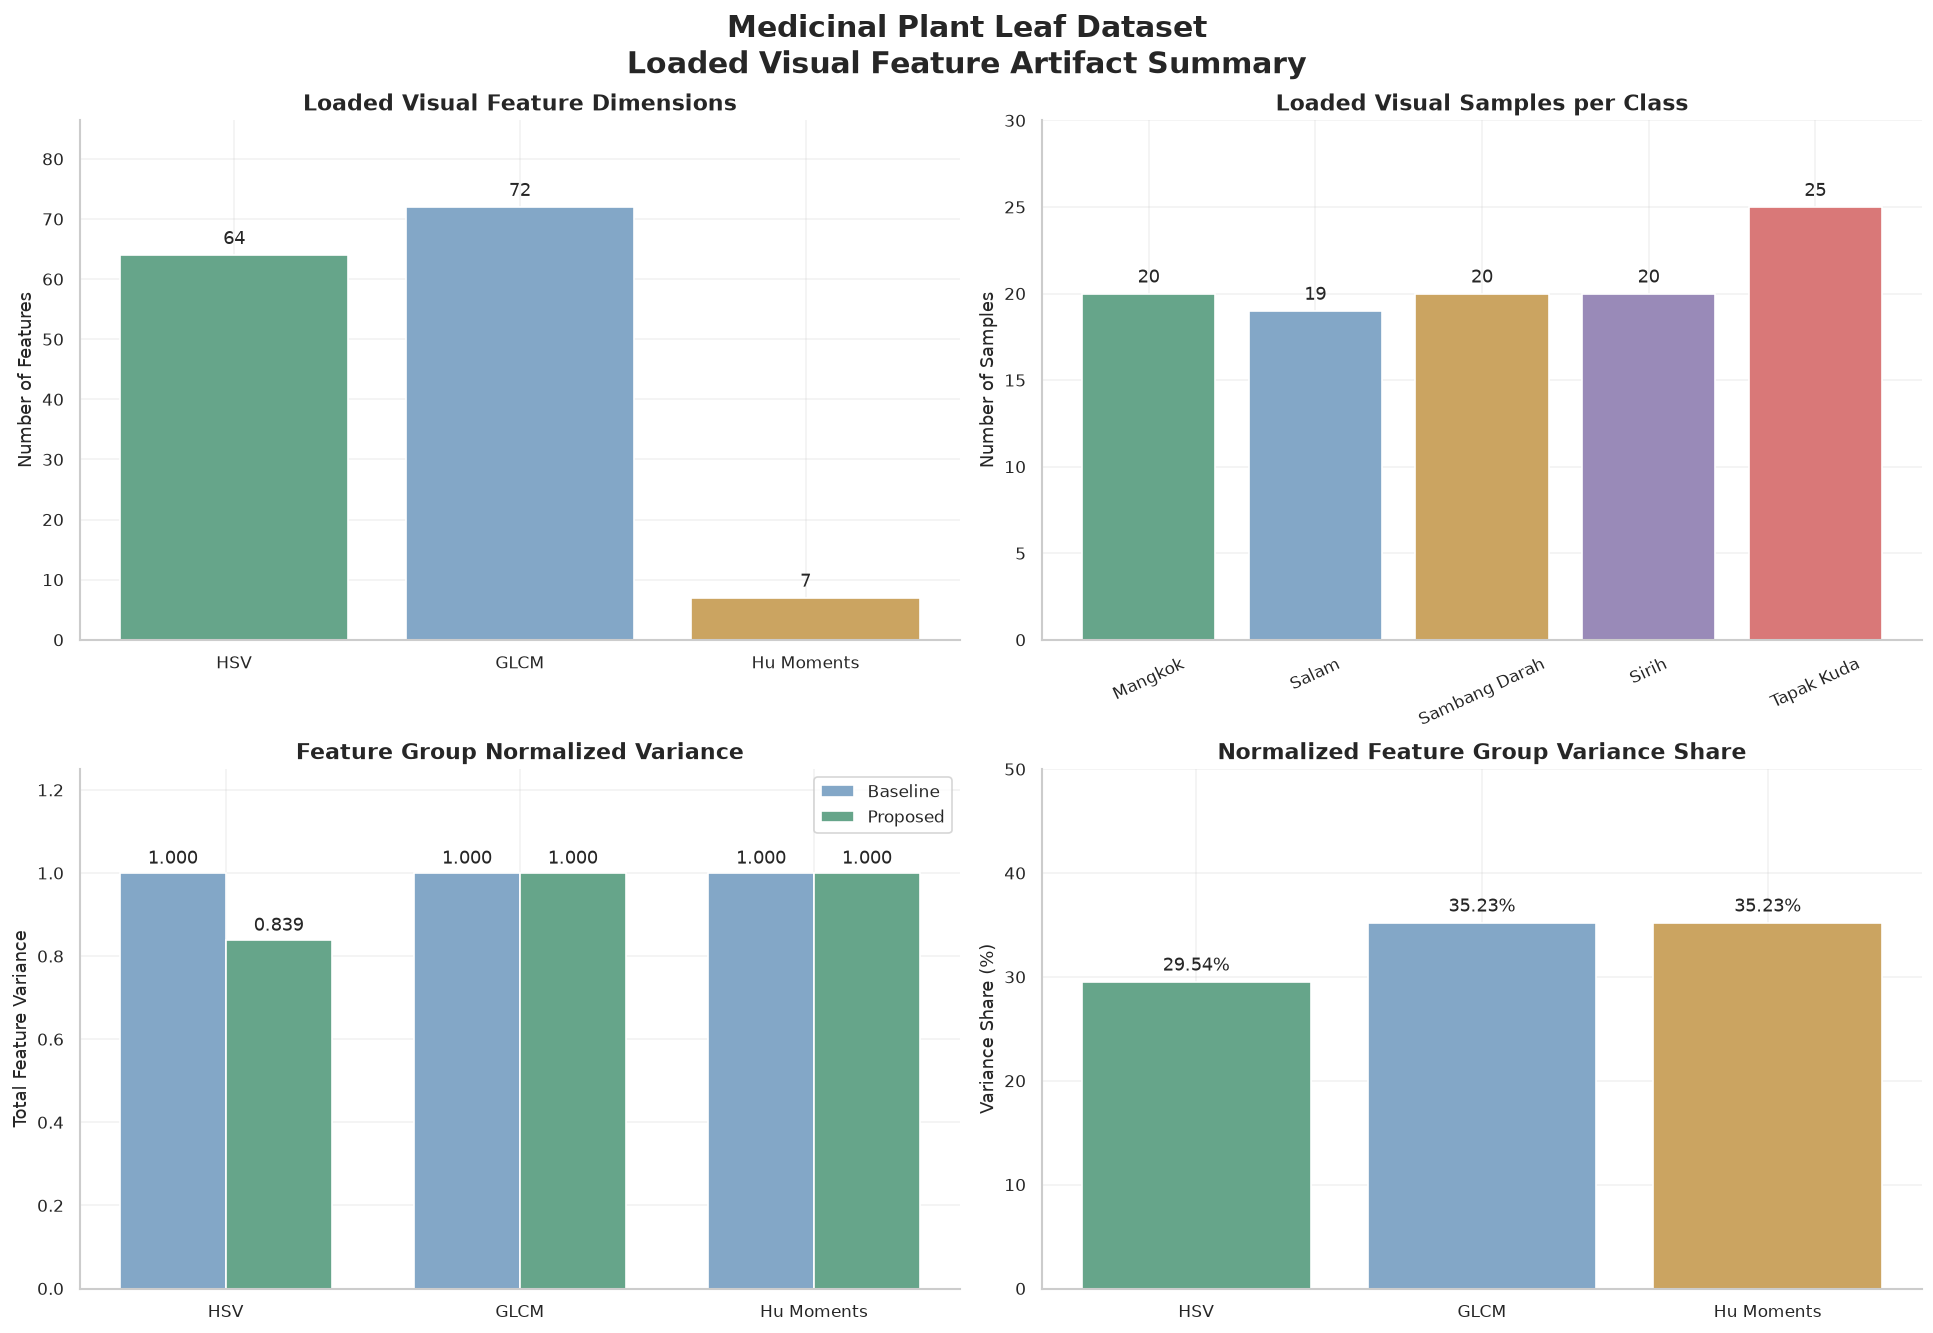

[SAVED] 104_loaded_visual_feature_summary.png


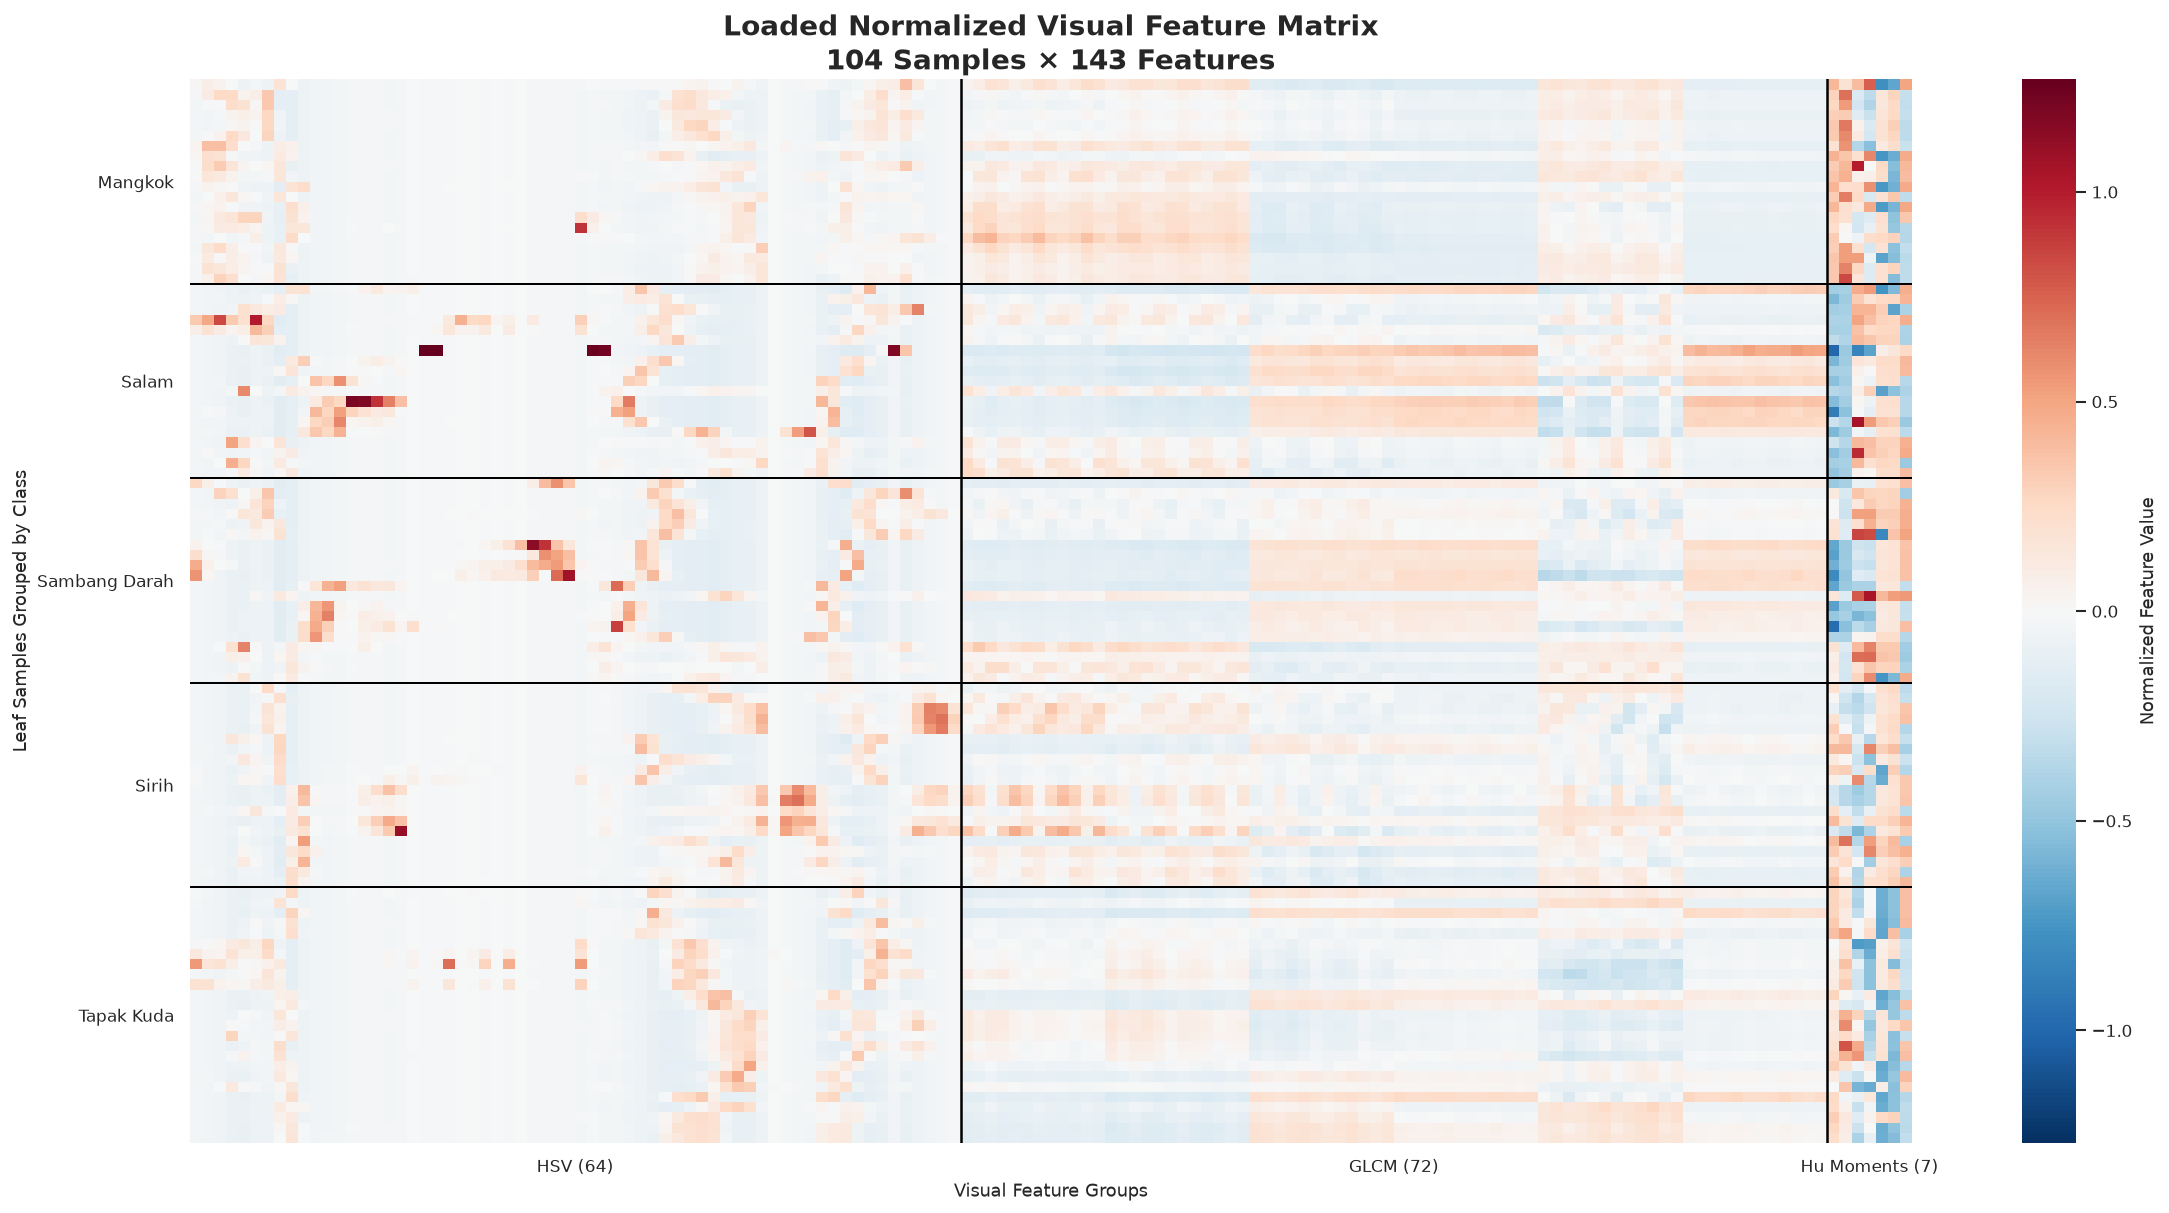

[SAVED] 105_loaded_visual_feature_matrix.png

15. VISUAL LOADING SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Total visual artifacts,14
1,Verified visual artifacts,14
2,Loaded NumPy arrays,8
3,Loaded visual normalizers,2
4,Total samples,104
5,Total classes,5
6,HSV feature dimension,64
7,GLCM feature dimension,72
8,Hu Moments feature dimension,7
9,Total visual feature dimension,143



16. SAVING VISUAL LOADING REPORTS
----------------------------------------------------------------------
[SAVED] 358_visual_artifact_integrity.csv
[SAVED] 359_loaded_visual_matrix_summary.csv
[SAVED] 360_visual_source_sample_alignment.csv
[SAVED] 361_visual_normalization_reconstruction.csv
[SAVED] 362_loaded_visual_group_summary.csv
[SAVED] 363_loaded_visual_class_summary.csv
[SAVED] 364_loaded_visual_review_summary.csv
[SAVED] 365_visual_loading_validation.csv
[SAVED] 366_visual_artifact_loading_times.csv
[SAVED] 367_visual_loading_summary.csv

FINAL VISUAL FEATURE LOADING SUMMARY

ARTIFACT INFORMATION
----------------------------------------------------------------------
Visual artifacts verified : 14/14
Loaded NumPy arrays       : 8
Loaded normalizers        : 2

VISUAL FEATURE DIMENSIONS
----------------------------------------------------------------------
HSV features        : (104, 64)
GLCM features       : (104, 72)
Hu Moments features : (104, 7)
Raw visual matrix   : (104, 14

In [5]:
# ==================================================
# CELL 4 - LOAD VISUAL FEATURE ARTIFACTS
# ==================================================

print("MULTIMODAL FUSION - LOAD VISUAL FEATURE ARTIFACTS")
print("=" * 70)

VISUAL_FEATURE_LOADING_COMPLETED = False
VISUAL_FEATURES_LOADED = False


# ==================================================
# 1. VALIDATE PREVIOUS PROCESSING STAGES
# ==================================================

assert FUSION_LIBRARIES_IMPORTED is True

assert FUSION_PATH_CONFIGURATION_COMPLETED is True, (
    "Run Cell 3 - Path Configuration first."
)

assert fusion_path_validation_df["passed"].all()

print("[PASS] Previous processing stages validated.")


# ==================================================
# 2. VISUAL FEATURE CONFIGURATION
# ==================================================

EXPECTED_VISUAL_SAMPLES = 104

EXPECTED_VISUAL_DIMENSION = 143

VISUAL_LOADING_TOLERANCE = 1e-10

VISUAL_HSV_SD_FLOOR = 0.001

VISUAL_FEATURE_GROUP_DIMENSIONS = {
    "HSV": 64,
    "GLCM": 72,
    "Hu Moments": 7
}

VISUAL_FEATURE_GROUP_ORDER = [
    "HSV",
    "GLCM",
    "Hu Moments"
]

VISUAL_FEATURE_GROUP_SLICES = {
    "HSV": slice(0, 64),
    "GLCM": slice(64, 136),
    "Hu Moments": slice(136, 143)
}

VISUAL_LOADING_SCOPE = (
    "Full Dataset - Gallery Development"
)

visual_loading_validation_records = []
visual_loading_figure_paths = []

print("\n1. VISUAL FEATURE CONFIGURATION")
print("-" * 70)

print(f"Expected samples   : {EXPECTED_VISUAL_SAMPLES}")
print(f"Expected dimension : {EXPECTED_VISUAL_DIMENSION}")
print(f"HSV SD floor       : {VISUAL_HSV_SD_FLOOR}")
print(f"Numerical tolerance: {VISUAL_LOADING_TOLERANCE}")
print(f"Loading scope      : {VISUAL_LOADING_SCOPE}")


# ==================================================
# 3. HELPER FUNCTIONS
# ==================================================

def register_visual_loading_check(
    category,
    check_name,
    passed
):

    visual_loading_validation_records.append({
        "category": category,
        "validation_check": check_name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


def to_clean_string_array(values):

    # Convert any input (object/list/Series) into a
    # trimmed NumPy unicode array (dtype "<U...").
    # np.char functions in NumPy 2.x reject object arrays.

    return (
        pd.Series(np.asarray(values).ravel())
        .astype(str)
        .str.strip()
        .to_numpy(dtype=str)
    )


def all_nonempty_strings(values):

    return bool(
        (pd.Series(np.asarray(values).ravel())
         .astype(str)
         .str.strip() != "").all()
    )


def calculate_artifact_sha256(file_path):

    checksum = hashlib.sha256()

    with open(file_path, "rb") as file:

        for block in iter(
            lambda: file.read(65536),
            b""
        ):
            checksum.update(block)

    return checksum.hexdigest()


def read_fusion_json(file_path):

    with open(
        file_path,
        "r",
        encoding="utf-8-sig"
    ) as file:

        return json.load(file)


def save_visual_loading_figure(fig, filename):

    output_path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    visual_loading_figure_paths.append(output_path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


# ==================================================
# 4. LOAD VISUAL ARTIFACT MANIFEST
# ==================================================

# Prefer the CSV manifest generated in Notebook 03.

if VISUAL_MANIFEST_CSV_PATH.is_file():

    loaded_visual_manifest_df = pd.read_csv(
        VISUAL_MANIFEST_CSV_PATH,
        dtype={
            "filename": str,
            "relative_path": str,
            "sha256": str
        },
        keep_default_na=False
    )

    visual_manifest_source = VISUAL_MANIFEST_CSV_PATH

else:

    # Support JSON manifests containing artifact records.

    visual_manifest_payload = read_fusion_json(
        VISUAL_MANIFEST_JSON_PATH
    )

    def extract_manifest_records(node):

        records = []

        if isinstance(node, list):

            for item in node:
                records.extend(
                    extract_manifest_records(item)
                )

        elif isinstance(node, dict):

            if {
                "filename",
                "sha256",
                "size_bytes"
            }.issubset(node):

                records.append(node)

            else:

                for value in node.values():
                    records.extend(
                        extract_manifest_records(value)
                    )

        return records

    loaded_visual_manifest_df = pd.DataFrame(
        extract_manifest_records(
            visual_manifest_payload
        )
    )

    visual_manifest_source = VISUAL_MANIFEST_JSON_PATH


required_manifest_columns = {
    "filename",
    "size_bytes",
    "sha256"
}

assert required_manifest_columns.issubset(
    loaded_visual_manifest_df.columns
), "Unsupported visual manifest structure."

assert loaded_visual_manifest_df[
    "filename"
].is_unique

visual_manifest_index = (
    loaded_visual_manifest_df
    .set_index("filename")
)

expected_visual_filenames = {
    path.name
    for path in VISUAL_ARTIFACT_PATHS.values()
}

register_visual_loading_check(
    "Manifest",
    "All expected visual artifacts listed",
    expected_visual_filenames.issubset(
        set(visual_manifest_index.index)
    )
)

assert expected_visual_filenames.issubset(
    set(visual_manifest_index.index)
), "Some visual artifacts are absent from the manifest."

print("\n2. VISUAL ARTIFACT MANIFEST")
print("-" * 70)

print(f"Manifest source: {visual_manifest_source.name}")
print(f"Manifest records: {len(loaded_visual_manifest_df)}")

display(
    loaded_visual_manifest_df[
        ["filename", "size_bytes", "sha256"]
    ]
)


# ==================================================
# 5. VERIFY ARTIFACT CHECKSUMS BEFORE LOADING
# ==================================================

visual_artifact_integrity_records = []

for artifact_name, file_path in (
    VISUAL_ARTIFACT_PATHS.items()
):

    manifest_record = visual_manifest_index.loc[
        file_path.name
    ]

    expected_size = int(
        manifest_record["size_bytes"]
    )

    expected_checksum = str(
        manifest_record["sha256"]
    ).strip().lower()

    exists = file_path.is_file()

    actual_size = (
        file_path.stat().st_size
        if exists
        else 0
    )

    actual_checksum = (
        calculate_artifact_sha256(file_path)
        if exists
        else ""
    )

    size_match = (
        exists
        and actual_size == expected_size
    )

    checksum_match = (
        exists
        and actual_checksum == expected_checksum
    )

    passed = (
        exists
        and size_match
        and checksum_match
    )

    visual_artifact_integrity_records.append({
        "artifact": artifact_name,
        "filename": file_path.name,
        "expected_size_bytes": expected_size,
        "actual_size_bytes": actual_size,
        "expected_sha256": expected_checksum,
        "actual_sha256": actual_checksum,
        "file_exists": exists,
        "size_match": size_match,
        "checksum_match": checksum_match,
        "passed": passed
    })

    register_visual_loading_check(
        "Artifact Integrity",
        f"{file_path.name} file size and checksum",
        passed
    )

    print(
        f"[{'PASS' if passed else 'FAIL'}] "
        f"{file_path.name}"
    )


visual_artifact_integrity_df = pd.DataFrame(
    visual_artifact_integrity_records
)

visual_artifact_integrity_df.to_csv(
    METRICS_DIR / "358_visual_artifact_integrity.csv",
    index=False,
    encoding="utf-8-sig"
)

assert visual_artifact_integrity_df["passed"].all(), (
    visual_artifact_integrity_df.loc[
        ~visual_artifact_integrity_df["passed"]
    ].to_string(index=False)
)

print("\n[PASS] All visual artifact checksums verified.")


# ==================================================
# 6. LOAD VISUAL NUMPY ARRAYS
# ==================================================

visual_array_keys = [
    "hsv_features",
    "glcm_features",
    "hu_features",
    "hu_raw_moments",
    "raw_features",
    "baseline_features",
    "normalized_features",
    "sample_ids"
]

loaded_visual_arrays = {}
visual_loading_time_records = []

print("\n3. LOADING VISUAL NUMPY ARRAYS")
print("-" * 70)

for artifact_name in visual_array_keys:

    start_time = time.perf_counter()

    array = np.load(
        VISUAL_ARTIFACT_PATHS[artifact_name],
        allow_pickle=False
    )

    loading_time_ms = (
        time.perf_counter() - start_time
    ) * 1000

    loaded_visual_arrays[artifact_name] = array

    visual_loading_time_records.append({
        "artifact": artifact_name,
        "filename": (
            VISUAL_ARTIFACT_PATHS[
                artifact_name
            ].name
        ),
        "loading_time_ms": loading_time_ms,
        "array_shape": str(array.shape),
        "dtype": str(array.dtype)
    })

    print(
        f"[LOADED] {artifact_name}: "
        f"{array.shape}"
    )


# ==================================================
# 7. CREATE MAIN VISUAL FEATURE VARIABLES
# ==================================================

loaded_hsv_features = (
    loaded_visual_arrays["hsv_features"]
)

loaded_glcm_features = (
    loaded_visual_arrays["glcm_features"]
)

loaded_hu_features = (
    loaded_visual_arrays["hu_features"]
)

loaded_hu_raw_moments = (
    loaded_visual_arrays["hu_raw_moments"]
)

loaded_visual_raw_features = (
    loaded_visual_arrays["raw_features"]
)

loaded_visual_baseline_features = (
    loaded_visual_arrays["baseline_features"]
)

loaded_visual_normalized_features = (
    loaded_visual_arrays["normalized_features"]
)

loaded_visual_sample_ids = to_clean_string_array(
    loaded_visual_arrays["sample_ids"]
)

# Main representation for subsequent fusion.

visual_features = (
    loaded_visual_normalized_features
)

visual_sample_ids = (
    loaded_visual_sample_ids
)

visual_n_samples = len(
    loaded_visual_sample_ids
)

VISUAL_FEATURE_DIM = (
    visual_features.shape[1]
)


# ==================================================
# 8. VALIDATE MATRIX DIMENSIONS AND VALUES
# ==================================================

visual_expected_shapes = {
    "hsv_features": (104, 64),
    "glcm_features": (104, 72),
    "hu_features": (104, 7),
    "hu_raw_moments": (104, 7),
    "raw_features": (104, 143),
    "baseline_features": (104, 143),
    "normalized_features": (104, 143)
}

visual_matrix_records = []

for artifact_name, expected_shape in (
    visual_expected_shapes.items()
):

    matrix = loaded_visual_arrays[
        artifact_name
    ]

    correct_shape = (
        matrix.shape == expected_shape
    )

    correct_dtype = (
        matrix.dtype == np.float64
    )

    finite_values = bool(
        np.isfinite(matrix).all()
    )

    register_visual_loading_check(
        "Matrix Validation",
        f"{artifact_name} correct dimensions",
        correct_shape
    )

    register_visual_loading_check(
        "Matrix Validation",
        f"{artifact_name} float64 dtype",
        correct_dtype
    )

    register_visual_loading_check(
        "Matrix Validation",
        f"{artifact_name} finite values",
        finite_values
    )

    visual_matrix_records.append({
        "artifact": artifact_name,
        "number_of_samples": matrix.shape[0],
        "feature_dimension": matrix.shape[1],
        "matrix_shape": str(matrix.shape),
        "dtype": str(matrix.dtype),
        "minimum_value": float(matrix.min()),
        "maximum_value": float(matrix.max()),
        "mean_value": float(matrix.mean()),
        "std_value": float(matrix.std()),
        "nan_values": int(np.isnan(matrix).sum()),
        "infinite_values": int(np.isinf(matrix).sum()),
        "memory_kib": matrix.nbytes / 1024,
        "passed": (
            correct_shape
            and correct_dtype
            and finite_values
        )
    })


visual_loaded_matrix_summary_df = pd.DataFrame(
    visual_matrix_records
)

print("\n4. VISUAL MATRIX VALIDATION")
print("-" * 70)

display(
    visual_loaded_matrix_summary_df.round(6)
)

assert visual_loaded_matrix_summary_df[
    "passed"
].all()


# ==================================================
# 9. VALIDATE SAMPLE IDENTITIES
# ==================================================

visual_id_checks = {

    "Sample ID array is one dimensional":
        loaded_visual_sample_ids.ndim == 1,

    "Expected sample ID count":
        visual_n_samples == EXPECTED_VISUAL_SAMPLES,

    "Sample IDs are unique":
        len(np.unique(loaded_visual_sample_ids))
        == visual_n_samples,

    "Sample IDs are nonempty":
        all_nonempty_strings(
            loaded_visual_sample_ids
        ),

    "Sample IDs contain no invalid placeholders":
        not pd.Series(loaded_visual_sample_ids)
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["nan", "none", "null"])
        .any()
}

for check_name, passed in visual_id_checks.items():

    register_visual_loading_check(
        "Sample Identity",
        check_name,
        passed
    )

assert all(visual_id_checks.values()), (
    "Invalid visual sample IDs detected."
)

print("\n5. VISUAL SAMPLE IDENTITIES")
print("-" * 70)

print(f"Total sample IDs  : {visual_n_samples}")

print(
    "Unique sample IDs :",
    len(np.unique(loaded_visual_sample_ids))
)

print("First five IDs:")

display(loaded_visual_sample_ids[:5])


# ==================================================
# 10. LOAD VISUAL METADATA
# ==================================================

loaded_visual_metadata_df = pd.read_csv(
    VISUAL_METADATA_PATH,
    dtype={"sample_id": str},
    keep_default_na=False,
    float_precision="round_trip"
)

loaded_processed_metadata_df = pd.read_csv(
    PROCESSED_METADATA_PATH,
    dtype={"sample_id": str},
    keep_default_na=False,
    float_precision="round_trip"
)

required_visual_metadata_columns = {
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "processed_image_path",
    "mask_path",
    "validation_status"
}

assert required_visual_metadata_columns.issubset(
    loaded_visual_metadata_df.columns
), (
    "Required visual metadata columns missing."
)

assert {
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "processed_image_path",
    "mask_path",
    "multimodal_valid",
    "final_dataset_status"
}.issubset(
    loaded_processed_metadata_df.columns
)

assert loaded_visual_metadata_df[
    "sample_id"
].is_unique

assert loaded_processed_metadata_df[
    "sample_id"
].is_unique

assert len(loaded_visual_metadata_df) == visual_n_samples

assert np.array_equal(
    loaded_visual_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str),
    loaded_visual_sample_ids
), "Visual metadata row order mismatch."

assert set(
    loaded_visual_sample_ids
) == set(
    loaded_processed_metadata_df["sample_id"]
), "Source and visual sample coverage mismatch."

# Align source metadata only.
# The saved feature matrix order remains unchanged.

visual_source_aligned_df = (
    loaded_processed_metadata_df
    .set_index("sample_id")
    .loc[loaded_visual_sample_ids]
    .reset_index()
)

loaded_visual_labels = to_clean_string_array(
    loaded_visual_metadata_df["kelas"]
)

visual_labels = loaded_visual_labels

visual_class_names = sorted(
    np.unique(visual_labels)
)

# Identify the saved row-index column.

visual_row_index_column = next(
    (
        column
        for column in [
            "feature_row_index",
            "visual_feature_row",
            "feature_row",
            "row_index",
            "sample_index"
        ]
        if column in loaded_visual_metadata_df.columns
    ),
    None
)

assert visual_row_index_column is not None, (
    "Saved visual feature row-index column not found."
)

saved_row_indices = pd.to_numeric(
    loaded_visual_metadata_df[
        visual_row_index_column
    ],
    errors="raise"
).to_numpy()

register_visual_loading_check(
    "Metadata Alignment",
    "Visual row indices sequential",
    np.array_equal(
        saved_row_indices,
        np.arange(visual_n_samples)
    )
)

print("\n6. VISUAL METADATA")
print("-" * 70)

print(
    "Visual metadata shape:",
    loaded_visual_metadata_df.shape
)

display(
    loaded_visual_metadata_df[
        [
            "sample_id",
            "nama_file",
            "kelas",
            "tampilan_daun",
            "validation_status"
        ]
    ].head(10)
)


# ==================================================
# 11. VALIDATE METADATA ALIGNMENT
# ==================================================

visual_sample_alignment_df = pd.DataFrame({
    "row_index": np.arange(visual_n_samples),
    "sample_id": loaded_visual_sample_ids,
    "kelas": visual_labels
})

visual_identity_columns = [
    "sample_id",
    "nama_file",
    "kelas",
    "tampilan_daun",
    "processed_image_path",
    "mask_path"
]

visual_alignment_columns = []

for column in visual_identity_columns:

    visual_values = (
        loaded_visual_metadata_df[
            column
        ].astype(str).to_numpy()
    )

    source_values = (
        visual_source_aligned_df[
            column
        ].astype(str).to_numpy()
    )

    match_column = f"{column}_match"

    visual_sample_alignment_df[
        match_column
    ] = (
        visual_values == source_values
    )

    visual_alignment_columns.append(
        match_column
    )

    register_visual_loading_check(
        "Metadata Alignment",
        f"{column} matches processed metadata",
        visual_sample_alignment_df[
            match_column
        ].all()
    )


visual_sample_alignment_df[
    "alignment_passed"
] = visual_sample_alignment_df[
    visual_alignment_columns
].all(axis=1)

register_visual_loading_check(
    "Metadata Alignment",
    "All visual samples match source metadata",
    visual_sample_alignment_df[
        "alignment_passed"
    ].all()
)

assert visual_sample_alignment_df[
    "alignment_passed"
].all()

print("[PASS] Visual metadata alignment validated.")


# ==================================================
# 12. LOAD VISUAL FEATURE INDEX AND CONFIGURATION
# ==================================================

loaded_visual_feature_index_df = pd.read_csv(
    VISUAL_ARTIFACT_PATHS["feature_index"],
    encoding="utf-8-sig",
    keep_default_na=False
)

loaded_visual_feature_names_payload = read_fusion_json(
    VISUAL_ARTIFACT_PATHS["feature_names"]
)

loaded_visual_config = read_fusion_json(
    VISUAL_ARTIFACT_PATHS["configuration"]
)

# Clean CSV header names.
loaded_visual_feature_index_df.columns = (
    loaded_visual_feature_index_df.columns
    .astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
)

print("\n7. VISUAL FEATURE INDEX")
print("-" * 70)

print(
    "Original CSV columns:",
    loaded_visual_feature_index_df.columns.tolist()
)

print(
    "Total feature records:",
    len(loaded_visual_feature_index_df)
)

# --------------------------------------------------
# A. Detect column names based on actual CSV schema
# --------------------------------------------------

def find_existing_column(dataframe, candidates):

    lookup = {
        str(column).strip().lower(): column
        for column in dataframe.columns
    }

    for candidate in candidates:

        match = lookup.get(candidate.lower())

        if match is not None:
            return match

    return None


index_column = find_existing_column(
    loaded_visual_feature_index_df,
    [
        "feature_index",
        "global_feature_index",
        "global_index",
        "column_index",
        "feature_position",
        "index",
        "idx"
    ]
)

name_column = find_existing_column(
    loaded_visual_feature_index_df,
    [
        "feature_name",
        "feature",
        "name",
        "feature_label",
        "feature_id",
        "feature_description"
    ]
)

group_column = find_existing_column(
    loaded_visual_feature_index_df,
    [
        "feature_group",
        "group",
        "feature_type",
        "feature_category"
    ]
)

print("Detected index column:", index_column)
print("Detected name column :", name_column)
print("Detected group column:", group_column)

# Do not invent feature names or indices.
# Report the real schema if it is not recognized.

if index_column is None or name_column is None:

    display(
        loaded_visual_feature_index_df.head(5)
    )

    raise ValueError(
        "Visual feature index CSV schema is not recognized. "
        f"Available columns: "
        f"{loaded_visual_feature_index_df.columns.tolist()}"
    )

# --------------------------------------------------
# B. Standardize column names for subsequent checks
# --------------------------------------------------

rename_columns = {
    index_column: "feature_index",
    name_column: "feature_name"
}

if group_column is not None:

    rename_columns[group_column] = "feature_group"

loaded_visual_feature_index_df = (
    loaded_visual_feature_index_df.rename(
        columns=rename_columns
    )
)

# Validate row count.

assert len(
    loaded_visual_feature_index_df
) == EXPECTED_VISUAL_DIMENSION, (
    "Feature index row count does not match "
    "the expected 143 visual features."
)

# --------------------------------------------------
# C. Validate and normalize feature indices
# --------------------------------------------------

feature_indices = pd.to_numeric(
    loaded_visual_feature_index_df["feature_index"],
    errors="raise"
).to_numpy()

expected_zero_based = np.arange(
    EXPECTED_VISUAL_DIMENSION
)

expected_one_based = np.arange(
    1,
    EXPECTED_VISUAL_DIMENSION + 1
)

if np.array_equal(
    feature_indices,
    expected_zero_based
):

    print("[PASS] Zero-based feature indices detected.")

elif np.array_equal(
    feature_indices,
    expected_one_based
):

    print("[INFO] One-based feature indices detected.")

    # Convert index labels to zero-based positions.
    # The row order is not changed.

    loaded_visual_feature_index_df[
        "feature_index"
    ] = expected_zero_based

else:

    raise ValueError(
        "Feature indices are not sequential "
        "or do not follow the saved column order."
    )

# --------------------------------------------------
# D. Validate feature names
# --------------------------------------------------

# FIX: use dtype=str so the array is "<U..." rather
# than object dtype (np.char rejects object arrays).

loaded_visual_feature_names = to_clean_string_array(
    loaded_visual_feature_index_df["feature_name"]
)

assert len(
    np.unique(loaded_visual_feature_names)
) == EXPECTED_VISUAL_DIMENSION, (
    "Duplicate visual feature names detected."
)

assert all_nonempty_strings(
    loaded_visual_feature_names
), "Empty visual feature names detected."

# Normalize recognized group labels without
# changing the feature-group sequence.

if "feature_group" in loaded_visual_feature_index_df:

    normalized_groups = (
        loaded_visual_feature_index_df[
            "feature_group"
        ]
        .astype(str)
        .str.strip()
    )

    group_aliases = {
        "hsv": "HSV",
        "glcm": "GLCM",
        "hu": "Hu Moments",
        "hu moments": "Hu Moments",
        "hu_moments": "Hu Moments",
        "humoments": "Hu Moments"
    }

    loaded_visual_feature_index_df[
        "feature_group"
    ] = normalized_groups.map(
        lambda value: group_aliases.get(
            value.lower(),
            value
        )
    )

# --------------------------------------------------
# E. Register validation results
# --------------------------------------------------

register_visual_loading_check(
    "Feature Index",
    "Visual feature indices sequential",
    np.array_equal(
        loaded_visual_feature_index_df[
            "feature_index"
        ].to_numpy(),
        expected_zero_based
    )
)

register_visual_loading_check(
    "Feature Index",
    "Visual feature names unique",
    len(np.unique(
        loaded_visual_feature_names
    )) == EXPECTED_VISUAL_DIMENSION
)

register_visual_loading_check(
    "Feature Index",
    "Visual feature names nonempty",
    all_nonempty_strings(
        loaded_visual_feature_names
    )
)

print("\nStandardized CSV columns:")
print(
    loaded_visual_feature_index_df.columns.tolist()
)

display(
    loaded_visual_feature_index_df.head(10)
)

print("[PASS] Visual feature index loaded and validated.")


# ==================================================
# 13. VALIDATE FEATURE NAME ORDER
# ==================================================

# Support either a single complete feature-name list
# or separate lists for HSV, GLCM, and Hu Moments.

def collect_feature_name_lists(node):

    results = []

    if isinstance(node, list):

        if node and all(
            isinstance(item, str)
            for item in node
        ):

            results.append(node)

        else:

            for item in node:

                results.extend(
                    collect_feature_name_lists(item)
                )

    elif isinstance(node, dict):

        for value in node.values():

            results.extend(
                collect_feature_name_lists(value)
            )

    return results


visual_name_lists = [
    [str(name).strip() for name in names]
    for names in collect_feature_name_lists(
        loaded_visual_feature_names_payload
    )
]

expected_names_list = (
    loaded_visual_feature_names.tolist()
)

complete_name_order_match = any(
    names == expected_names_list
    for names in visual_name_lists
)

group_name_order_match = all(

    any(
        names == expected_names_list[
            VISUAL_FEATURE_GROUP_SLICES[group_name]
        ]

        for names in visual_name_lists
    )

    for group_name in VISUAL_FEATURE_GROUP_ORDER
)

register_visual_loading_check(
    "Feature Index",
    "Feature-name JSON matches feature index",
    complete_name_order_match
    or group_name_order_match
)

register_visual_loading_check(
    "Feature Index",
    "Feature configuration loaded",
    isinstance(loaded_visual_config, dict)
    and len(loaded_visual_config) > 0
)

if "feature_group" in (
    loaded_visual_feature_index_df.columns
):

    expected_group_sequence = np.repeat(
        VISUAL_FEATURE_GROUP_ORDER,
        [64, 72, 7]
    )

    actual_group_sequence = (
        loaded_visual_feature_index_df[
            "feature_group"
        ].to_numpy(dtype=str)
    )

    register_visual_loading_check(
        "Feature Index",
        "Feature group order preserved",
        np.array_equal(
            actual_group_sequence,
            expected_group_sequence
        )
    )


print("\n7. VISUAL FEATURE INDEX")
print("-" * 70)

print(
    "Feature names:",
    len(loaded_visual_feature_names)
)

display(
    loaded_visual_feature_index_df.head(10)
)


# ==================================================
# 14. LOAD SAVED NORMALIZERS
# ==================================================

# Only load locally generated, trusted Joblib files.
# The manifest checks were completed before this stage.

loaded_visual_normalizer = joblib.load(
    VISUAL_ARTIFACT_PATHS["normalizer"]
)

loaded_baseline_visual_normalizer = joblib.load(
    VISUAL_ARTIFACT_PATHS["baseline_normalizer"]
)

register_visual_loading_check(
    "Normalizer Loading",
    "Main visual normalizer loaded",
    loaded_visual_normalizer is not None
)

register_visual_loading_check(
    "Normalizer Loading",
    "Baseline visual normalizer loaded",
    loaded_baseline_visual_normalizer is not None
)

print("\n8. LOADED VISUAL NORMALIZERS")
print("-" * 70)

print(
    "Main normalizer type:",
    type(loaded_visual_normalizer).__name__
)

print(
    "Baseline normalizer type:",
    type(loaded_baseline_visual_normalizer).__name__
)

if isinstance(loaded_visual_normalizer, dict):

    print(
        "Main normalizer keys:",
        list(loaded_visual_normalizer.keys())
    )

if isinstance(
    loaded_baseline_visual_normalizer,
    dict
):

    print(
        "Baseline normalizer keys:",
        list(
            loaded_baseline_visual_normalizer.keys()
        )
    )


# ==================================================
# 15. RECONSTRUCT RAW FEATURE CONCATENATION
# ==================================================

reconstructed_visual_raw_features = np.hstack([
    loaded_hsv_features,
    loaded_glcm_features,
    loaded_hu_features
])

visual_raw_reconstruction_difference = float(
    np.max(
        np.abs(
            reconstructed_visual_raw_features
            - loaded_visual_raw_features
        )
    )
)

register_visual_loading_check(
    "Feature Reconstruction",
    "Raw feature concatenation exactly preserved",
    np.array_equal(
        reconstructed_visual_raw_features,
        loaded_visual_raw_features
    )
)

print("\n9. RAW FEATURE RECONSTRUCTION")
print("-" * 70)

print(
    "Reconstructed raw shape:",
    reconstructed_visual_raw_features.shape
)

print(
    "Maximum reconstruction difference:",
    f"{visual_raw_reconstruction_difference:.3e}"
)


# ==================================================
# 16. VERIFY NORMALIZATION MATHEMATICALLY
# ==================================================

# Independently reproduce the documented normalization
# formulas from Notebook 03.
#
# No saved normalizer is refitted or modified.
# Reconstructed arrays are used only for verification.

visual_raw_group_matrices = {
    "HSV": loaded_hsv_features,
    "GLCM": loaded_glcm_features,
    "Hu Moments": loaded_hu_features
}

visual_reconstructed_baseline_groups = {}

visual_reconstructed_normalized_groups = {}

visual_normalization_records = []

for group_name in VISUAL_FEATURE_GROUP_ORDER:

    raw_group = visual_raw_group_matrices[
        group_name
    ]

    dimension = raw_group.shape[1]

    feature_mean = raw_group.mean(axis=0)

    feature_std = raw_group.std(
        axis=0,
        ddof=0
    )

    constant_mask = feature_std == 0

    baseline_scale = np.where(
        constant_mask,
        1.0,
        feature_std
    )

    proposed_scale = baseline_scale.copy()

    floor_mask = np.zeros(
        dimension,
        dtype=bool
    )

    if group_name == "HSV":

        floor_mask = (
            (feature_std < VISUAL_HSV_SD_FLOOR)
            & ~constant_mask
        )

        proposed_scale[floor_mask] = (
            VISUAL_HSV_SD_FLOOR
        )

    # Group balancing.

    group_weight = 1.0 / np.sqrt(
        dimension
    )

    baseline_group = (
        (raw_group - feature_mean)
        / baseline_scale
    ) * group_weight

    proposed_group = (
        (raw_group - feature_mean)
        / proposed_scale
    ) * group_weight

    group_slice = (
        VISUAL_FEATURE_GROUP_SLICES[
            group_name
        ]
    )

    saved_baseline_group = (
        loaded_visual_baseline_features[
            :, group_slice
        ]
    )

    saved_normalized_group = (
        loaded_visual_normalized_features[
            :, group_slice
        ]
    )

    baseline_difference = float(
        np.max(
            np.abs(
                baseline_group
                - saved_baseline_group
            )
        )
    )

    proposed_difference = float(
        np.max(
            np.abs(
                proposed_group
                - saved_normalized_group
            )
        )
    )

    register_visual_loading_check(
        "Normalization Reconstruction",
        f"{group_name} baseline normalization consistent",
        baseline_difference <= VISUAL_LOADING_TOLERANCE
    )

    register_visual_loading_check(
        "Normalization Reconstruction",
        f"{group_name} proposed normalization consistent",
        proposed_difference <= VISUAL_LOADING_TOLERANCE
    )

    visual_reconstructed_baseline_groups[
        group_name
    ] = baseline_group

    visual_reconstructed_normalized_groups[
        group_name
    ] = proposed_group

    visual_normalization_records.append({
        "feature_group": group_name,
        "feature_dimension": dimension,
        "group_weight": group_weight,
        "constant_features": int(constant_mask.sum()),
        "sd_floor_adjusted_features": int(
            floor_mask.sum()
        ),
        "raw_total_variance": float(
            raw_group.var(axis=0).sum()
        ),
        "baseline_total_variance": float(
            saved_baseline_group.var(axis=0).sum()
        ),
        "normalized_total_variance": float(
            saved_normalized_group.var(axis=0).sum()
        ),
        "baseline_max_difference": baseline_difference,
        "normalized_max_difference": proposed_difference
    })


visual_normalization_reconstruction_df = pd.DataFrame(
    visual_normalization_records
)

print("\n10. NORMALIZATION RECONSTRUCTION")
print("-" * 70)

display(
    visual_normalization_reconstruction_df.round(8)
)


# ==================================================
# 17. VALIDATE COMPLETE NORMALIZED MATRICES
# ==================================================

reconstructed_visual_baseline_features = np.hstack([

    visual_reconstructed_baseline_groups[
        group_name
    ]

    for group_name in VISUAL_FEATURE_GROUP_ORDER

])

reconstructed_visual_normalized_features = np.hstack([

    visual_reconstructed_normalized_groups[
        group_name
    ]

    for group_name in VISUAL_FEATURE_GROUP_ORDER

])

visual_baseline_max_difference = float(
    np.max(
        np.abs(
            reconstructed_visual_baseline_features
            - loaded_visual_baseline_features
        )
    )
)

visual_normalized_max_difference = float(
    np.max(
        np.abs(
            reconstructed_visual_normalized_features
            - loaded_visual_normalized_features
        )
    )
)

register_visual_loading_check(
    "Normalization Reconstruction",
    "Complete baseline matrix reproduced",
    visual_baseline_max_difference
    <= VISUAL_LOADING_TOLERANCE
)

register_visual_loading_check(
    "Normalization Reconstruction",
    "Complete normalized matrix reproduced",
    visual_normalized_max_difference
    <= VISUAL_LOADING_TOLERANCE
)

register_visual_loading_check(
    "Normalization Reconstruction",
    "Normalized features centered around zero",
    np.allclose(
        visual_features.mean(axis=0),
        0,
        atol=VISUAL_LOADING_TOLERANCE,
        rtol=0
    )
)

print(
    "Baseline maximum difference:",
    f"{visual_baseline_max_difference:.3e}"
)

print(
    "Normalized maximum difference:",
    f"{visual_normalized_max_difference:.3e}"
)


# ==================================================
# 18. ANALYZE VISUAL FEATURE GROUPS
# ==================================================

visual_group_statistics_records = []

for group_name in VISUAL_FEATURE_GROUP_ORDER:

    group_slice = VISUAL_FEATURE_GROUP_SLICES[
        group_name
    ]

    group_matrix = visual_features[
        :, group_slice
    ]

    group_variance = group_matrix.var(
        axis=0
    )

    visual_group_statistics_records.append({
        "feature_group": group_name,
        "number_of_samples": group_matrix.shape[0],
        "feature_dimension": group_matrix.shape[1],
        "minimum_value": float(group_matrix.min()),
        "maximum_value": float(group_matrix.max()),
        "mean_value": float(group_matrix.mean()),
        "std_value": float(group_matrix.std()),
        "total_variance": float(group_variance.sum()),
        "constant_features": int(
            (np.ptp(group_matrix, axis=0) == 0).sum()
        ),
        "nan_values": int(
            np.isnan(group_matrix).sum()
        ),
        "infinite_values": int(
            np.isinf(group_matrix).sum()
        )
    })


visual_loaded_group_summary_df = pd.DataFrame(
    visual_group_statistics_records
)

total_visual_variance = (
    visual_loaded_group_summary_df[
        "total_variance"
    ].sum()
)

assert total_visual_variance > 0

visual_loaded_group_summary_df[
    "variance_share_percent"
] = (
    visual_loaded_group_summary_df[
        "total_variance"
    ]
    / total_visual_variance
    * 100
)

register_visual_loading_check(
    "Feature Groups",
    "Feature dimensions reconcile",
    visual_loaded_group_summary_df[
        "feature_dimension"
    ].sum() == EXPECTED_VISUAL_DIMENSION
)

register_visual_loading_check(
    "Feature Groups",
    "Feature group variance shares reconcile",
    np.isclose(
        visual_loaded_group_summary_df[
            "variance_share_percent"
        ].sum(),
        100.0,
        atol=VISUAL_LOADING_TOLERANCE
    )
)

print("\n11. VISUAL FEATURE GROUP SUMMARY")
print("-" * 70)

display(
    visual_loaded_group_summary_df.round(6)
)


# ==================================================
# 19. ANALYZE CLASS DISTRIBUTION
# ==================================================

visual_loaded_class_summary_df = (
    pd.Series(
        visual_labels,
        name="kelas"
    )
    .value_counts()
    .sort_index()
    .rename_axis("kelas")
    .reset_index(name="number_of_samples")
)

visual_loaded_class_summary_df[
    "percentage"
] = (
    visual_loaded_class_summary_df[
        "number_of_samples"
    ]
    / visual_n_samples
    * 100
)

expected_visual_class_counts = {
    "Mangkok": 20,
    "Salam": 19,
    "Sambang Darah": 20,
    "Sirih": 20,
    "Tapak Kuda": 25
}

actual_visual_class_counts = dict(zip(
    visual_loaded_class_summary_df["kelas"],
    visual_loaded_class_summary_df["number_of_samples"]
))

register_visual_loading_check(
    "Class Distribution",
    "Expected five-class distribution preserved",
    actual_visual_class_counts
    == expected_visual_class_counts
)

print("\n12. VISUAL CLASS DISTRIBUTION")
print("-" * 70)

display(
    visual_loaded_class_summary_df.round(4)
)


# ==================================================
# 20. PRESERVE DATASET REVIEW STATUS
# ==================================================

visual_loaded_review_summary_df = (
    visual_source_aligned_df[
        "final_dataset_status"
    ]
    .value_counts(dropna=False)
    .rename_axis("dataset_status")
    .reset_index(name="number_of_samples")
)

visual_loaded_review_summary_df[
    "percentage"
] = (
    visual_loaded_review_summary_df[
        "number_of_samples"
    ]
    / visual_n_samples
    * 100
)

source_technical_validity = (
    visual_source_aligned_df[
        "multimodal_valid"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

register_visual_loading_check(
    "Dataset Readiness",
    "All source samples technically valid",
    source_technical_validity.all()
)

register_visual_loading_check(
    "Dataset Readiness",
    "Dataset review status counts reconcile",
    visual_loaded_review_summary_df[
        "number_of_samples"
    ].sum() == visual_n_samples
)

print("\n13. DATASET REVIEW STATUS")
print("-" * 70)

display(
    visual_loaded_review_summary_df.round(4)
)

print(
    "[INFO] Manual review flags remain unchanged."
)


# ==================================================
# 21. FINAL VISUAL LOADING VALIDATION
# ==================================================

visual_loading_validation_df = pd.DataFrame(
    visual_loading_validation_records
)

visual_loading_total_checks = len(
    visual_loading_validation_df
)

visual_loading_passed_checks = int(
    visual_loading_validation_df[
        "passed"
    ].sum()
)

visual_loading_failed_checks = (
    visual_loading_total_checks
    - visual_loading_passed_checks
)

visual_loading_validation_df.to_csv(
    METRICS_DIR / "365_visual_loading_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n14. VISUAL FEATURE LOADING VALIDATION")
print("-" * 70)

display(visual_loading_validation_df)

assert visual_loading_validation_df[
    "passed"
].all(), (
    visual_loading_validation_df.loc[
        ~visual_loading_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All visual loading checks passed.")


# ==================================================
# 22. VISUALIZE LOADED VISUAL FEATURE SUMMARY
# ==================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11),
    constrained_layout=True
)

# A. Feature dimensions.

ax = axes[0, 0]

group_names = (
    visual_loaded_group_summary_df[
        "feature_group"
    ].tolist()
)

group_colors = [
    FEATURE_GROUP_COLORS[name]
    for name in group_names
]

bars = ax.bar(
    group_names,
    visual_loaded_group_summary_df[
        "feature_dimension"
    ],
    color=group_colors
)

ax.bar_label(bars, padding=4)

ax.set_title("Loaded Visual Feature Dimensions")
ax.set_ylabel("Number of Features")
ax.margins(y=0.2)


# B. Class distribution.

ax = axes[0, 1]

bars = ax.bar(
    visual_loaded_class_summary_df["kelas"],
    visual_loaded_class_summary_df[
        "number_of_samples"
    ],
    color=[
        CLASS_COLORS.get(name, "#83A7C7")
        for name in visual_loaded_class_summary_df[
            "kelas"
        ]
    ]
)

ax.bar_label(bars, padding=4)

ax.set_title("Loaded Visual Samples per Class")
ax.set_ylabel("Number of Samples")
ax.tick_params(axis="x", labelrotation=25)
ax.margins(y=0.2)


# C. Baseline vs proposed normalization variance.

ax = axes[1, 0]

positions = np.arange(len(group_names))

bars_baseline = ax.bar(
    positions - 0.18,
    visual_normalization_reconstruction_df[
        "baseline_total_variance"
    ],
    width=0.36,
    color="#83A7C7",
    label="Baseline"
)

bars_proposed = ax.bar(
    positions + 0.18,
    visual_normalization_reconstruction_df[
        "normalized_total_variance"
    ],
    width=0.36,
    color="#66A58A",
    label="Proposed"
)

ax.bar_label(
    bars_baseline,
    fmt="%.3f",
    padding=3
)

ax.bar_label(
    bars_proposed,
    fmt="%.3f",
    padding=3
)

ax.set_xticks(positions)
ax.set_xticklabels(group_names)

ax.set_title("Feature Group Normalized Variance")
ax.set_ylabel("Total Feature Variance")
ax.set_ylim(0, 1.25)
ax.legend()


# D. Variance contribution after normalization.

ax = axes[1, 1]

bars = ax.bar(
    group_names,
    visual_loaded_group_summary_df[
        "variance_share_percent"
    ],
    color=group_colors
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

ax.set_title("Normalized Feature Group Variance Share")
ax.set_ylabel("Variance Share (%)")
ax.set_ylim(0, 50)

fig.suptitle(
    "Medicinal Plant Leaf Dataset\n"
    "Loaded Visual Feature Artifact Summary",
    fontsize=18,
    fontweight="bold"
)

save_visual_loading_figure(
    fig,
    "104_loaded_visual_feature_summary.png"
)


# ==================================================
# 23. VISUALIZE LOADED VISUAL FEATURE MATRIX
# ==================================================

visual_plot_order = np.argsort(
    visual_labels,
    kind="stable"
)

visual_plot_labels = visual_labels[
    visual_plot_order
]

visual_plot_matrix = visual_features[
    visual_plot_order
]

visual_class_boundaries = np.flatnonzero(
    visual_plot_labels[1:]
    != visual_plot_labels[:-1]
) + 1

visual_class_starts = np.r_[
    0,
    visual_class_boundaries
]

visual_class_ends = np.r_[
    visual_class_boundaries,
    visual_n_samples
]

visual_class_centers = (
    visual_class_starts
    + visual_class_ends
) / 2

# Use symmetric limits around zero.

visual_heatmap_limit = float(
    np.max(np.abs(visual_plot_matrix))
)

fig, ax = plt.subplots(
    figsize=(18, 10),
    constrained_layout=True
)

sns.heatmap(
    visual_plot_matrix,
    cmap="RdBu_r",
    center=0,
    vmin=-visual_heatmap_limit,
    vmax=visual_heatmap_limit,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={
        "label": "Normalized Feature Value"
    },
    ax=ax
)

# Mark visual feature-group boundaries.

for boundary in [64, 136]:

    ax.axvline(
        boundary,
        color="black",
        linewidth=1.5
    )

# Mark class boundaries.

for boundary in visual_class_boundaries:

    ax.axhline(
        boundary,
        color="black",
        linewidth=1.2
    )

ax.set_xticks([
    32,
    100,
    139.5
])

ax.set_xticklabels([
    "HSV (64)",
    "GLCM (72)",
    "Hu Moments (7)"
], rotation=0)

ax.set_yticks(
    visual_class_centers
)

ax.set_yticklabels(
    visual_plot_labels[
        visual_class_starts
    ],
    rotation=0
)

ax.set_xlabel("Visual Feature Groups")
ax.set_ylabel("Leaf Samples Grouped by Class")

ax.set_title(
    "Loaded Normalized Visual Feature Matrix\n"
    f"{visual_n_samples} Samples × "
    f"{VISUAL_FEATURE_DIM} Features",
    fontsize=17,
    fontweight="bold"
)

save_visual_loading_figure(
    fig,
    "105_loaded_visual_feature_matrix.png"
)


# ==================================================
# 24. CREATE VISUAL LOADING SUMMARY
# ==================================================

visual_loading_time_df = pd.DataFrame(
    visual_loading_time_records
)

visual_loading_summary_df = pd.DataFrame([

    ("Total visual artifacts",
     len(VISUAL_ARTIFACT_PATHS)),

    ("Verified visual artifacts",
     int(visual_artifact_integrity_df["passed"].sum())),

    ("Loaded NumPy arrays",
     len(loaded_visual_arrays)),

    ("Loaded visual normalizers", 2),

    ("Total samples", visual_n_samples),

    ("Total classes", len(visual_class_names)),

    ("HSV feature dimension",
     loaded_hsv_features.shape[1]),

    ("GLCM feature dimension",
     loaded_glcm_features.shape[1]),

    ("Hu Moments feature dimension",
     loaded_hu_features.shape[1]),

    ("Total visual feature dimension",
     VISUAL_FEATURE_DIM),

    ("Raw visual matrix shape",
     str(loaded_visual_raw_features.shape)),

    ("Baseline visual matrix shape",
     str(loaded_visual_baseline_features.shape)),

    ("Normalized visual matrix shape",
     str(loaded_visual_normalized_features.shape)),

    ("Raw reconstruction maximum difference",
     visual_raw_reconstruction_difference),

    ("Baseline reconstruction maximum difference",
     visual_baseline_max_difference),

    ("Normalized reconstruction maximum difference",
     visual_normalized_max_difference),

    ("Total normalized feature variance",
     total_visual_variance),

    ("Aligned visual samples",
     int(
         visual_sample_alignment_df[
             "alignment_passed"
         ].sum()
     )),

    ("Total validation checks",
     visual_loading_total_checks),

    ("Validation checks passed",
     visual_loading_passed_checks),

    ("Validation checks failed",
     visual_loading_failed_checks),

    ("Generated figures",
     len(visual_loading_figure_paths)),

    ("Main visual representation",
     "visual_features_normalized.npy"),

    ("Raw visual features retained", True),

    ("Feature order preserved", True),

    ("Sample order preserved", True),

    ("Review flags preserved", True),

    ("Saved normalizers refitted", False),

    ("Visual features modified", False),

    ("Independent evaluation completed", False),

    ("Evaluation requires reference-only refit", True),

    ("Text features loaded", False),

    ("Image-text alignment validated", False),

    ("Multimodal fusion completed", False),

    ("Loading scope", VISUAL_LOADING_SCOPE)

], columns=["Indicator", "Result"])

print("\n15. VISUAL LOADING SUMMARY")
print("-" * 70)

display(visual_loading_summary_df)


# ==================================================
# 25. SAVE VISUAL LOADING REPORTS
# ==================================================

visual_loading_reports = {

    "358_visual_artifact_integrity.csv":
        visual_artifact_integrity_df,

    "359_loaded_visual_matrix_summary.csv":
        visual_loaded_matrix_summary_df,

    "360_visual_source_sample_alignment.csv":
        visual_sample_alignment_df,

    "361_visual_normalization_reconstruction.csv":
        visual_normalization_reconstruction_df,

    "362_loaded_visual_group_summary.csv":
        visual_loaded_group_summary_df,

    "363_loaded_visual_class_summary.csv":
        visual_loaded_class_summary_df,

    "364_loaded_visual_review_summary.csv":
        visual_loaded_review_summary_df,

    "365_visual_loading_validation.csv":
        visual_loading_validation_df,

    "366_visual_artifact_loading_times.csv":
        visual_loading_time_df,

    "367_visual_loading_summary.csv":
        visual_loading_summary_df
}

print("\n16. SAVING VISUAL LOADING REPORTS")
print("-" * 70)

for filename, dataframe in (
    visual_loading_reports.items()
):

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ==================================================
# 26. FINAL COMPLETION CHECKS
# ==================================================

assert visual_artifact_integrity_df[
    "passed"
].all()

assert visual_loading_validation_df[
    "passed"
].all()

assert visual_loading_failed_checks == 0

assert visual_features.shape == (104, 143)

assert len(visual_sample_ids) == 104

assert len(visual_labels) == 104

assert visual_sample_alignment_df[
    "alignment_passed"
].all()

assert np.isfinite(visual_features).all()

assert len(visual_loading_figure_paths) == 2

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in visual_loading_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in visual_loading_reports
)

VISUAL_FEATURE_LOADING_COMPLETED = True

VISUAL_FEATURES_LOADED = True


# ==================================================
# 27. PRINT FINAL SUMMARY
# ==================================================

print("\n" + "=" * 70)

print("FINAL VISUAL FEATURE LOADING SUMMARY")

print("=" * 70)

print("\nARTIFACT INFORMATION")
print("-" * 70)

print(
    f"Visual artifacts verified : "
    f"{visual_artifact_integrity_df['passed'].sum()}/"
    f"{len(VISUAL_ARTIFACT_PATHS)}"
)

print(
    f"Loaded NumPy arrays       : "
    f"{len(loaded_visual_arrays)}"
)

print("Loaded normalizers        : 2")


print("\nVISUAL FEATURE DIMENSIONS")
print("-" * 70)

print("HSV features        :", loaded_hsv_features.shape)

print("GLCM features       :", loaded_glcm_features.shape)

print("Hu Moments features :", loaded_hu_features.shape)

print("Raw visual matrix   :", loaded_visual_raw_features.shape)

print("Baseline matrix     :", loaded_visual_baseline_features.shape)

print("Normalized matrix   :", visual_features.shape)


print("\nDATASET INFORMATION")
print("-" * 70)

print(f"Total samples   : {visual_n_samples}")

print(f"Total classes   : {len(visual_class_names)}")

print(
    f"Aligned samples : "
    f"{visual_sample_alignment_df['alignment_passed'].sum()}"
)


print("\nRECONSTRUCTION RESULTS")
print("-" * 70)

print(
    f"Raw difference        : "
    f"{visual_raw_reconstruction_difference:.3e}"
)

print(
    f"Baseline difference   : "
    f"{visual_baseline_max_difference:.3e}"
)

print(
    f"Normalized difference : "
    f"{visual_normalized_max_difference:.3e}"
)


print("\nVALIDATION RESULTS")
print("-" * 70)

print(
    f"Technical checks  : "
    f"{visual_loading_passed_checks}/"
    f"{visual_loading_total_checks}"
)

print(
    f"Failed checks     : "
    f"{visual_loading_failed_checks}"
)

print(
    f"Generated reports : "
    f"{len(visual_loading_reports)}"
)

print(
    f"Generated figures : "
    f"{len(visual_loading_figure_paths)}"
)


print("\n[PASS] Visual artifact checksums verified.")

print("[PASS] All visual feature arrays loaded.")

print("[PASS] Visual matrix dimensions validated.")

print("[PASS] Visual sample identities validated.")

print("[PASS] Source metadata alignment validated.")

print("[PASS] Feature order validated.")

print("[PASS] Both saved visual normalizers loaded.")

print("[PASS] Raw feature concatenation validated.")

print("[PASS] Normalization formulas verified.")

print("[PASS] Original dataset review flags preserved.")

print("[PASS] All visual loading reports saved.")


print("\n[INFO] No visual features were re-extracted.")

print("[INFO] No saved normalizers were refitted.")

print("[INFO] No feature matrices were reordered.")

print("[INFO] Full-gallery features remain exploratory.")

print("[INFO] Text feature loading is the next stage.")

print("\n" + "=" * 70)

print("VISUAL FEATURE LOADING COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 5 - Load Text Feature Artifacts")

MULTIMODAL FUSION - LOAD TEXT FEATURE ARTIFACTS
[PASS] Previous cells validated.

1. TEXT ARTIFACT LOCATIONS
----------------------------------------------------------------------
Text feature directory: D:\Project\Multimodal_Leaf_Retrieval\dataset\features\text
Expected payload files : 16
Manifest              : text_feature_artifact_manifest.csv
[PASS] Text artifact manifest loaded.

2. TEXT ARTIFACT INTEGRITY
----------------------------------------------------------------------
[PASS] tfidf_unigram_features.npz
[PASS] tfidf_unigram_vectorizer.joblib
[PASS] tfidf_unigram_feature_names.npy
[PASS] tfidf_unigram_idf_weights.npy
[PASS] tfidf_unigram_vocabulary.csv
[PASS] tfidf_unigram_bigram_features.npz
[PASS] tfidf_unigram_bigram_vectorizer.joblib
[PASS] tfidf_unigram_bigram_feature_names.npy
[PASS] tfidf_unigram_bigram_idf_weights.npy
[PASS] tfidf_unigram_bigram_vocabulary.csv
[PASS] text_sample_ids.npy
[PASS] text_class_labels.npy
[PASS] multimodal_feature_metadata.csv
[PASS] text_c

,row_index,sample_id,kelas,visual_id_match,visual_label_match,metadata_id_match,metadata_label_match,corpus_match,alignment_flag,passed
0,0,leaf_165d2f32c7fda707,Mangkok,True,True,True,True,True,True,True
1,1,leaf_8473270c3702f48b,Mangkok,True,True,True,True,True,True,True
2,2,leaf_8f425d66b1e193b9,Mangkok,True,True,True,True,True,True,True
3,3,leaf_0ebc8f4f3ee9c8d5,Mangkok,True,True,True,True,True,True,True
4,4,leaf_b0c5f55e42499cae,Mangkok,True,True,True,True,True,True,True
5,5,leaf_de9e3e4ed5d89dfc,Mangkok,True,True,True,True,True,True,True
6,6,leaf_23b789945271fb92,Mangkok,True,True,True,True,True,True,True
7,7,leaf_84de0dc731018607,Mangkok,True,True,True,True,True,True,True



5. LOADING TF-IDF CONFIGURATIONS
----------------------------------------------------------------------

Configuration: Unigram
Matrix shape : (104, 68)
Nonzero      : 2086
Unigram      : 68
Bigram       : 0
Reproduction difference: 1.665e-16

Configuration: Unigram + Bigram
Matrix shape : (104, 261)
Nonzero      : 4166
Unigram      : 68
Bigram       : 193
Reproduction difference: 1.110e-16

6. LOADED TEXT MATRIX SUMMARY
----------------------------------------------------------------------


C:\Users\ronn7\AppData\Local\Temp\ipykernel_22184\2737530108.py:532: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  vocabulary_df = pd.read_csv(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_22184\2737530108.py:532: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  vocabulary_df = pd.read_csv(


,configuration,samples,feature_dimension,unigram_features,bigram_features,nonzero_values,zero_values,sparsity_percent,minimum_l2_norm,maximum_l2_norm,reproduction_max_difference,matrix_file_kib,vectorizer_file_kib
0,Unigram,104,68,68,0,2086,4986,70.503394,1.0,1.0,0.0,10.820312,1.419922
1,Unigram + Bigram,104,261,68,193,4166,22978,84.652225,1.0,1.0,0.0,17.756836,3.093750



7. MAIN TEXT FEATURE VARIABLES
----------------------------------------------------------------------
Unigram features : (104, 68)
Combined features: (104, 261)
Text sample IDs  : (104,)
Text labels      : (104,)

8. CLASS DISTRIBUTION
----------------------------------------------------------------------


,kelas,number_of_samples,percentage
0,Mangkok,20,19.2308
1,Salam,19,18.2692
2,Sambang Darah,20,19.2308
3,Sirih,20,19.2308
4,Tapak Kuda,25,24.0385



9. TEXT FEATURE LOADING VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Manifest,Manifest covers all expected text artifacts,True,Passed
1,Artifact Integrity,tfidf_unigram_features.npz integrity,True,Passed
2,Artifact Integrity,tfidf_unigram_vectorizer.joblib integrity,True,Passed
3,Artifact Integrity,tfidf_unigram_feature_names.npy integrity,True,Passed
4,Artifact Integrity,tfidf_unigram_idf_weights.npy integrity,True,Passed
5,Artifact Integrity,tfidf_unigram_vocabulary.csv integrity,True,Passed
6,Artifact Integrity,tfidf_unigram_bigram_features.npz integrity,True,Passed
7,Artifact Integrity,tfidf_unigram_bigram_vectorizer.joblib integrity,True,Passed
8,Artifact Integrity,tfidf_unigram_bigram_feature_names.npy integrity,True,Passed
9,Artifact Integrity,tfidf_unigram_bigram_idf_weights.npy integrity,True,Passed


[PASS] All text loading checks passed.


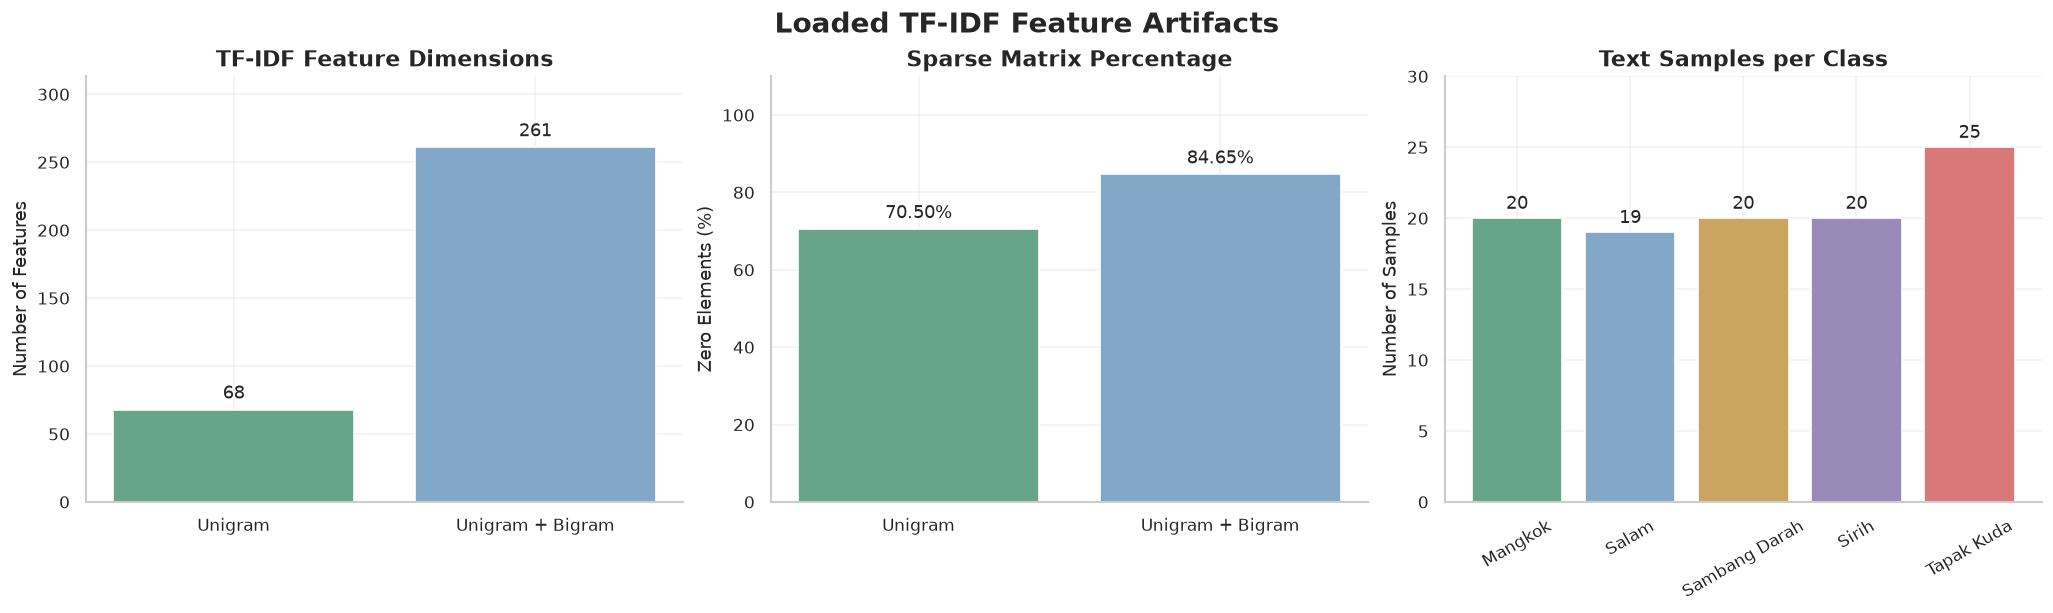

[SAVED] 106_loaded_text_feature_summary.png


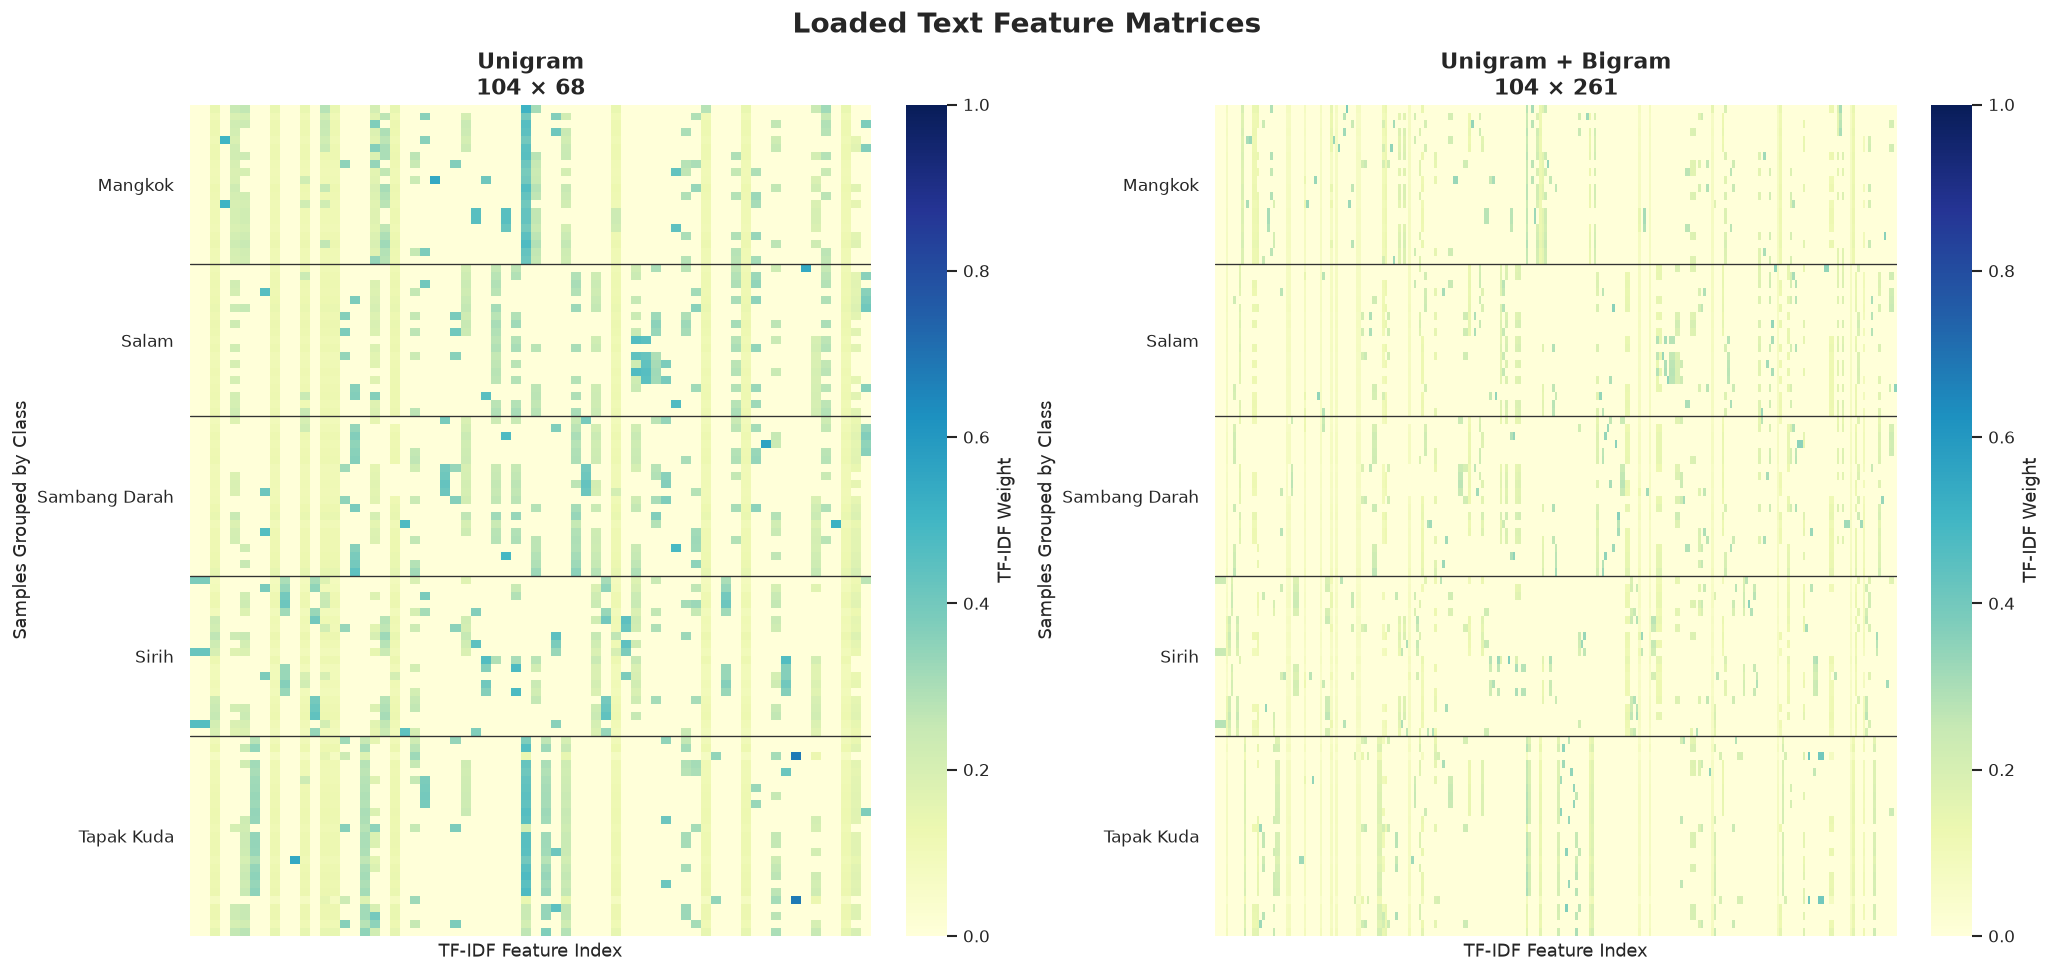

[SAVED] 107_loaded_text_feature_matrices.png

10. TEXT LOADING SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Total samples,104
1,Total classes,5
2,TF-IDF configurations,2
3,Unigram matrix shape,"(104, 68)"
4,Combined matrix shape,"(104, 261)"
5,Verified payload artifacts,16
6,Aligned samples,104
7,Validation checks,80
8,Passed checks,80
9,Failed checks,0



11. SAVING TEXT LOADING REPORTS
----------------------------------------------------------------------
[SAVED] 368_text_artifact_integrity.csv
[SAVED] 369_loaded_text_matrix_summary.csv
[SAVED] 370_text_vocabulary_integrity.csv
[SAVED] 371_text_visual_identity_alignment.csv
[SAVED] 372_text_loading_validation.csv
[SAVED] 373_loaded_text_class_distribution.csv
[SAVED] 374_text_loading_summary.csv

FINAL TEXT FEATURE LOADING SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Text samples      : 104
Visual samples    : 104
Aligned samples   : 104
Plant classes     : 5

TEXT FEATURE MATRICES
----------------------------------------------------------------------
Unigram features  : (104, 68)
Combined features : (104, 261)

ARTIFACT INFORMATION
----------------------------------------------------------------------
Verified payloads : 16/16
Loaded vectorizers: 2

VALIDATION
----------------------------------------------------------------------

In [6]:
# ============================================================
# CELL 5 - LOAD TEXT FEATURE ARTIFACTS
# ============================================================

from sklearn.feature_extraction.text import TfidfVectorizer

print("MULTIMODAL FUSION - LOAD TEXT FEATURE ARTIFACTS")
print("=" * 70)

TEXT_FEATURE_LOADING_COMPLETED = False
TEXT_FEATURES_LOADED = False

# ============================================================
# 1. VALIDATE PREVIOUS CELLS
# ============================================================

assert FUSION_LIBRARIES_IMPORTED is True
assert FUSION_PATH_CONFIGURATION_COMPLETED is True
assert VISUAL_FEATURE_LOADING_COMPLETED is True, (
    "Run Cell 4 successfully before Cell 5."
)

assert fusion_path_validation_df["passed"].all()
assert visual_loading_validation_df["passed"].all()

TEXT_LOADING_TOLERANCE = 1e-10
TEXT_EXPECTED_SAMPLES = 104

TEXT_EXPECTED_DIMENSIONS = {
    "Unigram": 68,
    "Unigram + Bigram": 261
}

TEXT_CONFIGURATION_ORDER = [
    "Unigram",
    "Unigram + Bigram"
]

TEXT_CONFIGURATION_COLORS = {
    "Unigram": "#66A58A",
    "Unigram + Bigram": "#83A7C7"
}

text_loading_checks = []
text_loading_figures = []

def check_text_loading(category, name, condition):
    text_loading_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition)
    })

def sha256_text_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(65536), b""):
            digest.update(chunk)
    return digest.hexdigest()

def maximum_sparse_difference(a, b):
    assert a.shape == b.shape
    delta = (a - b).tocsr()
    delta.eliminate_zeros()
    return (
        float(np.max(np.abs(delta.data)))
        if delta.nnz else 0.0
    )

print("[PASS] Previous cells validated.")


# ============================================================
# 2. PREPARE EXPECTED ARTIFACT PATHS
# ============================================================

# Use only paths established in Cell 3.
# Never load files using unvalidated paths from CSV.

text_expected_payload_paths = {}

for config_name in TEXT_CONFIGURATION_ORDER:
    for artifact_name, path in TEXT_ARTIFACT_PATHS[
        config_name
    ].items():
        text_expected_payload_paths[path.name] = path

for artifact_name, path in TEXT_SHARED_ARTIFACT_PATHS.items():
    if artifact_name != "manifest":
        text_expected_payload_paths[path.name] = path

assert len(text_expected_payload_paths) == 16
assert TEXT_MANIFEST_PATH.is_file()

print("\n1. TEXT ARTIFACT LOCATIONS")
print("-" * 70)
print("Text feature directory:", TEXT_FEATURES_DIR)
print("Expected payload files :", len(text_expected_payload_paths))
print("Manifest              :", TEXT_MANIFEST_PATH.name)


# ============================================================
# 3. LOAD AND VALIDATE TEXT MANIFEST
# ============================================================

loaded_text_manifest_df = pd.read_csv(
    TEXT_MANIFEST_PATH,
    dtype={
        "filename": str,
        "relative_path": str,
        "sha256": str
    },
    keep_default_na=False
)

manifest_columns = {
    "filename",
    "relative_path",
    "size_bytes",
    "sha256"
}

assert manifest_columns.issubset(
    loaded_text_manifest_df.columns
)

assert loaded_text_manifest_df["filename"].is_unique

expected_filenames = set(text_expected_payload_paths)
manifest_filenames = set(
    loaded_text_manifest_df["filename"]
)

assert manifest_filenames == expected_filenames, (
    "Manifest content does not match the 16 "
    "expected text payload artifacts."
)

loaded_text_manifest_df["size_bytes"] = pd.to_numeric(
    loaded_text_manifest_df["size_bytes"],
    errors="raise"
)

text_manifest_index = loaded_text_manifest_df.set_index(
    "filename"
)

check_text_loading(
    "Manifest",
    "Manifest covers all expected text artifacts",
    manifest_filenames == expected_filenames
)

print("[PASS] Text artifact manifest loaded.")


# ============================================================
# 4. VERIFY FILE INTEGRITY BEFORE JOBLIB LOADING
# ============================================================

text_artifact_integrity_records = []

print("\n2. TEXT ARTIFACT INTEGRITY")
print("-" * 70)

for filename, path in text_expected_payload_paths.items():

    manifest_row = text_manifest_index.loc[filename]

    exists = path.is_file()

    actual_size = (
        path.stat().st_size if exists else 0
    )

    actual_sha256 = (
        sha256_text_file(path) if exists else ""
    )

    expected_size = int(manifest_row["size_bytes"])

    expected_sha256 = str(
        manifest_row["sha256"]
    ).strip().lower()

    expected_relative_path = path.relative_to(
        PROJECT_ROOT
    ).as_posix()

    relative_path_match = (
        str(manifest_row["relative_path"])
        == expected_relative_path
    )

    size_match = actual_size == expected_size

    checksum_match = (
        actual_sha256 == expected_sha256
    )

    passed = (
        exists
        and actual_size > 0
        and size_match
        and checksum_match
        and relative_path_match
    )

    text_artifact_integrity_records.append({
        "filename": filename,
        "exists": exists,
        "size_bytes": actual_size,
        "size_match": size_match,
        "checksum_match": checksum_match,
        "relative_path_match": relative_path_match,
        "passed": passed
    })

    check_text_loading(
        "Artifact Integrity",
        f"{filename} integrity",
        passed
    )

    print(
        f"[{'PASS' if passed else 'FAIL'}] {filename}"
    )

text_artifact_integrity_df = pd.DataFrame(
    text_artifact_integrity_records
)

text_artifact_integrity_df.to_csv(
    METRICS_DIR / "368_text_artifact_integrity.csv",
    index=False,
    encoding="utf-8-sig"
)

# IMPORTANT: Do not unpickle Joblib files
# if their integrity check fails.
assert text_artifact_integrity_df["passed"].all(), (
    "Artifact integrity verification failed."
)

print("[PASS] 16 text payload artifacts verified.")


# ============================================================
# 5. LOAD SHARED TEXT ARTIFACTS
# ============================================================

loaded_text_sample_ids = np.asarray(
    np.load(
        TEXT_SAMPLE_IDS_PATH,
        allow_pickle=False
    ),
    dtype=str
)

loaded_text_class_labels = np.asarray(
    np.load(
        TEXT_CLASS_LABELS_PATH,
        allow_pickle=False
    ),
    dtype=str
)

loaded_text_metadata_df = pd.read_csv(
    MULTIMODAL_METADATA_PATH,
    dtype={"sample_id": str},
    keep_default_na=False
)

with open(
    TEXT_CORPUS_PATH,
    "r",
    encoding="utf-8"
) as file:
    loaded_text_corpus_payload = json.load(file)

with open(
    TEXT_PREPROCESSING_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as file:
    loaded_text_preprocessing_config = json.load(file)

with open(
    TEXT_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as file:
    loaded_text_feature_config = json.load(file)

loaded_text_corpus = list(
    loaded_text_corpus_payload["descriptions"]
)

loaded_text_n_samples = len(
    loaded_text_sample_ids
)

print("\n3. SHARED TEXT ARTIFACTS")
print("-" * 70)

print("Sample IDs       :", loaded_text_sample_ids.shape)
print("Class labels     :", loaded_text_class_labels.shape)
print("Text corpus      :", len(loaded_text_corpus))
print("Metadata         :", loaded_text_metadata_df.shape)
print("Preprocessing    : Loaded")
print("Feature config   : Loaded")


# ============================================================
# 6. VALIDATE SAMPLE IDENTITIES AND METADATA
# ============================================================

assert loaded_text_n_samples == TEXT_EXPECTED_SAMPLES

assert len(loaded_text_class_labels) == (
    loaded_text_n_samples
)

assert len(loaded_text_corpus) == (
    loaded_text_n_samples
)

assert len(loaded_text_metadata_df) == (
    loaded_text_n_samples
)

assert len(np.unique(
    loaded_text_sample_ids
)) == loaded_text_n_samples

assert all(
    isinstance(doc, str) and doc.strip()
    for doc in loaded_text_corpus
)

assert loaded_text_corpus_payload[
    "sample_ids"
] == loaded_text_sample_ids.tolist()

assert loaded_text_corpus_payload[
    "number_of_documents"
] == loaded_text_n_samples

required_metadata_columns = {
    "sample_id",
    "kelas",
    "cleaned_description",
    "image_text_alignment_valid"
}

assert required_metadata_columns.issubset(
    loaded_text_metadata_df.columns
)

text_metadata_ids = (
    loaded_text_metadata_df["sample_id"]
    .to_numpy(dtype=str)
)

text_metadata_labels = (
    loaded_text_metadata_df["kelas"]
    .to_numpy(dtype=str)
)

text_metadata_corpus = (
    loaded_text_metadata_df["cleaned_description"]
    .astype(str)
    .tolist()
)

text_alignment_status = (
    loaded_text_metadata_df[
        "image_text_alignment_valid"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

text_identity_checks = {
    "Sample IDs unique":
        len(np.unique(loaded_text_sample_ids))
        == loaded_text_n_samples,

    "Metadata sample order preserved":
        np.array_equal(
            text_metadata_ids,
            loaded_text_sample_ids
        ),

    "Metadata labels preserved":
        np.array_equal(
            text_metadata_labels,
            loaded_text_class_labels
        ),

    "Metadata descriptions preserved":
        text_metadata_corpus == loaded_text_corpus,

    "Text corpus sample IDs preserved":
        loaded_text_corpus_payload["sample_ids"]
        == loaded_text_sample_ids.tolist(),

    "Previous image-text alignment preserved":
        text_alignment_status.all(),

    "Visual and text sample IDs identical":
        np.array_equal(
            loaded_text_sample_ids,
            visual_sample_ids
        ),

    "Visual and text class labels identical":
        np.array_equal(
            loaded_text_class_labels,
            visual_labels
        )
}

text_identity_alignment_df = pd.DataFrame({
    "row_index": np.arange(loaded_text_n_samples),
    "sample_id": loaded_text_sample_ids,
    "kelas": loaded_text_class_labels,
    "visual_id_match": (
        loaded_text_sample_ids == visual_sample_ids
    ),
    "visual_label_match": (
        loaded_text_class_labels == visual_labels
    ),
    "metadata_id_match": (
        loaded_text_sample_ids == text_metadata_ids
    ),
    "metadata_label_match": (
        loaded_text_class_labels == text_metadata_labels
    ),
    "corpus_match": np.asarray([
        a == b for a, b in zip(
            loaded_text_corpus,
            text_metadata_corpus
        )
    ]),
    "alignment_flag": text_alignment_status.to_numpy()
})

alignment_columns = [
    "visual_id_match",
    "visual_label_match",
    "metadata_id_match",
    "metadata_label_match",
    "corpus_match",
    "alignment_flag"
]

text_identity_alignment_df["passed"] = (
    text_identity_alignment_df[
        alignment_columns
    ].all(axis=1)
)

for name, passed in text_identity_checks.items():
    check_text_loading("Sample Alignment", name, passed)

check_text_loading(
    "Sample Alignment",
    "All 104 sample-level alignment records passed",
    text_identity_alignment_df["passed"].all()
)

assert all(text_identity_checks.values()), (
    "Text and visual sample identity mismatch."
)

print("\n4. TEXT-VISUAL SAMPLE ALIGNMENT")
print("-" * 70)

print(
    "Aligned samples:",
    int(text_identity_alignment_df["passed"].sum()),
    "/",
    loaded_text_n_samples
)

display(text_identity_alignment_df.head(8))


# ============================================================
# 7. LOAD TF-IDF MATRICES AND VECTORIZERS
# ============================================================

loaded_text_vectorizers = {}
loaded_text_feature_matrices = {}
loaded_text_feature_names = {}
loaded_text_idf_weights = {}
loaded_text_vocabulary_reports = {}

text_matrix_summary_records = []
text_vocabulary_validation_records = []

print("\n5. LOADING TF-IDF CONFIGURATIONS")
print("-" * 70)

for configuration_name in TEXT_CONFIGURATION_ORDER:

    artifact_paths = TEXT_ARTIFACT_PATHS[
        configuration_name
    ]

    vectorizer = joblib.load(
        artifact_paths["vectorizer"]
    )

    feature_matrix = load_npz(
        artifact_paths["matrix"]
    ).tocsr()

    feature_names = np.load(
        artifact_paths["feature_names"],
        allow_pickle=False
    )

    idf_weights = np.load(
        artifact_paths["idf_weights"],
        allow_pickle=False
    )

    vocabulary_df = pd.read_csv(
        artifact_paths["vocabulary"],
        dtype={"term": str},
        keep_default_na=False,
        float_precision="round_trip"
    )

    loaded_text_vectorizers[
        configuration_name
    ] = vectorizer

    loaded_text_feature_matrices[
        configuration_name
    ] = feature_matrix

    loaded_text_feature_names[
        configuration_name
    ] = feature_names

    loaded_text_idf_weights[
        configuration_name
    ] = idf_weights

    loaded_text_vocabulary_reports[
        configuration_name
    ] = vocabulary_df

    expected_dimension = (
        TEXT_EXPECTED_DIMENSIONS[configuration_name]
    )

    expected_ngram_range = (
        (1, 1)
        if configuration_name == "Unigram"
        else (1, 2)
    )

    # ----------------------------------------------
    # A. Verify matrix properties
    # ----------------------------------------------

    row_norms = np.sqrt(
        np.asarray(
            feature_matrix.multiply(
                feature_matrix
            ).sum(axis=1)
        ).ravel()
    )

    matrix_checks = {
        "Matrix shape":
            feature_matrix.shape
            == (
                TEXT_EXPECTED_SAMPLES,
                expected_dimension
            ),

        "CSR sparse format":
            issparse(feature_matrix)
            and feature_matrix.format == "csr",

        "Float64 dtype":
            feature_matrix.dtype == np.float64,

        "Finite matrix values":
            np.isfinite(
                feature_matrix.data
            ).all(),

        "Nonnegative TF-IDF weights":
            np.all(
                feature_matrix.data >= 0
            ),

        "No zero document vectors":
            np.all(
                row_norms > 0
            ),

        "Unit L2 row normalization":
            np.allclose(
                row_norms,
                1.0,
                atol=TEXT_LOADING_TOLERANCE,
                rtol=0
            )
    }

    # ----------------------------------------------
    # B. Verify vectorizer properties
    # ----------------------------------------------

    vectorizer_feature_names = (
        vectorizer.get_feature_names_out()
    )

    vectorizer_checks = {
        "TF-IDF vectorizer type":
            isinstance(
                vectorizer,
                TfidfVectorizer
            ),

        "Vectorizer fitted":
            hasattr(vectorizer, "vocabulary_")
            and hasattr(vectorizer, "idf_"),

        "N-gram configuration":
            vectorizer.ngram_range
            == expected_ngram_range,

        "Vectorizer uses L2":
            vectorizer.norm == "l2",

        "Vocabulary dimension":
            len(vectorizer.vocabulary_)
            == expected_dimension,

        "Saved feature names identical":
            np.array_equal(
                feature_names,
                vectorizer_feature_names
            ),

        "Saved IDF weights identical":
            np.array_equal(
                idf_weights,
                vectorizer.idf_
            ),

        "IDF values finite and positive":
            np.isfinite(idf_weights).all()
            and np.all(idf_weights > 0)
    }

    # ----------------------------------------------
    # C. Verify vocabulary report
    # ----------------------------------------------

    vocabulary_required_columns = {
        "feature_index",
        "term",
        "ngram_type",
        "document_frequency",
        "idf_weight"
    }

    assert vocabulary_required_columns.issubset(
        vocabulary_df.columns
    )

    report_indices = pd.to_numeric(
        vocabulary_df["feature_index"],
        errors="raise"
    ).to_numpy()

    actual_document_frequency = np.asarray(
        (feature_matrix != 0).sum(axis=0)
    ).ravel()

    vocabulary_checks = {
        "Vocabulary report length":
            len(vocabulary_df)
            == expected_dimension,

        "Feature indices sequential":
            np.array_equal(
                report_indices,
                np.arange(expected_dimension)
            ),

        "Vocabulary terms match":
            np.array_equal(
                vocabulary_df["term"]
                .to_numpy(dtype=str),
                vectorizer_feature_names
            ),

        "Vocabulary IDF matches":
            np.allclose(
                vocabulary_df["idf_weight"]
                .to_numpy(dtype=float),
                idf_weights,
                atol=TEXT_LOADING_TOLERANCE,
                rtol=0
            ),

        "Document frequency matches":
            np.array_equal(
                vocabulary_df["document_frequency"]
                .to_numpy(dtype=int),
                actual_document_frequency
            ),

        "Vocabulary index mapping matches":
            all(
                vectorizer.vocabulary_.get(
                    term
                ) == index
                for index, term in enumerate(
                    vectorizer_feature_names
                )
            )
    }

    # ----------------------------------------------
    # D. Reproduce reference matrix
    # ----------------------------------------------

    reproduced_matrix = (
        vectorizer.transform(
            loaded_text_corpus
        ).tocsr()
    )

    reproduction_difference = (
        maximum_sparse_difference(
            reproduced_matrix,
            feature_matrix
        )
    )

    check_text_loading(
        configuration_name,
        "Reference matrix reproduced by transform()",
        reproduction_difference
        <= TEXT_LOADING_TOLERANCE
    )

    for checks in [
        matrix_checks,
        vectorizer_checks,
        vocabulary_checks
    ]:
        for name, passed in checks.items():
            check_text_loading(
                configuration_name,
                name,
                passed
            )

    # ----------------------------------------------
    # E. Save matrix statistics
    # ----------------------------------------------

    total_elements = (
        feature_matrix.shape[0]
        * feature_matrix.shape[1]
    )

    nonzero_values = int(
        feature_matrix.count_nonzero()
    )

    unigram_features = int(sum(
        " " not in term
        for term in vectorizer_feature_names
    ))

    bigram_features = int(sum(
        " " in term
        for term in vectorizer_feature_names
    ))

    text_matrix_summary_records.append({
        "configuration": configuration_name,
        "samples": feature_matrix.shape[0],
        "feature_dimension": feature_matrix.shape[1],
        "unigram_features": unigram_features,
        "bigram_features": bigram_features,
        "nonzero_values": nonzero_values,
        "zero_values": (
            total_elements - nonzero_values
        ),
        "sparsity_percent": (
            100 * (1 - nonzero_values / total_elements)
        ),
        "minimum_l2_norm": float(
            row_norms.min()
        ),
        "maximum_l2_norm": float(
            row_norms.max()
        ),
        "reproduction_max_difference": (
            reproduction_difference
        ),
        "matrix_file_kib": (
            artifact_paths["matrix"].stat().st_size
            / 1024
        ),
        "vectorizer_file_kib": (
            artifact_paths["vectorizer"].stat().st_size
            / 1024
        )
    })

    text_vocabulary_validation_records.append({
        "configuration": configuration_name,
        "vocabulary_size": len(
            vectorizer.vocabulary_
        ),
        "feature_names_match": (
            vectorizer_checks[
                "Saved feature names identical"
            ]
        ),
        "idf_match": (
            vectorizer_checks[
                "Saved IDF weights identical"
            ]
        ),
        "document_frequency_match": (
            vocabulary_checks[
                "Document frequency matches"
            ]
        ),
        "reference_matrix_reproduced": (
            reproduction_difference
            <= TEXT_LOADING_TOLERANCE
        )
    })

    print(f"\nConfiguration: {configuration_name}")
    print("Matrix shape :", feature_matrix.shape)
    print("Nonzero      :", nonzero_values)
    print("Unigram      :", unigram_features)
    print("Bigram       :", bigram_features)
    print(
        "Reproduction difference:",
        f"{reproduction_difference:.3e}"
    )

text_loaded_matrix_summary_df = pd.DataFrame(
    text_matrix_summary_records
)

text_vocabulary_integrity_df = pd.DataFrame(
    text_vocabulary_validation_records
)

print("\n6. LOADED TEXT MATRIX SUMMARY")
print("-" * 70)

display(
    text_loaded_matrix_summary_df.round(6)
)


# ============================================================
# 8. CREATE MAIN TEXT FEATURE VARIABLES
# ============================================================

tfidf_unigram_vectorizer = (
    loaded_text_vectorizers["Unigram"]
)

tfidf_combined_vectorizer = (
    loaded_text_vectorizers["Unigram + Bigram"]
)

tfidf_unigram_features = (
    loaded_text_feature_matrices["Unigram"]
)

tfidf_combined_features = (
    loaded_text_feature_matrices["Unigram + Bigram"]
)

text_feature_matrices = (
    loaded_text_feature_matrices
)

text_vectorizers = (
    loaded_text_vectorizers
)

text_sample_ids = (
    loaded_text_sample_ids
)

text_labels = (
    loaded_text_class_labels
)

text_corpus = (
    loaded_text_corpus
)

text_n_samples = (
    len(text_sample_ids)
)

text_class_names = sorted(
    np.unique(text_labels)
)

print("\n7. MAIN TEXT FEATURE VARIABLES")
print("-" * 70)

print("Unigram features :", tfidf_unigram_features.shape)
print("Combined features:", tfidf_combined_features.shape)
print("Text sample IDs  :", text_sample_ids.shape)
print("Text labels      :", text_labels.shape)


# ============================================================
# 9. CLASS DISTRIBUTION
# ============================================================

text_loaded_class_summary_df = (
    pd.Series(text_labels, name="kelas")
    .value_counts()
    .sort_index()
    .rename_axis("kelas")
    .reset_index(name="number_of_samples")
)

text_loaded_class_summary_df["percentage"] = (
    100
    * text_loaded_class_summary_df["number_of_samples"]
    / text_n_samples
)

expected_class_counts = {
    "Mangkok": 20,
    "Salam": 19,
    "Sambang Darah": 20,
    "Sirih": 20,
    "Tapak Kuda": 25
}

actual_class_counts = dict(zip(
    text_loaded_class_summary_df["kelas"],
    text_loaded_class_summary_df["number_of_samples"]
))

check_text_loading(
    "Class Distribution",
    "Five-class distribution preserved",
    actual_class_counts == expected_class_counts
)

print("\n8. CLASS DISTRIBUTION")
print("-" * 70)

display(
    text_loaded_class_summary_df.round(4)
)


# ============================================================
# 10. FEATURE CONFIGURATION VALIDATION
# ============================================================

saved_configurations = loaded_text_feature_config.get(
    "configurations",
    {}
)

for configuration_name in TEXT_CONFIGURATION_ORDER:

    assert configuration_name in saved_configurations

    saved_info = saved_configurations[
        configuration_name
    ]

    loaded_matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    check_text_loading(
        "Saved Configuration",
        f"{configuration_name} feature dimension",
        int(saved_info["feature_dimension"])
        == loaded_matrix.shape[1]
    )

    check_text_loading(
        "Saved Configuration",
        f"{configuration_name} matrix shape",
        tuple(saved_info["matrix_shape"])
        == loaded_matrix.shape
    )

    check_text_loading(
        "Saved Configuration",
        f"{configuration_name} nonzero count",
        int(saved_info["nonzero_values"])
        == loaded_matrix.nnz
    )

check_text_loading(
    "Saved Configuration",
    "Sample count preserved",
    loaded_text_feature_config[
        "number_of_samples"
    ] == text_n_samples
)

check_text_loading(
    "Saved Configuration",
    "Reference-only evaluation requirement preserved",
    loaded_text_feature_config[
        "evaluation_requires_reference_only_refit"
    ] is True
)

check_text_loading(
    "Saved Configuration",
    "No final text configuration selected",
    loaded_text_feature_config[
        "final_text_configuration_selected"
    ] is False
)


# ============================================================
# 11. FINAL TEXT LOADING VALIDATION
# ============================================================

text_loading_validation_df = pd.DataFrame(
    text_loading_checks
)

text_loading_validation_df["status"] = np.where(
    text_loading_validation_df["passed"],
    "Passed",
    "Failed"
)

text_loading_total_checks = len(
    text_loading_validation_df
)

text_loading_passed_checks = int(
    text_loading_validation_df["passed"].sum()
)

text_loading_failed_checks = (
    text_loading_total_checks
    - text_loading_passed_checks
)

print("\n9. TEXT FEATURE LOADING VALIDATION")
print("-" * 70)

display(text_loading_validation_df)

assert text_loading_validation_df["passed"].all(), (
    text_loading_validation_df.loc[
        ~text_loading_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All text loading checks passed.")


# ============================================================
# 12. VISUALIZATION — TEXT FEATURE SUMMARY
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    constrained_layout=True
)

plot_df = (
    text_loaded_matrix_summary_df
    .set_index("configuration")
    .loc[TEXT_CONFIGURATION_ORDER]
)

colors = [
    TEXT_CONFIGURATION_COLORS[name]
    for name in TEXT_CONFIGURATION_ORDER
]

# A. Feature dimensions.

bars = axes[0].bar(
    TEXT_CONFIGURATION_ORDER,
    plot_df["feature_dimension"],
    color=colors
)

axes[0].bar_label(bars, padding=4)
axes[0].set_title("TF-IDF Feature Dimensions")
axes[0].set_ylabel("Number of Features")
axes[0].margins(y=0.2)

# B. Matrix sparsity.

bars = axes[1].bar(
    TEXT_CONFIGURATION_ORDER,
    plot_df["sparsity_percent"],
    color=colors
)

axes[1].bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

axes[1].set_ylim(0, 110)
axes[1].set_title("Sparse Matrix Percentage")
axes[1].set_ylabel("Zero Elements (%)")

# C. Class distribution.

class_colors = [
    CLASS_COLORS.get(name, "#83A7C7")
    for name in text_loaded_class_summary_df["kelas"]
]

bars = axes[2].bar(
    text_loaded_class_summary_df["kelas"],
    text_loaded_class_summary_df["number_of_samples"],
    color=class_colors
)

axes[2].bar_label(bars, padding=3)
axes[2].tick_params(axis="x", rotation=30)
axes[2].set_title("Text Samples per Class")
axes[2].set_ylabel("Number of Samples")
axes[2].margins(y=0.2)

fig.suptitle(
    "Loaded TF-IDF Feature Artifacts",
    fontsize=17,
    fontweight="bold"
)

figure_path = (
    FUSION_FIGURES_DIR
    / "106_loaded_text_feature_summary.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

text_loading_figures.append(figure_path)

plt.show()
plt.close(fig)

print(f"[SAVED] {figure_path.name}")


# ============================================================
# 13. VISUALIZATION — TF-IDF FEATURE MATRICES
# ============================================================

plot_order = np.argsort(
    text_labels,
    kind="stable"
)

sorted_labels = text_labels[plot_order]

class_boundaries = np.flatnonzero(
    sorted_labels[1:] != sorted_labels[:-1]
) + 1

class_starts = np.r_[0, class_boundaries]
class_ends = np.r_[
    class_boundaries,
    text_n_samples
]

class_centers = (
    class_starts + class_ends
) / 2

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 8),
    constrained_layout=True
)

for ax, configuration_name in zip(
    axes,
    TEXT_CONFIGURATION_ORDER
):

    matrix = loaded_text_feature_matrices[
        configuration_name
    ]

    # Dense conversion is for plotting only.
    # Stored matrices remain sparse CSR.
    plot_matrix = matrix[plot_order].toarray()

    sns.heatmap(
        plot_matrix,
        cmap="YlGnBu",
        vmin=0,
        vmax=1,
        xticklabels=False,
        yticklabels=False,
        cbar_kws={"label": "TF-IDF Weight"},
        ax=ax
    )

    for boundary in class_boundaries:
        ax.axhline(
            boundary,
            color="#333333",
            linewidth=0.8
        )

    ax.set_yticks(class_centers)

    ax.set_yticklabels(
        sorted_labels[class_starts],
        rotation=0
    )

    ax.set_title(
        f"{configuration_name}\n"
        f"{matrix.shape[0]} × {matrix.shape[1]}"
    )

    ax.set_xlabel("TF-IDF Feature Index")
    ax.set_ylabel("Samples Grouped by Class")

fig.suptitle(
    "Loaded Text Feature Matrices",
    fontsize=17,
    fontweight="bold"
)

figure_path = (
    FUSION_FIGURES_DIR
    / "107_loaded_text_feature_matrices.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

text_loading_figures.append(figure_path)

plt.show()
plt.close(fig)

print(f"[SAVED] {figure_path.name}")


# ============================================================
# 14. CREATE FINAL LOADING SUMMARY
# ============================================================

text_loading_summary_df = pd.DataFrame([
    ("Total samples", text_n_samples),
    ("Total classes", len(text_class_names)),
    ("TF-IDF configurations", len(text_vectorizers)),
    ("Unigram matrix shape", str(tfidf_unigram_features.shape)),
    ("Combined matrix shape", str(tfidf_combined_features.shape)),
    ("Verified payload artifacts", int(
        text_artifact_integrity_df["passed"].sum()
    )),
    ("Aligned samples", int(
        text_identity_alignment_df["passed"].sum()
    )),
    ("Validation checks", text_loading_total_checks),
    ("Passed checks", text_loading_passed_checks),
    ("Failed checks", text_loading_failed_checks),
    ("Generated figures", len(text_loading_figures)),
    ("Vectorizers refitted", False),
    ("Sample order modified", False),
    ("Text configuration selected", False),
    ("Independent evaluation completed", False),
    ("Ready for multimodal validation", True)
], columns=["Indicator", "Result"])

print("\n10. TEXT LOADING SUMMARY")
print("-" * 70)

display(text_loading_summary_df)


# ============================================================
# 15. SAVE CELL 5 REPORTS
# ============================================================

text_loading_reports = {
    "368_text_artifact_integrity.csv":
        text_artifact_integrity_df,

    "369_loaded_text_matrix_summary.csv":
        text_loaded_matrix_summary_df,

    "370_text_vocabulary_integrity.csv":
        text_vocabulary_integrity_df,

    "371_text_visual_identity_alignment.csv":
        text_identity_alignment_df,

    "372_text_loading_validation.csv":
        text_loading_validation_df,

    "373_loaded_text_class_distribution.csv":
        text_loaded_class_summary_df,

    "374_text_loading_summary.csv":
        text_loading_summary_df
}

print("\n11. SAVING TEXT LOADING REPORTS")
print("-" * 70)

for filename, dataframe in text_loading_reports.items():

    output_path = METRICS_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ============================================================
# 16. FINAL COMPLETION CHECKS
# ============================================================

assert text_artifact_integrity_df["passed"].all()
assert text_loading_validation_df["passed"].all()
assert text_identity_alignment_df["passed"].all()

assert tfidf_unigram_features.shape == (104, 68)
assert tfidf_combined_features.shape == (104, 261)

assert np.array_equal(
    text_sample_ids,
    visual_sample_ids
)

assert np.array_equal(
    text_labels,
    visual_labels
)

assert len(text_loading_figures) == 2

assert all(
    path.is_file() and path.stat().st_size > 0
    for path in text_loading_figures
)

assert all(
    (METRICS_DIR / filename).is_file()
    for filename in text_loading_reports
)

TEXT_FEATURE_LOADING_COMPLETED = True
TEXT_FEATURES_LOADED = True


# ============================================================
# 17. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("FINAL TEXT FEATURE LOADING SUMMARY")
print("=" * 70)

print("\nDATASET INFORMATION")
print("-" * 70)
print(f"Text samples      : {text_n_samples}")
print(f"Visual samples    : {len(visual_sample_ids)}")
print(f"Aligned samples   : {text_identity_alignment_df['passed'].sum()}")
print(f"Plant classes     : {len(text_class_names)}")

print("\nTEXT FEATURE MATRICES")
print("-" * 70)
print("Unigram features  :", tfidf_unigram_features.shape)
print("Combined features :", tfidf_combined_features.shape)

print("\nARTIFACT INFORMATION")
print("-" * 70)
print(
    "Verified payloads :",
    f"{text_artifact_integrity_df['passed'].sum()}/"
    f"{len(text_artifact_integrity_df)}"
)
print("Loaded vectorizers:", len(loaded_text_vectorizers))

print("\nVALIDATION")
print("-" * 70)
print(
    "Technical checks  :",
    f"{text_loading_passed_checks}/{text_loading_total_checks}"
)
print("Failed checks     :", text_loading_failed_checks)
print("Generated reports :", len(text_loading_reports))
print("Generated figures :", len(text_loading_figures))

print("\n[PASS] Both TF-IDF matrices loaded.")
print("[PASS] Both fitted vectorizers loaded.")
print("[PASS] Vocabulary and IDF preserved.")
print("[PASS] Original corpus reproduced.")
print("[PASS] Text and visual samples aligned.")
print("[PASS] Sparse CSR and L2 normalization validated.")
print("[PASS] Artifact integrity verified.")
print("[PASS] No vectorizers were refitted.")

print("\n" + "=" * 70)
print("TEXT FEATURE LOADING COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nNext cell: Cell 6 - Multimodal Dataset Validation")

MULTIMODAL FUSION - DATASET VALIDATION
[PASS] Previous processing stages validated.

1. VALIDATION CONFIGURATION
----------------------------------------------------------------------
Expected samples: 104
Expected classes: 5
Tolerance       : 1e-10

2. MULTIMODAL FEATURE MATRICES
----------------------------------------------------------------------


,modality,number_of_samples,feature_dimension,expected_dimension,matrix_format,dtype,nonzero_values,zero_vector_rows,minimum_row_norm,maximum_row_norm,nan_values,infinite_values,passed
0,Visual,104,143,143,Dense,float64,14872,0,1.001982,4.092747,0,0,True
1,Text - Unigram,104,68,68,CSR,float64,2086,0,1.000000,1.000000,0,0,True
2,Text - Unigram + Bigram,104,261,261,CSR,float64,4166,0,1.000000,1.000000,0,0,True



3. SAMPLE ID INVENTORY
----------------------------------------------------------------------


,source,total_ids,unique_ids,duplicates,empty_ids,invalid_ids,missing_ids,extra_ids,passed
0,Visual Matrix,104,104,0,0,0,0,0,True
1,Text Matrix,104,104,0,0,0,0,0,True
2,Visual Metadata,104,104,0,0,0,0,0,True
3,Text Metadata,104,104,0,0,0,0,0,True
4,Processed Metadata,104,104,0,0,0,0,0,True



4. SAMPLE-LEVEL ALIGNMENT
----------------------------------------------------------------------
Aligned samples : 104/104
Failed samples  : 0


,row_index,sample_id,kelas,alignment_status
0,0,leaf_165d2f32c7fda707,Mangkok,Aligned
1,1,leaf_8473270c3702f48b,Mangkok,Aligned
2,2,leaf_8f425d66b1e193b9,Mangkok,Aligned
3,3,leaf_0ebc8f4f3ee9c8d5,Mangkok,Aligned
4,4,leaf_b0c5f55e42499cae,Mangkok,Aligned
5,5,leaf_de9e3e4ed5d89dfc,Mangkok,Aligned
6,6,leaf_23b789945271fb92,Mangkok,Aligned
7,7,leaf_84de0dc731018607,Mangkok,Aligned
8,8,leaf_36d4f083fa652592,Mangkok,Aligned
9,9,leaf_c9d8d87fbc748d16,Mangkok,Aligned


... (7 outputs left out)

,sample_id,kelas,nama_file,tampilan_daun,multimodal_alignment_validated,manual_review_pending
0,leaf_165d2f32c7fda707,Mangkok,mangkok 10.jpeg,belakang,True,True
1,leaf_8473270c3702f48b,Mangkok,mangkok 11.png,belakang,True,False
2,leaf_8f425d66b1e193b9,Mangkok,mangkok 12.png,belakang,True,False
3,leaf_0ebc8f4f3ee9c8d5,Mangkok,mangkok 13.png,belakang,True,False
4,leaf_b0c5f55e42499cae,Mangkok,mangkok 14.png,belakang,True,False
5,leaf_de9e3e4ed5d89dfc,Mangkok,mangkok 15.png,belakang,True,False
6,leaf_23b789945271fb92,Mangkok,mangkok 6.jpeg,belakang,True,True
7,leaf_84de0dc731018607,Mangkok,mangkok 7.jpeg,belakang,True,True
8,leaf_36d4f083fa652592,Mangkok,mangkok 8.jpeg,belakang,True,True
9,leaf_c9d8d87fbc748d16,Mangkok,mangkok 9.jpeg,belakang,True,True



9. IMAGE PATH AVAILABILITY
----------------------------------------------------------------------
Resolvable image files: 104/104

10. MULTIMODAL DATASET VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Feature Matrices,Visual expected dimensions,True,Passed
1,Feature Matrices,Visual finite values,True,Passed
2,Feature Matrices,Visual float64 dtype,True,Passed
3,Feature Matrices,Text - Unigram expected dimensions,True,Passed
4,Feature Matrices,Text - Unigram finite values,True,Passed
5,Feature Matrices,Text - Unigram float64 dtype,True,Passed
6,Feature Matrices,Text - Unigram CSR format,True,Passed
7,Feature Matrices,Text - Unigram nonnegative weights,True,Passed
8,Feature Matrices,Text - Unigram unit L2 row norm,True,Passed
9,Feature Matrices,Text - Unigram nonzero document vectors,True,Passed


[PASS] All required multimodal checks passed.


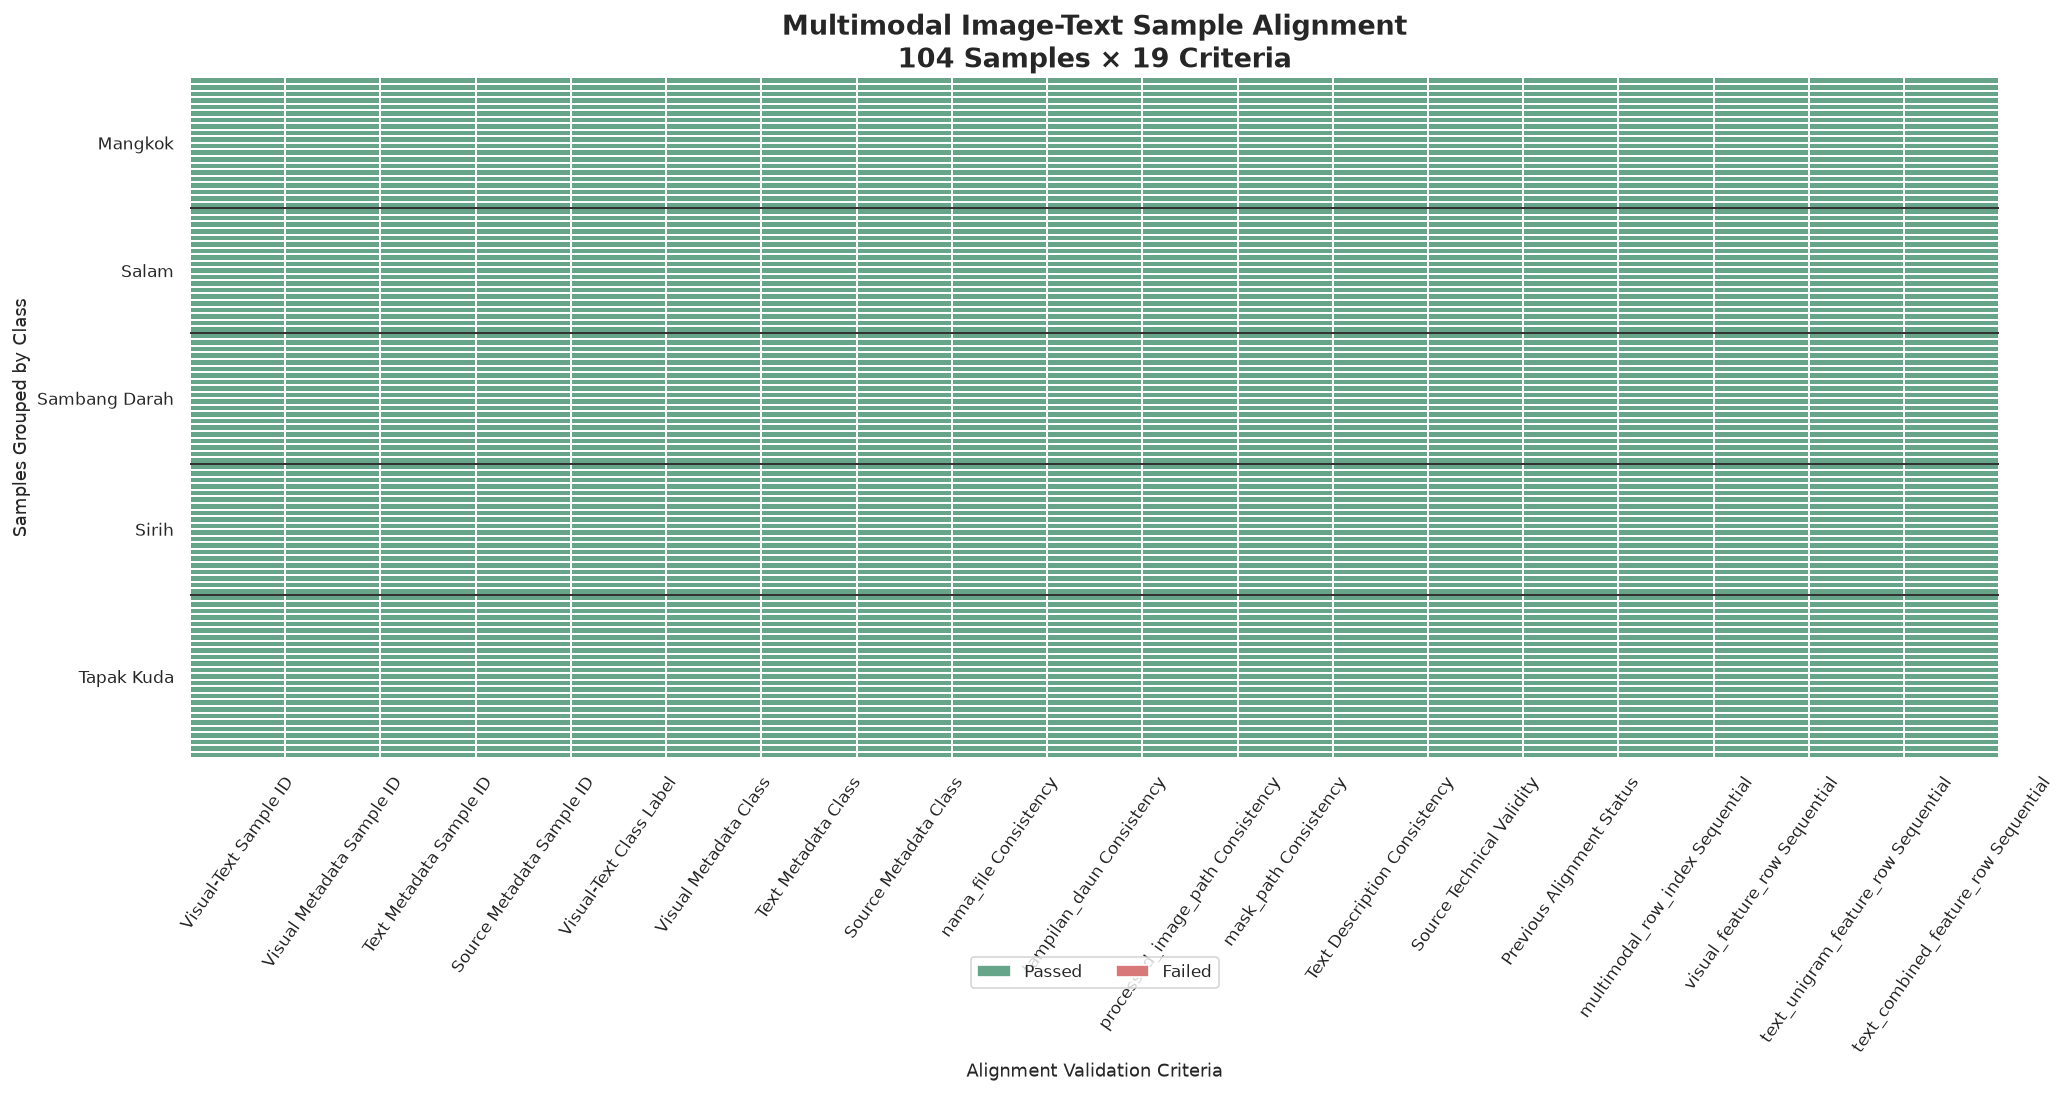

[SAVED] 108_multimodal_dataset_alignment_matrix.png


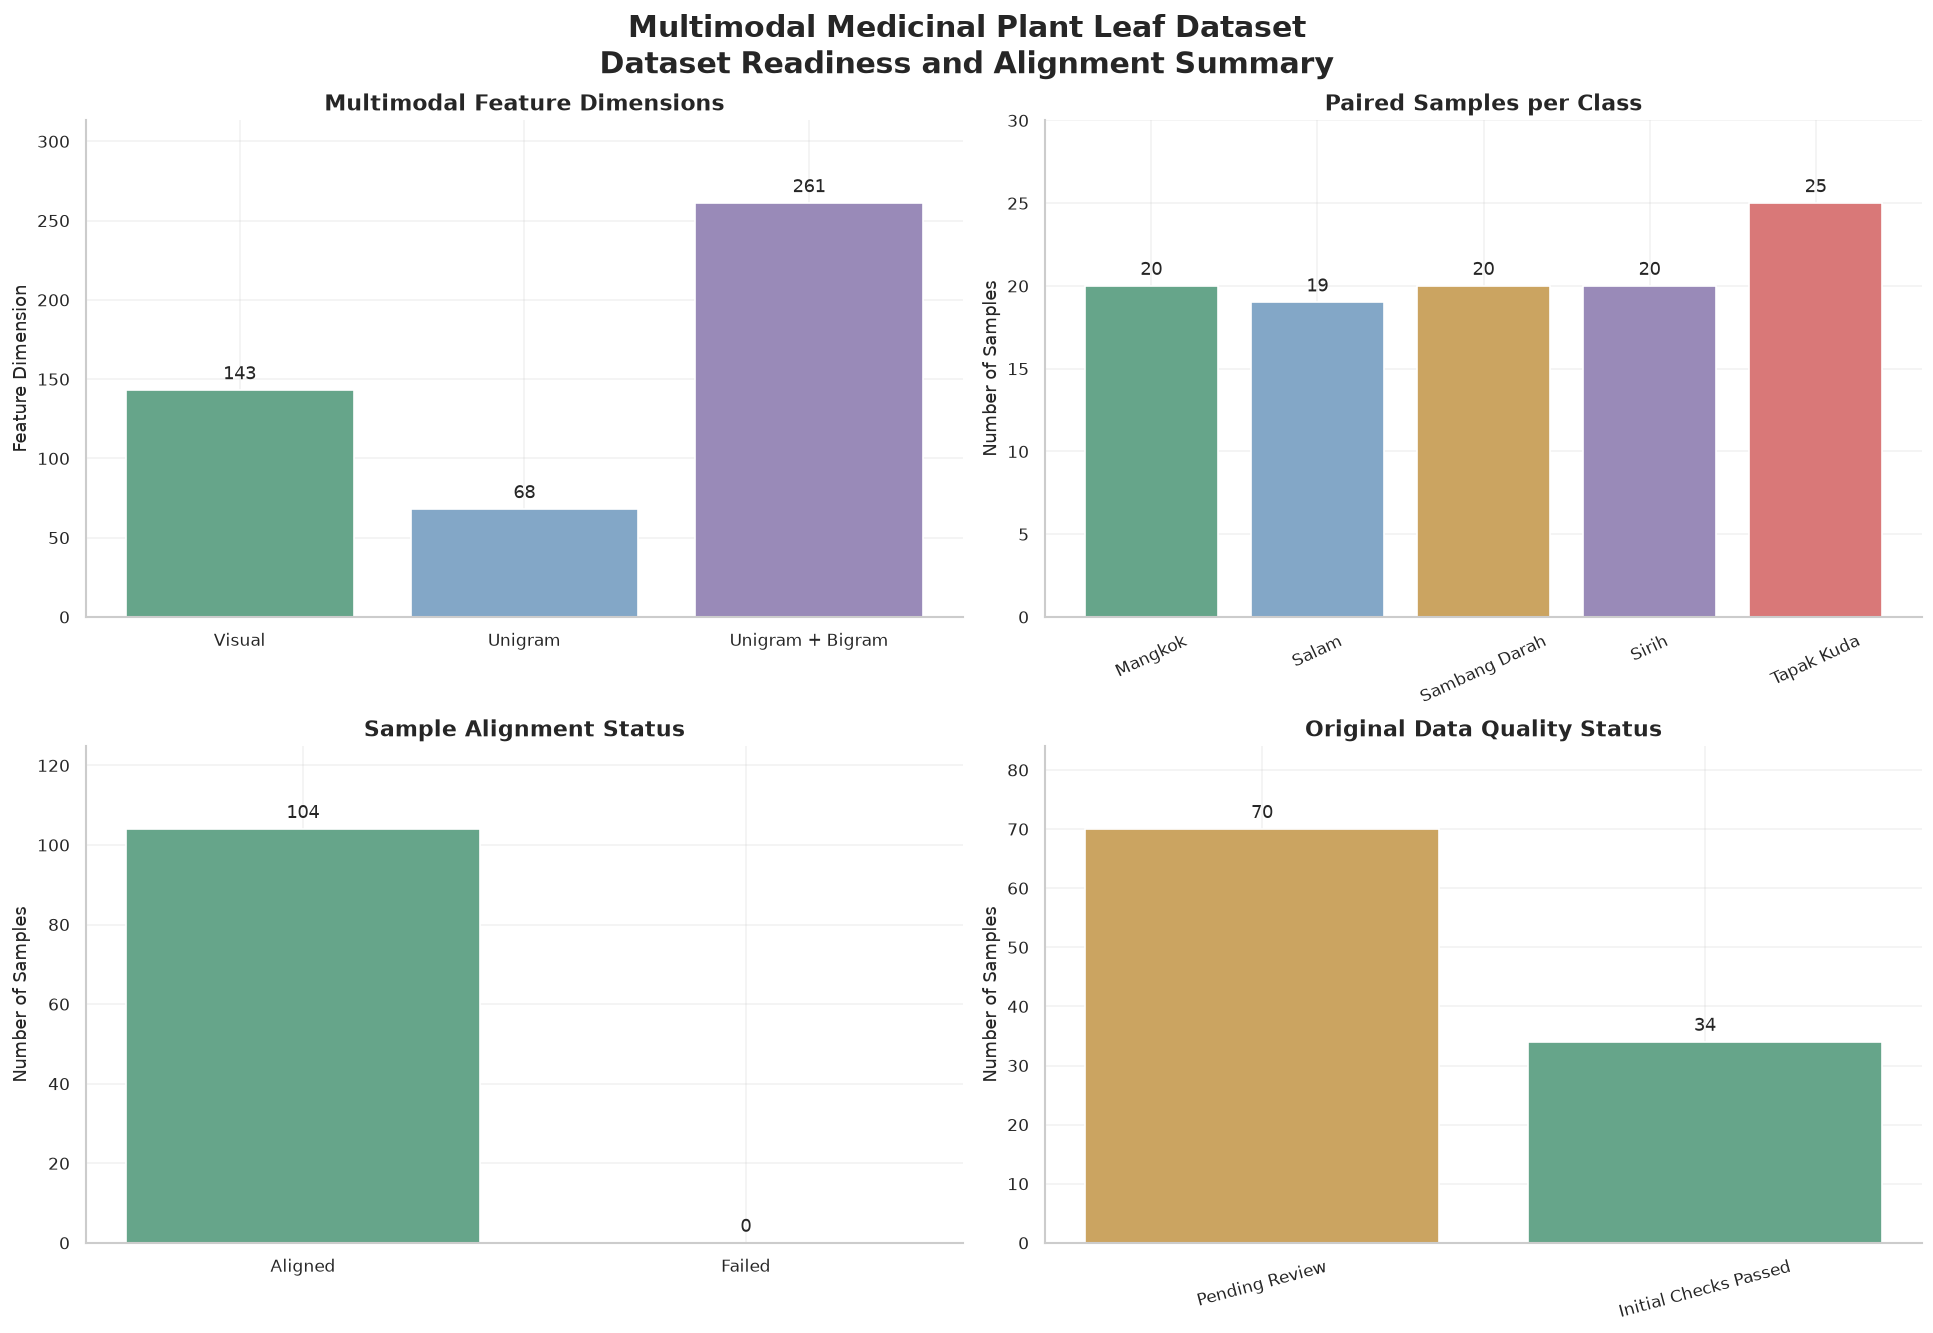

[SAVED] 109_multimodal_dataset_readiness_summary.png

11. FINAL MULTIMODAL DATASET SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Number of samples,104
1,Number of classes,5
2,Visual feature dimension,143
3,Unigram feature dimension,68
4,Combined feature dimension,261
5,Aligned samples,104
6,Failed alignment samples,0
7,Identity sources validated,5
8,Pending manual reviews,70
9,Exact duplicate text groups,8



12. SAVING VALIDATION REPORTS
----------------------------------------------------------------------
[SAVED] 375_multimodal_id_inventory.csv
[SAVED] 376_multimodal_sample_alignment.csv
[SAVED] 377_multimodal_feature_matrix_summary.csv
[SAVED] 378_multimodal_class_distribution.csv
[SAVED] 379_multimodal_quality_review_summary.csv
[SAVED] 380_multimodal_duplicate_descriptions.csv
[SAVED] 381_multimodal_dataset_validation.csv
[SAVED] 382_multimodal_dataset_summary.csv
[SAVED] 383_multimodal_image_path_diagnostics.csv
[SAVED] 384_multimodal_dataset_validation_handoff.json

FINAL MULTIMODAL DATASET VALIDATION SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Total samples      : 104
Total classes      : 5
Aligned samples    : 104
Failed alignment   : 0

FEATURE MATRICES
----------------------------------------------------------------------
Visual features    : (104, 143)
Unigram features   : (104, 68)
Combined features  : (104, 261)

QUALIT

In [7]:
# ============================================================
# CELL 6 - MULTIMODAL DATASET VALIDATION
# ============================================================

import json
import hashlib
from pathlib import Path
from collections import Counter
from scipy.sparse import issparse
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

print("MULTIMODAL FUSION - DATASET VALIDATION")
print("=" * 70)

MULTIMODAL_DATASET_VALIDATION_COMPLETED = False
MULTIMODAL_DATASET_READY = False


# ============================================================
# 1. VALIDATE PREVIOUS CELLS
# ============================================================

required_stages = {
    "FUSION_LIBRARIES_IMPORTED":
        FUSION_LIBRARIES_IMPORTED,

    "FUSION_PATH_CONFIGURATION_COMPLETED":
        FUSION_PATH_CONFIGURATION_COMPLETED,

    "VISUAL_FEATURE_LOADING_COMPLETED":
        VISUAL_FEATURE_LOADING_COMPLETED,

    "TEXT_FEATURE_LOADING_COMPLETED":
        TEXT_FEATURE_LOADING_COMPLETED
}

for stage_name, completed in required_stages.items():
    assert completed is True, (
        f"{stage_name} is not completed."
    )

assert visual_loading_validation_df["passed"].all()
assert text_loading_validation_df["passed"].all()

print("[PASS] Previous processing stages validated.")


# ============================================================
# 2. MULTIMODAL DATASET CONFIGURATION
# ============================================================

MULTIMODAL_EXPECTED_SAMPLES = 104

MULTIMODAL_EXPECTED_DIMENSIONS = {
    "Visual": 143,
    "Text - Unigram": 68,
    "Text - Unigram + Bigram": 261
}

MULTIMODAL_EXPECTED_CLASS_COUNTS = {
    "Mangkok": 20,
    "Salam": 19,
    "Sambang Darah": 20,
    "Sirih": 20,
    "Tapak Kuda": 25
}

MULTIMODAL_VALIDATION_TOLERANCE = 1e-10

MULTIMODAL_VALIDATION_SCOPE = (
    "Full-Gallery Multimodal Dataset"
)

multimodal_validation_records = []
multimodal_validation_figures = []


def register_multimodal_check(
    category,
    name,
    condition
):
    multimodal_validation_records.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition),
        "status": (
            "Passed" if condition else "Failed"
        )
    })


def save_multimodal_validation_figure(
    figure,
    filename
):
    path = FUSION_FIGURES_DIR / filename

    figure.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    multimodal_validation_figures.append(path)

    plt.show()
    plt.close(figure)

    print(f"[SAVED] {filename}")


print("\n1. VALIDATION CONFIGURATION")
print("-" * 70)

print("Expected samples:", MULTIMODAL_EXPECTED_SAMPLES)
print("Expected classes:", len(MULTIMODAL_EXPECTED_CLASS_COUNTS))
print("Tolerance       :", MULTIMODAL_VALIDATION_TOLERANCE)


# ============================================================
# 3. PREPARE MODALITY FEATURE REFERENCES
# ============================================================

# No feature extraction, refitting, or reordering.

multimodal_visual_features = visual_features

multimodal_text_features = {
    "Unigram": tfidf_unigram_features,
    "Unigram + Bigram": tfidf_combined_features
}

multimodal_sample_ids = np.asarray(
    visual_sample_ids,
    dtype=str
)

multimodal_labels = np.asarray(
    visual_labels,
    dtype=str
)

multimodal_n_samples = len(multimodal_sample_ids)

multimodal_class_names = sorted(
    np.unique(multimodal_labels)
)

# Retain both text configurations.

MULTIMODAL_TEXT_CONFIGURATION_ORDER = [
    "Unigram",
    "Unigram + Bigram"
]


# ============================================================
# 4. VALIDATE FEATURE MATRIX DIMENSIONS
# ============================================================

multimodal_feature_sources = {
    "Visual": multimodal_visual_features,
    "Text - Unigram":
        multimodal_text_features["Unigram"],
    "Text - Unigram + Bigram":
        multimodal_text_features["Unigram + Bigram"]
}

multimodal_matrix_records = []

for modality_name, matrix in (
    multimodal_feature_sources.items()
):

    sparse = issparse(matrix)

    matrix_values = (
        matrix.data if sparse else np.asarray(matrix)
    )

    expected_dimension = (
        MULTIMODAL_EXPECTED_DIMENSIONS[modality_name]
    )

    shape_valid = (
        matrix.shape
        == (
            MULTIMODAL_EXPECTED_SAMPLES,
            expected_dimension
        )
    )

    finite_valid = bool(
        np.isfinite(matrix_values).all()
    )

    dtype_valid = (
        matrix.dtype == np.float64
    )

    if sparse:
        nonzero_values = int(
            matrix.count_nonzero()
        )

        row_norms = np.sqrt(
            np.asarray(
                matrix.multiply(matrix).sum(axis=1)
            ).ravel()
        )

        matrix_format = matrix.format.upper()

    else:
        nonzero_values = int(
            np.count_nonzero(matrix)
        )

        row_norms = np.linalg.norm(
            matrix,
            axis=1
        )

        matrix_format = "Dense"

    zero_vector_count = int(
        np.sum(row_norms == 0)
    )

    register_multimodal_check(
        "Feature Matrices",
        f"{modality_name} expected dimensions",
        shape_valid
    )

    register_multimodal_check(
        "Feature Matrices",
        f"{modality_name} finite values",
        finite_valid
    )

    register_multimodal_check(
        "Feature Matrices",
        f"{modality_name} float64 dtype",
        dtype_valid
    )

    if sparse:

        register_multimodal_check(
            "Feature Matrices",
            f"{modality_name} CSR format",
            matrix.format == "csr"
        )

        register_multimodal_check(
            "Feature Matrices",
            f"{modality_name} nonnegative weights",
            np.all(matrix.data >= 0)
        )

        register_multimodal_check(
            "Feature Matrices",
            f"{modality_name} unit L2 row norm",
            np.allclose(
                row_norms,
                1.0,
                atol=MULTIMODAL_VALIDATION_TOLERANCE,
                rtol=0
            )
        )

        register_multimodal_check(
            "Feature Matrices",
            f"{modality_name} nonzero document vectors",
            zero_vector_count == 0
        )

    multimodal_matrix_records.append({
        "modality": modality_name,
        "number_of_samples": matrix.shape[0],
        "feature_dimension": matrix.shape[1],
        "expected_dimension": expected_dimension,
        "matrix_format": matrix_format,
        "dtype": str(matrix.dtype),
        "nonzero_values": nonzero_values,
        "zero_vector_rows": zero_vector_count,
        "minimum_row_norm": float(row_norms.min()),
        "maximum_row_norm": float(row_norms.max()),
        "nan_values": int(
            np.isnan(matrix_values).sum()
        ),
        "infinite_values": int(
            np.isinf(matrix_values).sum()
        ),
        "passed": bool(
            shape_valid and finite_valid and dtype_valid
        )
    })

multimodal_feature_matrix_summary_df = pd.DataFrame(
    multimodal_matrix_records
)

print("\n2. MULTIMODAL FEATURE MATRICES")
print("-" * 70)

display(
    multimodal_feature_matrix_summary_df.round(6)
)

assert multimodal_feature_matrix_summary_df[
    "passed"
].all()


# ============================================================
# 5. VALIDATE SAMPLE ID INVENTORY
# ============================================================

multimodal_id_sources = {
    "Visual Matrix":
        np.asarray(visual_sample_ids, dtype=str),

    "Text Matrix":
        np.asarray(text_sample_ids, dtype=str),

    "Visual Metadata":
        loaded_visual_metadata_df[
            "sample_id"
        ].to_numpy(dtype=str),

    "Text Metadata":
        loaded_text_metadata_df[
            "sample_id"
        ].to_numpy(dtype=str),

    "Processed Metadata":
        loaded_processed_metadata_df[
            "sample_id"
        ].to_numpy(dtype=str)
}

multimodal_id_inventory_records = []

reference_id_set = set(multimodal_sample_ids)

for source_name, ids in multimodal_id_sources.items():

    unique_count = len(np.unique(ids))

    duplicate_count = len(ids) - unique_count

    empty_count = int(
        (np.char.strip(ids) == "").sum()
    )

    invalid_count = int(
        np.isin(
            np.char.lower(np.char.strip(ids)),
            ["nan", "none", "null"]
        ).sum()
    )

    missing_ids = reference_id_set - set(ids)
    extra_ids = set(ids) - reference_id_set

    passed = (
        len(ids) == MULTIMODAL_EXPECTED_SAMPLES
        and duplicate_count == 0
        and empty_count == 0
        and invalid_count == 0
        and not missing_ids
        and not extra_ids
    )

    multimodal_id_inventory_records.append({
        "source": source_name,
        "total_ids": len(ids),
        "unique_ids": unique_count,
        "duplicates": duplicate_count,
        "empty_ids": empty_count,
        "invalid_ids": invalid_count,
        "missing_ids": len(missing_ids),
        "extra_ids": len(extra_ids),
        "passed": passed
    })

    register_multimodal_check(
        "Sample Identity",
        f"{source_name} identity coverage",
        passed
    )

multimodal_id_inventory_df = pd.DataFrame(
    multimodal_id_inventory_records
)

print("\n3. SAMPLE ID INVENTORY")
print("-" * 70)

display(multimodal_id_inventory_df)

assert multimodal_id_inventory_df["passed"].all(), (
    "Missing or duplicate IDs detected."
)


# ============================================================
# 6. ALIGN METADATA TO VISUAL MATRIX ORDER
# ============================================================

# Only metadata DataFrames are indexed.
# Feature matrices are not reordered.

multimodal_source_metadata_df = (
    loaded_processed_metadata_df
    .set_index("sample_id")
    .loc[multimodal_sample_ids]
    .reset_index()
)

multimodal_visual_metadata_df = (
    loaded_visual_metadata_df
    .reset_index(drop=True)
)

multimodal_text_metadata_df = (
    loaded_text_metadata_df
    .reset_index(drop=True)
)

assert len(multimodal_source_metadata_df) == (
    multimodal_n_samples
)

assert len(multimodal_visual_metadata_df) == (
    multimodal_n_samples
)

assert len(multimodal_text_metadata_df) == (
    multimodal_n_samples
)


# ============================================================
# 7. COMPARE SAMPLE ORDER AND CLASS LABELS
# ============================================================

multimodal_sample_alignment_df = pd.DataFrame({
    "row_index": np.arange(multimodal_n_samples),
    "sample_id": multimodal_sample_ids,
    "kelas": multimodal_labels
})

alignment_conditions = {}

alignment_conditions["Visual-Text Sample ID"] = (
    multimodal_sample_ids
    == np.asarray(text_sample_ids, dtype=str)
)

alignment_conditions["Visual Metadata Sample ID"] = (
    multimodal_sample_ids
    == multimodal_visual_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str)
)

alignment_conditions["Text Metadata Sample ID"] = (
    multimodal_sample_ids
    == multimodal_text_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str)
)

alignment_conditions["Source Metadata Sample ID"] = (
    multimodal_sample_ids
    == multimodal_source_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str)
)

alignment_conditions["Visual-Text Class Label"] = (
    multimodal_labels
    == np.asarray(text_labels, dtype=str)
)

alignment_conditions["Visual Metadata Class"] = (
    multimodal_labels
    == multimodal_visual_metadata_df[
        "kelas"
    ].to_numpy(dtype=str)
)

alignment_conditions["Text Metadata Class"] = (
    multimodal_labels
    == multimodal_text_metadata_df[
        "kelas"
    ].to_numpy(dtype=str)
)

alignment_conditions["Source Metadata Class"] = (
    multimodal_labels
    == multimodal_source_metadata_df[
        "kelas"
    ].to_numpy(dtype=str)
)


# ============================================================
# 8. VERIFY SHARED IMAGE-TEXT METADATA
# ============================================================

# Filename and leaf view are important identity checks.

for column in ["nama_file", "tampilan_daun"]:

    assert all(
        column in df.columns
        for df in [
            multimodal_source_metadata_df,
            multimodal_visual_metadata_df,
            multimodal_text_metadata_df
        ]
    ), f"Missing essential metadata column: {column}"

    source_values = (
        multimodal_source_metadata_df[
            column
        ].astype(str).to_numpy()
    )

    visual_values = (
        multimodal_visual_metadata_df[
            column
        ].astype(str).to_numpy()
    )

    text_values = (
        multimodal_text_metadata_df[
            column
        ].astype(str).to_numpy()
    )

    alignment_conditions[
        f"{column} Consistency"
    ] = (
        (source_values == visual_values)
        & (source_values == text_values)
    )

# Check paths only when all three metadata sources
# contain the corresponding column.

for column in [
    "processed_image_path",
    "mask_path"
]:

    if all(
        column in df.columns
        for df in [
            multimodal_source_metadata_df,
            multimodal_visual_metadata_df,
            multimodal_text_metadata_df
        ]
    ):

        source_values = (
            multimodal_source_metadata_df[
                column
            ].astype(str).to_numpy()
        )

        visual_values = (
            multimodal_visual_metadata_df[
                column
            ].astype(str).to_numpy()
        )

        text_values = (
            multimodal_text_metadata_df[
                column
            ].astype(str).to_numpy()
        )

        alignment_conditions[
            f"{column} Consistency"
        ] = (
            (source_values == visual_values)
            & (source_values == text_values)
        )


# ============================================================
# 9. VALIDATE CORPUS AND STORED ALIGNMENT FLAGS
# ============================================================

source_descriptions = (
    multimodal_source_metadata_df[
        "cleaned_description"
    ].astype(str).to_numpy()
)

text_descriptions = (
    multimodal_text_metadata_df[
        "cleaned_description"
    ].astype(str).to_numpy()
)

corpus_descriptions = np.asarray(
    text_corpus,
    dtype=str
)

alignment_conditions["Text Description Consistency"] = (
    (source_descriptions == text_descriptions)
    & (source_descriptions == corpus_descriptions)
)

source_valid_flags = (
    multimodal_source_metadata_df[
        "multimodal_valid"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
    .to_numpy()
)

previous_alignment_flags = (
    multimodal_text_metadata_df[
        "image_text_alignment_valid"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
    .to_numpy()
)

alignment_conditions["Source Technical Validity"] = (
    source_valid_flags
)

alignment_conditions["Previous Alignment Status"] = (
    previous_alignment_flags
)

# Validate stored feature-row indices if available.

expected_row_indices = np.arange(
    multimodal_n_samples
)

for column in [
    "multimodal_row_index",
    "visual_feature_row",
    "text_unigram_feature_row",
    "text_combined_feature_row"
]:

    if column in multimodal_text_metadata_df.columns:

        stored_indices = pd.to_numeric(
            multimodal_text_metadata_df[column],
            errors="coerce"
        ).to_numpy()

        alignment_conditions[
            f"{column} Sequential"
        ] = (
            stored_indices == expected_row_indices
        )


# ============================================================
# 10. CONSOLIDATE SAMPLE-LEVEL CHECKS
# ============================================================

for check_name, conditions in (
    alignment_conditions.items()
):

    multimodal_sample_alignment_df[
        check_name
    ] = conditions

    register_multimodal_check(
        "Sample-Level Alignment",
        check_name,
        np.all(conditions)
    )

sample_check_columns = list(
    alignment_conditions.keys()
)

multimodal_sample_alignment_df[
    "alignment_passed"
] = (
    multimodal_sample_alignment_df[
        sample_check_columns
    ].all(axis=1)
)

multimodal_sample_alignment_df[
    "alignment_status"
] = np.where(
    multimodal_sample_alignment_df[
        "alignment_passed"
    ],
    "Aligned",
    "Alignment Failed"
)

aligned_sample_count = int(
    multimodal_sample_alignment_df[
        "alignment_passed"
    ].sum()
)

failed_sample_count = (
    multimodal_n_samples - aligned_sample_count
)

register_multimodal_check(
    "Overall Alignment",
    "All samples correctly aligned",
    failed_sample_count == 0
)

print("\n4. SAMPLE-LEVEL ALIGNMENT")
print("-" * 70)

print(
    f"Aligned samples : {aligned_sample_count}/"
    f"{multimodal_n_samples}"
)

print("Failed samples  :", failed_sample_count)

display(
    multimodal_sample_alignment_df[[
        "row_index",
        "sample_id",
        "kelas",
        "alignment_status"
    ]].head(10)
)


# ============================================================
# 11. VERIFY VISUAL FEATURE GROUP STRUCTURE
# ============================================================

raw_reconstructed = np.hstack([
    loaded_hsv_features,
    loaded_glcm_features,
    loaded_hu_features
])

visual_reconstruction_difference = float(
    np.max(
        np.abs(
            raw_reconstructed
            - loaded_visual_raw_features
        )
    )
)

register_multimodal_check(
    "Visual Representation",
    "HSV-GLCM-Hu concatenation preserved",
    visual_reconstruction_difference
    <= MULTIMODAL_VALIDATION_TOLERANCE
)

register_multimodal_check(
    "Visual Representation",
    "Normalized visual matrix preserved",
    np.array_equal(
        multimodal_visual_features,
        loaded_visual_normalized_features
    )
)

register_multimodal_check(
    "Visual Representation",
    "Visual feature dimension is 143",
    multimodal_visual_features.shape[1] == 143
)


# ============================================================
# 12. VERIFY TEXT FEATURE CONSISTENCY
# ============================================================

for configuration_name in MULTIMODAL_TEXT_CONFIGURATION_ORDER:

    vectorizer = text_vectorizers[
        configuration_name
    ]

    matrix = multimodal_text_features[
        configuration_name
    ]

    reproduced_matrix = vectorizer.transform(
        text_corpus
    ).tocsr()

    difference = (
        reproduced_matrix - matrix
    ).tocsr()

    difference.eliminate_zeros()

    max_difference = (
        float(np.max(np.abs(difference.data)))
        if difference.nnz
        else 0.0
    )

    register_multimodal_check(
        "Text Representation",
        f"{configuration_name} reference features reproduced",
        max_difference
        <= MULTIMODAL_VALIDATION_TOLERANCE
    )

    register_multimodal_check(
        "Text Representation",
        f"{configuration_name} vocabulary dimension",
        len(vectorizer.get_feature_names_out())
        == matrix.shape[1]
    )


# ============================================================
# 13. VALIDATE CLASS DISTRIBUTION
# ============================================================

multimodal_class_summary_df = (
    pd.Series(
        multimodal_labels,
        name="kelas"
    )
    .value_counts()
    .sort_index()
    .rename_axis("kelas")
    .reset_index(name="number_of_samples")
)

multimodal_class_summary_df[
    "percentage"
] = (
    multimodal_class_summary_df[
        "number_of_samples"
    ]
    / multimodal_n_samples
    * 100
)

multimodal_class_summary_df[
    "aligned_samples"
] = [
    int(
        multimodal_sample_alignment_df.loc[
            multimodal_sample_alignment_df[
                "kelas"
            ].eq(class_name),
            "alignment_passed"
        ].sum()
    )
    for class_name in multimodal_class_summary_df[
        "kelas"
    ]
]

multimodal_class_summary_df[
    "alignment_success_percent"
] = (
    multimodal_class_summary_df[
        "aligned_samples"
    ]
    / multimodal_class_summary_df[
        "number_of_samples"
    ]
    * 100
)

actual_class_counts = dict(zip(
    multimodal_class_summary_df["kelas"],
    multimodal_class_summary_df["number_of_samples"]
))

register_multimodal_check(
    "Class Distribution",
    "Five expected plant classes preserved",
    actual_class_counts
    == MULTIMODAL_EXPECTED_CLASS_COUNTS
)

register_multimodal_check(
    "Class Distribution",
    "Class distribution reconciles with dataset",
    multimodal_class_summary_df[
        "number_of_samples"
    ].sum() == multimodal_n_samples
)

print("\n5. MULTIMODAL CLASS DISTRIBUTION")
print("-" * 70)

display(
    multimodal_class_summary_df.round(4)
)


# ============================================================
# 14. PRESERVE ORIGINAL DATA QUALITY STATUS
# ============================================================

multimodal_quality_metadata_df = (
    multimodal_source_metadata_df[[
        "sample_id",
        "kelas",
        "final_dataset_status",
        "multimodal_valid"
    ]]
    .copy()
)

multimodal_quality_metadata_df[
    "manual_review_pending"
] = (
    multimodal_quality_metadata_df[
        "final_dataset_status"
    ]
    .astype(str)
    .str.contains(
        "pending review",
        case=False,
        regex=False
    )
)

multimodal_quality_review_summary_df = (
    multimodal_quality_metadata_df[
        "final_dataset_status"
    ]
    .value_counts(dropna=False)
    .rename_axis("dataset_status")
    .reset_index(name="number_of_samples")
)

multimodal_quality_review_summary_df[
    "percentage"
] = (
    multimodal_quality_review_summary_df[
        "number_of_samples"
    ]
    / multimodal_n_samples
    * 100
)

manual_review_count = int(
    multimodal_quality_metadata_df[
        "manual_review_pending"
    ].sum()
)

register_multimodal_check(
    "Quality Status",
    "Original review status preserved",
    (
        multimodal_quality_review_summary_df[
            "number_of_samples"
        ].sum()
        == multimodal_n_samples
    )
)

print("\n6. ORIGINAL DATA QUALITY STATUS")
print("-" * 70)

display(
    multimodal_quality_review_summary_df.round(4)
)

print(
    f"[INFO] Pending manual review: "
    f"{manual_review_count} samples"
)


# ============================================================
# 15. DOCUMENT DUPLICATE TEXT DESCRIPTIONS
# ============================================================

# Duplicate descriptions are reported as quality
# diagnostics, not automatically removed.

duplicate_description_records = []

description_groups = (
    multimodal_text_metadata_df
    .groupby("cleaned_description", sort=False)
)

for description, group in description_groups:

    if len(group) < 2:
        continue

    class_counts = Counter(
        group["kelas"].astype(str)
    )

    all_pairs = len(group) * (len(group) - 1) // 2

    within_pairs = sum(
        count * (count - 1) // 2
        for count in class_counts.values()
    )

    cross_pairs = all_pairs - within_pairs

    duplicate_description_records.append({
        "description_sha256": hashlib.sha256(
            str(description).encode("utf-8")
        ).hexdigest(),
        "number_of_samples": len(group),
        "sample_ids": ", ".join(
            group["sample_id"].astype(str)
        ),
        "classes": ", ".join(
            sorted(group["kelas"].astype(str).unique())
        ),
        "within_class_duplicate_pairs": within_pairs,
        "cross_class_duplicate_pairs": cross_pairs
    })

multimodal_duplicate_descriptions_df = pd.DataFrame(
    duplicate_description_records,
    columns=[
        "description_sha256",
        "number_of_samples",
        "sample_ids",
        "classes",
        "within_class_duplicate_pairs",
        "cross_class_duplicate_pairs"
    ]
)

duplicate_pair_count = int(
    multimodal_duplicate_descriptions_df[
        "within_class_duplicate_pairs"
    ].sum()
    +
    multimodal_duplicate_descriptions_df[
        "cross_class_duplicate_pairs"
    ].sum()
)

print("\n7. DUPLICATE TEXT DIAGNOSTICS")
print("-" * 70)

print(
    "Exact duplicate description groups:",
    len(multimodal_duplicate_descriptions_df)
)

print(
    "Exact duplicate description pairs :",
    duplicate_pair_count
)

display(
    multimodal_duplicate_descriptions_df.head(10)
)

print(
    "[INFO] Duplicate descriptions remain available "
    "for exploratory retrieval."
)


# ============================================================
# 16. CREATE ALIGNED MULTIMODAL DATASET METADATA
# ============================================================

multimodal_metadata_df = (
    multimodal_text_metadata_df.copy()
)

multimodal_metadata_df[
    "multimodal_alignment_validated"
] = (
    multimodal_sample_alignment_df[
        "alignment_passed"
    ].to_numpy()
)

multimodal_metadata_df[
    "multimodal_validation_row"
] = np.arange(multimodal_n_samples)

multimodal_metadata_df[
    "manual_review_pending"
] = (
    multimodal_quality_metadata_df[
        "manual_review_pending"
    ].to_numpy()
)

assert np.array_equal(
    multimodal_metadata_df[
        "sample_id"
    ].to_numpy(dtype=str),
    multimodal_sample_ids
)

# This signature identifies the exact row order.
# It will be useful when loading fusion artifacts.

multimodal_alignment_signature = hashlib.sha256(
    json.dumps(
        [
            [sample_id, label]
            for sample_id, label in zip(
                multimodal_sample_ids.tolist(),
                multimodal_labels.tolist()
            )
        ],
        ensure_ascii=False,
        separators=(",", ":")
    ).encode("utf-8")
).hexdigest()

print("\n8. MULTIMODAL METADATA")
print("-" * 70)

print("Metadata shape:", multimodal_metadata_df.shape)

print(
    "Alignment signature:",
    multimodal_alignment_signature
)

display(
    multimodal_metadata_df[[
        "sample_id",
        "kelas",
        "nama_file",
        "tampilan_daun",
        "multimodal_alignment_validated",
        "manual_review_pending"
    ]].head(10)
)


# ============================================================
# 17. OPTIONAL IMAGE PATH AVAILABILITY DIAGNOSTIC
# ============================================================

# Saved feature matrices are sufficient for similarity.
# Image files will be useful in Cell 17 visualization.
# Missing image paths are reported without claiming that
# the feature matrices are invalid.

def resolve_multimodal_image_path(raw_path):

    if pd.isna(raw_path) or not str(raw_path).strip():
        return None

    raw = Path(str(raw_path))

    candidates = (
        [raw]
        if raw.is_absolute()
        else [
            PROJECT_ROOT / raw,
            PROCESSED_DIR / raw,
            DATASET_DIR / raw
        ]
    )

    return next(
        (
            candidate
            for candidate in candidates
            if candidate.is_file()
        ),
        None
    )


image_paths = (
    multimodal_metadata_df[
        "processed_image_path"
    ].tolist()
)

resolved_image_paths = [
    resolve_multimodal_image_path(path)
    for path in image_paths
]

multimodal_image_path_diagnostics_df = pd.DataFrame({
    "sample_id": multimodal_sample_ids,
    "stored_path": image_paths,
    "file_found": [
        path is not None
        for path in resolved_image_paths
    ]
})

image_files_found = int(
    multimodal_image_path_diagnostics_df[
        "file_found"
    ].sum()
)

print("\n9. IMAGE PATH AVAILABILITY")
print("-" * 70)

print(
    f"Resolvable image files: "
    f"{image_files_found}/{multimodal_n_samples}"
)

if image_files_found < multimodal_n_samples:
    print(
        "[WARNING] Some image paths could not be resolved. "
        "This does not invalidate loaded feature matrices, "
        "but may affect Cell 17 visualization."
    )


# ============================================================
# 18. FINAL TECHNICAL VALIDATION
# ============================================================

register_multimodal_check(
    "Overall Dataset",
    "Expected dataset sample count",
    multimodal_n_samples
    == MULTIMODAL_EXPECTED_SAMPLES
)

register_multimodal_check(
    "Overall Dataset",
    "Expected number of classes",
    len(multimodal_class_names) == 5
)

register_multimodal_check(
    "Overall Dataset",
    "All feature matrices have equal row count",
    all(
        matrix.shape[0] == multimodal_n_samples
        for matrix in multimodal_feature_sources.values()
    )
)

register_multimodal_check(
    "Overall Dataset",
    "No failed sample alignment",
    failed_sample_count == 0
)

register_multimodal_check(
    "Overall Dataset",
    "Text vectorizers remain fitted",
    all(
        hasattr(
            text_vectorizers[name],
            "vocabulary_"
        )
        for name in MULTIMODAL_TEXT_CONFIGURATION_ORDER
    )
)

multimodal_validation_df = pd.DataFrame(
    multimodal_validation_records
)

multimodal_validation_total_checks = len(
    multimodal_validation_df
)

multimodal_validation_passed_checks = int(
    multimodal_validation_df["passed"].sum()
)

multimodal_validation_failed_checks = (
    multimodal_validation_total_checks
    - multimodal_validation_passed_checks
)

print("\n10. MULTIMODAL DATASET VALIDATION")
print("-" * 70)

display(multimodal_validation_df)

# Save diagnostics before an assertion can stop execution.

multimodal_validation_df.to_csv(
    METRICS_DIR / "381_multimodal_dataset_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert multimodal_validation_df["passed"].all(), (
    multimodal_validation_df.loc[
        ~multimodal_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All required multimodal checks passed.")


# ============================================================
# 19. VISUALIZE SAMPLE-LEVEL ALIGNMENT
# ============================================================

plot_order = np.argsort(
    multimodal_labels,
    kind="stable"
)

plot_labels = multimodal_labels[plot_order]

alignment_plot_matrix = (
    multimodal_sample_alignment_df[
        sample_check_columns
    ]
    .to_numpy(dtype=int)
    [plot_order]
)

class_boundaries = np.flatnonzero(
    plot_labels[1:] != plot_labels[:-1]
) + 1

class_starts = np.r_[0, class_boundaries]
class_ends = np.r_[
    class_boundaries,
    multimodal_n_samples
]

class_centers = (
    class_starts + class_ends
) / 2

fig, ax = plt.subplots(
    figsize=(max(13, len(sample_check_columns) * 0.9), 9),
    constrained_layout=True
)

sns.heatmap(
    alignment_plot_matrix,
    cmap=ListedColormap([
        "#D97878",
        "#66A58A"
    ]),
    vmin=0,
    vmax=1,
    xticklabels=sample_check_columns,
    yticklabels=False,
    cbar=False,
    linewidths=0.2,
    linecolor="white",
    ax=ax
)

for boundary in class_boundaries:
    ax.axhline(
        boundary,
        color="#333333",
        linewidth=1.2
    )

ax.set_yticks(class_centers)
ax.set_yticklabels(
    plot_labels[class_starts],
    rotation=0
)

ax.tick_params(axis="x", labelrotation=55)

ax.set_xlabel("Alignment Validation Criteria")
ax.set_ylabel("Samples Grouped by Class")

ax.set_title(
    "Multimodal Image-Text Sample Alignment\n"
    f"{multimodal_n_samples} Samples × "
    f"{len(sample_check_columns)} Criteria",
    fontsize=16,
    fontweight="bold"
)

ax.legend(
    handles=[
        Patch(
            facecolor="#66A58A",
            label="Passed"
        ),
        Patch(
            facecolor="#D97878",
            label="Failed"
        )
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.28),
    ncol=2
)

save_multimodal_validation_figure(
    fig,
    "108_multimodal_dataset_alignment_matrix.png"
)


# ============================================================
# 20. VISUALIZE MULTIMODAL DATASET SUMMARY
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11),
    constrained_layout=True
)

# A. Feature dimensions.

feature_labels = [
    "Visual",
    "Unigram",
    "Unigram + Bigram"
]

feature_dimensions = [
    multimodal_visual_features.shape[1],
    multimodal_text_features["Unigram"].shape[1],
    multimodal_text_features["Unigram + Bigram"].shape[1]
]

bars = axes[0, 0].bar(
    feature_labels,
    feature_dimensions,
    color=["#66A58A", "#83A7C7", "#998AB8"]
)

axes[0, 0].bar_label(bars, padding=4)
axes[0, 0].set_ylabel("Feature Dimension")
axes[0, 0].set_title("Multimodal Feature Dimensions")
axes[0, 0].margins(y=0.2)

# B. Class distribution.

class_colors = [
    CLASS_COLORS.get(name, "#83A7C7")
    for name in multimodal_class_summary_df["kelas"]
]

bars = axes[0, 1].bar(
    multimodal_class_summary_df["kelas"],
    multimodal_class_summary_df["number_of_samples"],
    color=class_colors
)

axes[0, 1].bar_label(bars, padding=4)
axes[0, 1].tick_params(axis="x", rotation=25)
axes[0, 1].set_ylabel("Number of Samples")
axes[0, 1].set_title("Paired Samples per Class")
axes[0, 1].margins(y=0.2)

# C. Sample alignment status.

bars = axes[1, 0].bar(
    ["Aligned", "Failed"],
    [aligned_sample_count, failed_sample_count],
    color=["#66A58A", "#D97878"]
)

axes[1, 0].bar_label(bars, padding=4)
axes[1, 0].set_ylabel("Number of Samples")
axes[1, 0].set_title("Sample Alignment Status")
axes[1, 0].margins(y=0.2)

# D. Original dataset review status.

review_labels = (
    multimodal_quality_review_summary_df[
        "dataset_status"
    ]
    .astype(str)
    .str.replace(
        "Ready - ",
        "",
        regex=False
    )
)

review_colors = [
    "#CBA461"
    if "pending" in name.lower()
    else "#66A58A"
    for name in review_labels
]

bars = axes[1, 1].bar(
    review_labels,
    multimodal_quality_review_summary_df[
        "number_of_samples"
    ],
    color=review_colors
)

axes[1, 1].bar_label(bars, padding=4)
axes[1, 1].set_ylabel("Number of Samples")
axes[1, 1].set_title("Original Data Quality Status")
axes[1, 1].tick_params(axis="x", rotation=15)
axes[1, 1].margins(y=0.2)

fig.suptitle(
    "Multimodal Medicinal Plant Leaf Dataset\n"
    "Dataset Readiness and Alignment Summary",
    fontsize=18,
    fontweight="bold"
)

save_multimodal_validation_figure(
    fig,
    "109_multimodal_dataset_readiness_summary.png"
)


# ============================================================
# 21. FINAL DATASET SUMMARY
# ============================================================

multimodal_dataset_summary_df = pd.DataFrame([
    ("Number of samples", multimodal_n_samples),
    ("Number of classes", len(multimodal_class_names)),
    ("Visual feature dimension", 143),
    ("Unigram feature dimension", 68),
    ("Combined feature dimension", 261),
    ("Aligned samples", aligned_sample_count),
    ("Failed alignment samples", failed_sample_count),
    ("Identity sources validated",
     len(multimodal_id_inventory_df)),
    ("Pending manual reviews", manual_review_count),
    ("Exact duplicate text groups",
     len(multimodal_duplicate_descriptions_df)),
    ("Exact duplicate text pairs",
     duplicate_pair_count),
    ("Resolvable image paths", image_files_found),
    ("Technical validation checks",
     multimodal_validation_total_checks),
    ("Passed technical checks",
     multimodal_validation_passed_checks),
    ("Failed technical checks",
     multimodal_validation_failed_checks),
    ("Generated figures",
     len(multimodal_validation_figures)),
    ("Sample order modified", False),
    ("Features concatenated across modalities", False),
    ("Feature matrices refitted", False),
    ("Similarity matrices calculated", False),
    ("Fusion weights selected", False),
    ("Independent evaluation completed", False),
    ("Manual quality review still required", True),
    ("Technical dataset validation completed", True)
], columns=["Indicator", "Result"])

print("\n11. FINAL MULTIMODAL DATASET SUMMARY")
print("-" * 70)

display(multimodal_dataset_summary_df)


# ============================================================
# 22. SAVE VALIDATION REPORTS
# ============================================================

multimodal_validation_reports = {
    "375_multimodal_id_inventory.csv":
        multimodal_id_inventory_df,

    "376_multimodal_sample_alignment.csv":
        multimodal_sample_alignment_df,

    "377_multimodal_feature_matrix_summary.csv":
        multimodal_feature_matrix_summary_df,

    "378_multimodal_class_distribution.csv":
        multimodal_class_summary_df,

    "379_multimodal_quality_review_summary.csv":
        multimodal_quality_review_summary_df,

    "380_multimodal_duplicate_descriptions.csv":
        multimodal_duplicate_descriptions_df,

    "381_multimodal_dataset_validation.csv":
        multimodal_validation_df,

    "382_multimodal_dataset_summary.csv":
        multimodal_dataset_summary_df,

    "383_multimodal_image_path_diagnostics.csv":
        multimodal_image_path_diagnostics_df
}

print("\n12. SAVING VALIDATION REPORTS")
print("-" * 70)

for filename, dataframe in (
    multimodal_validation_reports.items()
):

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ============================================================
# 23. SAVE VALIDATION HANDOFF CONFIGURATION
# ============================================================

multimodal_validation_handoff = {
    "notebook": "05_multimodal_fusion.ipynb",
    "stage": "Multimodal Dataset Validation",
    "sample_count": multimodal_n_samples,
    "class_count": len(multimodal_class_names),
    "alignment_signature": multimodal_alignment_signature,
    "visual_feature_dimension": 143,
    "text_feature_dimensions": {
        "Unigram": 68,
        "Unigram + Bigram": 261
    },
    "visual_matching_method": "Euclidean Distance",
    "text_matching_method": "Cosine Similarity",
    "planned_fusion_method": "Score-Level Late Fusion",
    "manual_review_pending": manual_review_count,
    "feature_matrices_reordered": False,
    "independent_evaluation_completed": False,
    "next_stage": "Fusion Configuration"
}

multimodal_validation_handoff_path = (
    METRICS_DIR
    / "384_multimodal_dataset_validation_handoff.json"
)

with open(
    multimodal_validation_handoff_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        multimodal_validation_handoff,
        file,
        ensure_ascii=False,
        indent=4
    )

print(
    f"[SAVED] "
    f"{multimodal_validation_handoff_path.name}"
)


# ============================================================
# 24. FINAL COMPLETION CHECKS
# ============================================================

assert multimodal_validation_df["passed"].all()

assert aligned_sample_count == multimodal_n_samples

assert failed_sample_count == 0

assert multimodal_visual_features.shape == (104, 143)

assert multimodal_text_features[
    "Unigram"
].shape == (104, 68)

assert multimodal_text_features[
    "Unigram + Bigram"
].shape == (104, 261)

assert np.array_equal(
    multimodal_sample_ids,
    text_sample_ids
)

assert np.array_equal(
    multimodal_labels,
    text_labels
)

assert len(multimodal_validation_figures) == 2

assert all(
    path.is_file() and path.stat().st_size > 0
    for path in multimodal_validation_figures
)

assert all(
    (METRICS_DIR / filename).is_file()
    for filename in multimodal_validation_reports
)

assert multimodal_validation_handoff_path.is_file()

MULTIMODAL_DATASET_VALIDATION_COMPLETED = True
MULTIMODAL_DATASET_READY = True


# ============================================================
# 25. PRINT FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL MULTIMODAL DATASET VALIDATION SUMMARY")
print("=" * 70)

print("\nDATASET INFORMATION")
print("-" * 70)
print("Total samples      :", multimodal_n_samples)
print("Total classes      :", len(multimodal_class_names))
print("Aligned samples    :", aligned_sample_count)
print("Failed alignment   :", failed_sample_count)

print("\nFEATURE MATRICES")
print("-" * 70)
print("Visual features    :", multimodal_visual_features.shape)
print(
    "Unigram features   :",
    multimodal_text_features["Unigram"].shape
)
print(
    "Combined features  :",
    multimodal_text_features["Unigram + Bigram"].shape
)

print("\nQUALITY DIAGNOSTICS")
print("-" * 70)
print("Pending manual review :", manual_review_count)
print("Duplicate text pairs  :", duplicate_pair_count)
print(
    "Resolvable image paths:",
    f"{image_files_found}/{multimodal_n_samples}"
)

print("\nVALIDATION RESULTS")
print("-" * 70)
print(
    "Technical checks :",
    f"{multimodal_validation_passed_checks}/"
    f"{multimodal_validation_total_checks}"
)
print(
    "Failed checks    :",
    multimodal_validation_failed_checks
)
print(
    "Generated reports:",
    len(multimodal_validation_reports)
)
print(
    "Generated figures:",
    len(multimodal_validation_figures)
)
print("Handoff JSON     : 1")

print("\n[PASS] All modality feature matrices validated.")
print("[PASS] Sample IDs and row order validated.")
print("[PASS] Class labels and metadata aligned.")
print("[PASS] Text corpus consistency validated.")
print("[PASS] Visual feature group structure preserved.")
print("[PASS] TF-IDF vectorizer consistency validated.")
print("[PASS] Original quality flags preserved.")
print("[PASS] Validation reports generated.")

print("\n[INFO] No samples or features were removed.")
print("[INFO] No matrix reordering was performed.")
print("[INFO] No similarity matrices were calculated.")
print("[INFO] Manual data-quality review remains pending.")

print("\n" + "=" * 70)
print("MULTIMODAL DATASET VALIDATION COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nNext cell: Cell 7 - Fusion Configuration")

MULTIMODAL FUSION - FUSION CONFIGURATION
[PASS] Multimodal dataset validated.

1. MAIN FUSION CONFIGURATION
----------------------------------------------------------------------
Fusion method          : Score-Level Late Fusion
Fusion strategy        : Weighted Sum
Visual distance        : euclidean
Visual score conversion: inverse_distance
Visual distance scale  : 1.0
Text similarity        : cosine
Default visual weight  : 0.5
Default text weight    : 0.5
Top-K values           : [1, 3, 5, 10]

2. MAIN RETRIEVAL SCENARIOS
----------------------------------------------------------------------


,scenario_id,scenario_name,retrieval_method,text_configuration,visual_weight,text_weight,weight_sum,weights_valid
0,C01,Image Only,Image Only,NaN,1.0,0.0,1.0,True
1,C02,Text Only - Unigram,Text Only,Unigram,0.0,1.0,1.0,True
2,C03,Text Only - Unigram + Bigram,Text Only,Unigram + Bigram,0.0,1.0,1.0,True
3,C04,Multimodal - Unigram,Multimodal,Unigram,0.5,0.5,1.0,True
4,C05,Multimodal - Unigram + Bigram,Multimodal,Unigram + Bigram,0.5,0.5,1.0,True



3. FUSION WEIGHT GRID
----------------------------------------------------------------------


,configuration,visual_weight,text_weight,weight_sum,retrieval_mode,unique_method_key,is_balanced
0,Unigram,0.0,1.0,1.0,Text Only,text_only::Unigram,False
1,Unigram,0.1,0.9,1.0,Multimodal,multimodal::Unigram::0.1,False
2,Unigram,0.2,0.8,1.0,Multimodal,multimodal::Unigram::0.2,False
3,Unigram,0.3,0.7,1.0,Multimodal,multimodal::Unigram::0.3,False
4,Unigram,0.4,0.6,1.0,Multimodal,multimodal::Unigram::0.4,False
5,Unigram,0.5,0.5,1.0,Multimodal,multimodal::Unigram::0.5,True
6,Unigram,0.6,0.4,1.0,Multimodal,multimodal::Unigram::0.6,False
7,Unigram,0.7,0.3,1.0,Multimodal,multimodal::Unigram::0.7,False
8,Unigram,0.8,0.2,1.0,Multimodal,multimodal::Unigram::0.8,False
9,Unigram,0.9,0.1,1.0,Multimodal,multimodal::Unigram::0.9,False


Total configuration-weight combinations: 22
Unique retrieval methods: 21

4. MATHEMATICAL SANITY TESTS
----------------------------------------------------------------------


,validation_check,passed,status
0,Zero distance produces similarity one,True,Passed
1,Inverse distance formula reproduced,True,Passed
2,"Converted scores bounded in [0,1]",True,Passed
3,Similarity decreases with increasing distance,True,Passed
4,Balanced fusion formula reproduced,True,Passed
5,Alpha zero reproduces text scores,True,Passed
6,Alpha one reproduces image scores,True,Passed
7,Image-only fallback preserved,True,Passed
8,Text-only fallback preserved,True,Passed
9,Balanced fusion effective weights valid,True,Passed



5. FUSION CONFIGURATION VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Dataset,Multimodal dataset contains 104 samples,True,Passed
1,Dataset,All samples aligned,True,Passed
2,Dataset,Alignment signature available,True,Passed
3,Similarity,Euclidean distance configured,True,Passed
4,Similarity,Cosine similarity configured,True,Passed
5,Similarity,Positive visual distance scale,True,Passed
6,Fusion,Weighted score-level late fusion configured,True,Passed
7,Fusion,Default weights sum to one,True,Passed
8,Fusion,Eleven fusion weights configured,True,Passed
9,Fusion,Fusion weights span zero to one,True,Passed


[PASS] All fusion configuration checks passed.


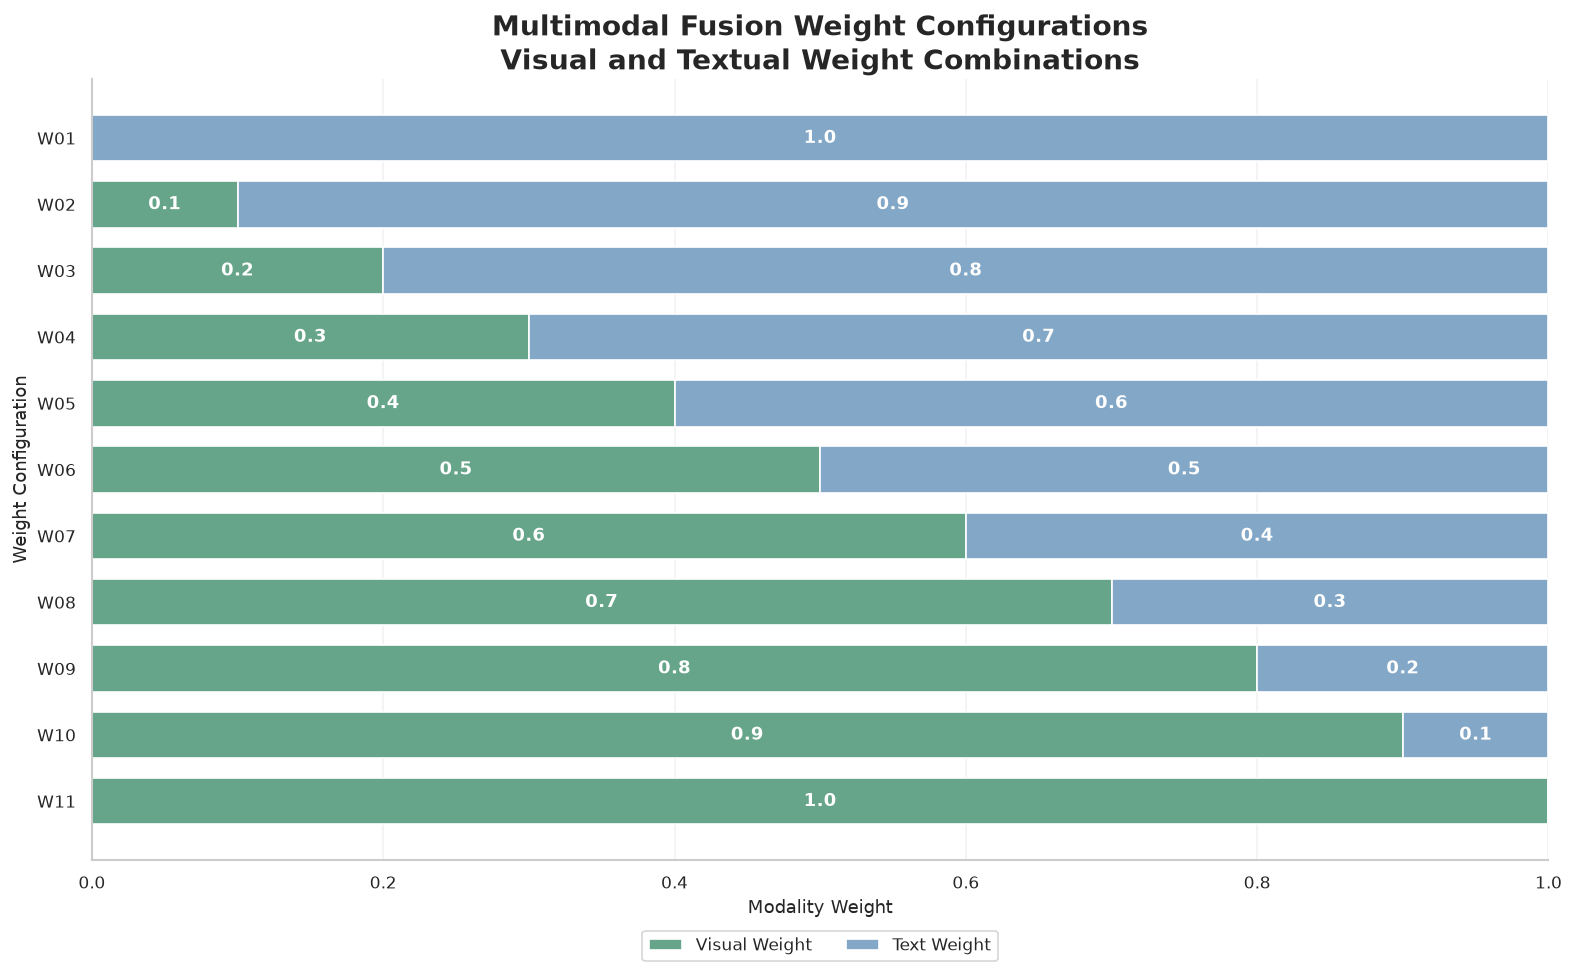

[SAVED] 110_fusion_weight_configurations.png


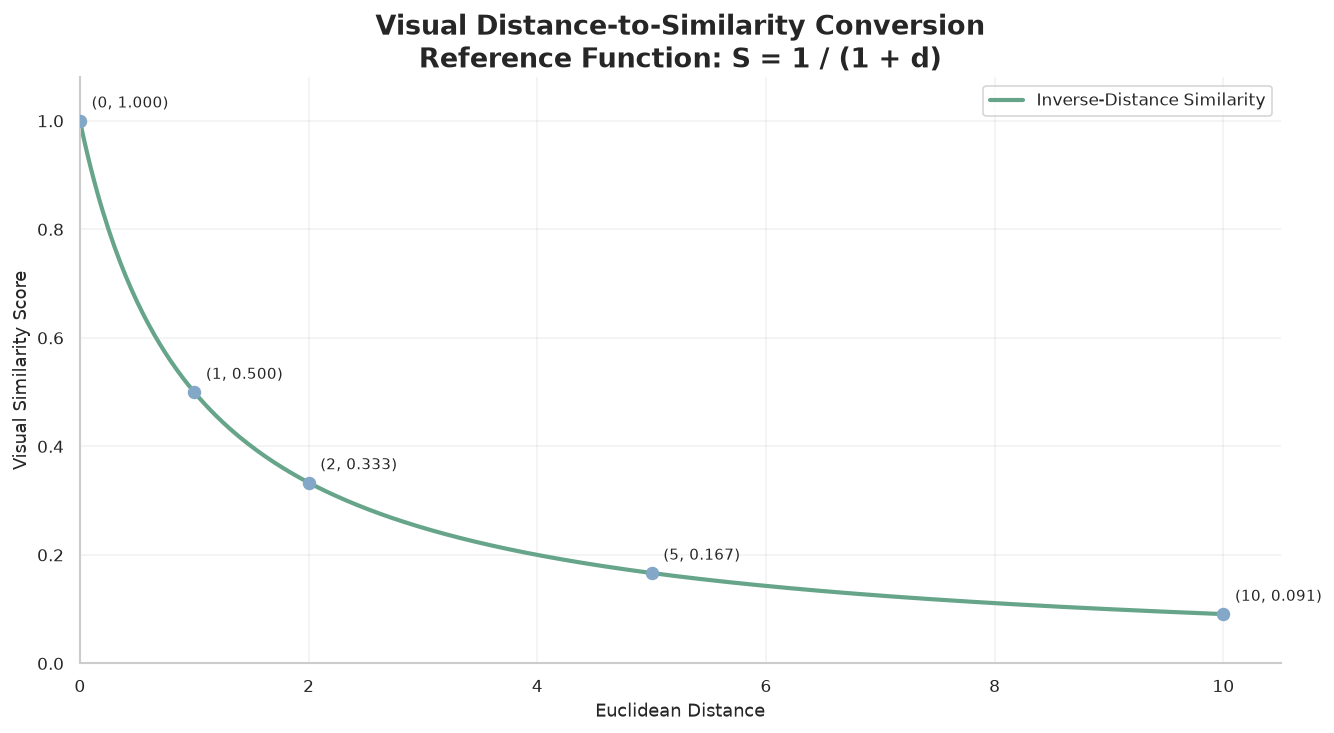

[SAVED] 111_visual_distance_similarity_reference.png

6. FUSION CONFIGURATION SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Dataset samples,104
1,Dataset classes,5
2,Visual feature dimension,143
3,Unigram feature dimension,68
4,Combined feature dimension,261
5,Fusion method,Score-Level Late Fusion
6,Fusion strategy,Weighted Sum
7,Visual distance method,euclidean
8,Visual similarity conversion,inverse_distance
9,Visual distance scale,1.0



7. SAVING CONFIGURATION REPORTS
----------------------------------------------------------------------
[SAVED] 385_fusion_weight_grid.csv
[SAVED] 386_fusion_scenario_definitions.csv
[SAVED] 387_fusion_configuration_validation.csv
[SAVED] 388_fusion_configuration_summary.csv
[SAVED] 389_fusion_preliminary_configuration.json

FINAL MULTIMODAL FUSION CONFIGURATION SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Total samples           : 104
Total classes           : 5
Visual feature dimension: 143

SIMILARITY CONFIGURATION
----------------------------------------------------------------------
Visual matching     : euclidean
Visual conversion   : inverse_distance
Text matching       : cosine

FUSION CONFIGURATION
----------------------------------------------------------------------
Fusion method       : Score-Level Late Fusion
Fusion strategy     : Weighted Sum
Default visual weight: 0.5
Default text weight : 0.5
Weight values       : 1

In [8]:
# ============================================================
# CELL 7 - FUSION CONFIGURATION
# ============================================================

import json
from datetime import datetime, timezone

print("MULTIMODAL FUSION - FUSION CONFIGURATION")
print("=" * 70)

FUSION_CONFIGURATION_COMPLETED = False
FUSION_CONFIG_READY = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

required_fusion_stages = {
    "FUSION_LIBRARIES_IMPORTED":
        FUSION_LIBRARIES_IMPORTED,

    "FUSION_PATH_CONFIGURATION_COMPLETED":
        FUSION_PATH_CONFIGURATION_COMPLETED,

    "VISUAL_FEATURE_LOADING_COMPLETED":
        VISUAL_FEATURE_LOADING_COMPLETED,

    "TEXT_FEATURE_LOADING_COMPLETED":
        TEXT_FEATURE_LOADING_COMPLETED,

    "MULTIMODAL_DATASET_VALIDATION_COMPLETED":
        MULTIMODAL_DATASET_VALIDATION_COMPLETED,

    "MULTIMODAL_DATASET_READY":
        MULTIMODAL_DATASET_READY
}

for stage_name, completed in required_fusion_stages.items():

    assert completed is True, (
        f"{stage_name} is not completed."
    )

assert multimodal_validation_df["passed"].all()

assert multimodal_visual_features.shape == (104, 143)

assert multimodal_text_features[
    "Unigram"
].shape == (104, 68)

assert multimodal_text_features[
    "Unigram + Bigram"
].shape == (104, 261)

assert np.array_equal(
    multimodal_sample_ids,
    text_sample_ids
)

assert np.array_equal(
    multimodal_labels,
    text_labels
)

print("[PASS] Multimodal dataset validated.")


# ============================================================
# 2. MAIN FUSION CONFIGURATION
# ============================================================

FUSION_METHOD = "Score-Level Late Fusion"

FUSION_STRATEGY = "Weighted Sum"

FUSION_VISUAL_DISTANCE_METHOD = "euclidean"

FUSION_TEXT_SIMILARITY_METHOD = "cosine"

FUSION_VISUAL_SIMILARITY_METHOD = "inverse_distance"

# The conversion below implements:
#
# S_image = 1 / (1 + d / scale)
#
# With scale = 1.0:
#
# S_image = 1 / (1 + d)

FUSION_VISUAL_DISTANCE_SCALE = 1.0

FUSION_DEFAULT_VISUAL_WEIGHT = 0.5

FUSION_DEFAULT_TEXT_WEIGHT = (
    1.0 - FUSION_DEFAULT_VISUAL_WEIGHT
)

FUSION_ALPHA_GRID = np.round(
    np.linspace(0.0, 1.0, 11),
    decimals=10
)

FUSION_TOP_K_VALUES = [1, 3, 5, 10]

FUSION_TEXT_CONFIGURATIONS = [
    "Unigram",
    "Unigram + Bigram"
]

# Provisional configuration for development examples.
# NOT a final experimentally selected configuration.

FUSION_DEMO_TEXT_CONFIGURATION = "Unigram"

FUSION_SCORE_MIN = 0.0

FUSION_SCORE_MAX = 1.0

FUSION_NUMERICAL_TOLERANCE = 1e-10

FUSION_EXCLUDE_SELF_MATCH = True

FUSION_TIE_BREAKING_METHOD = (
    "similarity_descending_then_sample_id_ascending"
)

FUSION_MISSING_MODALITY_POLICY = (
    "use_available_modality"
)

FUSION_ALL_MODALITIES_MISSING_POLICY = (
    "reject_query"
)

FUSION_EVALUATION_FIT_POLICY = (
    "reference_only"
)

FUSION_CONFIGURATION_SCOPE = (
    "Full-Gallery Exploratory Development"
)

fusion_configuration_checks = []
fusion_configuration_figures = []


def register_fusion_config_check(
    category,
    name,
    condition
):

    fusion_configuration_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition),
        "status": (
            "Passed" if condition else "Failed"
        )
    })


print("\n1. MAIN FUSION CONFIGURATION")
print("-" * 70)

print("Fusion method          :", FUSION_METHOD)
print("Fusion strategy        :", FUSION_STRATEGY)
print("Visual distance        :", FUSION_VISUAL_DISTANCE_METHOD)
print("Visual score conversion:", FUSION_VISUAL_SIMILARITY_METHOD)
print("Visual distance scale  :", FUSION_VISUAL_DISTANCE_SCALE)
print("Text similarity        :", FUSION_TEXT_SIMILARITY_METHOD)
print("Default visual weight  :", FUSION_DEFAULT_VISUAL_WEIGHT)
print("Default text weight    :", FUSION_DEFAULT_TEXT_WEIGHT)
print("Top-K values           :", FUSION_TOP_K_VALUES)


# ============================================================
# 3. DEFINE VISUAL DISTANCE-TO-SIMILARITY FUNCTION
# ============================================================

def convert_visual_distance_to_similarity(
    distances,
    scale=FUSION_VISUAL_DISTANCE_SCALE
):
    """
    Convert nonnegative Euclidean distances to
    similarity scores using inverse distance.

        similarity = 1 / (1 + distance / scale)

    This is a monotonic conversion, not an
    empirically calibrated similarity probability.
    """

    distance_array = np.asarray(
        distances,
        dtype=np.float64
    )

    if distance_array.size == 0:
        raise ValueError(
            "Distance array cannot be empty."
        )

    if (
        not np.isfinite(scale)
        or scale <= 0
    ):
        raise ValueError(
            "Distance scale must be positive and finite."
        )

    if not np.isfinite(distance_array).all():
        raise ValueError(
            "Distances contain NaN or infinity."
        )

    if np.any(
        distance_array < -FUSION_NUMERICAL_TOLERANCE
    ):
        raise ValueError(
            "Euclidean distances cannot be negative."
        )

    # Handle very small floating-point negative values.

    distance_array = np.maximum(
        distance_array,
        0.0
    )

    similarity = 1.0 / (
        1.0 + distance_array / scale
    )

    return similarity


# ============================================================
# 4. DEFINE WEIGHTED SCORE FUSION FUNCTION
# ============================================================

def fuse_modality_scores(
    image_scores=None,
    text_scores=None,
    visual_weight=FUSION_DEFAULT_VISUAL_WEIGHT
):
    """
    Combine similarity scores using weighted sum.

    Supports:
    - Image and text available
    - Image only
    - Text only

    All-OOV and empty text queries must be detected
    before calling this function. Such queries must
    pass text_scores=None, not an arbitrary zero array.

    Returns:
        fused_scores, effective_weights
    """

    if (
        not np.isfinite(visual_weight)
        or not 0.0 <= visual_weight <= 1.0
    ):
        raise ValueError(
            "Visual weight must be between 0 and 1."
        )

    if image_scores is None and text_scores is None:
        raise ValueError(
            "At least one modality must be available."
        )

    def validate_scores(scores, modality):

        if scores is None:
            return None

        array = np.asarray(
            scores,
            dtype=np.float64
        )

        if array.size == 0:
            raise ValueError(
                f"{modality} score array is empty."
            )

        if not np.isfinite(array).all():
            raise ValueError(
                f"{modality} scores contain invalid values."
            )

        if (
            np.any(
                array < -FUSION_NUMERICAL_TOLERANCE
            )
            or np.any(
                array > 1.0 + FUSION_NUMERICAL_TOLERANCE
            )
        ):
            raise ValueError(
                f"{modality} similarity scores "
                "must lie within [0, 1]."
            )

        return np.clip(
            array,
            0.0,
            1.0
        )

    image_array = validate_scores(
        image_scores,
        "Image"
    )

    text_array = validate_scores(
        text_scores,
        "Text"
    )

    # Case 1: Text is unavailable.

    if text_array is None:

        return image_array.copy(), {
            "effective_visual_weight": 1.0,
            "effective_text_weight": 0.0,
            "mode": "Image Only"
        }

    # Case 2: Image is unavailable.

    if image_array is None:

        return text_array.copy(), {
            "effective_visual_weight": 0.0,
            "effective_text_weight": 1.0,
            "mode": "Text Only"
        }

    # Case 3: Both modalities are available.

    if image_array.shape != text_array.shape:
        raise ValueError(
            "Image and text score arrays "
            "must have identical shapes."
        )

    text_weight = 1.0 - visual_weight

    fused_scores = (
        visual_weight * image_array
        +
        text_weight * text_array
    )

    return fused_scores, {
        "effective_visual_weight": float(
            visual_weight
        ),
        "effective_text_weight": float(
            text_weight
        ),
        "mode": "Multimodal"
    }


# ============================================================
# 5. DEFINE MAIN RETRIEVAL SCENARIOS
# ============================================================

fusion_scenario_records = [

    {
        "scenario_id": "C01",
        "scenario_name": "Image Only",
        "retrieval_method": "Image Only",
        "text_configuration": None,
        "visual_weight": 1.0,
        "text_weight": 0.0
    },

    {
        "scenario_id": "C02",
        "scenario_name": "Text Only - Unigram",
        "retrieval_method": "Text Only",
        "text_configuration": "Unigram",
        "visual_weight": 0.0,
        "text_weight": 1.0
    },

    {
        "scenario_id": "C03",
        "scenario_name": "Text Only - Unigram + Bigram",
        "retrieval_method": "Text Only",
        "text_configuration": "Unigram + Bigram",
        "visual_weight": 0.0,
        "text_weight": 1.0
    },

    {
        "scenario_id": "C04",
        "scenario_name": "Multimodal - Unigram",
        "retrieval_method": "Multimodal",
        "text_configuration": "Unigram",
        "visual_weight": 0.5,
        "text_weight": 0.5
    },

    {
        "scenario_id": "C05",
        "scenario_name": "Multimodal - Unigram + Bigram",
        "retrieval_method": "Multimodal",
        "text_configuration": "Unigram + Bigram",
        "visual_weight": 0.5,
        "text_weight": 0.5
    }
]

fusion_scenario_df = pd.DataFrame(
    fusion_scenario_records
)

fusion_scenario_df[
    "weight_sum"
] = (
    fusion_scenario_df["visual_weight"]
    +
    fusion_scenario_df["text_weight"]
)

fusion_scenario_df[
    "weights_valid"
] = np.isclose(
    fusion_scenario_df["weight_sum"],
    1.0,
    atol=FUSION_NUMERICAL_TOLERANCE
)

print("\n2. MAIN RETRIEVAL SCENARIOS")
print("-" * 70)

display(fusion_scenario_df)


# ============================================================
# 6. CREATE FUSION WEIGHT GRID
# ============================================================

fusion_weight_grid_records = []

for configuration_name in FUSION_TEXT_CONFIGURATIONS:

    for visual_weight in FUSION_ALPHA_GRID:

        visual_weight = float(
            visual_weight
        )

        text_weight = float(
            1.0 - visual_weight
        )

        if visual_weight == 1.0:

            retrieval_mode = "Image Only"

            # Image Only is the same method regardless
            # of the unused TF-IDF configuration.

            unique_method_key = "image_only"

        elif visual_weight == 0.0:

            retrieval_mode = "Text Only"

            unique_method_key = (
                f"text_only::{configuration_name}"
            )

        else:

            retrieval_mode = "Multimodal"

            unique_method_key = (
                f"multimodal::{configuration_name}::"
                f"{visual_weight:.1f}"
            )

        fusion_weight_grid_records.append({

            "configuration": configuration_name,

            "visual_weight": visual_weight,

            "text_weight": text_weight,

            "weight_sum": (
                visual_weight + text_weight
            ),

            "retrieval_mode": retrieval_mode,

            "unique_method_key": unique_method_key,

            "is_balanced": np.isclose(
                visual_weight,
                0.5
            )
        })


fusion_weight_grid_df = pd.DataFrame(
    fusion_weight_grid_records
)

fusion_grid_total_records = len(
    fusion_weight_grid_df
)

fusion_grid_unique_methods = (
    fusion_weight_grid_df[
        "unique_method_key"
    ].nunique()
)

print("\n3. FUSION WEIGHT GRID")
print("-" * 70)

display(fusion_weight_grid_df)

print(
    "Total configuration-weight combinations:",
    fusion_grid_total_records
)

print(
    "Unique retrieval methods:",
    fusion_grid_unique_methods
)


# ============================================================
# 7. VALIDATE CONFIGURATION STRUCTURE
# ============================================================

register_fusion_config_check(
    "Dataset",
    "Multimodal dataset contains 104 samples",
    multimodal_n_samples == 104
)

register_fusion_config_check(
    "Dataset",
    "All samples aligned",
    multimodal_sample_alignment_df[
        "alignment_passed"
    ].all()
)

register_fusion_config_check(
    "Dataset",
    "Alignment signature available",
    isinstance(
        multimodal_alignment_signature,
        str
    )
    and len(multimodal_alignment_signature) == 64
)

register_fusion_config_check(
    "Similarity",
    "Euclidean distance configured",
    FUSION_VISUAL_DISTANCE_METHOD == "euclidean"
)

register_fusion_config_check(
    "Similarity",
    "Cosine similarity configured",
    FUSION_TEXT_SIMILARITY_METHOD == "cosine"
)

register_fusion_config_check(
    "Similarity",
    "Positive visual distance scale",
    np.isfinite(FUSION_VISUAL_DISTANCE_SCALE)
    and FUSION_VISUAL_DISTANCE_SCALE > 0
)

register_fusion_config_check(
    "Fusion",
    "Weighted score-level late fusion configured",
    FUSION_METHOD == "Score-Level Late Fusion"
    and FUSION_STRATEGY == "Weighted Sum"
)

register_fusion_config_check(
    "Fusion",
    "Default weights sum to one",
    np.isclose(
        FUSION_DEFAULT_VISUAL_WEIGHT
        + FUSION_DEFAULT_TEXT_WEIGHT,
        1.0,
        atol=FUSION_NUMERICAL_TOLERANCE
    )
)

register_fusion_config_check(
    "Fusion",
    "Eleven fusion weights configured",
    len(FUSION_ALPHA_GRID) == 11
)

register_fusion_config_check(
    "Fusion",
    "Fusion weights span zero to one",
    np.isclose(FUSION_ALPHA_GRID[0], 0.0)
    and np.isclose(FUSION_ALPHA_GRID[-1], 1.0)
)

register_fusion_config_check(
    "Fusion",
    "Fusion weights use step 0.1",
    np.allclose(
        np.diff(FUSION_ALPHA_GRID),
        0.1,
        atol=FUSION_NUMERICAL_TOLERANCE
    )
)

register_fusion_config_check(
    "Fusion",
    "All weight combinations sum to one",
    np.allclose(
        fusion_weight_grid_df["weight_sum"],
        1.0,
        atol=FUSION_NUMERICAL_TOLERANCE
    )
)

register_fusion_config_check(
    "Fusion",
    "Two TF-IDF configurations retained",
    set(FUSION_TEXT_CONFIGURATIONS)
    == {"Unigram", "Unigram + Bigram"}
)

register_fusion_config_check(
    "Scenarios",
    "Five primary retrieval scenarios",
    len(fusion_scenario_df) == 5
)

register_fusion_config_check(
    "Scenarios",
    "Scenario identifiers unique",
    fusion_scenario_df["scenario_id"].is_unique
)

register_fusion_config_check(
    "Scenarios",
    "Scenario names unique",
    fusion_scenario_df["scenario_name"].is_unique
)

register_fusion_config_check(
    "Scenarios",
    "All scenario weights valid",
    fusion_scenario_df["weights_valid"].all()
)

register_fusion_config_check(
    "Scenarios",
    "22 configuration-weight records",
    fusion_grid_total_records == 22
)

register_fusion_config_check(
    "Scenarios",
    "21 unique retrieval methods",
    fusion_grid_unique_methods == 21
)

register_fusion_config_check(
    "Retrieval",
    "Top-K values valid for 104 samples",
    all(
        1 <= k < multimodal_n_samples
        for k in FUSION_TOP_K_VALUES
    )
)

register_fusion_config_check(
    "Retrieval",
    "Self-match exclusion enabled",
    FUSION_EXCLUDE_SELF_MATCH
)

register_fusion_config_check(
    "Retrieval",
    "Deterministic tie-breaking configured",
    FUSION_TIE_BREAKING_METHOD
    ==
    "similarity_descending_then_sample_id_ascending"
)

register_fusion_config_check(
    "Missing Modalities",
    "Single-modality fallback configured",
    FUSION_MISSING_MODALITY_POLICY
    == "use_available_modality"
)

register_fusion_config_check(
    "Evaluation Protection",
    "Reference-only fitting required",
    FUSION_EVALUATION_FIT_POLICY
    == "reference_only"
)


# ============================================================
# 8. MATHEMATICAL SANITY TESTS
# ============================================================

def expects_value_error(function):
    try:
        function()
        return False
    except ValueError:
        return True


test_distances = np.array(
    [0.0, 0.5, 1.0, 2.0, 10.0],
    dtype=np.float64
)

test_converted_scores = (
    convert_visual_distance_to_similarity(
        test_distances
    )
)

expected_converted_scores = (
    1.0 / (1.0 + test_distances)
)

test_image_scores = np.array(
    [0.8, 0.6, 0.3]
)

test_text_scores = np.array(
    [0.2, 0.4, 0.9]
)

test_balanced_scores, test_balanced_weights = (
    fuse_modality_scores(
        test_image_scores,
        test_text_scores,
        visual_weight=0.5
    )
)

test_image_only, test_image_only_weights = (
    fuse_modality_scores(
        image_scores=test_image_scores,
        text_scores=None,
        visual_weight=0.5
    )
)

test_text_only, test_text_only_weights = (
    fuse_modality_scores(
        image_scores=None,
        text_scores=test_text_scores,
        visual_weight=0.5
    )
)

test_alpha_zero, _ = fuse_modality_scores(
    test_image_scores,
    test_text_scores,
    visual_weight=0.0
)

test_alpha_one, _ = fuse_modality_scores(
    test_image_scores,
    test_text_scores,
    visual_weight=1.0
)

# Deterministic tie-breaking example.

test_rank_scores = np.array(
    [0.7, 0.9, 0.9, 0.6]
)

test_rank_ids = np.array(
    ["B", "C", "A", "D"]
)

test_rank_order = np.lexsort((
    test_rank_ids,
    -test_rank_scores
))

test_ranked_ids = (
    test_rank_ids[test_rank_order]
    .tolist()
)


fusion_math_test_cases = [

    (
        "Zero distance produces similarity one",
        np.isclose(test_converted_scores[0], 1.0)
    ),

    (
        "Inverse distance formula reproduced",
        np.allclose(
            test_converted_scores,
            expected_converted_scores
        )
    ),

    (
        "Converted scores bounded in [0,1]",
        np.all(
            (test_converted_scores >= 0)
            &
            (test_converted_scores <= 1)
        )
    ),

    (
        "Similarity decreases with increasing distance",
        np.all(np.diff(test_converted_scores) < 0)
    ),

    (
        "Balanced fusion formula reproduced",
        np.allclose(
            test_balanced_scores,
            0.5 * test_image_scores
            + 0.5 * test_text_scores
        )
    ),

    (
        "Alpha zero reproduces text scores",
        np.allclose(
            test_alpha_zero,
            test_text_scores
        )
    ),

    (
        "Alpha one reproduces image scores",
        np.allclose(
            test_alpha_one,
            test_image_scores
        )
    ),

    (
        "Image-only fallback preserved",
        np.array_equal(
            test_image_only,
            test_image_scores
        )
        and test_image_only_weights[
            "effective_visual_weight"
        ] == 1.0
    ),

    (
        "Text-only fallback preserved",
        np.array_equal(
            test_text_only,
            test_text_scores
        )
        and test_text_only_weights[
            "effective_text_weight"
        ] == 1.0
    ),

    (
        "Balanced fusion effective weights valid",
        np.isclose(
            test_balanced_weights[
                "effective_visual_weight"
            ]
            +
            test_balanced_weights[
                "effective_text_weight"
            ],
            1.0
        )
    ),

    (
        "Reject negative Euclidean distance",
        expects_value_error(
            lambda:
            convert_visual_distance_to_similarity(
                [-1.0]
            )
        )
    ),

    (
        "Reject NaN Euclidean distance",
        expects_value_error(
            lambda:
            convert_visual_distance_to_similarity(
                [np.nan]
            )
        )
    ),

    (
        "Reject invalid fusion weight",
        expects_value_error(
            lambda:
            fuse_modality_scores(
                test_image_scores,
                test_text_scores,
                visual_weight=1.5
            )
        )
    ),

    (
        "Reject mismatched modality shapes",
        expects_value_error(
            lambda:
            fuse_modality_scores(
                [0.5, 0.6],
                [0.7],
                visual_weight=0.5
            )
        )
    ),

    (
        "Reject missing image and text scores",
        expects_value_error(
            lambda:
            fuse_modality_scores(
                None,
                None
            )
        )
    ),

    (
        "Reject out-of-range similarity",
        expects_value_error(
            lambda:
            fuse_modality_scores(
                [1.5],
                [0.4]
            )
        )
    ),

    (
        "Deterministic ranking resolves ties by sample ID",
        test_ranked_ids == [
            "A", "C", "B", "D"
        ]
    )
]


fusion_math_validation_df = pd.DataFrame(
    fusion_math_test_cases,
    columns=[
        "validation_check",
        "passed"
    ]
)

fusion_math_validation_df["status"] = np.where(
    fusion_math_validation_df["passed"],
    "Passed",
    "Failed"
)

for row in fusion_math_validation_df.itertuples():

    register_fusion_config_check(
        "Mathematical Sanity Tests",
        row.validation_check,
        row.passed
    )

print("\n4. MATHEMATICAL SANITY TESTS")
print("-" * 70)

display(fusion_math_validation_df)


# ============================================================
# 9. CREATE REPRODUCIBLE CONFIGURATION DICTIONARY
# ============================================================

fusion_configuration = {

    "schema_version": "1.0.0",

    "notebook": "05_multimodal_fusion.ipynb",

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "scope": FUSION_CONFIGURATION_SCOPE,

    "dataset": {
        "number_of_samples": int(
            multimodal_n_samples
        ),
        "number_of_classes": int(
            len(multimodal_class_names)
        ),
        "alignment_signature":
            multimodal_alignment_signature,
        "sample_order_preserved": True
    },

    "features": {
        "visual_dimension": int(
            multimodal_visual_features.shape[1]
        ),
        "text_dimensions": {
            configuration_name: int(
                multimodal_text_features[
                    configuration_name
                ].shape[1]
            )
            for configuration_name
            in FUSION_TEXT_CONFIGURATIONS
        },
        "modalities_concatenated": False
    },

    "visual_matching": {
        "distance_method":
            FUSION_VISUAL_DISTANCE_METHOD,
        "similarity_conversion":
            FUSION_VISUAL_SIMILARITY_METHOD,
        "distance_scale":
            FUSION_VISUAL_DISTANCE_SCALE
    },

    "text_matching": {
        "similarity_method":
            FUSION_TEXT_SIMILARITY_METHOD,
        "configurations":
            FUSION_TEXT_CONFIGURATIONS
    },

    "fusion": {
        "method": FUSION_METHOD,
        "strategy": FUSION_STRATEGY,
        "default_visual_weight":
            FUSION_DEFAULT_VISUAL_WEIGHT,
        "default_text_weight":
            FUSION_DEFAULT_TEXT_WEIGHT,
        "weight_grid":
            FUSION_ALPHA_GRID.tolist(),
        "weight_optimization_completed": False,
        "final_weight_selected": False,
        "final_text_configuration_selected": False,
        "demo_text_configuration":
            FUSION_DEMO_TEXT_CONFIGURATION
    },

    "retrieval": {
        "top_k_values": FUSION_TOP_K_VALUES,
        "self_match_excluded":
            FUSION_EXCLUDE_SELF_MATCH,
        "tie_breaking":
            FUSION_TIE_BREAKING_METHOD
    },

    "missing_modality_handling": {
        "single_modality_policy":
            FUSION_MISSING_MODALITY_POLICY,
        "all_modalities_missing":
            FUSION_ALL_MODALITIES_MISSING_POLICY,
        "all_oov_text_is_unavailable": True
    },

    "evaluation_protection": {
        "fitting_policy":
            FUSION_EVALUATION_FIT_POLICY,
        "independent_evaluation_completed": False,
        "full_gallery_results_are_exploratory": True
    },

    "numerical_tolerance":
        FUSION_NUMERICAL_TOLERANCE
}


# ============================================================
# 10. FINAL CONFIGURATION VALIDATION
# ============================================================

fusion_configuration_validation_df = pd.DataFrame(
    fusion_configuration_checks
)

fusion_configuration_total_checks = len(
    fusion_configuration_validation_df
)

fusion_configuration_passed_checks = int(
    fusion_configuration_validation_df[
        "passed"
    ].sum()
)

fusion_configuration_failed_checks = (
    fusion_configuration_total_checks
    - fusion_configuration_passed_checks
)

print("\n5. FUSION CONFIGURATION VALIDATION")
print("-" * 70)

display(fusion_configuration_validation_df)

# Preserve diagnostics if a check fails.

fusion_configuration_validation_df.to_csv(
    METRICS_DIR / "387_fusion_configuration_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert fusion_configuration_validation_df[
    "passed"
].all(), (
    fusion_configuration_validation_df.loc[
        ~fusion_configuration_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All fusion configuration checks passed.")


# ============================================================
# 11. VISUALIZATION - FUSION WEIGHT GRID
# ============================================================

fig, ax = plt.subplots(
    figsize=(13, 8),
    constrained_layout=True
)

weight_positions = np.arange(
    len(FUSION_ALPHA_GRID)
)

visual_weights = FUSION_ALPHA_GRID

text_weights = (
    1.0 - visual_weights
)

ax.barh(
    weight_positions,
    visual_weights,
    color="#66A58A",
    height=0.7,
    label="Visual Weight"
)

ax.barh(
    weight_positions,
    text_weights,
    left=visual_weights,
    color="#83A7C7",
    height=0.7,
    label="Text Weight"
)

for index, (visual_w, text_w) in enumerate(
    zip(visual_weights, text_weights)
):

    if visual_w > 0.05:
        ax.text(
            visual_w / 2,
            index,
            f"{visual_w:.1f}",
            ha="center",
            va="center",
            color="white",
            fontweight="bold"
        )

    if text_w > 0.05:
        ax.text(
            visual_w + text_w / 2,
            index,
            f"{text_w:.1f}",
            ha="center",
            va="center",
            color="white",
            fontweight="bold"
        )

ax.set_yticks(weight_positions)

ax.set_yticklabels([
    f"W{i + 1:02d}"
    for i in range(len(FUSION_ALPHA_GRID))
])

ax.invert_yaxis()

ax.set_xlim(0, 1.0)

ax.set_xlabel("Modality Weight")

ax.set_ylabel("Weight Configuration")

ax.set_title(
    "Multimodal Fusion Weight Configurations\n"
    "Visual and Textual Weight Combinations",
    fontsize=17,
    fontweight="bold"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=2
)

figure_path = (
    FUSION_FIGURES_DIR
    / "110_fusion_weight_configurations.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

fusion_configuration_figures.append(
    figure_path
)

plt.show()
plt.close(fig)

print(f"[SAVED] {figure_path.name}")


# ============================================================
# 12. VISUALIZATION - DISTANCE CONVERSION
# ============================================================

# Synthetic distance values only.
# The actual visual distance distribution
# will be calculated in Cell 8 and Cell 9.

reference_distances = np.linspace(
    0.0,
    10.0,
    401
)

reference_similarities = (
    convert_visual_distance_to_similarity(
        reference_distances
    )
)

fig, ax = plt.subplots(
    figsize=(11, 6),
    constrained_layout=True
)

ax.plot(
    reference_distances,
    reference_similarities,
    color="#66A58A",
    linewidth=2.5,
    label="Inverse-Distance Similarity"
)

for distance in [0, 1, 2, 5, 10]:

    similarity = float(
        convert_visual_distance_to_similarity(
            [distance]
        )[0]
    )

    ax.scatter(
        distance,
        similarity,
        color="#83A7C7",
        s=50,
        zorder=3
    )

    ax.annotate(
        f"({distance}, {similarity:.3f})",
        (distance, similarity),
        xytext=(7, 8),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlim(0, 10.5)
ax.set_ylim(0, 1.08)

ax.set_xlabel("Euclidean Distance")
ax.set_ylabel("Visual Similarity Score")

ax.set_title(
    "Visual Distance-to-Similarity Conversion\n"
    "Reference Function: S = 1 / (1 + d)",
    fontsize=16,
    fontweight="bold"
)

ax.legend()

figure_path = (
    FUSION_FIGURES_DIR
    / "111_visual_distance_similarity_reference.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

fusion_configuration_figures.append(
    figure_path
)

plt.show()
plt.close(fig)

print(f"[SAVED] {figure_path.name}")


# ============================================================
# 13. CREATE FINAL CONFIGURATION SUMMARY
# ============================================================

fusion_configuration_summary_df = pd.DataFrame([

    ("Dataset samples", multimodal_n_samples),

    ("Dataset classes", len(multimodal_class_names)),

    (
        "Visual feature dimension",
        multimodal_visual_features.shape[1]
    ),

    (
        "Unigram feature dimension",
        multimodal_text_features[
            "Unigram"
        ].shape[1]
    ),

    (
        "Combined feature dimension",
        multimodal_text_features[
            "Unigram + Bigram"
        ].shape[1]
    ),

    ("Fusion method", FUSION_METHOD),

    ("Fusion strategy", FUSION_STRATEGY),

    (
        "Visual distance method",
        FUSION_VISUAL_DISTANCE_METHOD
    ),

    (
        "Visual similarity conversion",
        FUSION_VISUAL_SIMILARITY_METHOD
    ),

    (
        "Visual distance scale",
        FUSION_VISUAL_DISTANCE_SCALE
    ),

    (
        "Text similarity method",
        FUSION_TEXT_SIMILARITY_METHOD
    ),

    (
        "Default visual weight",
        FUSION_DEFAULT_VISUAL_WEIGHT
    ),

    (
        "Default text weight",
        FUSION_DEFAULT_TEXT_WEIGHT
    ),

    ("Weight configurations", len(FUSION_ALPHA_GRID)),

    ("Primary scenarios", len(fusion_scenario_df)),

    (
        "Configuration-weight combinations",
        fusion_grid_total_records
    ),

    (
        "Unique retrieval methods",
        fusion_grid_unique_methods
    ),

    ("Top-K values", str(FUSION_TOP_K_VALUES)),

    ("Self-match exclusion", True),

    (
        "Tie-breaking method",
        FUSION_TIE_BREAKING_METHOD
    ),

    (
        "Missing modality policy",
        FUSION_MISSING_MODALITY_POLICY
    ),

    (
        "Validation checks",
        fusion_configuration_total_checks
    ),

    (
        "Validation checks passed",
        fusion_configuration_passed_checks
    ),

    (
        "Validation checks failed",
        fusion_configuration_failed_checks
    ),

    (
        "Generated figures",
        len(fusion_configuration_figures)
    ),

    ("Score matrices calculated", False),

    ("Fusion weights optimized", False),

    ("Final text configuration selected", False),

    ("Independent retrieval evaluation completed", False),

    ("Dataset samples modified", False),

    ("Feature matrices modified", False),

    ("Fusion configuration completed", True)

], columns=["Indicator", "Result"])

print("\n6. FUSION CONFIGURATION SUMMARY")
print("-" * 70)

display(fusion_configuration_summary_df)


# ============================================================
# 14. SAVE FUSION CONFIGURATION REPORTS
# ============================================================

fusion_configuration_reports = {

    "385_fusion_weight_grid.csv":
        fusion_weight_grid_df,

    "386_fusion_scenario_definitions.csv":
        fusion_scenario_df,

    "387_fusion_configuration_validation.csv":
        fusion_configuration_validation_df,

    "388_fusion_configuration_summary.csv":
        fusion_configuration_summary_df
}

print("\n7. SAVING CONFIGURATION REPORTS")
print("-" * 70)

for filename, dataframe in (
    fusion_configuration_reports.items()
):

    output_path = METRICS_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


FUSION_PRELIMINARY_CONFIG_PATH = (
    METRICS_DIR
    / "389_fusion_preliminary_configuration.json"
)

with open(
    FUSION_PRELIMINARY_CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        fusion_configuration,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False
    )

print(
    f"[SAVED] "
    f"{FUSION_PRELIMINARY_CONFIG_PATH.name}"
)


# ============================================================
# 15. FINAL COMPLETION CHECKS
# ============================================================

assert fusion_configuration_validation_df[
    "passed"
].all()

assert fusion_math_validation_df[
    "passed"
].all()

assert fusion_configuration_failed_checks == 0

assert len(fusion_scenario_df) == 5

assert len(FUSION_ALPHA_GRID) == 11

assert len(fusion_weight_grid_df) == 22

assert fusion_grid_unique_methods == 21

assert len(fusion_configuration_figures) == 2

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in fusion_configuration_figures
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in fusion_configuration_reports
)

assert FUSION_PRELIMINARY_CONFIG_PATH.is_file()

with open(
    FUSION_PRELIMINARY_CONFIG_PATH,
    "r",
    encoding="utf-8"
) as file:

    reloaded_fusion_configuration = json.load(
        file
    )

assert (
    reloaded_fusion_configuration
    == fusion_configuration
)

FUSION_CONFIGURATION_COMPLETED = True
FUSION_CONFIG_READY = True


# ============================================================
# 16. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)

print("FINAL MULTIMODAL FUSION CONFIGURATION SUMMARY")

print("=" * 70)

print("\nDATASET INFORMATION")
print("-" * 70)

print("Total samples           :", multimodal_n_samples)
print("Total classes           :", len(multimodal_class_names))
print("Visual feature dimension:", multimodal_visual_features.shape[1])

print("\nSIMILARITY CONFIGURATION")
print("-" * 70)

print("Visual matching     :", FUSION_VISUAL_DISTANCE_METHOD)
print("Visual conversion   :", FUSION_VISUAL_SIMILARITY_METHOD)
print("Text matching       :", FUSION_TEXT_SIMILARITY_METHOD)

print("\nFUSION CONFIGURATION")
print("-" * 70)

print("Fusion method       :", FUSION_METHOD)
print("Fusion strategy     :", FUSION_STRATEGY)
print("Default visual weight:", FUSION_DEFAULT_VISUAL_WEIGHT)
print("Default text weight :", FUSION_DEFAULT_TEXT_WEIGHT)
print("Weight values       :", len(FUSION_ALPHA_GRID))
print("Primary scenarios   :", len(fusion_scenario_df))
print("Unique methods      :", fusion_grid_unique_methods)
print("Top-K values        :", FUSION_TOP_K_VALUES)

print("\nVALIDATION RESULTS")
print("-" * 70)

print(
    "Technical checks    :",
    f"{fusion_configuration_passed_checks}/"
    f"{fusion_configuration_total_checks}"
)

print(
    "Failed checks       :",
    fusion_configuration_failed_checks
)

print(
    "Mathematical tests  :",
    f"{fusion_math_validation_df['passed'].sum()}/"
    f"{len(fusion_math_validation_df)}"
)

print(
    "Generated CSV files :",
    len(fusion_configuration_reports)
)

print(
    "Generated JSON files:",
    1
)

print(
    "Generated figures   :",
    len(fusion_configuration_figures)
)

print("\n[PASS] Similarity methods configured.")
print("[PASS] Visual score conversion defined.")
print("[PASS] Weighted fusion function defined.")
print("[PASS] Modality fallback behavior validated.")
print("[PASS] Fusion scenarios defined.")
print("[PASS] Fusion weight grid created.")
print("[PASS] Ranking tie-breaking configured.")
print("[PASS] Mathematical sanity tests completed.")
print("[PASS] Configuration reports saved.")

print("\n[INFO] Default weight is provisional.")
print("[INFO] No best fusion weight has been selected.")
print("[INFO] No similarity matrices were calculated.")
print("[INFO] No feature matrices were modified.")
print("[INFO] Independent retrieval evaluation is pending.")

print("\n" + "=" * 70)

print("FUSION CONFIGURATION COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 8 - Euclidean Distance Calculation")

MULTIMODAL FUSION - LOAD TEXT FEATURE ARTIFACTS
[PASS] Previous cells validated.

1. TEXT ARTIFACT LOCATIONS
----------------------------------------------------------------------
Text feature directory: D:\Project\Multimodal_Leaf_Retrieval\dataset\features\text
Expected payload files : 16
Manifest              : text_feature_artifact_manifest.csv
[PASS] Text artifact manifest loaded.

2. TEXT ARTIFACT INTEGRITY
----------------------------------------------------------------------
[PASS] tfidf_unigram_features.npz
[PASS] tfidf_unigram_vectorizer.joblib
[PASS] tfidf_unigram_feature_names.npy
[PASS] tfidf_unigram_idf_weights.npy
[PASS] tfidf_unigram_vocabulary.csv
[PASS] tfidf_unigram_bigram_features.npz
[PASS] tfidf_unigram_bigram_vectorizer.joblib
[PASS] tfidf_unigram_bigram_feature_names.npy
[PASS] tfidf_unigram_bigram_idf_weights.npy
[PASS] tfidf_unigram_bigram_vocabulary.csv
[PASS] text_sample_ids.npy
[PASS] text_class_labels.npy
[PASS] multimodal_feature_metadata.csv
[PASS] text_c

,row_index,sample_id,kelas,visual_id_match,visual_label_match,metadata_id_match,metadata_label_match,corpus_match,alignment_flag,passed
0,0,leaf_165d2f32c7fda707,Mangkok,True,True,True,True,True,True,True
1,1,leaf_8473270c3702f48b,Mangkok,True,True,True,True,True,True,True
2,2,leaf_8f425d66b1e193b9,Mangkok,True,True,True,True,True,True,True
3,3,leaf_0ebc8f4f3ee9c8d5,Mangkok,True,True,True,True,True,True,True
4,4,leaf_b0c5f55e42499cae,Mangkok,True,True,True,True,True,True,True
5,5,leaf_de9e3e4ed5d89dfc,Mangkok,True,True,True,True,True,True,True
6,6,leaf_23b789945271fb92,Mangkok,True,True,True,True,True,True,True
7,7,leaf_84de0dc731018607,Mangkok,True,True,True,True,True,True,True



5. LOADING TF-IDF CONFIGURATIONS
----------------------------------------------------------------------

Configuration: Unigram
Matrix shape : (104, 68)
Nonzero      : 2086
Unigram      : 68
Bigram       : 0
Reproduction difference: 1.665e-16

Configuration: Unigram + Bigram
Matrix shape : (104, 261)
Nonzero      : 4166
Unigram      : 68
Bigram       : 193
Reproduction difference: 1.110e-16

6. LOADED TEXT MATRIX SUMMARY
----------------------------------------------------------------------


C:\Users\ronn7\AppData\Local\Temp\ipykernel_22184\2737530108.py:532: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  vocabulary_df = pd.read_csv(
C:\Users\ronn7\AppData\Local\Temp\ipykernel_22184\2737530108.py:532: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  vocabulary_df = pd.read_csv(


,configuration,samples,feature_dimension,unigram_features,bigram_features,nonzero_values,zero_values,sparsity_percent,minimum_l2_norm,maximum_l2_norm,reproduction_max_difference,matrix_file_kib,vectorizer_file_kib
0,Unigram,104,68,68,0,2086,4986,70.503394,1.0,1.0,0.0,10.820312,1.419922
1,Unigram + Bigram,104,261,68,193,4166,22978,84.652225,1.0,1.0,0.0,17.756836,3.093750



7. MAIN TEXT FEATURE VARIABLES
----------------------------------------------------------------------
Unigram features : (104, 68)
Combined features: (104, 261)
Text sample IDs  : (104,)
Text labels      : (104,)

8. CLASS DISTRIBUTION
----------------------------------------------------------------------


,kelas,number_of_samples,percentage
0,Mangkok,20,19.2308
1,Salam,19,18.2692
2,Sambang Darah,20,19.2308
3,Sirih,20,19.2308
4,Tapak Kuda,25,24.0385



9. TEXT FEATURE LOADING VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Manifest,Manifest covers all expected text artifacts,True,Passed
1,Artifact Integrity,tfidf_unigram_features.npz integrity,True,Passed
2,Artifact Integrity,tfidf_unigram_vectorizer.joblib integrity,True,Passed
3,Artifact Integrity,tfidf_unigram_feature_names.npy integrity,True,Passed
4,Artifact Integrity,tfidf_unigram_idf_weights.npy integrity,True,Passed
5,Artifact Integrity,tfidf_unigram_vocabulary.csv integrity,True,Passed
6,Artifact Integrity,tfidf_unigram_bigram_features.npz integrity,True,Passed
7,Artifact Integrity,tfidf_unigram_bigram_vectorizer.joblib integrity,True,Passed
8,Artifact Integrity,tfidf_unigram_bigram_feature_names.npy integrity,True,Passed
9,Artifact Integrity,tfidf_unigram_bigram_idf_weights.npy integrity,True,Passed


[PASS] All text loading checks passed.


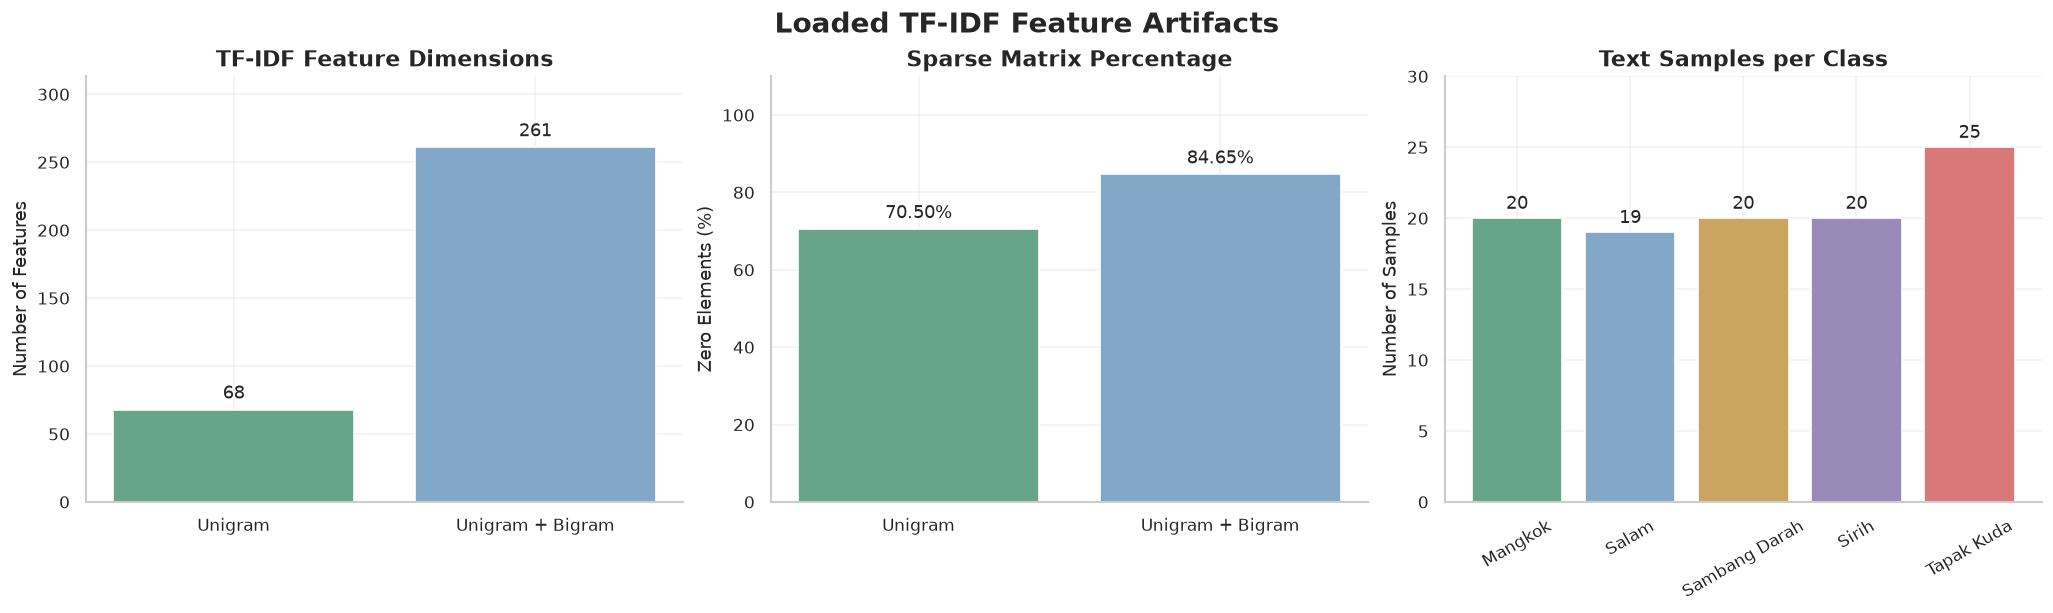

[SAVED] 106_loaded_text_feature_summary.png


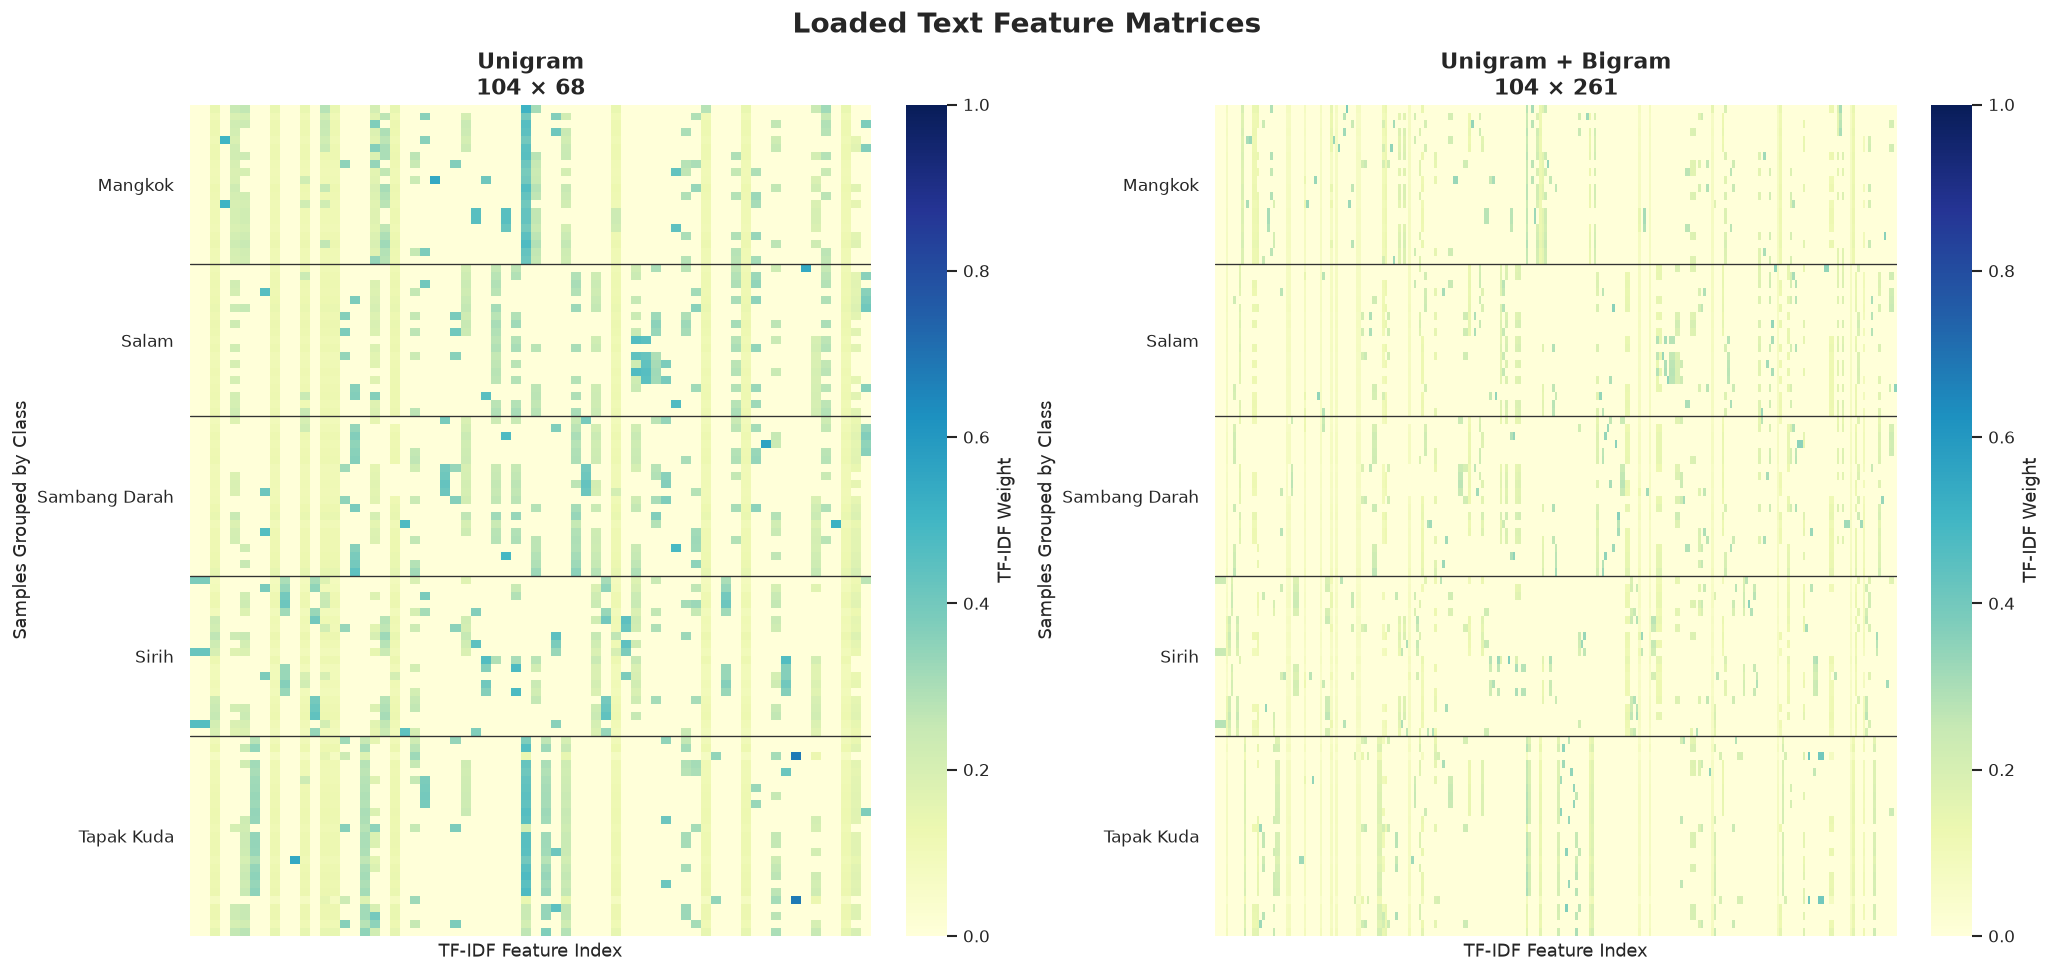

[SAVED] 107_loaded_text_feature_matrices.png

10. TEXT LOADING SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Total samples,104
1,Total classes,5
2,TF-IDF configurations,2
3,Unigram matrix shape,"(104, 68)"
4,Combined matrix shape,"(104, 261)"
5,Verified payload artifacts,16
6,Aligned samples,104
7,Validation checks,80
8,Passed checks,80
9,Failed checks,0



11. SAVING TEXT LOADING REPORTS
----------------------------------------------------------------------
[SAVED] 368_text_artifact_integrity.csv
[SAVED] 369_loaded_text_matrix_summary.csv
[SAVED] 370_text_vocabulary_integrity.csv
[SAVED] 371_text_visual_identity_alignment.csv
[SAVED] 372_text_loading_validation.csv
[SAVED] 373_loaded_text_class_distribution.csv
[SAVED] 374_text_loading_summary.csv

FINAL TEXT FEATURE LOADING SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Text samples      : 104
Visual samples    : 104
Aligned samples   : 104
Plant classes     : 5

TEXT FEATURE MATRICES
----------------------------------------------------------------------
Unigram features  : (104, 68)
Combined features : (104, 261)

ARTIFACT INFORMATION
----------------------------------------------------------------------
Verified payloads : 16/16
Loaded vectorizers: 2

VALIDATION
----------------------------------------------------------------------

MULTIMODAL FUSION - EUCLIDEAN DISTANCE CALCULATION
[PASS] Previous processing stages validated.

1. DISTANCE CALCULATION CONFIGURATION
----------------------------------------------------------------------
Distance method       : euclidean
Expected samples      : 104
Expected features     : 143
Numerical tolerance   : 1e-10
Cross-check tolerance : 1e-06
Triangle tests        : 5000
Analysis scope        : Full-Gallery Exploratory Development

2. INPUT VISUAL FEATURES
----------------------------------------------------------------------
Feature matrix: (104, 143)
Sample IDs    : (104,)
Class labels  : (104,)
[PASS] Visual feature input ready.

3. PAIRWISE EUCLIDEAN DISTANCE CALCULATION
----------------------------------------------------------------------
Distance matrix shape: (104, 104)
Calculation time: 5.6182 ms
Distance matrix dtype: float64


,leaf_165d2f32c7fda707,leaf_8473270c3702f48b,leaf_8f425d66b1e193b9,leaf_0ebc8f4f3ee9c8d5,leaf_b0c5f55e42499cae
leaf_165d2f32c7fda707,0.000000,2.428759,2.502255,2.243289,2.390537
leaf_8473270c3702f48b,2.428759,0.000000,0.503673,0.627318,0.638484
leaf_8f425d66b1e193b9,2.502255,0.503673,0.000000,0.588122,0.650970
leaf_0ebc8f4f3ee9c8d5,2.243289,0.627318,0.588122,0.000000,0.664264
leaf_b0c5f55e42499cae,2.390537,0.638484,0.650970,0.664264,0.000000



4. INDEPENDENT IMPLEMENTATION CROSS-CHECK
----------------------------------------------------------------------
SciPy calculation time  : 5.6182 ms
Sklearn calculation time: 36.6941 ms
Maximum difference      : 2.665e-15

5. BASIC MATRIX VALIDATION
----------------------------------------------------------------------
Maximum diagonal error: 0.000e+00
Maximum symmetry error: 0.000e+00
Minimum distance: 0.000000
Maximum distance: 5.366333

6. UNIQUE SAMPLE PAIR INVENTORY
----------------------------------------------------------------------
Total unique pairs : 5356
Within-class pairs: 1041
Cross-class pairs : 4315
Near-zero distance pairs: 0

7. MANUAL DISTANCE VERIFICATION
----------------------------------------------------------------------


,pair_label,manual_euclidean_distance,scipy_euclidean_distance,manual_absolute_error
0,Within - Mangkok,2.428759,2.428759,0.0
1,Within - Salam,2.494229,2.494229,0.0
2,Within - Sambang Darah,2.222246,2.222246,0.0
3,Within - Sirih,1.039870,1.039870,0.0
4,Within - Tapak Kuda,1.358410,1.358410,0.0
5,Cross - Mangkok / Salam,3.417659,3.417659,0.0
6,Cross - Salam / Sambang Darah,2.333851,2.333851,0.0
7,Cross - Sambang Darah / Sirih,1.973050,1.973050,0.0
8,Cross - Sirih / Tapak Kuda,1.883283,1.883283,0.0
9,Cross - Tapak Kuda / Mangkok,2.547943,2.547943,0.0


Maximum manual calculation error: 4.441e-16
Maximum group decomposition error: 8.882e-16

8. TRIANGLE INEQUALITY VALIDATION
----------------------------------------------------------------------
Random index triples tested: 5000
Maximum triangle inequality violation: 0.000e+00
Triangle inequality: Passed

9. ROW ORDER INVARIANCE
----------------------------------------------------------------------
Maximum permutation difference: 0.000e+00

10. NEAREST NEIGHBOR PREVIEW
----------------------------------------------------------------------


,query_sample_id,query_class,rank,retrieved_sample_id,retrieved_class,euclidean_distance,self_match_excluded
0,leaf_165d2f32c7fda707,Mangkok,1,leaf_a6da65cb0493ceef,Mangkok,1.231581,True
1,leaf_165d2f32c7fda707,Mangkok,2,leaf_ac5e952a9ae56c36,Sambang Darah,1.253823,True
2,leaf_165d2f32c7fda707,Mangkok,3,leaf_4de65b11758965f6,Mangkok,1.408892,True
3,leaf_165d2f32c7fda707,Mangkok,4,leaf_12439b9ebf0eb8d3,Mangkok,1.438785,True
4,leaf_165d2f32c7fda707,Mangkok,5,leaf_c9d8d87fbc748d16,Mangkok,1.465237,True
5,leaf_c29e2560b188fb2c,Salam,1,leaf_22bf36f7b3abd78c,Tapak Kuda,1.770577,True
6,leaf_c29e2560b188fb2c,Salam,2,leaf_1ebaf9512209a61f,Salam,1.836590,True
7,leaf_c29e2560b188fb2c,Salam,3,leaf_68b0c81b496519cd,Salam,1.861226,True
8,leaf_c29e2560b188fb2c,Salam,4,leaf_8f8d177305fb06f2,Tapak Kuda,1.870957,True
9,leaf_c29e2560b188fb2c,Salam,5,leaf_0a8999109a734f1d,Salam,2.095505,True



11. DISTANCE MATRIX SUMMARY
----------------------------------------------------------------------


,0
distance_method,Euclidean
feature_source,visual_features_normalized.npy
number_of_samples,104
feature_dimension,143
matrix_rows,104
matrix_columns,104
matrix_dtype,float64
total_matrix_entries,10816
unique_off_diagonal_pairs,5356
within_class_pairs,1041



12. EUCLIDEAN DISTANCE VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Input Data,Normalized visual matrix dimensions valid,True,Passed
1,Input Data,Visual matrix contains finite values,True,Passed
2,Input Data,Visual sample IDs unique,True,Passed
3,Input Data,Sample ID and label order preserved,True,Passed
4,Cross-Implementation,SciPy and sklearn Euclidean distances consistent,True,Passed
5,Distance Matrix,Distance matrix shape is 104 x 104,True,Passed
6,Distance Matrix,Distance matrix uses float64,True,Passed
7,Distance Matrix,All distance values finite,True,Passed
8,Distance Matrix,All Euclidean distances nonnegative,True,Passed
9,Distance Matrix,Diagonal distances equal zero,True,Passed


[PASS] All Euclidean distance checks passed.


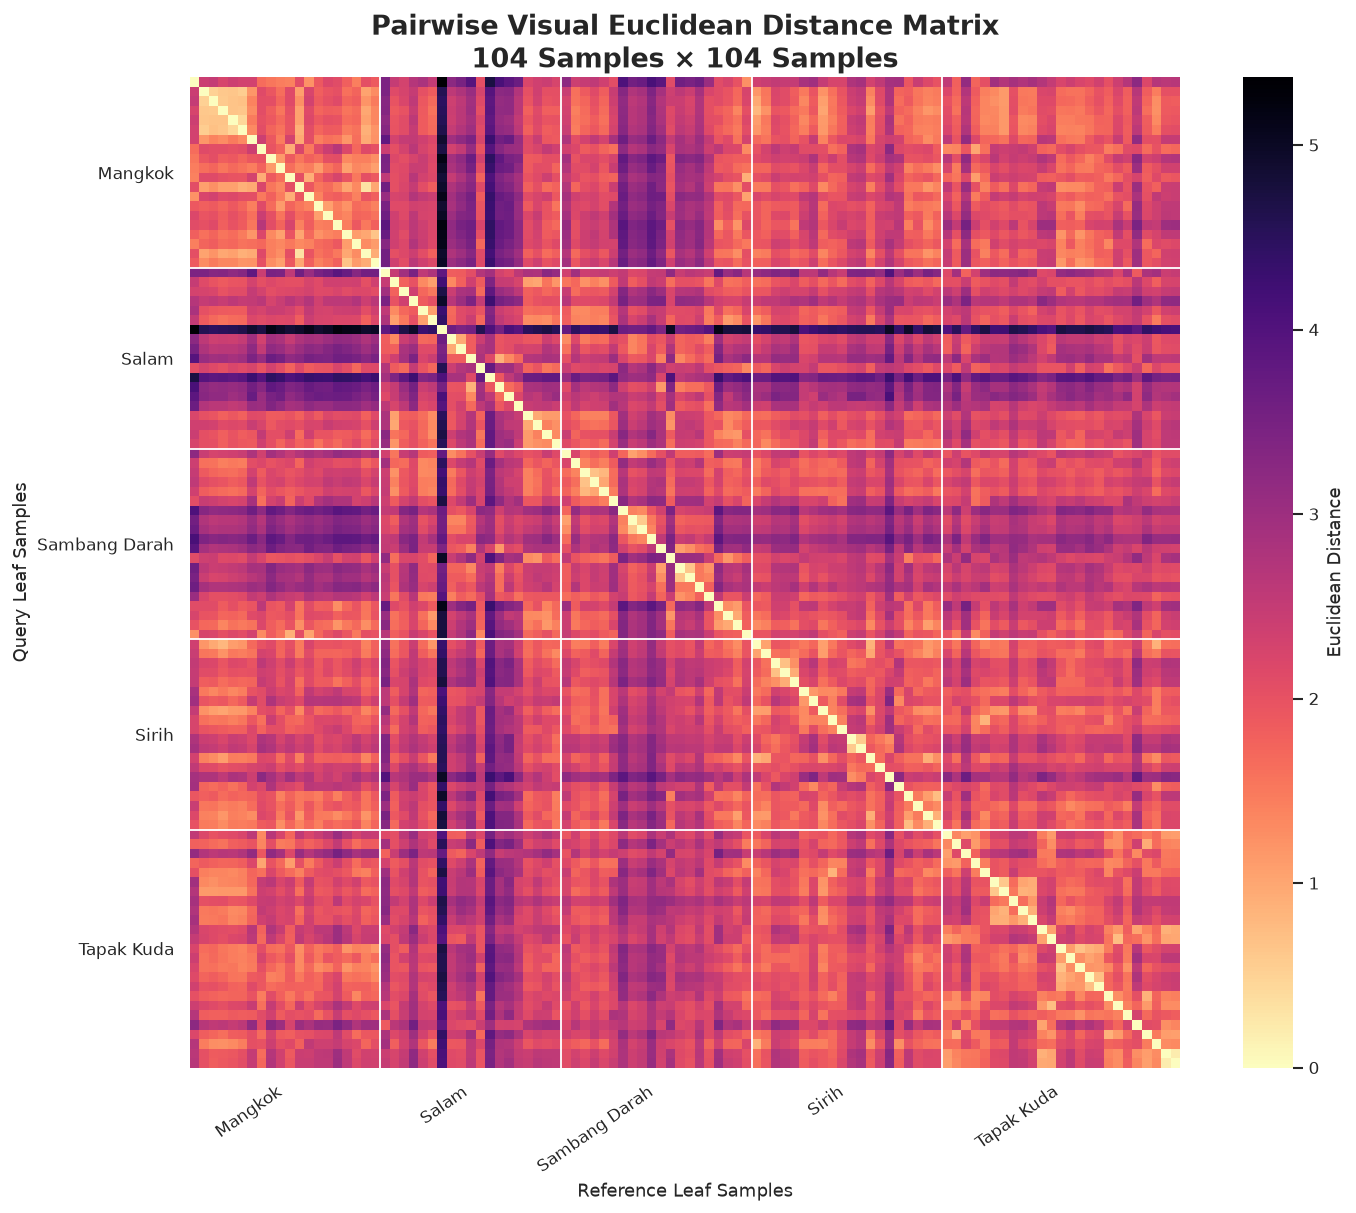

[SAVED] 112_visual_euclidean_distance_matrix.png


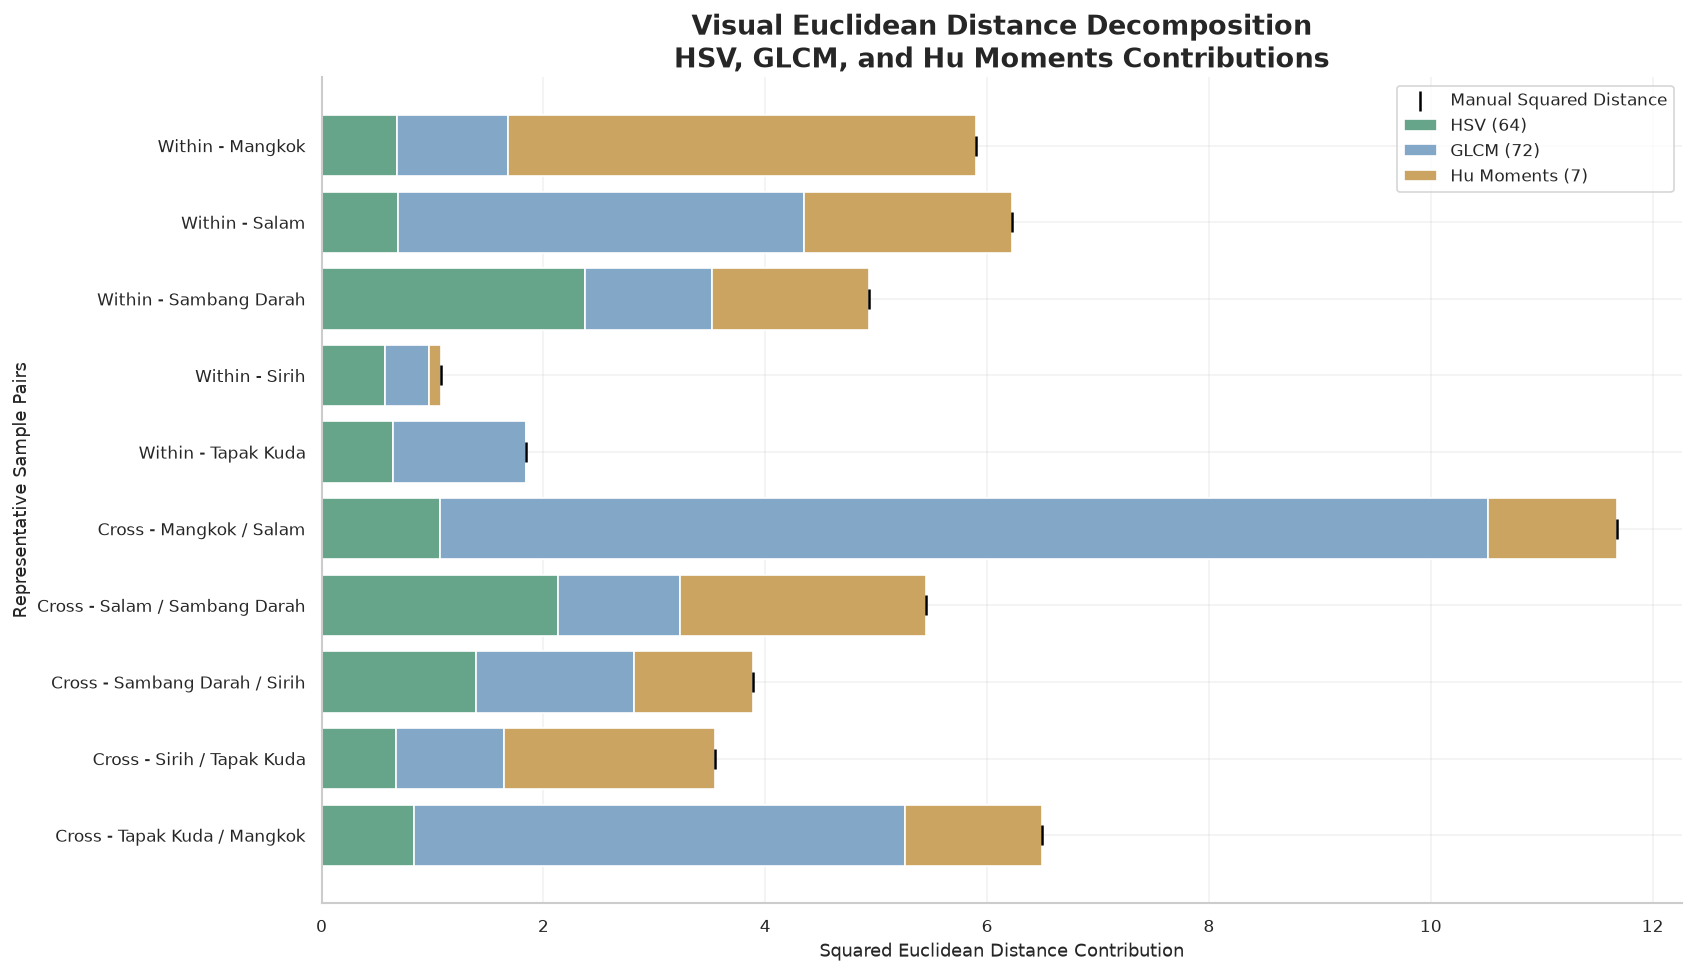

[SAVED] 113_visual_euclidean_distance_decomposition.png

13. FINAL CELL SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Input visual matrix,"(104, 143)"
1,Distance matrix,"(104, 104)"
2,Unique sample pairs,5356
3,Within-class pairs,1041
4,Cross-class pairs,4315
5,Near-zero off-diagonal pairs,0
6,Maximum symmetry error,0.0
7,Maximum diagonal error,0.0
8,Maximum manual error,0.0
9,Maximum sklearn cross-check error,0.0



14. SAVING EUCLIDEAN DISTANCE REPORTS
----------------------------------------------------------------------
[SAVED] 390_visual_euclidean_distance_summary.csv
[SAVED] 391_visual_euclidean_distance_validation.csv
[SAVED] 392_visual_euclidean_manual_pairs.csv
[SAVED] 393_visual_euclidean_group_contributions.csv
[SAVED] 394_visual_euclidean_neighbor_preview.csv
[SAVED] 395_visual_euclidean_pair_inventory.csv
[SAVED] 396_visual_euclidean_cell_summary.csv

FINAL VISUAL EUCLIDEAN DISTANCE SUMMARY

DATASET INFORMATION
----------------------------------------------------------------------
Total samples       : 104
Visual dimensions   : 143
Distance matrix     : (104, 104)

SAMPLE PAIRS
----------------------------------------------------------------------
Unique pairs        : 5356
Within-class pairs  : 1041
Cross-class pairs   : 4315

DISTANCE MATRIX PROPERTIES
----------------------------------------------------------------------
Minimum pair distance : 0.208826
Maximum pair distance : 5.36

In [10]:
# ============================================================
# CELL 8 - EUCLIDEAN DISTANCE CALCULATION
# ============================================================

print("MULTIMODAL FUSION - EUCLIDEAN DISTANCE CALCULATION")
print("=" * 70)

VISUAL_DISTANCE_CALCULATION_COMPLETED = False
VISUAL_EUCLIDEAN_DISTANCE_COMPLETED = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

required_stages = [
    "FUSION_LIBRARIES_IMPORTED",
    "FUSION_PATH_CONFIGURATION_COMPLETED",
    "VISUAL_FEATURE_LOADING_COMPLETED",
    "TEXT_FEATURE_LOADING_COMPLETED",
    "MULTIMODAL_DATASET_VALIDATION_COMPLETED",
    "FUSION_CONFIGURATION_COMPLETED"
]

for stage in required_stages:
    assert globals().get(stage, False), (
        f"{stage} is not completed."
    )

assert multimodal_validation_df["passed"].all()
assert fusion_configuration_validation_df["passed"].all()

assert FUSION_VISUAL_DISTANCE_METHOD == "euclidean"

print("[PASS] Previous processing stages validated.")


# ============================================================
# 2. DISTANCE CALCULATION CONFIGURATION
# ============================================================

VISUAL_DISTANCE_EXPECTED_SAMPLES = 104
VISUAL_DISTANCE_EXPECTED_DIMENSION = 143

VISUAL_DISTANCE_TOLERANCE = 1e-10

# sklearn's norm-expansion formula may produce small
# round-off differences for very close vectors.
# This tolerance is used only for cross-implementation
# comparison, not for changing stored distances.

VISUAL_DISTANCE_CROSSCHECK_TOLERANCE = 1e-6

VISUAL_DISTANCE_TRIANGLE_TESTS = 5000

VISUAL_DISTANCE_NEIGHBOR_PREVIEW_K = 5

VISUAL_DISTANCE_RANDOM_STATE = 42

VISUAL_DISTANCE_SCOPE = (
    "Full-Gallery Exploratory Development"
)

visual_distance_validation_records = []
visual_distance_figure_paths = []


def register_visual_distance_check(
    category,
    name,
    passed
):
    visual_distance_validation_records.append({
        "category": category,
        "validation_check": name,
        "passed": bool(passed),
        "status": "Passed" if passed else "Failed"
    })


def save_visual_distance_figure(fig, filename):

    output_path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    visual_distance_figure_paths.append(output_path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


print("\n1. DISTANCE CALCULATION CONFIGURATION")
print("-" * 70)

print("Distance method       :", FUSION_VISUAL_DISTANCE_METHOD)
print("Expected samples      :", VISUAL_DISTANCE_EXPECTED_SAMPLES)
print("Expected features     :", VISUAL_DISTANCE_EXPECTED_DIMENSION)
print("Numerical tolerance   :", VISUAL_DISTANCE_TOLERANCE)
print("Cross-check tolerance :", VISUAL_DISTANCE_CROSSCHECK_TOLERANCE)
print("Triangle tests        :", VISUAL_DISTANCE_TRIANGLE_TESTS)
print("Analysis scope        :", VISUAL_DISTANCE_SCOPE)


# ============================================================
# 3. PREPARE VISUAL FEATURE MATRIX
# ============================================================

# Use the main normalized visual representation.
# Do not standardize, refit, or reorder features.

visual_distance_features = np.asarray(
    multimodal_visual_features,
    dtype=np.float64
)

visual_distance_sample_ids = np.asarray(
    multimodal_sample_ids,
    dtype=str
)

visual_distance_labels = np.asarray(
    multimodal_labels,
    dtype=str
)

visual_distance_n_samples = (
    visual_distance_features.shape[0]
)

assert visual_distance_features.shape == (104, 143)

assert np.isfinite(
    visual_distance_features
).all()

assert np.array_equal(
    visual_distance_sample_ids,
    visual_sample_ids
)

assert np.array_equal(
    visual_distance_labels,
    visual_labels
)

assert len(np.unique(
    visual_distance_sample_ids
)) == visual_distance_n_samples

register_visual_distance_check(
    "Input Data",
    "Normalized visual matrix dimensions valid",
    visual_distance_features.shape == (104, 143)
)

register_visual_distance_check(
    "Input Data",
    "Visual matrix contains finite values",
    np.isfinite(visual_distance_features).all()
)

register_visual_distance_check(
    "Input Data",
    "Visual sample IDs unique",
    len(np.unique(visual_distance_sample_ids))
    == visual_distance_n_samples
)

register_visual_distance_check(
    "Input Data",
    "Sample ID and label order preserved",
    np.array_equal(
        visual_distance_sample_ids,
        multimodal_sample_ids
    )
    and np.array_equal(
        visual_distance_labels,
        multimodal_labels
    )
)

print("\n2. INPUT VISUAL FEATURES")
print("-" * 70)

print("Feature matrix:", visual_distance_features.shape)
print("Sample IDs    :", visual_distance_sample_ids.shape)
print("Class labels  :", visual_distance_labels.shape)

print("[PASS] Visual feature input ready.")


# ============================================================
# 4. CALCULATE PAIRWISE EUCLIDEAN DISTANCES
# ============================================================

# Main calculation uses scipy.spatial.distance.cdist.
#
# D[i, j] = sqrt(sum_k((X[i,k] - X[j,k]) ** 2))
#
# scipy cdist computes distances directly and avoids
# some cancellation issues from norm-expansion formulas.

visual_distance_start_time = time.perf_counter()

visual_euclidean_distance_matrix = cdist(
    visual_distance_features,
    visual_distance_features,
    metric="euclidean"
)

visual_distance_calculation_time_ms = (
    time.perf_counter()
    - visual_distance_start_time
) * 1000

# Reusable aliases for subsequent cells.

visual_distance_matrix = (
    visual_euclidean_distance_matrix
)

visual_pairwise_distance_matrix = (
    visual_euclidean_distance_matrix
)

print("\n3. PAIRWISE EUCLIDEAN DISTANCE CALCULATION")
print("-" * 70)

print(
    "Distance matrix shape:",
    visual_euclidean_distance_matrix.shape
)

print(
    "Calculation time:",
    f"{visual_distance_calculation_time_ms:.4f} ms"
)

print(
    "Distance matrix dtype:",
    visual_euclidean_distance_matrix.dtype
)

display(
    pd.DataFrame(
        visual_euclidean_distance_matrix[:5, :5],
        index=visual_distance_sample_ids[:5],
        columns=visual_distance_sample_ids[:5]
    ).round(6)
)


# ============================================================
# 5. CALCULATE SKLEARN REFERENCE DISTANCES
# ============================================================

# Independent implementation used as a cross-check.
# This matrix is not used as the main output.

sklearn_distance_start_time = time.perf_counter()

visual_euclidean_sklearn_reference = (
    euclidean_distances(
        visual_distance_features,
        visual_distance_features
    )
)

visual_sklearn_calculation_time_ms = (
    time.perf_counter()
    - sklearn_distance_start_time
) * 1000

visual_distance_crosscheck_difference = float(
    np.max(
        np.abs(
            visual_euclidean_distance_matrix
            - visual_euclidean_sklearn_reference
        )
    )
)

register_visual_distance_check(
    "Cross-Implementation",
    "SciPy and sklearn Euclidean distances consistent",
    visual_distance_crosscheck_difference
    <= VISUAL_DISTANCE_CROSSCHECK_TOLERANCE
)

print("\n4. INDEPENDENT IMPLEMENTATION CROSS-CHECK")
print("-" * 70)

print(
    "SciPy calculation time  :",
    f"{visual_distance_calculation_time_ms:.4f} ms"
)

print(
    "Sklearn calculation time:",
    f"{visual_sklearn_calculation_time_ms:.4f} ms"
)

print(
    "Maximum difference      :",
    f"{visual_distance_crosscheck_difference:.3e}"
)


# ============================================================
# 6. VALIDATE BASIC DISTANCE MATRIX PROPERTIES
# ============================================================

distance_matrix = visual_euclidean_distance_matrix

distance_diagonal = np.diag(distance_matrix)

distance_symmetry_error = float(
    np.max(
        np.abs(
            distance_matrix - distance_matrix.T
        )
    )
)

distance_diagonal_error = float(
    np.max(
        np.abs(distance_diagonal)
    )
)

distance_minimum = float(
    distance_matrix.min()
)

distance_maximum = float(
    distance_matrix.max()
)

basic_distance_checks = {

    "Distance matrix shape is 104 x 104":
        distance_matrix.shape == (104, 104),

    "Distance matrix uses float64":
        distance_matrix.dtype == np.float64,

    "All distance values finite":
        np.isfinite(distance_matrix).all(),

    "All Euclidean distances nonnegative":
        np.all(
            distance_matrix
            >= -VISUAL_DISTANCE_TOLERANCE
        ),

    "Diagonal distances equal zero":
        distance_diagonal_error
        <= VISUAL_DISTANCE_TOLERANCE,

    "Distance matrix is symmetric":
        distance_symmetry_error
        <= VISUAL_DISTANCE_TOLERANCE,

    "Maximum distance is positive":
        distance_maximum > 0,

    "Minimum distance is zero":
        np.isclose(
            distance_minimum,
            0.0,
            atol=VISUAL_DISTANCE_TOLERANCE
        )
}

for check_name, passed in basic_distance_checks.items():

    register_visual_distance_check(
        "Distance Matrix",
        check_name,
        passed
    )

print("\n5. BASIC MATRIX VALIDATION")
print("-" * 70)

print(
    "Maximum diagonal error:",
    f"{distance_diagonal_error:.3e}"
)

print(
    "Maximum symmetry error:",
    f"{distance_symmetry_error:.3e}"
)

print(
    "Minimum distance:",
    f"{distance_minimum:.6f}"
)

print(
    "Maximum distance:",
    f"{distance_maximum:.6f}"
)


# ============================================================
# 7. ANALYZE UNIQUE SAMPLE PAIRS
# ============================================================

# Exclude diagonal entries.
# Use only the upper triangle to prevent double counting.

visual_pair_i, visual_pair_j = np.triu_indices(
    visual_distance_n_samples,
    k=1
)

visual_unique_pair_distances = distance_matrix[
    visual_pair_i,
    visual_pair_j
]

visual_same_class_pair_mask = (
    visual_distance_labels[visual_pair_i]
    == visual_distance_labels[visual_pair_j]
)

visual_unique_pair_count = len(
    visual_unique_pair_distances
)

visual_within_class_pair_count = int(
    visual_same_class_pair_mask.sum()
)

visual_cross_class_pair_count = int(
    (~visual_same_class_pair_mask).sum()
)

expected_unique_pairs = (
    visual_distance_n_samples
    * (visual_distance_n_samples - 1)
    // 2
)

class_sample_counts = Counter(
    visual_distance_labels
)

expected_within_pairs = sum(
    count * (count - 1) // 2
    for count in class_sample_counts.values()
)

expected_cross_pairs = (
    expected_unique_pairs - expected_within_pairs
)

register_visual_distance_check(
    "Pair Inventory",
    "Unique pair count correct",
    visual_unique_pair_count == expected_unique_pairs
)

register_visual_distance_check(
    "Pair Inventory",
    "Within-class pair count correct",
    visual_within_class_pair_count
    == expected_within_pairs
)

register_visual_distance_check(
    "Pair Inventory",
    "Cross-class pair count correct",
    visual_cross_class_pair_count
    == expected_cross_pairs
)

register_visual_distance_check(
    "Pair Inventory",
    "Within and cross-class counts reconcile",
    visual_within_class_pair_count
    + visual_cross_class_pair_count
    == visual_unique_pair_count
)

visual_zero_distance_pair_count = int(
    np.sum(
        visual_unique_pair_distances
        <= VISUAL_DISTANCE_TOLERANCE
    )
)

print("\n6. UNIQUE SAMPLE PAIR INVENTORY")
print("-" * 70)

print(
    "Total unique pairs :",
    visual_unique_pair_count
)

print(
    "Within-class pairs:",
    visual_within_class_pair_count
)

print(
    "Cross-class pairs :",
    visual_cross_class_pair_count
)

print(
    "Near-zero distance pairs:",
    visual_zero_distance_pair_count
)


# ============================================================
# 8. VERIFY EUCLIDEAN DISTANCE MANUALLY
# ============================================================

# Select one within-class pair from each class
# and one cross-class pair from each neighboring
# pair of class names.
#
# These are diagnostic examples, not evaluation queries.

visual_unique_classes = sorted(
    np.unique(visual_distance_labels)
)

visual_representative_indices = {
    class_name: np.flatnonzero(
        visual_distance_labels == class_name
    )
    for class_name in visual_unique_classes
}

visual_selected_pairs = []

# Five within-class examples.

for class_name in visual_unique_classes:

    indices = visual_representative_indices[
        class_name
    ]

    assert len(indices) >= 2

    visual_selected_pairs.append({
        "pair_type": "Within Class",
        "pair_label": f"Within - {class_name}",
        "index_i": int(indices[0]),
        "index_j": int(indices[1])
    })

# Five cross-class examples.

for class_index, class_name in enumerate(
    visual_unique_classes
):

    next_class = visual_unique_classes[
        (class_index + 1)
        % len(visual_unique_classes)
    ]

    index_i = int(
        visual_representative_indices[
            class_name
        ][0]
    )

    index_j = int(
        visual_representative_indices[
            next_class
        ][0]
    )

    visual_selected_pairs.append({
        "pair_type": "Cross Class",
        "pair_label": (
            f"Cross - {class_name} / {next_class}"
        ),
        "index_i": index_i,
        "index_j": index_j
    })


visual_manual_pair_records = []
visual_group_contribution_records = []

for pair in visual_selected_pairs:

    i = pair["index_i"]
    j = pair["index_j"]

    feature_difference = (
        visual_distance_features[i]
        - visual_distance_features[j]
    )

    # Explicit calculation from the 143 feature values.

    manual_squared_distance = float(
        np.sum(
            feature_difference ** 2,
            dtype=np.float64
        )
    )

    manual_distance = float(
        np.sqrt(manual_squared_distance)
    )

    scipy_distance = float(
        distance_matrix[i, j]
    )

    sklearn_distance = float(
        visual_euclidean_sklearn_reference[i, j]
    )

    absolute_error = abs(
        manual_distance - scipy_distance
    )

    visual_manual_pair_records.append({
        "pair_type": pair["pair_type"],
        "pair_label": pair["pair_label"],
        "row_i": i,
        "row_j": j,
        "sample_id_i": visual_distance_sample_ids[i],
        "sample_id_j": visual_distance_sample_ids[j],
        "class_i": visual_distance_labels[i],
        "class_j": visual_distance_labels[j],
        "manual_squared_distance":
            manual_squared_distance,
        "manual_euclidean_distance":
            manual_distance,
        "scipy_euclidean_distance":
            scipy_distance,
        "sklearn_euclidean_distance":
            sklearn_distance,
        "manual_absolute_error":
            absolute_error
    })

    # Decompose squared Euclidean distance into
    # HSV, GLCM, and Hu Moments contributions.

    group_squared_distances = {}

    for group_name in VISUAL_FEATURE_GROUP_ORDER:

        group_slice = VISUAL_FEATURE_GROUP_SLICES[
            group_name
        ]

        group_difference = feature_difference[
            group_slice
        ]

        group_squared_distances[group_name] = float(
            np.sum(
                group_difference ** 2,
                dtype=np.float64
            )
        )

    summed_group_distance = sum(
        group_squared_distances.values()
    )

    visual_group_contribution_records.append({
        "pair_type": pair["pair_type"],
        "pair_label": pair["pair_label"],
        "sample_id_i": visual_distance_sample_ids[i],
        "sample_id_j": visual_distance_sample_ids[j],
        "hsv_squared_distance":
            group_squared_distances["HSV"],
        "glcm_squared_distance":
            group_squared_distances["GLCM"],
        "hu_squared_distance":
            group_squared_distances["Hu Moments"],
        "summed_group_squared_distance":
            summed_group_distance,
        "manual_squared_distance":
            manual_squared_distance,
        "decomposition_absolute_error":
            abs(
                summed_group_distance
                - manual_squared_distance
            )
    })


visual_euclidean_manual_pairs_df = pd.DataFrame(
    visual_manual_pair_records
)

visual_euclidean_group_contributions_df = pd.DataFrame(
    visual_group_contribution_records
)

manual_maximum_error = float(
    visual_euclidean_manual_pairs_df[
        "manual_absolute_error"
    ].max()
)

group_maximum_error = float(
    visual_euclidean_group_contributions_df[
        "decomposition_absolute_error"
    ].max()
)

register_visual_distance_check(
    "Manual Verification",
    "Ten representative sample pairs checked",
    len(visual_euclidean_manual_pairs_df) == 10
)

register_visual_distance_check(
    "Manual Verification",
    "Manual Euclidean calculation consistent",
    manual_maximum_error
    <= VISUAL_DISTANCE_TOLERANCE
)

register_visual_distance_check(
    "Manual Verification",
    "HSV-GLCM-Hu squared-distance decomposition valid",
    group_maximum_error
    <= VISUAL_DISTANCE_TOLERANCE
)

print("\n7. MANUAL DISTANCE VERIFICATION")
print("-" * 70)

display(
    visual_euclidean_manual_pairs_df[[
        "pair_label",
        "manual_euclidean_distance",
        "scipy_euclidean_distance",
        "manual_absolute_error"
    ]].round(10)
)

print(
    "Maximum manual calculation error:",
    f"{manual_maximum_error:.3e}"
)

print(
    "Maximum group decomposition error:",
    f"{group_maximum_error:.3e}"
)


# ============================================================
# 9. VERIFY TRIANGLE INEQUALITY
# ============================================================

# Euclidean distance must satisfy:
#
# d(i, j) <= d(i, k) + d(k, j)
#
# Test 5000 deterministic random index triples.

visual_distance_rng = np.random.default_rng(
    VISUAL_DISTANCE_RANDOM_STATE
)

triangle_indices = visual_distance_rng.integers(
    low=0,
    high=visual_distance_n_samples,
    size=(VISUAL_DISTANCE_TRIANGLE_TESTS, 3)
)

triangle_i = triangle_indices[:, 0]
triangle_j = triangle_indices[:, 1]
triangle_k = triangle_indices[:, 2]

triangle_left = distance_matrix[
    triangle_i,
    triangle_j
]

triangle_right = (
    distance_matrix[triangle_i, triangle_k]
    +
    distance_matrix[triangle_k, triangle_j]
)

triangle_violation = (
    triangle_left - triangle_right
)

triangle_max_violation = float(
    np.maximum(
        triangle_violation,
        0.0
    ).max()
)

triangle_passed = bool(
    np.all(
        triangle_left
        <= triangle_right
        + VISUAL_DISTANCE_TOLERANCE
    )
)

register_visual_distance_check(
    "Metric Properties",
    "Sampled triangle inequality satisfied",
    triangle_passed
)

print("\n8. TRIANGLE INEQUALITY VALIDATION")
print("-" * 70)

print(
    "Random index triples tested:",
    VISUAL_DISTANCE_TRIANGLE_TESTS
)

print(
    "Maximum triangle inequality violation:",
    f"{triangle_max_violation:.3e}"
)

print(
    "Triangle inequality:",
    "Passed" if triangle_passed else "Failed"
)


# ============================================================
# 10. VERIFY SAMPLE ORDER INVARIANCE
# ============================================================

# Reorder a diagnostic COPY of features.
# Reversing the permutation must reproduce the
# original pairwise distance matrix.
#
# This does not modify the original dataset.

permutation = visual_distance_rng.permutation(
    visual_distance_n_samples
)

permuted_features = visual_distance_features[
    permutation
]

permuted_distance_matrix = cdist(
    permuted_features,
    permuted_features,
    metric="euclidean"
)

expected_permuted_distances = distance_matrix[
    np.ix_(permutation, permutation)
]

permutation_maximum_error = float(
    np.max(
        np.abs(
            permuted_distance_matrix
            - expected_permuted_distances
        )
    )
)

register_visual_distance_check(
    "Metric Properties",
    "Pairwise distances invariant under simultaneous reordering",
    permutation_maximum_error
    <= VISUAL_DISTANCE_TOLERANCE
)

print("\n9. ROW ORDER INVARIANCE")
print("-" * 70)

print(
    "Maximum permutation difference:",
    f"{permutation_maximum_error:.3e}"
)


# ============================================================
# 11. PREVIEW NEAREST VISUAL NEIGHBORS
# ============================================================

# This is a technical ranking preview.
# Retrieval evaluation is not performed here.

visual_neighbor_preview_records = []

for query_class in visual_unique_classes:

    query_index = int(
        visual_representative_indices[
            query_class
        ][0]
    )

    candidate_indices = np.arange(
        visual_distance_n_samples
    )

    if FUSION_EXCLUDE_SELF_MATCH:

        candidate_indices = candidate_indices[
            candidate_indices != query_index
        ]

    # Ascending distance; ties resolved by sample ID.

    candidate_order = np.lexsort((
        visual_distance_sample_ids[
            candidate_indices
        ],
        distance_matrix[
            query_index,
            candidate_indices
        ]
    ))

    ranked_candidates = candidate_indices[
        candidate_order
    ]

    for rank, retrieved_index in enumerate(
        ranked_candidates[
            :VISUAL_DISTANCE_NEIGHBOR_PREVIEW_K
        ],
        start=1
    ):

        visual_neighbor_preview_records.append({
            "query_sample_id":
                visual_distance_sample_ids[query_index],
            "query_class":
                visual_distance_labels[query_index],
            "rank": rank,
            "retrieved_sample_id":
                visual_distance_sample_ids[retrieved_index],
            "retrieved_class":
                visual_distance_labels[retrieved_index],
            "euclidean_distance": float(
                distance_matrix[
                    query_index,
                    retrieved_index
                ]
            ),
            "self_match_excluded": (
                query_index != retrieved_index
            )
        })


visual_euclidean_neighbor_preview_df = pd.DataFrame(
    visual_neighbor_preview_records
)

neighbor_preview_valid = (
    len(visual_euclidean_neighbor_preview_df)
    ==
    len(visual_unique_classes)
    * VISUAL_DISTANCE_NEIGHBOR_PREVIEW_K
)

neighbor_self_exclusion_valid = (
    visual_euclidean_neighbor_preview_df[
        "self_match_excluded"
    ].all()
)

neighbor_ranking_valid = all(

    np.all(
        np.diff(
            group.sort_values("rank")[
                "euclidean_distance"
            ].to_numpy()
        )
        >= -VISUAL_DISTANCE_TOLERANCE
    )

    for _, group in (
        visual_euclidean_neighbor_preview_df
        .groupby("query_sample_id")
    )
)

neighbor_duplicate_valid = (
    ~visual_euclidean_neighbor_preview_df.duplicated(
        subset=[
            "query_sample_id",
            "retrieved_sample_id"
        ]
    )
).all()

register_visual_distance_check(
    "Neighbor Preview",
    "Five neighbors generated for each representative class",
    neighbor_preview_valid
)

register_visual_distance_check(
    "Neighbor Preview",
    "Self-matches excluded",
    neighbor_self_exclusion_valid
)

register_visual_distance_check(
    "Neighbor Preview",
    "Neighbors sorted by ascending distance",
    neighbor_ranking_valid
)

register_visual_distance_check(
    "Neighbor Preview",
    "No repeated retrieved sample per query",
    neighbor_duplicate_valid
)

print("\n10. NEAREST NEIGHBOR PREVIEW")
print("-" * 70)

display(
    visual_euclidean_neighbor_preview_df.round(6)
)


# ============================================================
# 12. CREATE DISTANCE MATRIX SUMMARY
# ============================================================

visual_euclidean_distance_summary_df = pd.DataFrame([{

    "distance_method": "Euclidean",

    "feature_source": (
        "visual_features_normalized.npy"
    ),

    "number_of_samples":
        visual_distance_n_samples,

    "feature_dimension":
        visual_distance_features.shape[1],

    "matrix_rows":
        distance_matrix.shape[0],

    "matrix_columns":
        distance_matrix.shape[1],

    "matrix_dtype":
        str(distance_matrix.dtype),

    "total_matrix_entries":
        int(distance_matrix.size),

    "unique_off_diagonal_pairs":
        visual_unique_pair_count,

    "within_class_pairs":
        visual_within_class_pair_count,

    "cross_class_pairs":
        visual_cross_class_pair_count,

    "minimum_distance":
        float(visual_unique_pair_distances.min()),

    "maximum_distance":
        float(visual_unique_pair_distances.max()),

    "mean_distance":
        float(visual_unique_pair_distances.mean()),

    "median_distance":
        float(np.median(
            visual_unique_pair_distances
        )),

    "std_distance":
        float(visual_unique_pair_distances.std()),

    "zero_distance_off_diagonal_pairs":
        visual_zero_distance_pair_count,

    "maximum_diagonal_error":
        distance_diagonal_error,

    "maximum_symmetry_error":
        distance_symmetry_error,

    "maximum_manual_error":
        manual_maximum_error,

    "maximum_cross_implementation_difference":
        visual_distance_crosscheck_difference,

    "maximum_triangle_violation":
        triangle_max_violation,

    "maximum_group_decomposition_error":
        group_maximum_error,

    "calculation_time_ms":
        visual_distance_calculation_time_ms,

    "sklearn_crosscheck_time_ms":
        visual_sklearn_calculation_time_ms,

    "self_match_excluded_from_pair_statistics":
        True,

    "visual_similarity_conversion_applied":
        False,

    "multimodal_fusion_applied":
        False,

    "independent_evaluation_completed":
        False,

    "analysis_scope":
        VISUAL_DISTANCE_SCOPE

}])

visual_euclidean_pair_inventory_df = pd.DataFrame([

    {
        "pair_type": "Within Class",
        "number_of_pairs":
            visual_within_class_pair_count
    },

    {
        "pair_type": "Cross Class",
        "number_of_pairs":
            visual_cross_class_pair_count
    }

])

print("\n11. DISTANCE MATRIX SUMMARY")
print("-" * 70)

display(
    visual_euclidean_distance_summary_df.T
)


# ============================================================
# 13. FINAL VALIDATION
# ============================================================

visual_euclidean_distance_validation_df = pd.DataFrame(
    visual_distance_validation_records
)

visual_distance_total_checks = len(
    visual_euclidean_distance_validation_df
)

visual_distance_passed_checks = int(
    visual_euclidean_distance_validation_df[
        "passed"
    ].sum()
)

visual_distance_failed_checks = (
    visual_distance_total_checks
    - visual_distance_passed_checks
)

print("\n12. EUCLIDEAN DISTANCE VALIDATION")
print("-" * 70)

display(
    visual_euclidean_distance_validation_df
)

# Save diagnostic validation before assertions.

visual_euclidean_distance_validation_df.to_csv(
    METRICS_DIR
    / "391_visual_euclidean_distance_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert visual_euclidean_distance_validation_df[
    "passed"
].all(), (
    visual_euclidean_distance_validation_df.loc[
        ~visual_euclidean_distance_validation_df[
            "passed"
        ]
    ].to_string(index=False)
)

print("[PASS] All Euclidean distance checks passed.")


# ============================================================
# 14. VISUALIZATION - EUCLIDEAN DISTANCE MATRIX
# ============================================================

# Sort samples by class ONLY for visualization.
# The actual distance matrix remains unchanged.

visual_distance_plot_order = np.argsort(
    visual_distance_labels,
    kind="stable"
)

visual_distance_plot_labels = (
    visual_distance_labels[
        visual_distance_plot_order
    ]
)

visual_distance_plot_matrix = distance_matrix[
    np.ix_(
        visual_distance_plot_order,
        visual_distance_plot_order
    )
]

class_boundaries = np.flatnonzero(
    visual_distance_plot_labels[1:]
    != visual_distance_plot_labels[:-1]
) + 1

class_starts = np.r_[0, class_boundaries]

class_ends = np.r_[
    class_boundaries,
    visual_distance_n_samples
]

class_centers = (
    class_starts + class_ends
) / 2

fig, ax = plt.subplots(
    figsize=(12, 10),
    constrained_layout=True
)

sns.heatmap(
    visual_distance_plot_matrix,
    cmap=DISTANCE_CMAP,
    vmin=0,
    xticklabels=False,
    yticklabels=False,
    square=True,
    cbar_kws={
        "label": "Euclidean Distance"
    },
    ax=ax
)

for boundary in class_boundaries:

    ax.axhline(
        boundary,
        color="white",
        linewidth=1.1
    )

    ax.axvline(
        boundary,
        color="white",
        linewidth=1.1
    )

ax.set_xticks(class_centers)
ax.set_yticks(class_centers)

ax.set_xticklabels(
    visual_distance_plot_labels[class_starts],
    rotation=35,
    ha="right"
)

ax.set_yticklabels(
    visual_distance_plot_labels[class_starts],
    rotation=0
)

ax.set_xlabel("Reference Leaf Samples")
ax.set_ylabel("Query Leaf Samples")

ax.set_title(
    "Pairwise Visual Euclidean Distance Matrix\n"
    "104 Samples × 104 Samples",
    fontsize=16,
    fontweight="bold"
)

save_visual_distance_figure(
    fig,
    "112_visual_euclidean_distance_matrix.png"
)


# ============================================================
# 15. VISUALIZATION - DISTANCE DECOMPOSITION
# ============================================================

# The bars represent squared Euclidean distance.
# Contributions are computed from normalized features.
#
# They do NOT represent predictive importance.

contribution_df = (
    visual_euclidean_group_contributions_df
    .copy()
)

pair_positions = np.arange(
    len(contribution_df)
)

hsv_values = contribution_df[
    "hsv_squared_distance"
].to_numpy()

glcm_values = contribution_df[
    "glcm_squared_distance"
].to_numpy()

hu_values = contribution_df[
    "hu_squared_distance"
].to_numpy()

fig, ax = plt.subplots(
    figsize=(14, 8),
    constrained_layout=True
)

ax.barh(
    pair_positions,
    hsv_values,
    color=FEATURE_GROUP_COLORS["HSV"],
    label="HSV (64)"
)

ax.barh(
    pair_positions,
    glcm_values,
    left=hsv_values,
    color=FEATURE_GROUP_COLORS["GLCM"],
    label="GLCM (72)"
)

ax.barh(
    pair_positions,
    hu_values,
    left=hsv_values + glcm_values,
    color=FEATURE_GROUP_COLORS["Hu Moments"],
    label="Hu Moments (7)"
)

# Manual squared distance should equal the stacked total.

ax.scatter(
    contribution_df[
        "manual_squared_distance"
    ],
    pair_positions,
    marker="|",
    s=140,
    color="black",
    label="Manual Squared Distance",
    zorder=4
)

ax.set_yticks(pair_positions)

ax.set_yticklabels(
    contribution_df["pair_label"]
)

ax.invert_yaxis()

ax.set_xlabel(
    "Squared Euclidean Distance Contribution"
)

ax.set_ylabel(
    "Representative Sample Pairs"
)

ax.set_title(
    "Visual Euclidean Distance Decomposition\n"
    "HSV, GLCM, and Hu Moments Contributions",
    fontsize=16,
    fontweight="bold"
)

ax.legend()

save_visual_distance_figure(
    fig,
    "113_visual_euclidean_distance_decomposition.png"
)


# ============================================================
# 16. CREATE FINAL CELL SUMMARY
# ============================================================

visual_distance_cell_summary_df = pd.DataFrame([

    ("Input visual matrix",
     str(visual_distance_features.shape)),

    ("Distance matrix",
     str(distance_matrix.shape)),

    ("Unique sample pairs",
     visual_unique_pair_count),

    ("Within-class pairs",
     visual_within_class_pair_count),

    ("Cross-class pairs",
     visual_cross_class_pair_count),

    ("Near-zero off-diagonal pairs",
     visual_zero_distance_pair_count),

    ("Maximum symmetry error",
     distance_symmetry_error),

    ("Maximum diagonal error",
     distance_diagonal_error),

    ("Maximum manual error",
     manual_maximum_error),

    ("Maximum sklearn cross-check error",
     visual_distance_crosscheck_difference),

    ("Maximum group decomposition error",
     group_maximum_error),

    ("Maximum triangle inequality violation",
     triangle_max_violation),

    ("Total validation checks",
     visual_distance_total_checks),

    ("Validation checks passed",
     visual_distance_passed_checks),

    ("Validation checks failed",
     visual_distance_failed_checks),

    ("Generated figures",
     len(visual_distance_figure_paths)),

    ("Visual feature order modified", False),

    ("Visual normalizer refitted", False),

    ("Distance-to-similarity applied", False),

    ("Fusion weights applied", False),

    ("Independent evaluation completed", False),

    ("Analysis scope", VISUAL_DISTANCE_SCOPE)

], columns=["Indicator", "Result"])

print("\n13. FINAL CELL SUMMARY")
print("-" * 70)

display(
    visual_distance_cell_summary_df
)


# ============================================================
# 17. SAVE EUCLIDEAN DISTANCE REPORTS
# ============================================================

visual_distance_reports = {

    "390_visual_euclidean_distance_summary.csv":
        visual_euclidean_distance_summary_df,

    "391_visual_euclidean_distance_validation.csv":
        visual_euclidean_distance_validation_df,

    "392_visual_euclidean_manual_pairs.csv":
        visual_euclidean_manual_pairs_df,

    "393_visual_euclidean_group_contributions.csv":
        visual_euclidean_group_contributions_df,

    "394_visual_euclidean_neighbor_preview.csv":
        visual_euclidean_neighbor_preview_df,

    "395_visual_euclidean_pair_inventory.csv":
        visual_euclidean_pair_inventory_df,

    "396_visual_euclidean_cell_summary.csv":
        visual_distance_cell_summary_df
}

print("\n14. SAVING EUCLIDEAN DISTANCE REPORTS")
print("-" * 70)

for filename, dataframe in (
    visual_distance_reports.items()
):

    dataframe.to_csv(
        METRICS_DIR / filename,
        index=False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ============================================================
# 18. FINAL COMPLETION CHECKS
# ============================================================

assert visual_euclidean_distance_validation_df[
    "passed"
].all()

assert visual_distance_failed_checks == 0

assert distance_matrix.shape == (104, 104)

assert np.isfinite(distance_matrix).all()

assert visual_unique_pair_count == 5356

assert visual_within_class_pair_count == 1041

assert visual_cross_class_pair_count == 4315

assert len(visual_distance_figure_paths) == 2

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in visual_distance_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in visual_distance_reports
)

VISUAL_DISTANCE_CALCULATION_COMPLETED = True
VISUAL_EUCLIDEAN_DISTANCE_COMPLETED = True


# ============================================================
# 19. PRINT FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)

print("FINAL VISUAL EUCLIDEAN DISTANCE SUMMARY")

print("=" * 70)

print("\nDATASET INFORMATION")
print("-" * 70)

print("Total samples       :", visual_distance_n_samples)
print("Visual dimensions   :", visual_distance_features.shape[1])
print("Distance matrix     :", distance_matrix.shape)

print("\nSAMPLE PAIRS")
print("-" * 70)

print("Unique pairs        :", visual_unique_pair_count)
print("Within-class pairs  :", visual_within_class_pair_count)
print("Cross-class pairs   :", visual_cross_class_pair_count)

print("\nDISTANCE MATRIX PROPERTIES")
print("-" * 70)

print(
    "Minimum pair distance :",
    f"{visual_unique_pair_distances.min():.6f}"
)

print(
    "Maximum pair distance :",
    f"{visual_unique_pair_distances.max():.6f}"
)

print(
    "Maximum symmetry error:",
    f"{distance_symmetry_error:.3e}"
)

print(
    "Maximum diagonal error:",
    f"{distance_diagonal_error:.3e}"
)

print(
    "Maximum manual error  :",
    f"{manual_maximum_error:.3e}"
)

print(
    "Maximum crosscheck error:",
    f"{visual_distance_crosscheck_difference:.3e}"
)

print("\nVALIDATION RESULTS")
print("-" * 70)

print(
    "Technical checks :",
    f"{visual_distance_passed_checks}/"
    f"{visual_distance_total_checks}"
)

print("Failed checks    :", visual_distance_failed_checks)
print("Generated reports:", len(visual_distance_reports))
print("Generated figures:", len(visual_distance_figure_paths))

print("\n[PASS] Visual Euclidean distances calculated.")
print("[PASS] Matrix shape and numerical values validated.")
print("[PASS] Symmetry and zero diagonal validated.")
print("[PASS] SciPy and sklearn results cross-checked.")
print("[PASS] Manual sample pair calculations verified.")
print("[PASS] Feature group decomposition verified.")
print("[PASS] Sampled triangle inequality validated.")
print("[PASS] Self-excluded nearest neighbors generated.")
print("[PASS] Reports and visualizations saved.")

print("\n[INFO] No visual features were modified.")
print("[INFO] Distance-to-similarity conversion is pending.")
print("[INFO] No multimodal score fusion performed.")
print("[INFO] Independent retrieval evaluation is pending.")

print("\n" + "=" * 70)

print("EUCLIDEAN DISTANCE CALCULATION COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nNext cell: Cell 9 - Visual Distance Analysis")

MULTIMODAL FUSION - VISUAL DISTANCE ANALYSIS
[PASS] Previous stages validated.

1. ANALYSIS CONFIGURATION
----------------------------------------------------------------------
Samples : 104
Pairs   : 5356
Scope   : Full-Gallery Exploratory Distance Analysis
Self-matches excluded: True

2. DISTANCE PAIR INVENTORY
----------------------------------------------------------------------
Total unique pairs : 5356
Within-class pairs: 1041
Cross-class pairs : 4315

3. GLOBAL DISTANCE DISTRIBUTIONS
----------------------------------------------------------------------


,group,number_of_pairs,minimum_distance,maximum_distance,mean_distance,median_distance,std_distance,q10_distance,q25_distance,q75_distance,q90_distance,zero_distance_pairs
0,All Unique Pairs,5356,0.208826,5.366333,2.300267,2.206678,0.664102,1.555359,1.871644,2.633547,3.159432,0
1,Within Class,1041,0.208826,4.964796,1.990486,1.924080,0.677157,1.191676,1.550984,2.354215,2.832232,0
2,Cross Class,4315,0.815054,5.366333,2.375002,2.279091,0.638803,1.677084,1.949336,2.690322,3.200626,0


Within-class mean : 1.990486
Cross-class mean  : 2.375002
Cross-minus-within gap: 0.384516
[OBSERVATION] Mean within-class distance is smaller than mean cross-class distance.

4. DISTRIBUTION SEPARATION DIAGNOSTICS
----------------------------------------------------------------------


,0
within_class_mean,1.990486
cross_class_mean,2.375002
cross_minus_within_mean_gap,0.384516
standardized_mean_separation,0.58414
within_class_median,1.92408
cross_class_median,2.279091
within_q75,2.354215
cross_q25,1.949336
central_50_percent_ranges_overlap,True
pairwise_separation_rate,0.673152



5. CLASS-PAIR DISTANCE ANALYSIS
----------------------------------------------------------------------


,class_i,class_j,pair_type,number_of_pairs,mean_distance,median_distance,minimum_distance
0,Mangkok,Mangkok,Within Class,190,1.602013,1.652334,0.330510
1,Mangkok,Salam,Cross Class,380,2.791846,2.507368,1.557338
2,Mangkok,Sambang Darah,Cross Class,400,2.539304,2.446699,0.888446
3,Mangkok,Sirih,Cross Class,400,2.005489,2.007143,0.815054
4,Mangkok,Tapak Kuda,Cross Class,500,2.049060,2.017929,1.008482
5,Salam,Salam,Within Class,171,2.487993,2.414859,0.875555
6,Salam,Sambang Darah,Cross Class,380,2.404108,2.354346,1.150257
7,Salam,Sirih,Cross Class,380,2.598742,2.476116,1.182617
8,Salam,Tapak Kuda,Cross Class,475,2.605777,2.485903,1.481149
9,Sambang Darah,Sambang Darah,Within Class,190,2.256762,2.262835,0.595688


... (5 outputs left out)

,rank,sample_id_i,sample_id_j,class_i,class_j,euclidean_distance,different_classes,self_match_excluded
0,1,leaf_0ebc8f4f3ee9c8d5,leaf_1d4f34320b1b8b8d,Mangkok,Sirih,0.815054,True,True
1,2,leaf_9dad4bfe9db99263,leaf_549670d83912aed7,Sirih,Tapak Kuda,0.855009,True,True
2,3,leaf_1d4f34320b1b8b8d,leaf_5fafb790c4773c55,Sirih,Tapak Kuda,0.862332,True,True
3,4,leaf_4de65b11758965f6,leaf_ac5e952a9ae56c36,Mangkok,Sambang Darah,0.888446,True,True
4,5,leaf_8f425d66b1e193b9,leaf_1d4f34320b1b8b8d,Mangkok,Sirih,0.978837,True,True
5,6,leaf_84de0dc731018607,leaf_8129d1a748a118de,Mangkok,Tapak Kuda,1.008482,True,True
6,7,leaf_0ebc8f4f3ee9c8d5,leaf_347efec2afc78e44,Mangkok,Sirih,1.024138,True,True
7,8,leaf_a6da65cb0493ceef,leaf_ac5e952a9ae56c36,Mangkok,Sambang Darah,1.034358,True,True
8,9,leaf_8f425d66b1e193b9,leaf_347efec2afc78e44,Mangkok,Sirih,1.070804,True,True
9,10,leaf_6e53ecd8713a9128,leaf_338b7ee25be7d52d,Sambang Darah,Sirih,1.087331,True,True



8. VISUAL DISTANCE ANALYSIS VALIDATION
----------------------------------------------------------------------


,category,validation_check,passed,status
0,Input Integrity,Distance matrix shape valid,True,Passed
1,Input Integrity,Distance matrix finite and nonnegative,True,Passed
2,Input Integrity,Diagonal distances zero,True,Passed
3,Input Integrity,Distance matrix symmetric,True,Passed
4,Input Integrity,Previous unique-pair distances preserved,True,Passed
5,Input Integrity,Previous pair class masks preserved,True,Passed
6,Distribution Analysis,Empirical separation rate within valid bounds,True,Passed
7,Distribution Analysis,Global pair distributions reconcile,True,Passed
8,Distribution Analysis,Global distance means finite,True,Passed
9,Class Pair Analysis,Five within-class combinations,True,Passed


[PASS] All distance analysis checks passed.


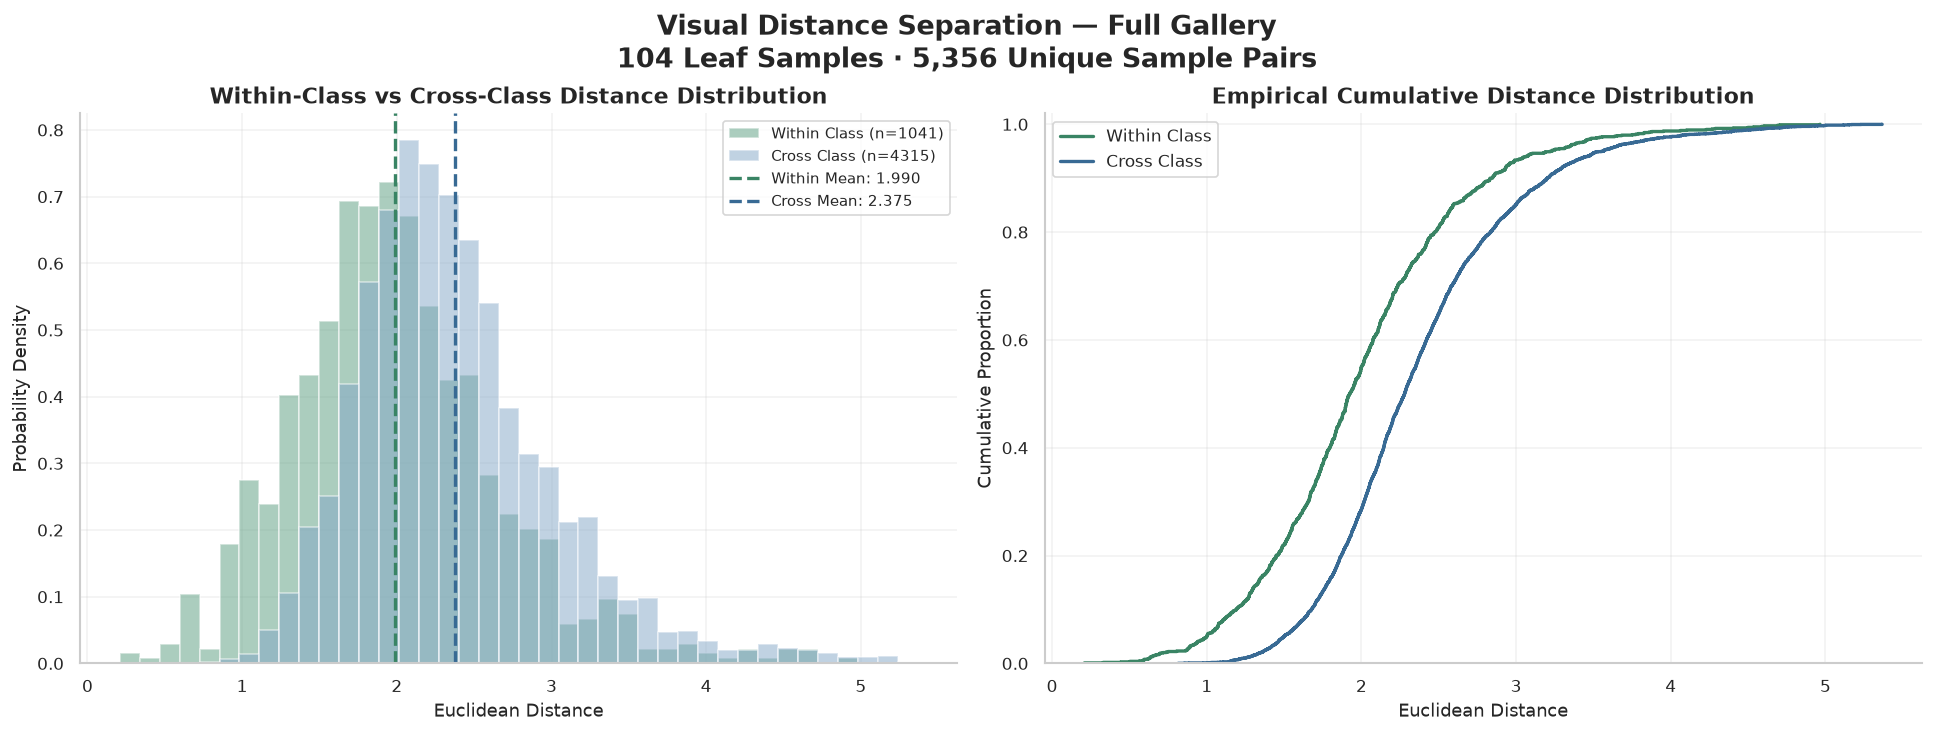

[SAVED] 114_visual_distance_within_cross_distributions.png


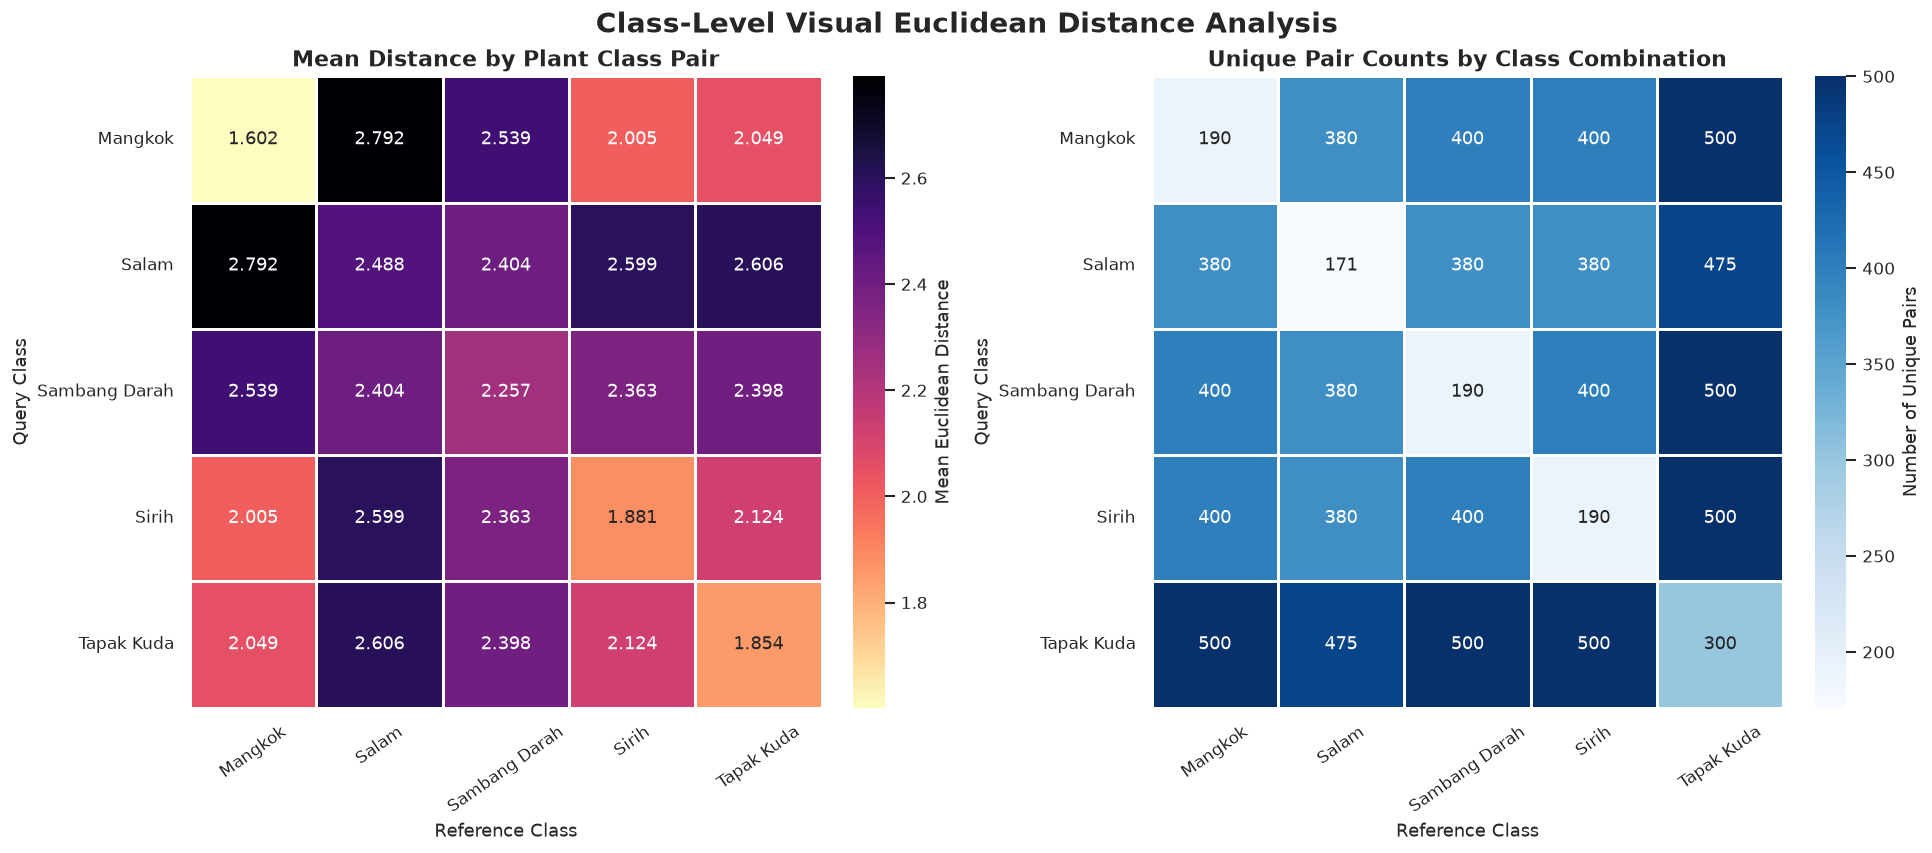

[SAVED] 115_visual_distance_class_pair_heatmaps.png


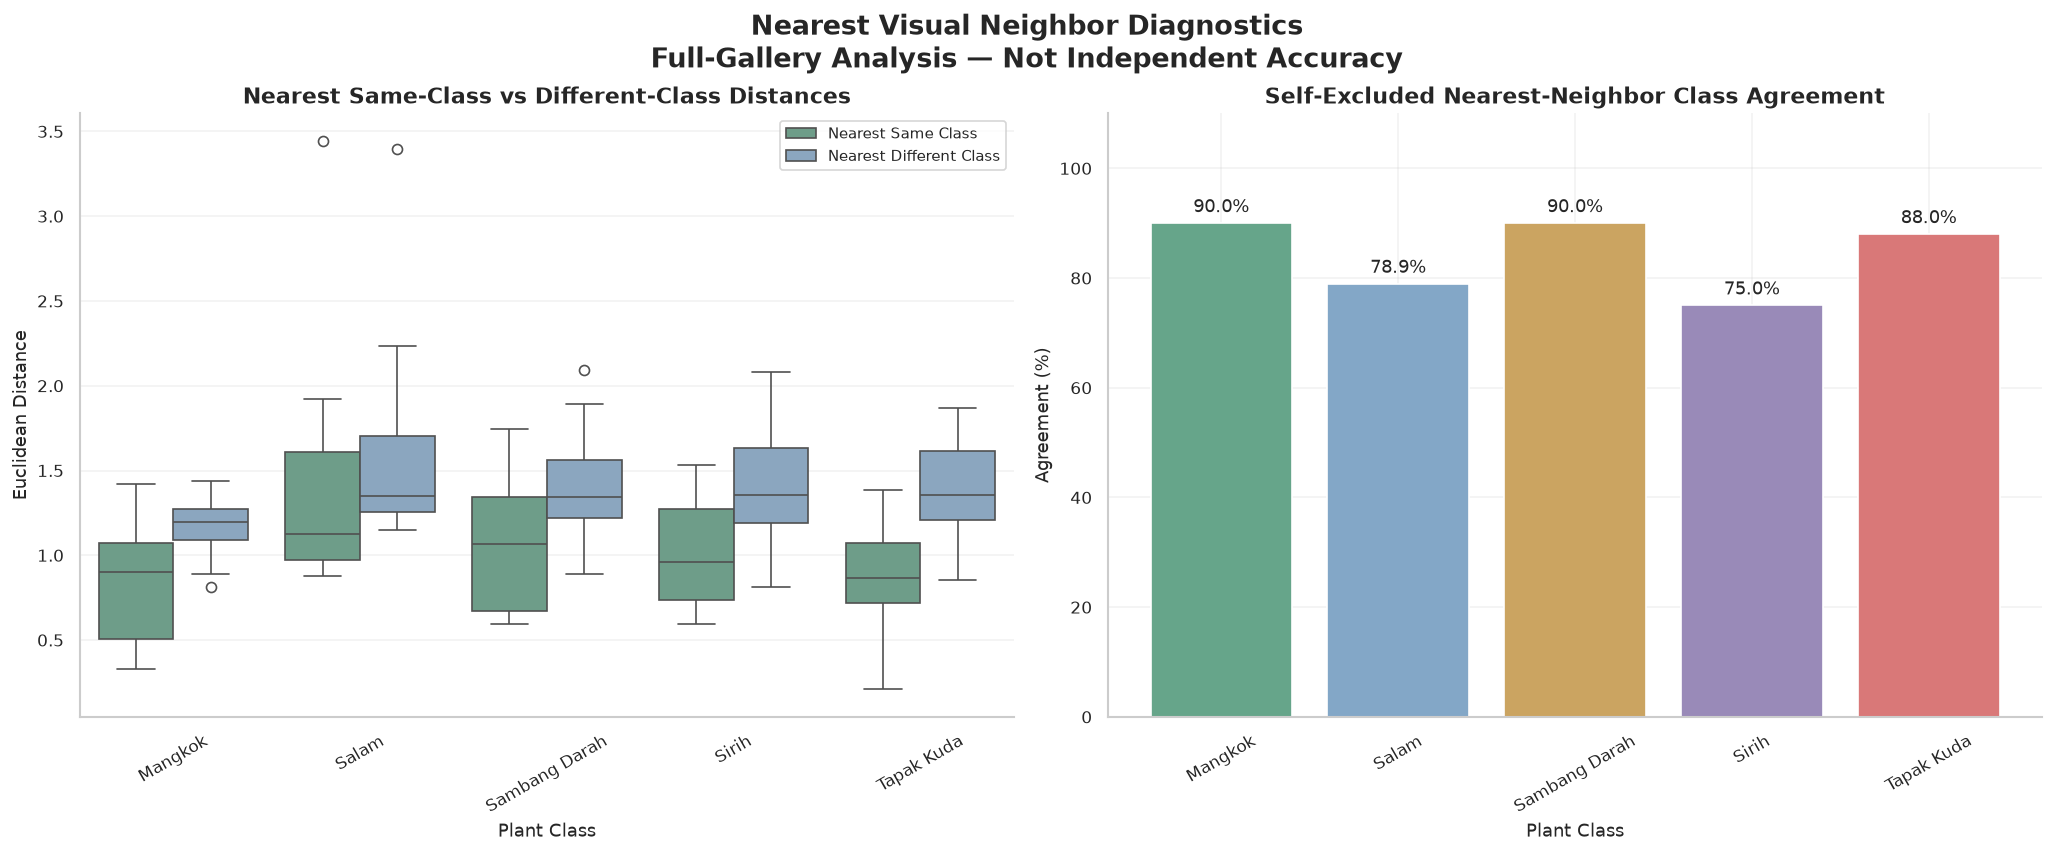

[SAVED] 116_visual_distance_nearest_neighbor_diagnostics.png


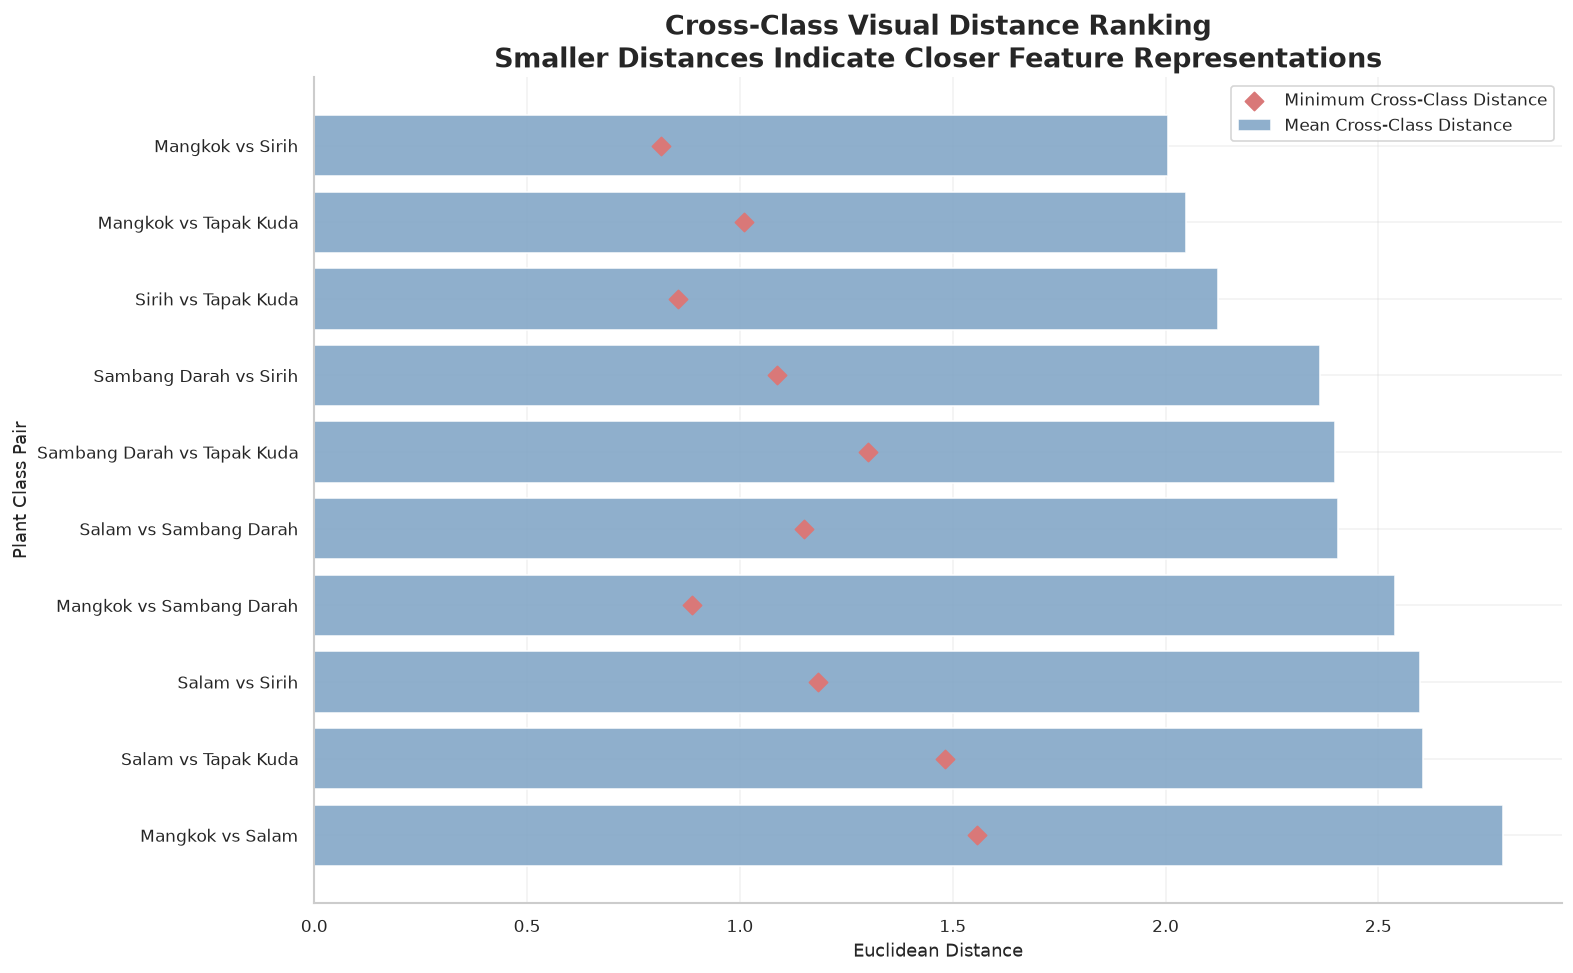

[SAVED] 117_visual_distance_cross_class_ranking.png

9. FINAL VISUAL DISTANCE ANALYSIS SUMMARY
----------------------------------------------------------------------


,Indicator,Result
0,Input distance matrix,"(104, 104)"
1,Samples,104
2,Classes,5
3,Unique sample pairs,5356
4,Within-class pairs,1041
5,Cross-class pairs,4315
6,Mean within-class distance,1.990486
7,Mean cross-class distance,2.375002
8,Cross-minus-within mean gap,0.384516
9,Standardized mean separation,0.58414



10. SAVING DISTANCE ANALYSIS REPORTS
----------------------------------------------------------------------
[SAVED] 397_visual_distance_distribution_summary.csv
[SAVED] 398_visual_distance_class_pair_summary.csv
[SAVED] 399_visual_distance_class_mean_matrix.csv
[SAVED] 400_visual_distance_class_count_matrix.csv
[SAVED] 401_visual_distance_separation_diagnostics.csv
[SAVED] 402_visual_distance_per_query_neighbors.csv
[SAVED] 403_visual_distance_nearest_class_summary.csv
[SAVED] 404_visual_distance_closest_cross_class_pairs.csv
[SAVED] 405_visual_distance_analysis_validation.csv
[SAVED] 406_visual_distance_analysis_summary.csv

FINAL VISUAL DISTANCE ANALYSIS SUMMARY

PAIR STATISTICS
----------------------------------------------------------------------
Unique pairs       : 5356
Within-class pairs : 1041
Cross-class pairs  : 4315

DISTANCE SEPARATION
----------------------------------------------------------------------
Within-class mean : 1.990486
Cross-class mean  : 2.375002
Mean dista

In [11]:
# ============================================================
# CELL 9 - VISUAL DISTANCE ANALYSIS
# ============================================================

print("MULTIMODAL FUSION - VISUAL DISTANCE ANALYSIS")
print("=" * 70)

VISUAL_DISTANCE_ANALYSIS_COMPLETED = False


# ============================================================
# 1. VALIDATE PREVIOUS STAGES
# ============================================================

required_stages = [
    "FUSION_LIBRARIES_IMPORTED",
    "FUSION_PATH_CONFIGURATION_COMPLETED",
    "VISUAL_FEATURE_LOADING_COMPLETED",
    "TEXT_FEATURE_LOADING_COMPLETED",
    "MULTIMODAL_DATASET_VALIDATION_COMPLETED",
    "FUSION_CONFIGURATION_COMPLETED",
    "VISUAL_DISTANCE_CALCULATION_COMPLETED"
]

for stage in required_stages:
    assert globals().get(stage, False), (
        f"{stage} has not been completed."
    )

assert visual_euclidean_distance_validation_df[
    "passed"
].all()

assert np.array_equal(
    visual_distance_sample_ids,
    multimodal_sample_ids
)

assert np.array_equal(
    visual_distance_labels,
    multimodal_labels
)

print("[PASS] Previous stages validated.")


# ============================================================
# 2. ANALYSIS CONFIGURATION
# ============================================================

VISUAL_ANALYSIS_TOLERANCE = 1e-10
VISUAL_ANALYSIS_EXPECTED_SAMPLES = 104
VISUAL_ANALYSIS_EXPECTED_PAIRS = 5356

VISUAL_ANALYSIS_HISTOGRAM_BINS = 40
VISUAL_ANALYSIS_CLOSEST_PAIRS = 15

VISUAL_ANALYSIS_SCOPE = (
    "Full-Gallery Exploratory Distance Analysis"
)

visual_analysis_checks = []
visual_analysis_figure_paths = []


def register_visual_analysis_check(
    category,
    name,
    condition
):
    visual_analysis_checks.append({
        "category": category,
        "validation_check": name,
        "passed": bool(condition),
        "status": (
            "Passed" if condition else "Failed"
        )
    })


def save_visual_analysis_figure(fig, filename):

    output_path = FUSION_FIGURES_DIR / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    visual_analysis_figure_paths.append(output_path)

    plt.show()
    plt.close(fig)

    print(f"[SAVED] {filename}")


def describe_visual_distances(values, group_name):

    values = np.asarray(
        values,
        dtype=np.float64
    )

    assert values.ndim == 1
    assert values.size > 0
    assert np.isfinite(values).all()

    return {
        "group": group_name,
        "number_of_pairs": int(values.size),
        "minimum_distance": float(values.min()),
        "maximum_distance": float(values.max()),
        "mean_distance": float(values.mean()),
        "median_distance": float(np.median(values)),
        "std_distance": float(values.std(ddof=0)),
        "q10_distance": float(np.quantile(values, 0.10)),
        "q25_distance": float(np.quantile(values, 0.25)),
        "q75_distance": float(np.quantile(values, 0.75)),
        "q90_distance": float(np.quantile(values, 0.90)),
        "zero_distance_pairs": int(
            (values <= VISUAL_ANALYSIS_TOLERANCE).sum()
        )
    }


print("\n1. ANALYSIS CONFIGURATION")
print("-" * 70)

print("Samples :", VISUAL_ANALYSIS_EXPECTED_SAMPLES)
print("Pairs   :", VISUAL_ANALYSIS_EXPECTED_PAIRS)
print("Scope   :", VISUAL_ANALYSIS_SCOPE)
print("Self-matches excluded: True")


# ============================================================
# 3. PREPARE DISTANCE MATRIX AND PAIR INDICES
# ============================================================

# Reuse the distance matrix calculated in Cell 8.
# Do not recalculate the feature representation.

visual_analysis_distance_matrix = np.asarray(
    visual_euclidean_distance_matrix,
    dtype=np.float64
)

visual_analysis_sample_ids = np.asarray(
    visual_distance_sample_ids,
    dtype=str
)

visual_analysis_labels = np.asarray(
    visual_distance_labels,
    dtype=str
)

visual_analysis_n_samples = len(
    visual_analysis_sample_ids
)

assert visual_analysis_distance_matrix.shape == (
    104, 104
)

assert visual_analysis_n_samples == 104

assert np.isfinite(
    visual_analysis_distance_matrix
).all()

assert np.allclose(
    visual_analysis_distance_matrix,
    visual_analysis_distance_matrix.T,
    atol=VISUAL_ANALYSIS_TOLERANCE,
    rtol=0
)

assert np.allclose(
    np.diag(visual_analysis_distance_matrix),
    0.0,
    atol=VISUAL_ANALYSIS_TOLERANCE,
    rtol=0
)

# Unique unordered pairs, excluding the diagonal.

analysis_pair_i, analysis_pair_j = np.triu_indices(
    visual_analysis_n_samples,
    k=1
)

analysis_pair_distances = (
    visual_analysis_distance_matrix[
        analysis_pair_i,
        analysis_pair_j
    ]
)

analysis_within_mask = (
    visual_analysis_labels[analysis_pair_i]
    == visual_analysis_labels[analysis_pair_j]
)

analysis_within_distances = (
    analysis_pair_distances[
        analysis_within_mask
    ]
)

analysis_cross_distances = (
    analysis_pair_distances[
        ~analysis_within_mask
    ]
)

register_visual_analysis_check(
    "Input Integrity",
    "Distance matrix shape valid",
    visual_analysis_distance_matrix.shape == (104, 104)
)

register_visual_analysis_check(
    "Input Integrity",
    "Distance matrix finite and nonnegative",
    np.isfinite(visual_analysis_distance_matrix).all()
    and np.all(
        visual_analysis_distance_matrix
        >= -VISUAL_ANALYSIS_TOLERANCE
    )
)

register_visual_analysis_check(
    "Input Integrity",
    "Diagonal distances zero",
    np.allclose(
        np.diag(visual_analysis_distance_matrix),
        0.0,
        atol=VISUAL_ANALYSIS_TOLERANCE,
        rtol=0
    )
)

register_visual_analysis_check(
    "Input Integrity",
    "Distance matrix symmetric",
    np.allclose(
        visual_analysis_distance_matrix,
        visual_analysis_distance_matrix.T,
        atol=VISUAL_ANALYSIS_TOLERANCE,
        rtol=0
    )
)

register_visual_analysis_check(
    "Input Integrity",
    "Previous unique-pair distances preserved",
    np.array_equal(
        analysis_pair_distances,
        visual_unique_pair_distances
    )
)

register_visual_analysis_check(
    "Input Integrity",
    "Previous pair class masks preserved",
    np.array_equal(
        analysis_within_mask,
        visual_same_class_pair_mask
    )
)

assert len(analysis_pair_distances) == 5356
assert len(analysis_within_distances) == 1041
assert len(analysis_cross_distances) == 4315

print("\n2. DISTANCE PAIR INVENTORY")
print("-" * 70)

print("Total unique pairs :", len(analysis_pair_distances))
print("Within-class pairs:", len(analysis_within_distances))
print("Cross-class pairs :", len(analysis_cross_distances))


# ============================================================
# 4. GLOBAL DISTANCE DISTRIBUTION SUMMARY
# ============================================================

visual_distance_distribution_summary_df = pd.DataFrame([
    describe_visual_distances(
        analysis_pair_distances,
        "All Unique Pairs"
    ),
    describe_visual_distances(
        analysis_within_distances,
        "Within Class"
    ),
    describe_visual_distances(
        analysis_cross_distances,
        "Cross Class"
    )
])

within_mean = float(
    analysis_within_distances.mean()
)

cross_mean = float(
    analysis_cross_distances.mean()
)

within_std = float(
    analysis_within_distances.std(ddof=0)
)

cross_std = float(
    analysis_cross_distances.std(ddof=0)
)

# A positive gap indicates that cross-class pairs
# have a larger average distance.

visual_distance_mean_gap = (
    cross_mean - within_mean
)

pooled_descriptive_std = np.sqrt(
    (
        within_std ** 2
        + cross_std ** 2
    ) / 2
)

visual_distance_standardized_separation = (
    visual_distance_mean_gap / pooled_descriptive_std
    if pooled_descriptive_std > 0
    else np.nan
)

print("\n3. GLOBAL DISTANCE DISTRIBUTIONS")
print("-" * 70)

display(
    visual_distance_distribution_summary_df.round(6)
)

print(f"Within-class mean : {within_mean:.6f}")
print(f"Cross-class mean  : {cross_mean:.6f}")
print(
    "Cross-minus-within gap:",
    f"{visual_distance_mean_gap:.6f}"
)

if visual_distance_mean_gap > 0:
    print(
        "[OBSERVATION] Mean within-class distance "
        "is smaller than mean cross-class distance."
    )
elif visual_distance_mean_gap < 0:
    print(
        "[OBSERVATION] Mean within-class distance "
        "is larger than mean cross-class distance."
    )
else:
    print(
        "[OBSERVATION] Both distance means are equal."
    )


# ============================================================
# 5. EMPIRICAL DISTRIBUTION SEPARATION
# ============================================================

# Evaluate empirical pairwise separation:
#
# P(D_within < D_cross)
# + 0.5 * P(D_within == D_cross)
#
# This compares distances from the full gallery.
# It is a descriptive measure, not independent AUC.
#
# Use searchsorted instead of a large broadcast matrix.

sorted_cross_distances = np.sort(
    analysis_cross_distances
)

left_positions = np.searchsorted(
    sorted_cross_distances,
    analysis_within_distances,
    side="left"
)

right_positions = np.searchsorted(
    sorted_cross_distances,
    analysis_within_distances,
    side="right"
)

# Cross-class distances strictly greater than
# each within-class distance.

strictly_greater_counts = (
    len(sorted_cross_distances) - right_positions
)

# Exact numerical ties receive half credit.

tie_counts = (
    right_positions - left_positions
)

possible_pair_comparisons = (
    len(analysis_within_distances)
    * len(analysis_cross_distances)
)

visual_distance_pairwise_separation_rate = float(
    (
        strictly_greater_counts.sum()
        + 0.5 * tie_counts.sum()
    )
    / possible_pair_comparisons
)

cross_median = float(
    np.median(analysis_cross_distances)
)

within_median = float(
    np.median(analysis_within_distances)
)

within_below_cross_median_percent = float(
    100 * np.mean(
        analysis_within_distances < cross_median
    )
)

cross_above_within_median_percent = float(
    100 * np.mean(
        analysis_cross_distances > within_median
    )
)

within_q75 = float(
    np.quantile(analysis_within_distances, 0.75)
)

cross_q25 = float(
    np.quantile(analysis_cross_distances, 0.25)
)

# Overlapping central 50% ranges indicate that
# the two distributions are not cleanly separated.

central_ranges_overlap = bool(
    within_q75 >= cross_q25
    and np.quantile(
        analysis_within_distances, 0.25
    ) <= np.quantile(
        analysis_cross_distances, 0.75
    )
)

visual_distance_separation_diagnostics_df = pd.DataFrame([{
    "within_class_mean": within_mean,
    "cross_class_mean": cross_mean,
    "cross_minus_within_mean_gap":
        visual_distance_mean_gap,
    "standardized_mean_separation":
        visual_distance_standardized_separation,
    "within_class_median": within_median,
    "cross_class_median": cross_median,
    "within_q75": within_q75,
    "cross_q25": cross_q25,
    "central_50_percent_ranges_overlap":
        central_ranges_overlap,
    "pairwise_separation_rate":
        visual_distance_pairwise_separation_rate,
    "pairwise_separation_percent":
        visual_distance_pairwise_separation_rate * 100,
    "within_below_cross_median_percent":
        within_below_cross_median_percent,
    "cross_above_within_median_percent":
        cross_above_within_median_percent,
    "unique_pair_comparisons":
        int(possible_pair_comparisons),
    "independent_evaluation": False
}])

register_visual_analysis_check(
    "Distribution Analysis",
    "Empirical separation rate within valid bounds",
    0 <= visual_distance_pairwise_separation_rate <= 1
)

register_visual_analysis_check(
    "Distribution Analysis",
    "Global pair distributions reconcile",
    len(analysis_within_distances)
    + len(analysis_cross_distances)
    == len(analysis_pair_distances)
)

register_visual_analysis_check(
    "Distribution Analysis",
    "Global distance means finite",
    np.isfinite([within_mean, cross_mean]).all()
)

print("\n4. DISTRIBUTION SEPARATION DIAGNOSTICS")
print("-" * 70)

display(
    visual_distance_separation_diagnostics_df.T
)


# ============================================================
# 6. ANALYZE DISTANCES FOR EACH CLASS PAIR
# ============================================================

visual_analysis_classes = sorted(
    np.unique(visual_analysis_labels)
)

visual_analysis_n_classes = len(
    visual_analysis_classes
)

visual_class_pair_records = []

visual_class_mean_distance_matrix = np.zeros(
    (
        visual_analysis_n_classes,
        visual_analysis_n_classes
    ),
    dtype=np.float64
)

visual_class_median_distance_matrix = np.zeros_like(
    visual_class_mean_distance_matrix
)

visual_class_pair_count_matrix = np.zeros(
    visual_class_mean_distance_matrix.shape,
    dtype=np.int64
)

for class_i_index, class_i in enumerate(
    visual_analysis_classes
):

    for class_j_index in range(
        class_i_index,
        visual_analysis_n_classes
    ):

        class_j = visual_analysis_classes[
            class_j_index
        ]

        if class_i == class_j:

            pair_mask = (
                (visual_analysis_labels[analysis_pair_i] == class_i)
                &
                (visual_analysis_labels[analysis_pair_j] == class_i)
            )

            pair_type = "Within Class"

        else:

            pair_mask = (
                (
                    (visual_analysis_labels[analysis_pair_i] == class_i)
                    &
                    (visual_analysis_labels[analysis_pair_j] == class_j)
                )
                |
                (
                    (visual_analysis_labels[analysis_pair_i] == class_j)
                    &
                    (visual_analysis_labels[analysis_pair_j] == class_i)
                )
            )

            pair_type = "Cross Class"

        class_pair_distances = (
            analysis_pair_distances[pair_mask]
        )

        assert class_pair_distances.size > 0

        count_i = int(
            (visual_analysis_labels == class_i).sum()
        )

        count_j = int(
            (visual_analysis_labels == class_j).sum()
        )

        expected_pairs = (
            count_i * (count_i - 1) // 2
            if class_i == class_j
            else count_i * count_j
        )

        assert len(class_pair_distances) == expected_pairs

        mean_value = float(
            class_pair_distances.mean()
        )

        median_value = float(
            np.median(class_pair_distances)
        )

        visual_class_pair_records.append({
            "class_i": class_i,
            "class_j": class_j,
            "pair_type": pair_type,
            "number_of_pairs": len(class_pair_distances),
            "expected_pairs": expected_pairs,
            "minimum_distance": float(
                class_pair_distances.min()
            ),
            "maximum_distance": float(
                class_pair_distances.max()
            ),
            "mean_distance": mean_value,
            "median_distance": median_value,
            "std_distance": float(
                class_pair_distances.std(ddof=0)
            ),
            "q25_distance": float(
                np.quantile(class_pair_distances, 0.25)
            ),
            "q75_distance": float(
                np.quantile(class_pair_distances, 0.75)
            ),
            "near_zero_pairs": int(
                (
                    class_pair_distances
                    <= VISUAL_ANALYSIS_TOLERANCE
                ).sum()
            )
        })

        visual_class_mean_distance_matrix[
            class_i_index,
            class_j_index
        ] = mean_value

        visual_class_mean_distance_matrix[
            class_j_index,
            class_i_index
        ] = mean_value

        visual_class_median_distance_matrix[
            class_i_index,
            class_j_index
        ] = median_value

        visual_class_median_distance_matrix[
            class_j_index,
            class_i_index
        ] = median_value

        visual_class_pair_count_matrix[
            class_i_index,
            class_j_index
        ] = len(class_pair_distances)

        visual_class_pair_count_matrix[
            class_j_index,
            class_i_index
        ] = len(class_pair_distances)


visual_distance_class_pair_summary_df = pd.DataFrame(
    visual_class_pair_records
)

visual_distance_class_mean_matrix_df = pd.DataFrame(
    visual_class_mean_distance_matrix,
    index=visual_analysis_classes,
    columns=visual_analysis_classes
)

visual_distance_class_median_matrix_df = pd.DataFrame(
    visual_class_median_distance_matrix,
    index=visual_analysis_classes,
    columns=visual_analysis_classes
)

visual_distance_class_count_matrix_df = pd.DataFrame(
    visual_class_pair_count_matrix,
    index=visual_analysis_classes,
    columns=visual_analysis_classes
)

within_class_pair_total = int(
    visual_distance_class_pair_summary_df.loc[
        visual_distance_class_pair_summary_df[
            "pair_type"
        ].eq("Within Class"),
        "number_of_pairs"
    ].sum()
)

cross_class_pair_total = int(
    visual_distance_class_pair_summary_df.loc[
        visual_distance_class_pair_summary_df[
            "pair_type"
        ].eq("Cross Class"),
        "number_of_pairs"
    ].sum()
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Five within-class combinations",
    (
        visual_distance_class_pair_summary_df[
            "pair_type"
        ] == "Within Class"
    ).sum() == 5
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Ten cross-class combinations",
    (
        visual_distance_class_pair_summary_df[
            "pair_type"
        ] == "Cross Class"
    ).sum() == 10
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Class-pair counts reconcile",
    within_class_pair_total == 1041
    and cross_class_pair_total == 4315
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Class mean matrix symmetric",
    np.allclose(
        visual_class_mean_distance_matrix,
        visual_class_mean_distance_matrix.T,
        atol=VISUAL_ANALYSIS_TOLERANCE,
        rtol=0
    )
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Class median matrix symmetric",
    np.allclose(
        visual_class_median_distance_matrix,
        visual_class_median_distance_matrix.T,
        atol=VISUAL_ANALYSIS_TOLERANCE,
        rtol=0
    )
)

register_visual_analysis_check(
    "Class Pair Analysis",
    "Class-pair distance statistics finite",
    np.isfinite(
        visual_distance_class_pair_summary_df[
            [
                "minimum_distance",
                "maximum_distance",
                "mean_distance",
                "median_distance"
            ]
        ].to_numpy()
    ).all()
)

print("\n5. CLASS-PAIR DISTANCE ANALYSIS")
print("-" * 70)

display(
    visual_distance_class_pair_summary_df[
        [
            "class_i",
            "class_j",
            "pair_type",
            "number_of_pairs",
            "mean_distance",
            "median_distance",
            "minimum_distance"
        ]
    ].round(6)
)

print("\nClass Mean Distance Matrix")

display(
    visual_distance_class_mean_matrix_df.round(4)
)


# ============================================================
# 7. PER-QUERY NEAREST-NEIGHBOR DIAGNOSTICS
# ============================================================

# For every sample, locate:
#
# 1. Nearest overall non-self sample
# 2. Nearest same-class non-self sample
# 3. Nearest different-class sample
#
# This is a full-gallery descriptive diagnostic.
# It is not independent retrieval evaluation.

visual_nearest_neighbor_records = []

for query_index in range(visual_analysis_n_samples):

    query_id = visual_analysis_sample_ids[
        query_index
    ]

    query_class = visual_analysis_labels[
        query_index
    ]

    candidate_indices = np.arange(
        visual_analysis_n_samples
    )

    candidate_indices = candidate_indices[
        candidate_indices != query_index
    ]

    candidate_distances = (
        visual_analysis_distance_matrix[
            query_index,
            candidate_indices
        ]
    )

    candidate_order = np.lexsort((
        visual_analysis_sample_ids[
            candidate_indices
        ],
        candidate_distances
    ))

    ranked_candidates = candidate_indices[
        candidate_order
    ]

    nearest_overall_index = int(
        ranked_candidates[0]
    )

    same_class_candidates = candidate_indices[
        visual_analysis_labels[candidate_indices]
        == query_class
    ]

    different_class_candidates = candidate_indices[
        visual_analysis_labels[candidate_indices]
        != query_class
    ]

    assert len(same_class_candidates) > 0
    assert len(different_class_candidates) > 0

    same_order = np.lexsort((
        visual_analysis_sample_ids[
            same_class_candidates
        ],
        visual_analysis_distance_matrix[
            query_index,
            same_class_candidates
        ]
    ))

    different_order = np.lexsort((
        visual_analysis_sample_ids[
            different_class_candidates
        ],
        visual_analysis_distance_matrix[
            query_index,
            different_class_candidates
        ]
    ))

    nearest_same_index = int(
        same_class_candidates[same_order[0]]
    )

    nearest_different_index = int(
        different_class_candidates[different_order[0]]
    )

    nearest_overall_distance = float(
        visual_analysis_distance_matrix[
            query_index,
            nearest_overall_index
        ]
    )

    nearest_same_distance = float(
        visual_analysis_distance_matrix[
            query_index,
            nearest_same_index
        ]
    )

    nearest_different_distance = float(
        visual_analysis_distance_matrix[
            query_index,
            nearest_different_index
        ]
    )

    # Positive margin: same-class nearest neighbor
    # lies closer than the nearest different-class
    # sample.

    nearest_distance_margin = (
        nearest_different_distance
        - nearest_same_distance
    )

    nearest_agrees = (
        visual_analysis_labels[
            nearest_overall_index
        ] == query_class
    )

    visual_nearest_neighbor_records.append({
        "query_index": query_index,
        "query_sample_id": query_id,
        "query_class": query_class,
        "nearest_sample_id":
            visual_analysis_sample_ids[
                nearest_overall_index
            ],
        "nearest_sample_class":
            visual_analysis_labels[
                nearest_overall_index
            ],
        "nearest_distance":
            nearest_overall_distance,
        "nearest_same_class_sample_id":
            visual_analysis_sample_ids[
                nearest_same_index
            ],
        "nearest_same_class_distance":
            nearest_same_distance,
        "nearest_different_class_sample_id":
            visual_analysis_sample_ids[
                nearest_different_index
            ],
        "nearest_different_class":
            visual_analysis_labels[
                nearest_different_index
            ],
        "nearest_different_class_distance":
            nearest_different_distance,
        "distance_margin_different_minus_same":
            nearest_distance_margin,
        "nearest_neighbor_same_class":
            bool(nearest_agrees),
        "strict_positive_margin":
            bool(
                nearest_distance_margin
                > VISUAL_ANALYSIS_TOLERANCE
            ),
        "self_match_excluded":
            bool(
                nearest_overall_index != query_index
            )
    })


visual_distance_per_query_neighbors_df = pd.DataFrame(
    visual_nearest_neighbor_records
)

visual_distance_nearest_class_summary_df = (
    visual_distance_per_query_neighbors_df
    .groupby("query_class", sort=True)
    .agg(
        number_of_queries=(
            "query_sample_id", "count"
        ),
        nearest_same_class_count=(
            "nearest_neighbor_same_class", "sum"
        ),
        nearest_neighbor_same_class_rate=(
            "nearest_neighbor_same_class", "mean"
        ),
        mean_nearest_distance=(
            "nearest_distance", "mean"
        ),
        mean_nearest_same_distance=(
            "nearest_same_class_distance", "mean"
        ),
        mean_nearest_different_distance=(
            "nearest_different_class_distance", "mean"
        ),
        mean_distance_margin=(
            "distance_margin_different_minus_same", "mean"
        ),
        median_distance_margin=(
            "distance_margin_different_minus_same", "median"
        )
    )
    .reset_index()
)

visual_distance_nearest_class_summary_df[
    "nearest_neighbor_same_class_rate_percent"
] = (
    visual_distance_nearest_class_summary_df[
        "nearest_neighbor_same_class_rate"
    ] * 100
)

visual_nearest_class_agreement_percent = float(
    100
    * visual_distance_per_query_neighbors_df[
        "nearest_neighbor_same_class"
    ].mean()
)

visual_positive_margin_count = int(
    visual_distance_per_query_neighbors_df[
        "strict_positive_margin"
    ].sum()
)

register_visual_analysis_check(
    "Nearest Neighbors",
    "One diagnostic row per sample",
    len(visual_distance_per_query_neighbors_df)
    == visual_analysis_n_samples
)

register_visual_analysis_check(
    "Nearest Neighbors",
    "All self-matches excluded",
    visual_distance_per_query_neighbors_df[
        "self_match_excluded"
    ].all()
)

register_visual_analysis_check(
    "Nearest Neighbors",
    "All nearest distances finite",
    np.isfinite(
        visual_distance_per_query_neighbors_df[
            [
                "nearest_distance",
                "nearest_same_class_distance",
                "nearest_different_class_distance",
                "distance_margin_different_minus_same"
            ]
        ].to_numpy()
    ).all()
)

register_visual_analysis_check(
    "Nearest Neighbors",
    "Class query counts reconcile",
    visual_distance_nearest_class_summary_df[
        "number_of_queries"
    ].sum() == visual_analysis_n_samples
)

register_visual_analysis_check(
    "Nearest Neighbors",
    "Global nearest class agreement in valid range",
    0 <= visual_nearest_class_agreement_percent <= 100
)

print("\n6. PER-QUERY NEAREST NEIGHBOR ANALYSIS")
print("-" * 70)

print(
    "Overall nearest-neighbor class agreement:",
    f"{visual_nearest_class_agreement_percent:.2f}%"
)

print(
    "Samples with strictly positive distance margin:",
    visual_positive_margin_count
)

display(
    visual_distance_nearest_class_summary_df[
        [
            "query_class",
            "number_of_queries",
            "nearest_neighbor_same_class_rate_percent",
            "mean_nearest_same_distance",
            "mean_nearest_different_distance",
            "mean_distance_margin"
        ]
    ].round(6)
)


# ============================================================
# 8. IDENTIFY CLOSEST CROSS-CLASS SAMPLE PAIRS
# ============================================================

cross_pair_i = analysis_pair_i[
    ~analysis_within_mask
]

cross_pair_j = analysis_pair_j[
    ~analysis_within_mask
]

cross_pair_distances = analysis_pair_distances[
    ~analysis_within_mask
]

# Sort by distance ascending.
# Resolve exact distance ties deterministically
# with both sample IDs.

cross_pair_order = np.lexsort((
    visual_analysis_sample_ids[cross_pair_j],
    visual_analysis_sample_ids[cross_pair_i],
    cross_pair_distances
))

closest_cross_order = cross_pair_order[
    :VISUAL_ANALYSIS_CLOSEST_PAIRS
]

visual_closest_cross_class_records = []

for rank, pair_position in enumerate(
    closest_cross_order,
    start=1
):

    i = int(cross_pair_i[pair_position])
    j = int(cross_pair_j[pair_position])

    visual_closest_cross_class_records.append({
        "rank": rank,
        "sample_id_i": visual_analysis_sample_ids[i],
        "sample_id_j": visual_analysis_sample_ids[j],
        "class_i": visual_analysis_labels[i],
        "class_j": visual_analysis_labels[j],
        "euclidean_distance": float(
            visual_analysis_distance_matrix[i, j]
        ),
        "different_classes": bool(
            visual_analysis_labels[i]
            != visual_analysis_labels[j]
        ),
        "self_match_excluded": bool(i != j)
    })


visual_distance_closest_cross_class_df = pd.DataFrame(
    visual_closest_cross_class_records
)

register_visual_analysis_check(
    "Closest Cross-Class Pairs",
    "Expected number of closest cross-class pairs",
    len(visual_distance_closest_cross_class_df)
    == VISUAL_ANALYSIS_CLOSEST_PAIRS
)

register_visual_analysis_check(
    "Closest Cross-Class Pairs",
    "All selected pairs are cross-class",
    visual_distance_closest_cross_class_df[
        "different_classes"
    ].all()
)

register_visual_analysis_check(
    "Closest Cross-Class Pairs",
    "Closest cross-class pairs sorted ascending",
    np.all(
        np.diff(
            visual_distance_closest_cross_class_df[
                "euclidean_distance"
            ].to_numpy()
        ) >= -VISUAL_ANALYSIS_TOLERANCE
    )
)

register_visual_analysis_check(
    "Closest Cross-Class Pairs",
    "No repeated closest-pair records",
    not visual_distance_closest_cross_class_df[
        ["sample_id_i", "sample_id_j"]
    ].duplicated().any()
)

print("\n7. CLOSEST CROSS-CLASS SAMPLE PAIRS")
print("-" * 70)

display(
    visual_distance_closest_cross_class_df.round(6)
)


# ============================================================
# 9. FINAL ANALYSIS VALIDATION
# ============================================================

visual_distance_analysis_validation_df = pd.DataFrame(
    visual_analysis_checks
)

visual_analysis_total_checks = len(
    visual_distance_analysis_validation_df
)

visual_analysis_passed_checks = int(
    visual_distance_analysis_validation_df[
        "passed"
    ].sum()
)

visual_analysis_failed_checks = (
    visual_analysis_total_checks
    - visual_analysis_passed_checks
)

print("\n8. VISUAL DISTANCE ANALYSIS VALIDATION")
print("-" * 70)

display(
    visual_distance_analysis_validation_df
)

# Save validation diagnostics before asserting.

visual_distance_analysis_validation_df.to_csv(
    METRICS_DIR / "405_visual_distance_analysis_validation.csv",
    index=False,
    encoding="utf-8-sig"
)

assert visual_distance_analysis_validation_df[
    "passed"
].all(), (
    visual_distance_analysis_validation_df.loc[
        ~visual_distance_analysis_validation_df["passed"]
    ].to_string(index=False)
)

print("[PASS] All distance analysis checks passed.")


# ============================================================
# 10. FIGURE 114 - WITHIN VS CROSS DISTRIBUTIONS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6),
    constrained_layout=True
)

plot_bins = np.histogram_bin_edges(
    analysis_pair_distances,
    bins=VISUAL_ANALYSIS_HISTOGRAM_BINS
)

# A. Normalized distance histograms.

axes[0].hist(
    analysis_within_distances,
    bins=plot_bins,
    density=True,
    color="#66A58A",
    alpha=0.55,
    label=f"Within Class (n={len(analysis_within_distances)})"
)

axes[0].hist(
    analysis_cross_distances,
    bins=plot_bins,
    density=True,
    color="#83A7C7",
    alpha=0.50,
    label=f"Cross Class (n={len(analysis_cross_distances)})"
)

axes[0].axvline(
    within_mean,
    color="#398464",
    linestyle="--",
    linewidth=2,
    label=f"Within Mean: {within_mean:.3f}"
)

axes[0].axvline(
    cross_mean,
    color="#386A94",
    linestyle="--",
    linewidth=2,
    label=f"Cross Mean: {cross_mean:.3f}"
)

axes[0].set_title(
    "Within-Class vs Cross-Class Distance Distribution"
)

axes[0].set_xlabel("Euclidean Distance")
axes[0].set_ylabel("Probability Density")
axes[0].legend(fontsize=9)


# B. Empirical cumulative distribution.

def plot_distance_ecdf(ax, values, label, color):

    ordered = np.sort(values)

    cumulative = (
        np.arange(1, len(ordered) + 1)
        / len(ordered)
    )

    ax.step(
        ordered,
        cumulative,
        where="post",
        color=color,
        linewidth=2,
        label=label
    )


plot_distance_ecdf(
    axes[1],
    analysis_within_distances,
    "Within Class",
    "#398464"
)

plot_distance_ecdf(
    axes[1],
    analysis_cross_distances,
    "Cross Class",
    "#386A94"
)

axes[1].set_title(
    "Empirical Cumulative Distance Distribution"
)

axes[1].set_xlabel("Euclidean Distance")
axes[1].set_ylabel("Cumulative Proportion")
axes[1].set_ylim(0, 1.02)
axes[1].legend()

fig.suptitle(
    "Visual Distance Separation — Full Gallery\n"
    "104 Leaf Samples · 5,356 Unique Sample Pairs",
    fontsize=16,
    fontweight="bold"
)

save_visual_analysis_figure(
    fig,
    "114_visual_distance_within_cross_distributions.png"
)


# ============================================================
# 11. FIGURE 115 - CLASS-PAIR DISTANCE HEATMAPS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    constrained_layout=True
)

sns.heatmap(
    visual_distance_class_mean_matrix_df,
    annot=True,
    fmt=".3f",
    cmap=DISTANCE_CMAP,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Mean Euclidean Distance"},
    ax=axes[0]
)

axes[0].set_title(
    "Mean Distance by Plant Class Pair"
)

axes[0].set_xlabel("Reference Class")
axes[0].set_ylabel("Query Class")

sns.heatmap(
    visual_distance_class_count_matrix_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Number of Unique Pairs"},
    ax=axes[1]
)

axes[1].set_title(
    "Unique Pair Counts by Class Combination"
)

axes[1].set_xlabel("Reference Class")
axes[1].set_ylabel("Query Class")

for ax in axes:
    ax.tick_params(axis="x", rotation=35)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "Class-Level Visual Euclidean Distance Analysis",
    fontsize=17,
    fontweight="bold"
)

save_visual_analysis_figure(
    fig,
    "115_visual_distance_class_pair_heatmaps.png"
)


# ============================================================
# 12. FIGURE 116 - NEAREST NEIGHBOR DIAGNOSTICS
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7),
    constrained_layout=True
)

# A. Compare nearest same/different-class distances.

neighbor_plot_df = (
    visual_distance_per_query_neighbors_df[
        [
            "query_class",
            "nearest_same_class_distance",
            "nearest_different_class_distance"
        ]
    ]
    .melt(
        id_vars="query_class",
        var_name="neighbor_type",
        value_name="euclidean_distance"
    )
)

neighbor_plot_df["neighbor_type"] = (
    neighbor_plot_df["neighbor_type"].map({
        "nearest_same_class_distance":
            "Nearest Same Class",
        "nearest_different_class_distance":
            "Nearest Different Class"
    })
)

sns.boxplot(
    data=neighbor_plot_df,
    x="query_class",
    y="euclidean_distance",
    hue="neighbor_type",
    order=visual_analysis_classes,
    palette={
        "Nearest Same Class": "#66A58A",
        "Nearest Different Class": "#83A7C7"
    },
    showfliers=True,
    ax=axes[0]
)

axes[0].set_title(
    "Nearest Same-Class vs Different-Class Distances"
)

axes[0].set_xlabel("Plant Class")
axes[0].set_ylabel("Euclidean Distance")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title=None, fontsize=9)


# B. Nearest-neighbor class agreement by class.

class_agreement_values = (
    visual_distance_nearest_class_summary_df[
        "nearest_neighbor_same_class_rate_percent"
    ]
)

class_agreement_names = (
    visual_distance_nearest_class_summary_df[
        "query_class"
    ]
)

bars = axes[1].bar(
    class_agreement_names,
    class_agreement_values,
    color=[
        CLASS_COLORS.get(name, "#83A7C7")
        for name in class_agreement_names
    ]
)

axes[1].bar_label(
    bars,
    fmt="%.1f%%",
    padding=4
)

axes[1].set_ylim(0, 110)
axes[1].set_title(
    "Self-Excluded Nearest-Neighbor Class Agreement"
)

axes[1].set_xlabel("Plant Class")
axes[1].set_ylabel("Agreement (%)")
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle(
    "Nearest Visual Neighbor Diagnostics\n"
    "Full-Gallery Analysis — Not Independent Accuracy",
    fontsize=16,
    fontweight="bold"
)

save_visual_analysis_figure(
    fig,
    "116_visual_distance_nearest_neighbor_diagnostics.png"
)


# ============================================================
# 13. FIGURE 117 - CROSS-CLASS DISTANCE RANKING
# ============================================================

# Show the ten cross-class combinations sorted by
# their mean Euclidean distance (smallest first).

cross_class_plot_df = (
    visual_distance_class_pair_summary_df.loc[
        visual_distance_class_pair_summary_df[
            "pair_type"
        ].eq("Cross Class")
    ]
    .sort_values(
        ["mean_distance", "class_i", "class_j"],
        ascending=[True, True, True]
    )
    .reset_index(drop=True)
    .copy()
)

cross_class_plot_df["class_pair"] = (
    cross_class_plot_df["class_i"]
    + " vs "
    + cross_class_plot_df["class_j"]
)

fig, ax = plt.subplots(
    figsize=(13, 8),
    constrained_layout=True
)

positions = np.arange(
    len(cross_class_plot_df)
)

bars = ax.barh(
    positions,
    cross_class_plot_df["mean_distance"],
    color="#83A7C7",
    alpha=0.9,
    label="Mean Cross-Class Distance"
)

ax.scatter(
    cross_class_plot_df["minimum_distance"],
    positions,
    color="#D97878",
    marker="D",
    s=60,
    zorder=4,
    label="Minimum Cross-Class Distance"
)

ax.set_yticks(positions)
ax.set_yticklabels(
    cross_class_plot_df["class_pair"]
)

ax.invert_yaxis()

ax.set_xlabel("Euclidean Distance")
ax.set_ylabel("Plant Class Pair")

ax.set_title(
    "Cross-Class Visual Distance Ranking\n"
    "Smaller Distances Indicate Closer Feature Representations",
    fontsize=16,
    fontweight="bold"
)

ax.legend()

save_visual_analysis_figure(
    fig,
    "117_visual_distance_cross_class_ranking.png"
)


# ============================================================
# 14. FINAL ANALYSIS SUMMARY
# ============================================================

visual_distance_analysis_summary_df = pd.DataFrame([
    ("Input distance matrix",
     str(visual_analysis_distance_matrix.shape)),

    ("Samples",
     visual_analysis_n_samples),

    ("Classes",
     visual_analysis_n_classes),

    ("Unique sample pairs",
     len(analysis_pair_distances)),

    ("Within-class pairs",
     len(analysis_within_distances)),

    ("Cross-class pairs",
     len(analysis_cross_distances)),

    ("Mean within-class distance",
     within_mean),

    ("Mean cross-class distance",
     cross_mean),

    ("Cross-minus-within mean gap",
     visual_distance_mean_gap),

    ("Standardized mean separation",
     visual_distance_standardized_separation),

    ("Empirical pairwise separation rate",
     visual_distance_pairwise_separation_rate),

    ("Central distance ranges overlap",
     central_ranges_overlap),

    ("Class-pair combinations",
     len(visual_distance_class_pair_summary_df)),

    ("Nearest-neighbor diagnostic queries",
     len(visual_distance_per_query_neighbors_df)),

    ("Nearest-neighbor class agreement percent",
     visual_nearest_class_agreement_percent),

    ("Positive distance margins",
     visual_positive_margin_count),

    ("Closest cross-class pairs reported",
     len(visual_distance_closest_cross_class_df)),

    ("Technical validation checks",
     visual_analysis_total_checks),

    ("Passed validation checks",
     visual_analysis_passed_checks),

    ("Failed validation checks",
     visual_analysis_failed_checks),

    ("Generated figures",
     len(visual_analysis_figure_paths)),

    ("Original distance matrix modified",
     False),

    ("Self-matches included in statistics",
     False),

    ("Distance-to-similarity conversion applied",
     False),

    ("Multimodal fusion completed",
     False),

    ("Independent retrieval evaluation completed",
     False),

    ("Analysis scope",
     VISUAL_ANALYSIS_SCOPE)

], columns=["Indicator", "Result"])

print("\n9. FINAL VISUAL DISTANCE ANALYSIS SUMMARY")
print("-" * 70)

display(
    visual_distance_analysis_summary_df
)


# ============================================================
# 15. SAVE ANALYSIS REPORTS
# ============================================================

visual_distance_analysis_reports = {
    "397_visual_distance_distribution_summary.csv":
        visual_distance_distribution_summary_df,

    "398_visual_distance_class_pair_summary.csv":
        visual_distance_class_pair_summary_df,

    "399_visual_distance_class_mean_matrix.csv":
        visual_distance_class_mean_matrix_df,

    "400_visual_distance_class_count_matrix.csv":
        visual_distance_class_count_matrix_df,

    "401_visual_distance_separation_diagnostics.csv":
        visual_distance_separation_diagnostics_df,

    "402_visual_distance_per_query_neighbors.csv":
        visual_distance_per_query_neighbors_df,

    "403_visual_distance_nearest_class_summary.csv":
        visual_distance_nearest_class_summary_df,

    "404_visual_distance_closest_cross_class_pairs.csv":
        visual_distance_closest_cross_class_df,

    "405_visual_distance_analysis_validation.csv":
        visual_distance_analysis_validation_df,

    "406_visual_distance_analysis_summary.csv":
        visual_distance_analysis_summary_df
}

print("\n10. SAVING DISTANCE ANALYSIS REPORTS")
print("-" * 70)

for filename, dataframe in (
    visual_distance_analysis_reports.items()
):

    output_path = METRICS_DIR / filename

    dataframe.to_csv(
        output_path,
        index=True if filename.startswith(
            ("399_", "400_")
        ) else False,
        encoding="utf-8-sig",
        float_format="%.17g"
    )

    print(f"[SAVED] {filename}")


# ============================================================
# 16. FINAL COMPLETION CHECKS
# ============================================================

assert visual_distance_analysis_validation_df[
    "passed"
].all()

assert visual_analysis_failed_checks == 0

assert len(visual_distance_class_pair_summary_df) == 15

assert len(visual_distance_per_query_neighbors_df) == 104

assert len(visual_distance_closest_cross_class_df) == 15

assert len(analysis_within_distances) == 1041

assert len(analysis_cross_distances) == 4315

assert len(visual_analysis_figure_paths) == 4

assert all(
    path.is_file()
    and path.stat().st_size > 0
    for path in visual_analysis_figure_paths
)

assert all(
    (METRICS_DIR / filename).is_file()
    and (METRICS_DIR / filename).stat().st_size > 0
    for filename in visual_distance_analysis_reports
)

VISUAL_DISTANCE_ANALYSIS_COMPLETED = True


# ============================================================
# 17. FINAL OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("FINAL VISUAL DISTANCE ANALYSIS SUMMARY")
print("=" * 70)

print("\nPAIR STATISTICS")
print("-" * 70)

print("Unique pairs       :", len(analysis_pair_distances))
print("Within-class pairs :", len(analysis_within_distances))
print("Cross-class pairs  :", len(analysis_cross_distances))

print("\nDISTANCE SEPARATION")
print("-" * 70)

print(
    "Within-class mean :",
    f"{within_mean:.6f}"
)

print(
    "Cross-class mean  :",
    f"{cross_mean:.6f}"
)

print(
    "Mean distance gap :",
    f"{visual_distance_mean_gap:.6f}"
)

print(
    "Pairwise separation rate:",
    f"{visual_distance_pairwise_separation_rate * 100:.2f}%"
)

print("\nNEAREST NEIGHBOR DIAGNOSTICS")
print("-" * 70)

print(
    "Self-excluded nearest-neighbor agreement:",
    f"{visual_nearest_class_agreement_percent:.2f}%"
)

print(
    "Positive-distance-margin samples:",
    f"{visual_positive_margin_count}/104"
)

print("\nVALIDATION RESULTS")
print("-" * 70)

print(
    "Technical checks:",
    f"{visual_analysis_passed_checks}/"
    f"{visual_analysis_total_checks}"
)

print("Failed checks    :", visual_analysis_failed_checks)

print(
    "Generated reports:",
    len(visual_distance_analysis_reports)
)

print(
    "Generated figures:",
    len(visual_analysis_figure_paths)
)

print("\n[PASS] Within/cross distance distributions analyzed.")
print("[PASS] Class-pair distance statistics calculated.")
print("[PASS] Distance separation diagnostics calculated.")
print("[PASS] Per-query nearest neighbors analyzed.")
print("[PASS] Closest cross-class pairs identified.")
print("[PASS] Four visualizations generated.")
print("[PASS] Analysis reports saved.")

print("\n[INFO] All results are full-gallery exploratory diagnostics.")
print("[INFO] No independent retrieval accuracy is claimed.")
print("[INFO] Original feature and distance matrices unchanged.")
print("[INFO] No similarity conversion or fusion performed.")

print("\n" + "=" * 70)
print("VISUAL DISTANCE ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nNext cell: Cell 10 - Visual Distance-to-Similarity Conversion")